In [12]:
from gctm_jcgs_simulation_study_helpers import *
import os
import pickle

/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
# go up one in working directory to be in the same directory as the mlflow runs
os.chdir("..")

## Overview Notes
- GTM beats Gaussian in AUC and KLD across Vines
- Adaptive helps slightly in some cases for AUC and KLd for 125 obs, not a lot, however no harm in it
- Lasso between Adaptive and No in performance on AUC and KLD
- Looking at differences in the Pseudo Precision Matrix and the Hessian abs we can see that the values for indepedent pairs go down on average and the ones for dependent pairs dont change as seen in the difference histograms. This effect only comes from apdative lasso penalty, the normal lasso penalty does not have this effect

## Plotting Functions

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def compute_stats_from_df(
    df: pd.DataFrame,
    metric_col: str,
    lower_quantile: float = 20,
    upper_quantile: float = 80,
) -> tuple:
    """Compute mean and quantile bounds for a single experiment df."""
    values = df[metric_col].dropna().values
    mean   = np.mean(values)
    lower  = np.percentile(values, lower_quantile)
    upper  = np.percentile(values, upper_quantile)
    return mean, lower, upper


def create_comparison_plot(
    experiment_dfs: dict,               # {sample_size (int) : df}
    metric_cols: list,                  # e.g. ["metrics.auc_c", "metrics.auc_p"]
    metric_labels: list = None,         # e.g. ["AUC C-Vine", "AUC Precision"]
    colors: list        = None,
    lower_quantile: float = 20,
    upper_quantile: float = 80,
    y_min: float = None,
    y_max: float = None,
    xlabel: str  = "Sample Size",
    ylabel: str  = "AUC",
    title:  str  = "",
    legend: bool = True,
    figsize: tuple = (6, 4),
):
    """
    Plot metric statistics across sample sizes for multiple metrics.

    Parameters
    ----------
    experiment_dfs : dict
        Keys   = sample sizes (int), e.g. {125: df_125, 500: df_500, ...}
        Values = DataFrames with metric columns
    metric_cols    : list of column names to plot (one line per metric)
    metric_labels  : display names for each metric (defaults to metric_cols)
    colors         : one color per metric
    """

    # ── Defaults ──────────────────────────────────────────────────────────────
    if metric_labels is None:
        metric_labels = metric_cols

    if colors is None:
        default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
        colors = default_colors[: len(metric_cols)]

    # ── Sort by sample size ───────────────────────────────────────────────────
    sorted_sizes = sorted(experiment_dfs.keys())
    x_positions  = np.arange(len(sorted_sizes))

    # Offset so multiple metrics don't overlap
    n_metrics = len(metric_cols)
    offsets   = np.linspace(-0.2, 0.2, n_metrics) if n_metrics > 1 else [0.0]

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize)

    for metric_col, label, color, offset in zip(metric_cols, metric_labels, colors, offsets):

        means, lowers, uppers = [], [], []

        for size in sorted_sizes:
            df = experiment_dfs[size]

            if metric_col not in df.columns:
                raise ValueError(f"Column '{metric_col}' not found in df for size {size}. "
                                 f"Available: {df.columns.tolist()}")

            mean, lower, upper = compute_stats_from_df(
                df, metric_col, lower_quantile, upper_quantile
            )
            means.append(mean)
            lowers.append(lower)
            uppers.append(upper)

        means  = np.array(means)
        lowers = np.array(lowers)
        uppers = np.array(uppers)

        ax.errorbar(
            x_positions + offset,
            means,
            yerr=[means - lowers, uppers - means],
            label=label,
            fmt="o",
            linestyle="",
            capsize=5,
            color=color,
        )

    # ── Formatting ────────────────────────────────────────────────────────────
    ax.set_xticks(x_positions)
    ax.set_xticklabels(sorted_sizes)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)

    if title:
        ax.set_title(title)
    if legend:
        ax.legend()
    if y_min is not None and y_max is not None:
        ax.set_ylim(y_min, y_max)

    plt.tight_layout()
    plt.show()

## Functions for GTM Plotting

In [15]:
def get_metrics_experiment(experiment_name="rvine_10D_125obs", 
                          name_ending_look_for=False, 
                          name_endings_not_look_for_list=False,
                          seed_min=False, 
                          seed_max=False,
                          metrics_list=[]):
    
    experiment = mlflow.get_experiment_by_name(experiment_name) 
    df_runs = mlflow.search_runs([experiment.experiment_id])
    subset = df_runs
    
    if name_ending_look_for is not False:
        subset = subset[[name_ending_look_for in subset.iloc[i]["tags.mlflow.runName"] for i in range(subset.shape[0])]]
        
    if name_endings_not_look_for_list is not False:
        for name_ending_not_look_for in name_endings_not_look_for_list:
            subset = subset[[name_ending_not_look_for not in subset.iloc[i]["tags.mlflow.runName"] for i in range(subset.shape[0])]]
    
    if seed_min is not False:
        subset = subset[[int(subset.iloc[i]["tags.seed_value"]) >= seed_min for i in range(subset.shape[0])]]
    if seed_max is not False:
        subset = subset[[int(subset.iloc[i]["tags.seed_value"]) <= seed_max for i in range(subset.shape[0])]]
    

    subset_pen = subset#[0:15] # if the most recent seed is still running

    
    dict_results = {}
    
    metrics_list.append("tags.seed_value")
    
    for metric in metrics_list: 
        dict_results[metric] = subset_pen[metric]

    
    return dict_results

def get_auc_dicts_all(
    experiment_name_list,
    seed_min=0,
    seed_max=99, 
    metrics_list=["metrics.auc_iae", "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", "metrics.auc_kld",
                              "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", "metrics.auc_global_normed_hessian",
                              ]
):
    auc_dict_no = {}
    auc_dict_lasso = {}
    auc_dict_adaptive = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no),
        ("Lasso",   ["Adaptive", "No"],        auc_dict_lasso),
        ("Adaptive",["Lasso", "No"],           auc_dict_adaptive)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=metrics_list
            )
            
    return auc_dict_no, auc_dict_lasso, auc_dict_adaptive


def get_auc_dicts_no_lasso(
    experiment_name_list,
    seed_min=0,
    seed_max=99
):
    auc_dict_no = {}
    auc_dict_lasso = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no),
        ("Lasso",   ["Adaptive", "No"],        auc_dict_lasso)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=["metrics.auc_iae", "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", "metrics.auc_kld",
                              "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data",
                              ]
            )
            
    return auc_dict_no, auc_dict_lasso


def get_auc_dicts_no(
    experiment_name_list,
    seed_min=0,
    seed_max=99
):
    auc_dict_no = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no),
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=["metrics.auc_iae", "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", "metrics.auc_kld",
                              "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data",
                              ]
            )
            
    return auc_dict_no


def get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2",
    names_not_look=["No", "Adaptive", "Lasso"],
    metrics_list=["metrics.auc_iae", "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", "metrics.auc_kld",
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", "metrics.auc_global_normed_hessian",
                                  ]
):
    auc_dict_specific = {}

    configs = [
        (name_look,      names_not_look,     auc_dict_specific),
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=metrics_list
            )
            
    return auc_dict_specific


def get_kld_dicts_no_lasso(
    experiment_name_list,
    seed_min=0,
    seed_max=99
):
    auc_dict_no = {}
    auc_dict_lasso = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no),
        ("Lasso",   ["Adaptive", "No"],        auc_dict_lasso)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=["metrics.relative_kld_gtm_test", "metrics.relative_kld_gtm_train" ]
            )
            
    return auc_dict_no, auc_dict_lasso


def get_kld_dicts_no(
    experiment_name_list,
    seed_min=0,
    seed_max=99
):
    auc_dict_no = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=["metrics.relative_kld_gtm_test", "metrics.relative_kld_gtm_train" ]
            )
            
            
    return auc_dict_no


def get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2",
    names_not_look=["No", "Adaptive", "Lasso"]
):
    kld_dict_specific = {}

    configs = [
        (name_look,      names_not_look,     kld_dict_specific),
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=["metrics.relative_kld_gtm_test", "metrics.relative_kld_gtm_train" ]
            )
            
    return kld_dict_specific



def get_kld_dicts_all(
    experiment_name_list,
    seed_min=0,
    seed_max=99
):
    auc_dict_no = {}
    auc_dict_lasso = {}
    auc_dict_adaptive = {}

    configs = [
        ("No",      ["Adaptive", "Lasso"],     auc_dict_no),
        ("Lasso",   ["Adaptive", "No"],        auc_dict_lasso),
        ("Adaptive",["Lasso", "No"],           auc_dict_adaptive)
    ]
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:
            result_dict[experiment_name] = get_metrics_experiment(
                experiment_name=experiment_name,
                name_ending_look_for=name_look_for,
                name_endings_not_look_for_list=name_not_look_for,
                seed_min=seed_min,
                seed_max=seed_max,
                metrics_list=["metrics.relative_kld_gtm_test", "metrics.relative_kld_gtm_train" ]
            )
            
    return auc_dict_no, auc_dict_lasso, auc_dict_adaptive

In [16]:
# create a plot where we input rvine_kld_dict_weighted_no_pen, rvine_kld_dict_lambda_pen and rvine_kld_dict_weighted_lambda_pen
# we then plot on the x axis the sample size e.g.g 125, 250, 500, 1000, 2000, 4000
# on the y axis we put the rel_kld_test
# for each we want the mean over seeds as a point and the upper 80 and lower 20 percentage quantile as wiskers

import numpy as np
import matplotlib.pyplot as plt

# Function to compute mean, 20th, and 80th percentiles
def compute_stats(data_dict, experiment_strings, metric = "rel_kld_test", lower_quantile=5, upper_quantile=95):
    means = []
    lower_quantiles = []
    upper_quantiles = []
    for size in experiment_strings:
        if metric is not False:
            values = data_dict[size][metric]
        else:
            values = data_dict[size]
        # drop extereme values above 5
        #values = [x for x in values if x < 3]
        means.append(np.nanmean(values))
        lower_quantiles.append(np.nanpercentile(values, lower_quantile))
        upper_quantiles.append(np.nanpercentile(values, upper_quantile))
        
        if np.isnan(values).sum() > 0:
            print("there are nan values in {}, the number is ".format(metric),np.isnan(values).sum())
        
    return means, lower_quantiles, upper_quantiles
def create_comparison_plot_one_scenario(
    kld_dict_no_lambda_pen,
    kld_dict_lambda_pen,
    kld_dict_weighted_lambda_pen,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125, 250, 500, 1000, 2000, 4000],
    experiment_strings = ["rvine_10_dim_125obs", "rvine_10_dim_250obs", "rvine_10_dim_1000obs", "rvine_10_dim_2000obs", "rvine_10_dim"],
    y_min = False,
    y_max = False,
    benchmark=False,
    legend=False,
    metric_str="AUC",
    upper_quantile=80,
    lower_quantile=20,
    add_metric_title=True,
    ax=None        # <--- Add this line
):
    # Compute statistics for each method
    means_weighted_no_pen, lower_weighted_no_pen, upper_weighted_no_pen = compute_stats(kld_dict_no_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile)
    means_lambda_pen, lower_lambda_pen, upper_lambda_pen = compute_stats(kld_dict_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile)
    means_weighted_lambda_pen, lower_weighted_lambda_pen, upper_weighted_lambda_pen = compute_stats(kld_dict_weighted_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile)
    if benchmark is not False:
        means_benchmark, lower_benchmark, upper_benchmark = compute_stats(benchmark, experiment_strings, metric=False, lower_quantile=lower_quantile, upper_quantile=upper_quantile)

    x_positions = np.arange(len(sample_sizes))
    offset = 0.2

    # If no axis is provided, make one
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))

    # Adjusted x positions
    if benchmark is not False:
        x_benchmark = x_positions - offset
        x_weighted_no_pen = x_positions - 0.33 * offset
        x_lambda_pen = x_positions + 0.33 * offset
        x_weighted_lambda_pen = x_positions + offset
        
        ax.errorbar(x_benchmark, means_benchmark, 
            yerr=[np.array(means_benchmark) - np.array(lower_benchmark),
                np.array(upper_benchmark) - np.array(means_benchmark)],
            label="GGM", 
            fmt='o', linestyle='', capsize=5, color="#d62728")
    else:
        x_weighted_no_pen = x_positions - offset
        x_lambda_pen = x_positions
        x_weighted_lambda_pen = x_positions + offset

    ax.errorbar(x_weighted_no_pen, means_weighted_no_pen, 
        yerr=[np.array(means_weighted_no_pen) - np.array(lower_weighted_no_pen),
            np.array(upper_weighted_no_pen) - np.array(means_weighted_no_pen)],
        label="No LASSO", 
        fmt='o', linestyle='', capsize=5, color="#1f77b4")

    ax.errorbar(x_lambda_pen, means_lambda_pen, 
        yerr=[np.array(means_lambda_pen) - np.array(lower_lambda_pen),
            np.array(upper_lambda_pen) - np.array(means_lambda_pen)],
        label="LASSO", 
        fmt='o', linestyle='', capsize=5, color="#ff7f0e")

    ax.errorbar(x_weighted_lambda_pen, means_weighted_lambda_pen, 
        yerr=[np.array(means_weighted_lambda_pen) - np.array(lower_weighted_lambda_pen),
            np.array(upper_weighted_lambda_pen) - np.array(means_weighted_lambda_pen)],
        label="Adaptive LASSO", 
        fmt='o', linestyle='', capsize=5, color="#2ca02c")

    ax.set_xticks(x_positions)
    ax.set_xticklabels(sample_sizes)
    ax.set_xlabel("Sample Size")
    ax.set_ylabel(metric_str)
    
    if add_metric_title == True:
        ax.set_title(title_str + ": " + metric)
    if legend == True:
        ax.legend()
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    if y_min is not False and y_max is not False:
        ax.set_ylim(y_min, y_max)
    # Do NOT plt.show() in here!

## AUC Precision Recall Functions

In [256]:
def get_benchmark_pr_auc_dict(
    experiment_name_list: list,
    metric_col: str,
    ggm_experiment_prefix: str = "ggm_",
    artifact_filename: str = "conditional_independence_table.csv",
    extra_metric_cols: list = None,
    verbose: bool = False,
) -> dict:
    """
    For each experiment in experiment_name_list, load the corresponding
    GGM benchmark experiment (prefixed with ggm_) and compute PR-AUC
    for the specified metric column.

    Parameters
    ----------
    experiment_name_list   : list of str
        e.g. ['cvine_10D_125obs', 'cvine_10D_500obs', 'cvine_10D_2000obs']
        Keys used in the returned dict.
    metric_col             : str
        The metric column to extract as benchmark.
        e.g. "ggm_c_matrix_abs"
    ggm_experiment_prefix  : str
        Prefix to prepend to each experiment name to get the GGM experiment.
        Default: "ggm_"
    artifact_filename      : str
        CSV artifact filename.
    extra_metric_cols      : list of str or None
        Additional metric columns to compute PR-AUC for (stored but not
        returned as primary benchmark).
    verbose                : bool

    Returns
    -------
    benchmark_dict : dict
        {experiment_name: pd.Series of PR-AUC values across runs}
    """

    all_metric_cols = [metric_col] + (extra_metric_cols or [])
    benchmark_dict  = {}

    for experiment_name in experiment_name_list:

        ggm_experiment_name = f"{ggm_experiment_prefix}{experiment_name}"

        if verbose:
            print(f"Processing: {ggm_experiment_name} → key: '{experiment_name}'")

        try:
            df_results = compute_pr_auc_for_experiment(
                experiment_name   = ggm_experiment_name,
                metric_cols       = all_metric_cols,
                artifact_filename = artifact_filename,
                verbose           = verbose,
            )

            pr_auc_col = f"pr_auc_{metric_col}"

            if pr_auc_col not in df_results.columns:
                print(f"  [WARN] Column '{pr_auc_col}' not found in results for '{ggm_experiment_name}'")
                benchmark_dict[experiment_name] = pd.Series(dtype=float)
                continue

            benchmark_dict[experiment_name] = df_results[pr_auc_col]

            if verbose:
                mean_val = df_results[pr_auc_col].mean()
                print(f"  [OK] Mean PR-AUC ({metric_col}): {mean_val:.4f}")

        except Exception as e:
            print(f"  [ERROR] {ggm_experiment_name}: {e}")
            benchmark_dict[experiment_name] = pd.Series(dtype=float)

    return benchmark_dict

In [257]:
from sklearn.metrics import average_precision_score, precision_recall_curve, auc

 # ── Helper: filter runs same as get_metrics_experiment ───────────────────
def _filter_runs(df_runs, name_look_for, name_not_look_for_list, seed_min, seed_max):
    subset = df_runs.copy()
    # Filter by name inclusion
    subset = subset[
        [name_look_for in subset.iloc[i]["tags.mlflow.runName"]
         for i in range(len(subset))]
    ]
    # Filter by name exclusions
    for name_not in name_not_look_for_list:
        subset = subset[
            [name_not not in subset.iloc[i]["tags.mlflow.runName"]
             for i in range(len(subset))]
        ]
    # Filter by seed range
    subset = subset[
        [seed_min <= int(subset.iloc[i]["tags.seed_value"]) <= seed_max
         for i in range(len(subset))]
    ]
    return subset


def get_pr_auc_dicts_from_artifacts(
    experiment_name_list: list,
    metric_cols: list,
    artifact_filename: str = "conditional_independence_table_model_samples.csv",
    label_col: str = "dependence",
    seed_min: int = 0,
    seed_max: int = 99,
    verbose: bool = False,
) -> tuple:
    """
    For each experiment and each run, load the conditional independence artifact,
    compute PR-AUC for each metric, and return results structured as
    (auc_dict_no, auc_dict_lasso, auc_dict_adaptive) matching the
    existing plotting pipeline.

    Parameters
    ----------
    experiment_name_list : list of str
        e.g. ["rvine_10D_125obs", "rvine_10D_500obs", ...]
    metric_cols          : list of str
        Columns in the artifact CSV to compute PR-AUC for.
        e.g. ["iae", "normed_hessian_abs_mean"]
    artifact_filename    : str
        CSV artifact filename.
    label_col            : str
        Binary label column (0=independent, 1=dependent).
    seed_min / seed_max  : int
        Filter runs by seed range.
    verbose              : bool

    Returns
    -------
    auc_dict_no, auc_dict_lasso, auc_dict_adaptive
        Each is a dict: {experiment_name: {metric_col: pd.Series, "tags.seed_value": pd.Series}}
        → same structure as get_metrics_experiment() output
    """

    # ── Helper: compute PR-AUC for one run ───────────────────────────────────
    def _compute_pr_auc_run(artifact_uri: str) -> dict:
        """Returns {metric_col: pr_auc_value} for one run."""
        filepath = os.path.join(artifact_uri.replace("file://", ""), artifact_filename)
        pr_aucs  = {}

        try:
            df_artifact = pd.read_csv(filepath)

            if label_col not in df_artifact.columns:
                raise ValueError(f"Label column '{label_col}' not found.")

            y_true = df_artifact[label_col].astype(int).values

            for col in metric_cols:
                if col not in df_artifact.columns:
                    if verbose:
                        print(f"    [WARN] metric column '{col}' not found")
                    pr_aucs[col] = np.nan
                    continue

                precision, recall, _ = precision_recall_curve(y_true, df_artifact[col].values)
                pr_aucs[col]         = auc(recall, precision)

        except FileNotFoundError:
            if verbose:
                print(f"    [WARN] Artifact not found: {filepath}")
            pr_aucs = {col: np.nan for col in metric_cols}
        except Exception as e:
            if verbose:
                print(f"    [WARN] Error loading artifact: {e}")
            pr_aucs = {col: np.nan for col in metric_cols}

        return pr_aucs

    # ── Config mirrors get_auc_dicts_all ─────────────────────────────────────
    auc_dict_no       = {}
    auc_dict_lasso    = {}
    auc_dict_adaptive = {}

    configs = [
        ("No",       ["Adaptive", "Lasso"], auc_dict_no),
        ("Lasso",    ["Adaptive", "No"],    auc_dict_lasso),
        ("Adaptive", ["Lasso",    "No"],    auc_dict_adaptive),
    ]

    # ── Main loop ─────────────────────────────────────────────────────────────
    for name_look_for, name_not_look_for, result_dict in configs:
        for experiment_name in experiment_name_list:

            if verbose:
                print(f"\n[{name_look_for}] {experiment_name}")

            # Load all runs for this experiment
            experiment = mlflow.get_experiment_by_name(experiment_name)
            if experiment is None:
                print(f"  [WARN] Experiment '{experiment_name}' not found, skipping.")
                continue

            df_runs = mlflow.search_runs([experiment.experiment_id])
            subset  = _filter_runs(df_runs, name_look_for, name_not_look_for, seed_min, seed_max)

            if subset.empty:
                if verbose:
                    print(f"  [WARN] No runs found after filtering.")
                continue

            # Accumulate PR-AUC per metric across runs
            pr_auc_records = {col: [] for col in metric_cols}
            seeds          = []

            for _, run in subset.iterrows():
                run_name = run.get("tags.mlflow.runName", run["run_id"])
                pr_aucs  = _compute_pr_auc_run(run["artifact_uri"])

                for col in metric_cols:
                    pr_auc_records[col].append(pr_aucs[col])

                seeds.append(run["tags.seed_value"])

                if verbose:
                    vals = {c: f"{pr_aucs[c]:.4f}" for c in metric_cols}
                    print(f"  [OK] {run_name} | {vals}")

            # ── Store in same structure as get_metrics_experiment ─────────────
            # metric key = "metrics.pr_auc_{col}" to match naming convention
            result_dict[experiment_name] = {
                f"metrics.pr_auc_{col}": pd.Series(pr_auc_records[col])
                for col in metric_cols
            }
            result_dict[experiment_name]["tags.seed_value"] = pd.Series(seeds)

    return auc_dict_no, auc_dict_lasso, auc_dict_adaptive

## Thresholding MCC F1 Scores Functions

In [258]:
import mlflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, matthews_corrcoef
from tqdm import tqdm

def evaluate_experiment_scores(
    experiment_name,
    metric="hessian_abs_mean",
    thresholds=None,
    score_type="f1",  # "f1" or "mcc"
    seed_col="tags.seed_value",
    runname_col="tags.mlflow.runName",
    artifact_name="conditional_independence_table_model_samples.csv",
    conf_percentiles=(5, 95),
    metric_title=True
):
    # Set thresholds automatically on union of all metric values if not provided
    if thresholds is None:
        thresholds = np.linspace(-2, 2, 101)  # You can make this wider/narrower later

    # MLflow experiment/runs loading
    client = mlflow.tracking.MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found!")

    runs_df = mlflow.search_runs([experiment.experiment_id])
    runs_df[seed_col] = runs_df[seed_col].astype(int)

    seed_min = runs_df[seed_col].min()
    seed_max = runs_df[seed_col].max()
    seeds_all = np.arange(seed_min, seed_max+1)

    # Prepare per-seed, per-method, per-threshold scores
    methods = ["no", "lasso", "adaptive"]
    all_scores_per_thresh = {method: {"f1": [], "mcc": []} for method in methods}
    scores_per_seed = []

    # Score functions
    score_funcs = {
        "f1": lambda y, p: f1_score(y, p, zero_division=0),
        "mcc": lambda y, p: matthews_corrcoef(y, p)
    }

    for seed in tqdm(seeds_all, desc="Processing seeds"):
        row = {"seed": seed}
        metric_data = {}
        y_data = {}
        # Find corresponding run and extract metric for each method
        for method in methods:
            mask = runs_df[runname_col].str.contains(method, case=False, na=False) & (runs_df[seed_col] == seed)
            if mask.sum() == 0:
                # Skip if missing
                continue
            this_run = runs_df[mask].iloc[0]
            artifact_uri = this_run["artifact_uri"][7:]
            file_path = artifact_uri + f"/{artifact_name}"
            df = pd.read_csv(file_path)
            y_true = df["dependence"].values
            vals = df[metric].values
            metric_data[method] = vals
            y_data[method] = y_true

        # Compute F1 and MCC for best threshold (per method)
        for method in methods:
            vals = metric_data.get(method)
            y_true = y_data.get(method)
            if vals is None or y_true is None:
                row[f"f1_{method}"] = np.nan
                row[f"mcc_{method}"] = np.nan
                continue
            # find best threshold by maximizing F1 or MCC
            f1s, mccs = [], []
            for t in thresholds:
                pred = (vals >= t).astype(int)
                try:
                    f1s.append(f1_score(y_true, pred, zero_division=0))
                    mccs.append(matthews_corrcoef(y_true, pred))
                except Exception:
                    f1s.append(np.nan)
                    mccs.append(np.nan)
            max_f1 = np.nanmax(f1s)
            max_mcc = np.nanmax(mccs)
            row[f"f1_{method}"] = max_f1
            row[f"mcc_{method}"] = max_mcc

            # Store per-threshold for plotting
            all_scores_per_thresh[method]["f1"].append(f1s)
            all_scores_per_thresh[method]["mcc"].append(mccs)
        scores_per_seed.append(row)

    df_scores = pd.DataFrame(scores_per_seed)

    # Plot mean and interval for each method, score_type="mcc"
    if score_type=="mcc":
        #plt.figure(figsize=(8, 6))
        fig, ax = plt.subplots(figsize=(8, 6))
        for method, color in zip(methods, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
            scores_arr = np.array(all_scores_per_thresh[method][score_type])
            if len(scores_arr) == 0: continue  # skip if missing
            mean_scores = np.nanmean(scores_arr, axis=0)
            lower = np.nanpercentile(scores_arr, conf_percentiles[0], axis=0)
            upper = np.nanpercentile(scores_arr, conf_percentiles[1], axis=0)
            plt.plot(thresholds, mean_scores, color=color, label=method.capitalize())
            plt.fill_between(thresholds, lower, upper, color=color, alpha=0.15)
        plt.xlabel(f"{metric} threshold")
        plt.ylabel(f"{score_type.upper()} score")
        plt.legend()
        if metric_title == True:
            plt.title(f"{score_type.upper()} score vs. threshold for {metric} [{experiment_name}]")
        plt.tight_layout()
        #plt.show()
        
    # Plot mean and interval for each method, score_type="f1"
    if score_type=="f1":
        #plt.figure(figsize=(8, 6))
        fig, ax = plt.subplots(figsize=(8, 6))
        for method, color in zip(methods, ['blue', 'orange', 'red']):
            scores_arr = np.array(all_scores_per_thresh[method][score_type])
            if len(scores_arr) == 0: continue  # skip if missing
            mean_scores = np.nanmean(scores_arr, axis=0)
            lower = np.nanpercentile(scores_arr, conf_percentiles[0], axis=0)
            upper = np.nanpercentile(scores_arr, conf_percentiles[1], axis=0)
            plt.plot(thresholds, mean_scores, color=color, label=method.capitalize())
            plt.fill_between(thresholds, lower, upper, color=color, alpha=0.15)
        plt.xlabel(f"{metric} threshold")
        plt.ylabel(f"{score_type.upper()} score")
        plt.legend()
        if metric_title == True:
            plt.title(f"{score_type.upper()} score vs. threshold for {metric} [{experiment_name}]")
        plt.tight_layout()
        #plt.show()
    
    return df_scores, fig

## AUC Results

### C-Vine

#### Normal

In [259]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["cvine_10D_125obs", "cvine_10D_500obs", "cvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

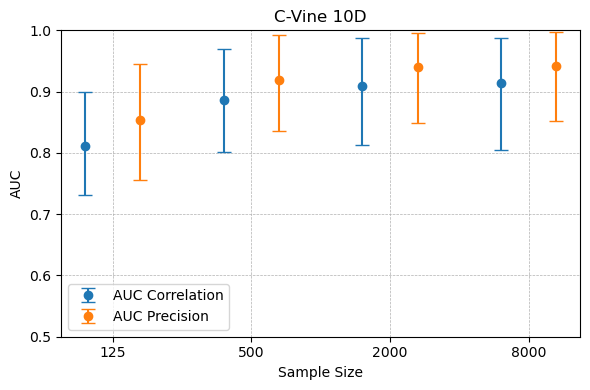

In [10]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_cvine_10D_125obs",
    500  : "ggm_cvine_10D_500obs",
    2000 : "ggm_cvine_10D_2000obs",
    8000 : "ggm_cvine_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "cvine_10D_125obs" : experiment_dfs[125]["metrics.auc_c"],
    "cvine_10D_500obs" : experiment_dfs[500]["metrics.auc_c"],
    "cvine_10D_2000obs" : experiment_dfs[2000]["metrics.auc_c"],
}

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_kld, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is  1


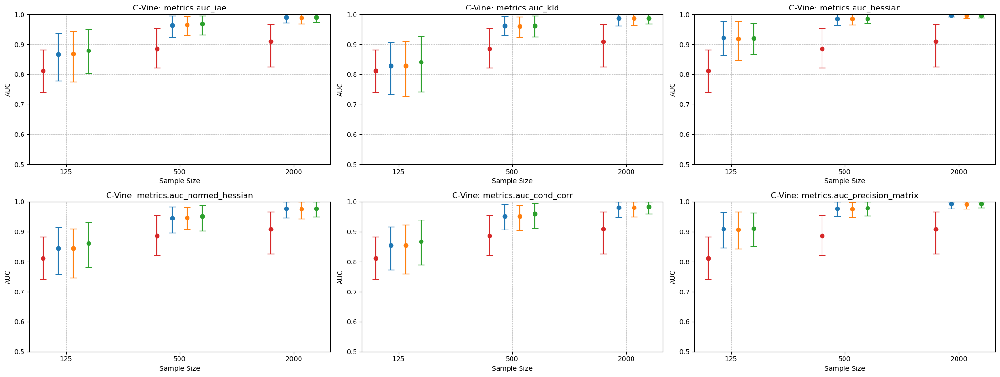

In [11]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_hessian, the number is  1


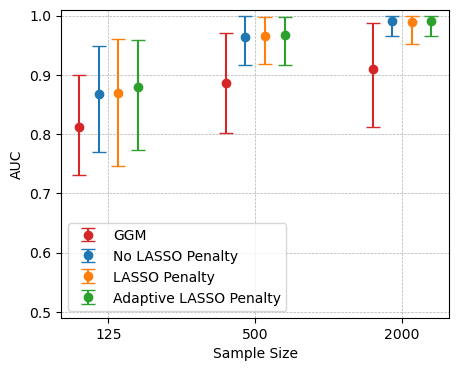

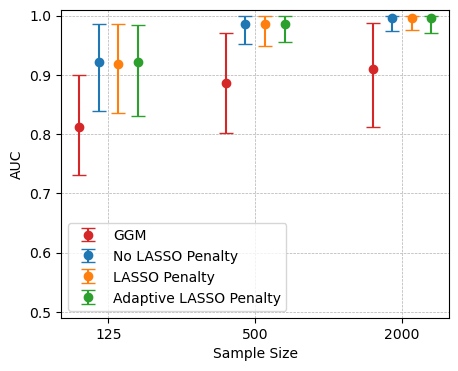

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_iae_cvine_normal.png")

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_hessian_cvine_normal.png")

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_hessian_cvine_normal.png")

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_normed_hessian",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_normed_hessian_cvine_normal.png")

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_cond_corr",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_cond_corr_cvine_normal.png")

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_precision_matrix",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_precision_matrix_cvine_normal.png")

In [12]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

  [ERROR] ggm_cvine_10D_125obs: name 'compute_pr_auc_for_experiment' is not defined
  [ERROR] ggm_cvine_10D_500obs: name 'compute_pr_auc_for_experiment' is not defined
  [ERROR] ggm_cvine_10D_2000obs: name 'compute_pr_auc_for_experiment' is not defined


In [17]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_normed_hessian_abs_mean, the number is  1
there are nan values in metrics.pr_auc_hessian_abs_mean, the number is  1


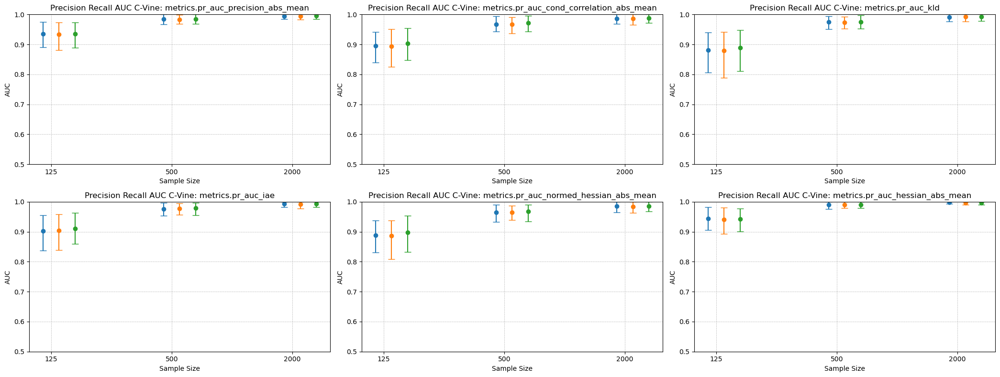

In [16]:

metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3
nrows=2

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

Processing seeds: 100%|██████████| 100/100 [00:13<00:00,  7.65it/s]


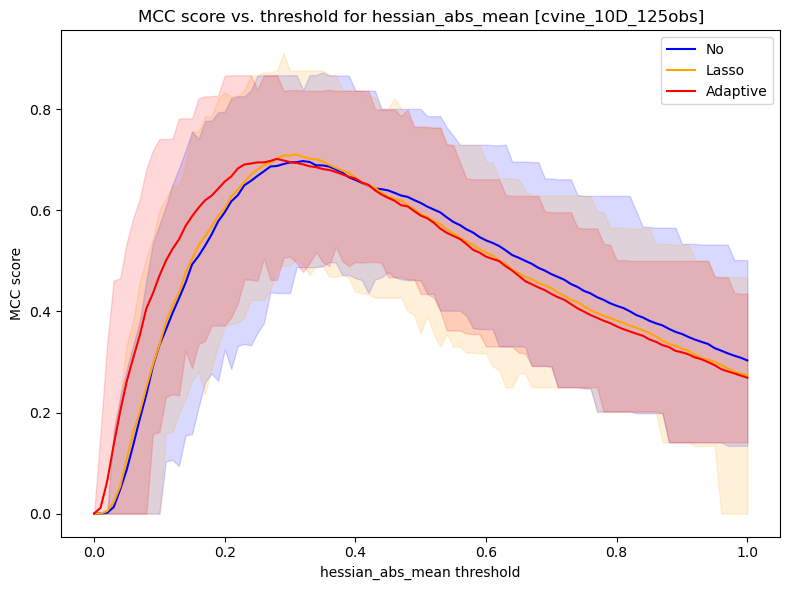

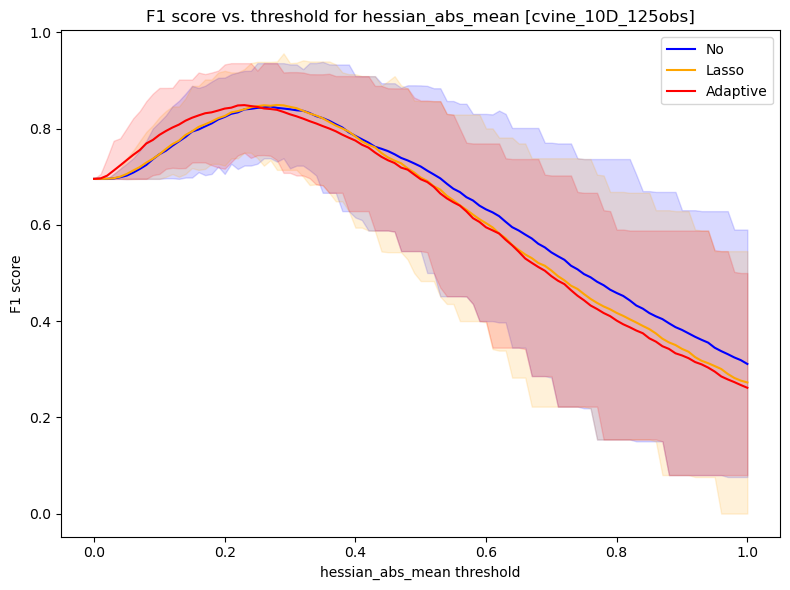

In [ ]:
df_mean_summary = evaluate_experiment_scores(
    "cvine_10D_125obs",
    metric="hessian_abs_mean",
    thresholds=np.linspace(0, 1, 101),
    #score_type="mcc"
)

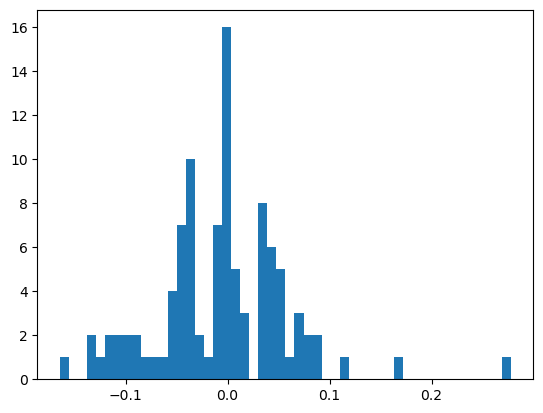

-0.005537037679576622


In [ ]:
plt.hist(df_mean_summary["mcc_adaptive"] - df_mean_summary["mcc_no"],bins=50)
plt.show()
print(np.mean(df_mean_summary["mcc_adaptive"] - df_mean_summary["mcc_no"]))

Processing seeds: 100%|██████████| 100/100 [00:18<00:00,  5.52it/s]


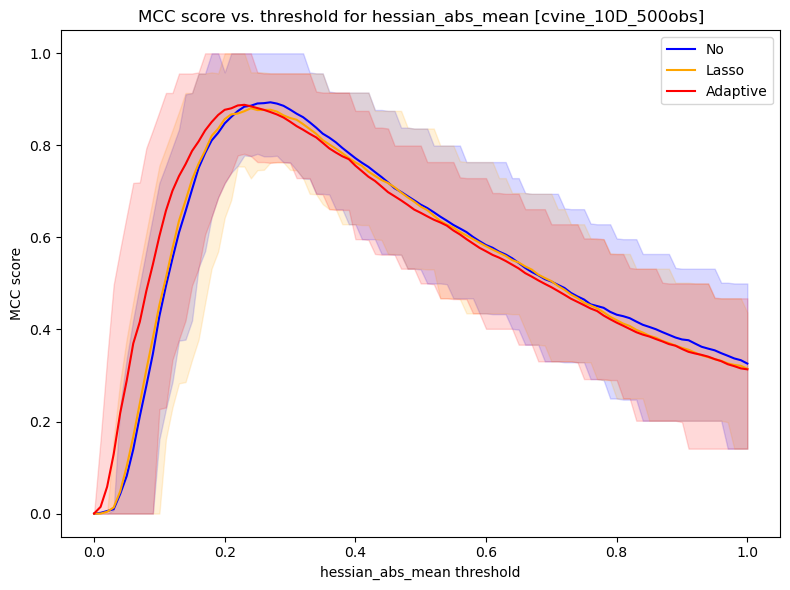

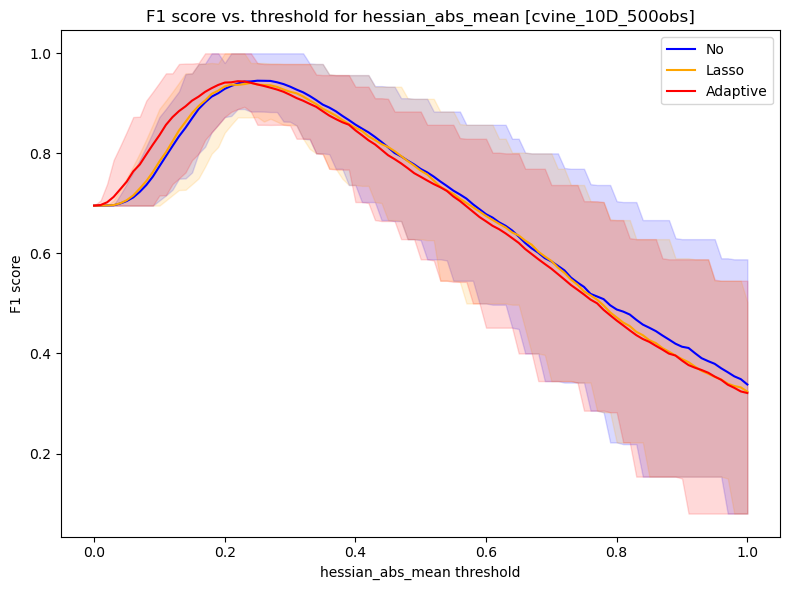

In [ ]:
df_mean_summary = evaluate_experiment_scores(
    "cvine_10D_500obs",
    metric="hessian_abs_mean",
    thresholds=np.linspace(0, 1, 101),
    score_type="mcc"
)

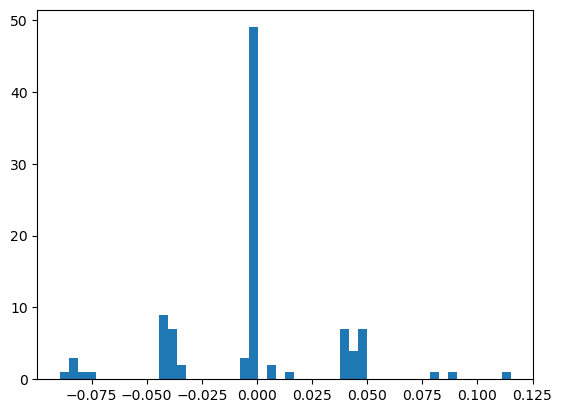

-0.001276408781302879


In [ ]:
plt.hist(df_mean_summary["mcc_adaptive"] - df_mean_summary["mcc_no"],bins=50)
plt.show()
print(np.mean(df_mean_summary["mcc_adaptive"] - df_mean_summary["mcc_no"]))

Processing seeds: 100%|██████████| 100/100 [00:13<00:00,  7.60it/s]


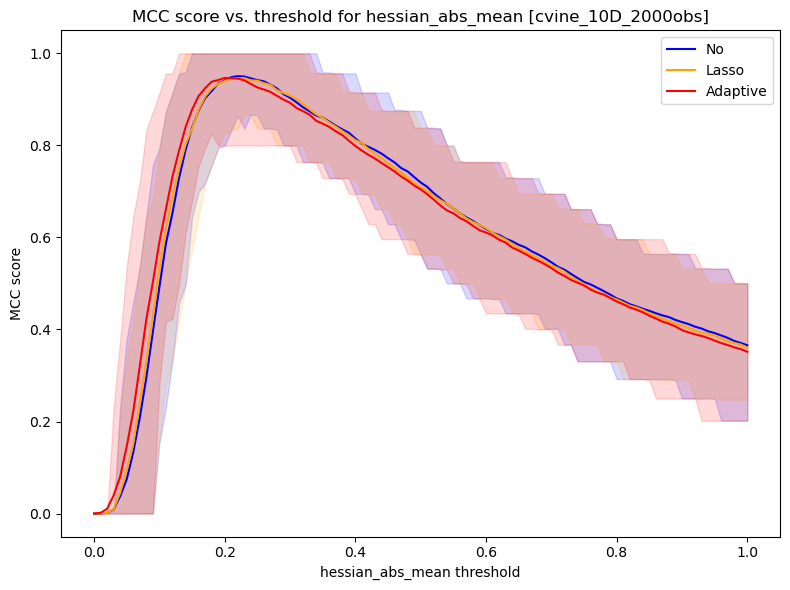

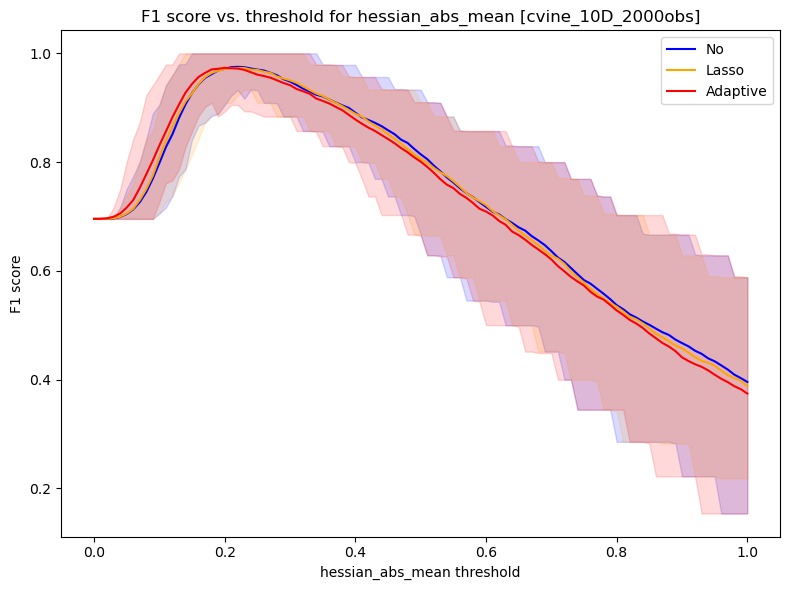

In [ ]:
df_mean_summary = evaluate_experiment_scores(
    "cvine_10D_2000obs",
    metric="hessian_abs_mean",
    thresholds=np.linspace(0, 1, 101),
    score_type="mcc"
)

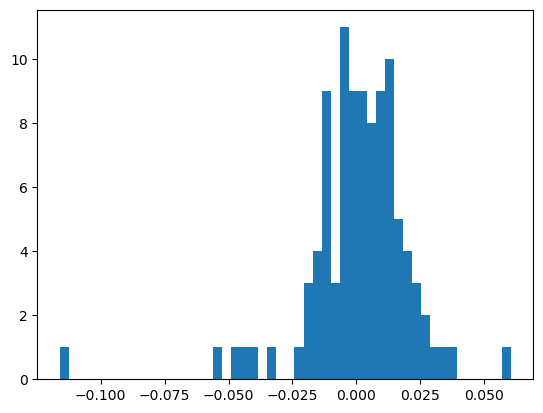

0.0004891744573502732


In [ ]:
plt.hist(df_mean_summary["mcc_adaptive"] - df_mean_summary["mcc_no"],bins=50)
plt.show()
print(np.mean(df_mean_summary["mcc_adaptive"] - df_mean_summary["mcc_no"]))

#### Strong

In [129]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["cvine_strong_10D_125obs", "cvine_strong_10D_500obs", "cvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

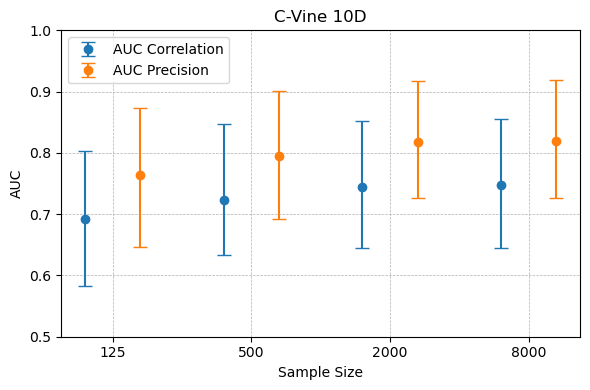

In [130]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_cvine_strong_10D_125obs",
    500  : "ggm_cvine_strong_10D_500obs",
    2000 : "ggm_cvine_strong_10D_2000obs",
    8000 : "ggm_cvine_strong_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "cvine_strong_10D_125obs" : experiment_dfs[125]["metrics.auc_c"],
    "cvine_strong_10D_500obs" : experiment_dfs[500]["metrics.auc_c"],
    "cvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.auc_c"],
}

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_kld, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is  1


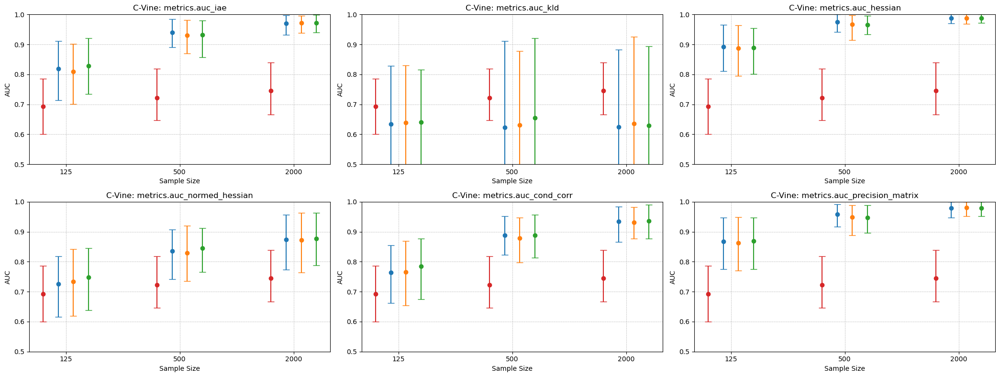

In [131]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_hessian, the number is  1


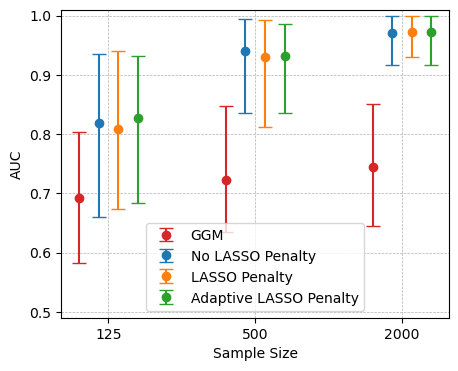

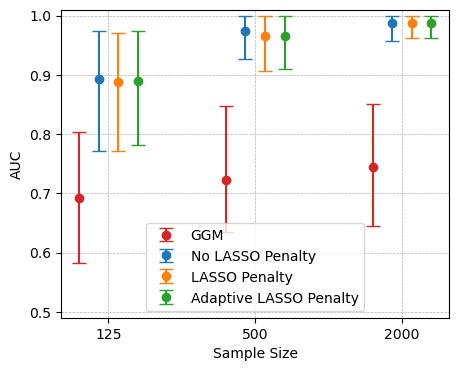

In [132]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_iae_cvine_strong.png")

metrics_list = ["metrics.auc_iae"] # "metrics.auc_normed_hessian"

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True
    )
plt.savefig("auc_hessian_cvine_strong.png")

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

  [ERROR] ggm_cvine_strong_10D_125obs: name 'compute_pr_auc_for_experiment' is not defined
  [ERROR] ggm_cvine_strong_10D_500obs: name 'compute_pr_auc_for_experiment' is not defined
  [ERROR] ggm_cvine_strong_10D_2000obs: name 'compute_pr_auc_for_experiment' is not defined


In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_normed_hessian_abs_mean, the number is  1
there are nan values in metrics.pr_auc_hessian_abs_mean, the number is  1


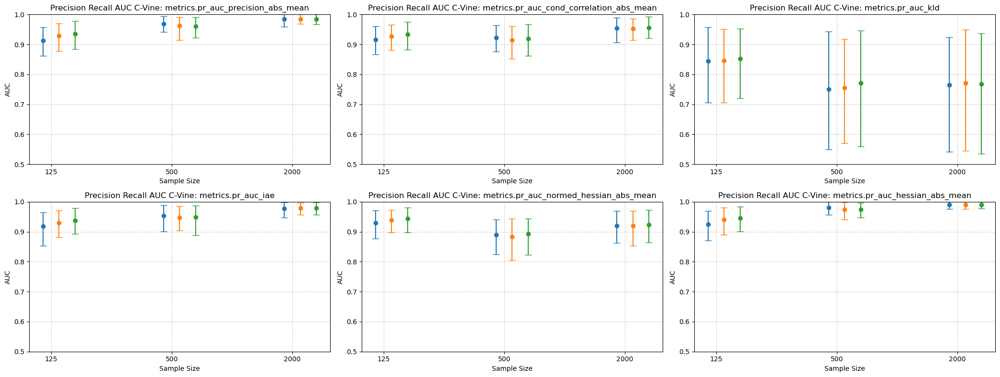

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

#### Strong Positive Only

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["cvine_strong_posonly_10D_125obs"] #, "cvine_strong_10D_500obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=89
)

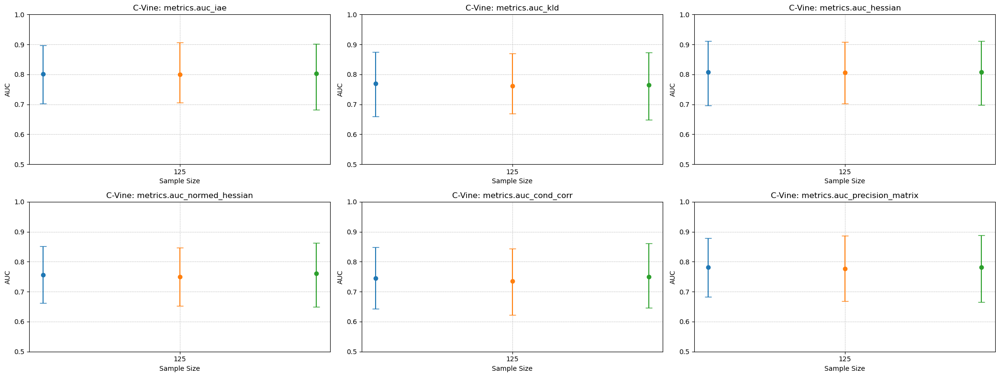

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "C-Vine",
        sample_sizes = [125], #, 500],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 89,
    verbose              = False,
)

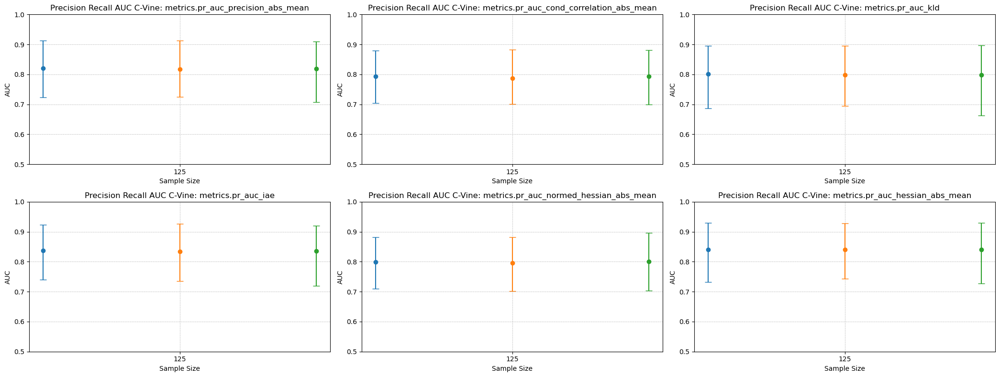

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC C-Vine",
        sample_sizes = [125], #, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

### D-Vine

#### Normal

In [31]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_10D_125obs", "dvine_10D_500obs", "dvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

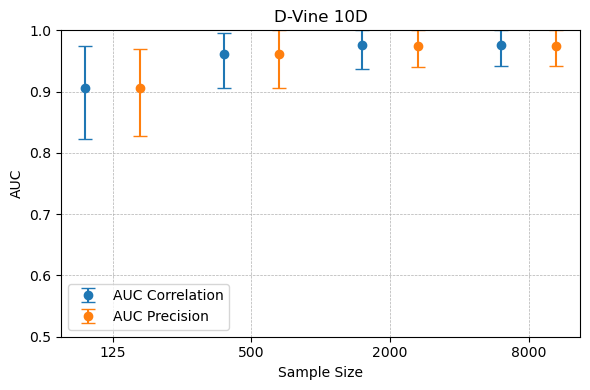

In [32]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_dvine_10D_125obs",
    500  : "ggm_dvine_10D_500obs",
    2000 : "ggm_dvine_10D_2000obs",
    8000 : "ggm_dvine_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "dvine_10D_125obs" : experiment_dfs[125]["metrics.auc_c"],
    "dvine_10D_500obs" : experiment_dfs[500]["metrics.auc_c"],
    "dvine_10D_2000obs" : experiment_dfs[2000]["metrics.auc_c"]
}

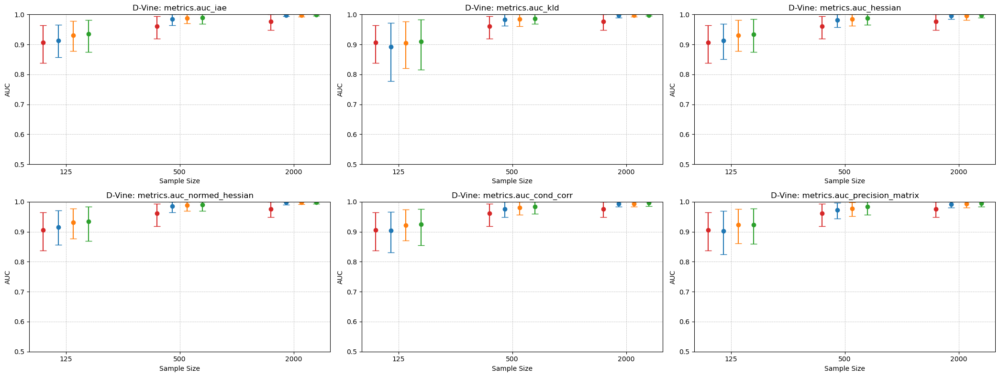

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

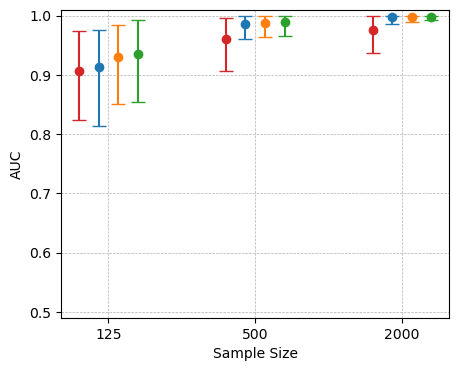

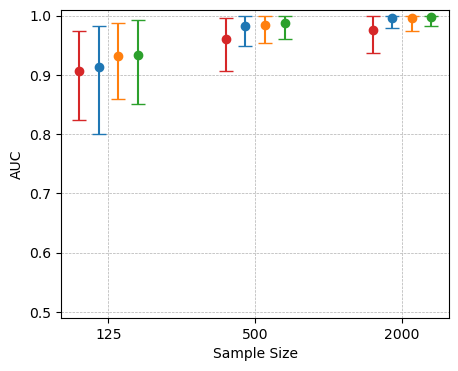

In [33]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_iae_dvine_normal.png")

metrics_list = ["metrics.auc_iae"] # "metrics.auc_normed_hessian"

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_hessian_dvine_normal.png")

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

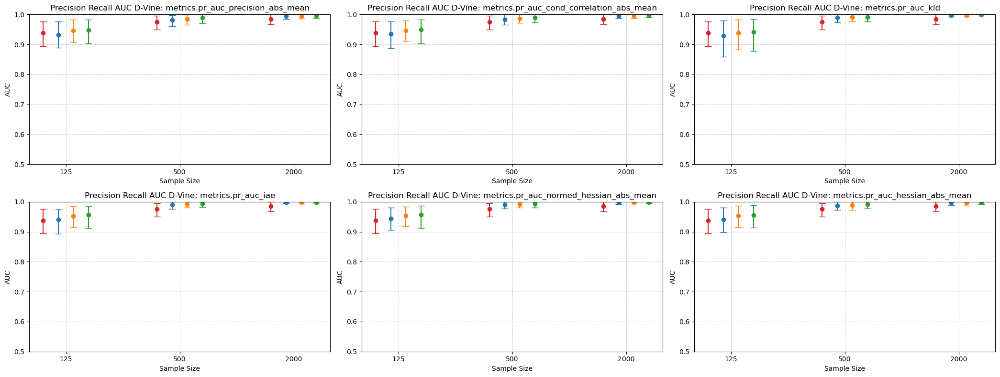

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

#### Strong

In [34]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_strong_10D_125obs", "dvine_strong_10D_500obs", "dvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

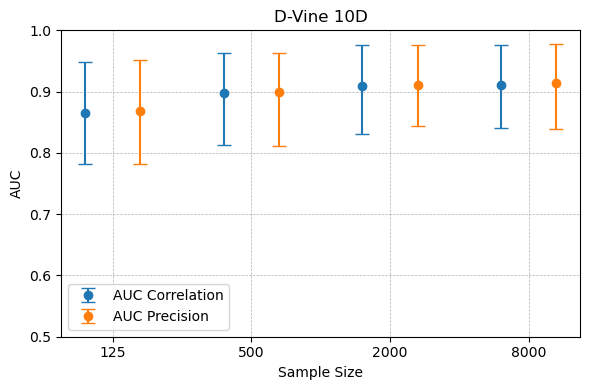

In [35]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_dvine_strong_10D_125obs",
    500  : "ggm_dvine_strong_10D_500obs",
    2000 : "ggm_dvine_strong_10D_2000obs",
    8000 : "ggm_dvine_strong_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "dvine_strong_10D_125obs" : experiment_dfs[125]["metrics.auc_c"],
    "dvine_strong_10D_500obs" : experiment_dfs[500]["metrics.auc_c"],
    "dvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.auc_c"],
}

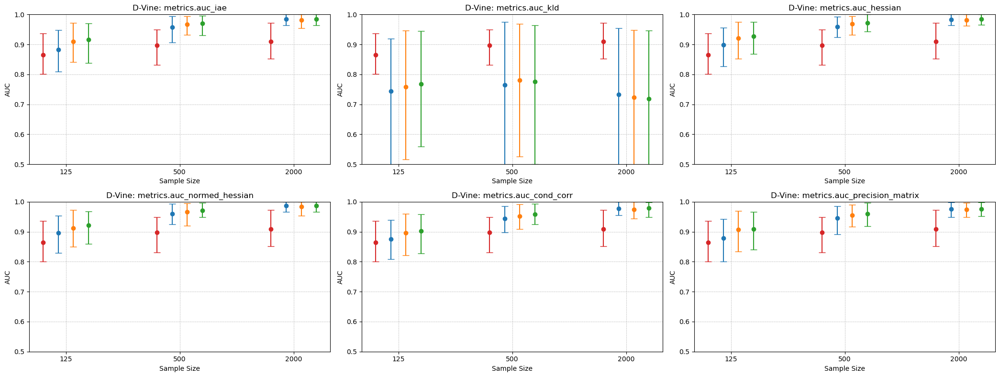

In [36]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

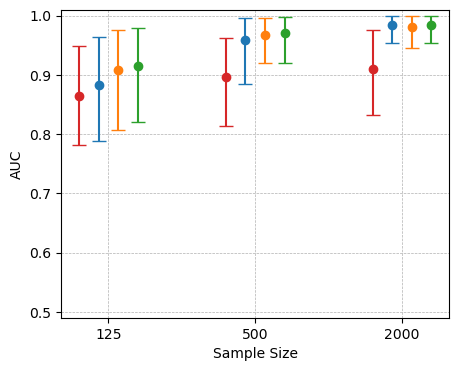

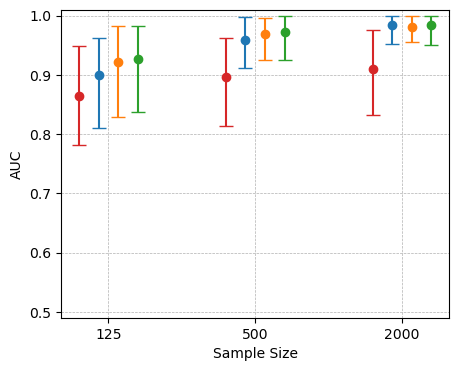

In [37]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_iae_dvine_strong.png")

metrics_list = ["metrics.auc_iae"] # "metrics.auc_normed_hessian"

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_hessian_dvine_strong.png")

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

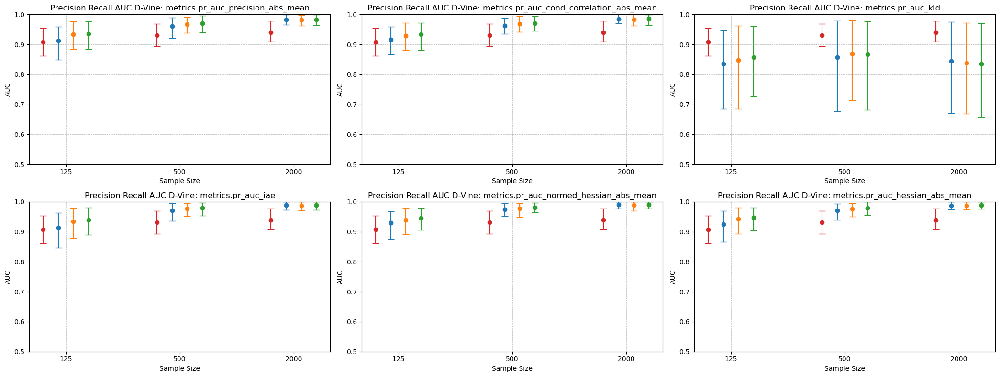

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

#### Strong Positive Only

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_strong_posonly_10D_125obs"] #, "dvine_strong_10D_500obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

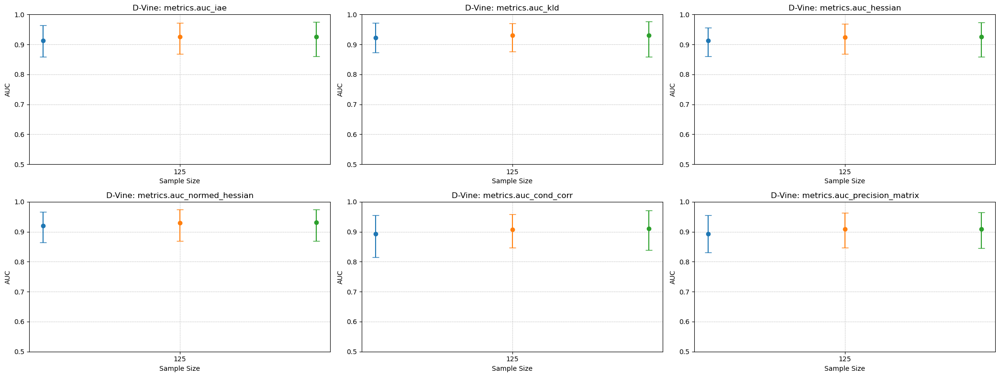

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "D-Vine",
        sample_sizes = [125], #, 500],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

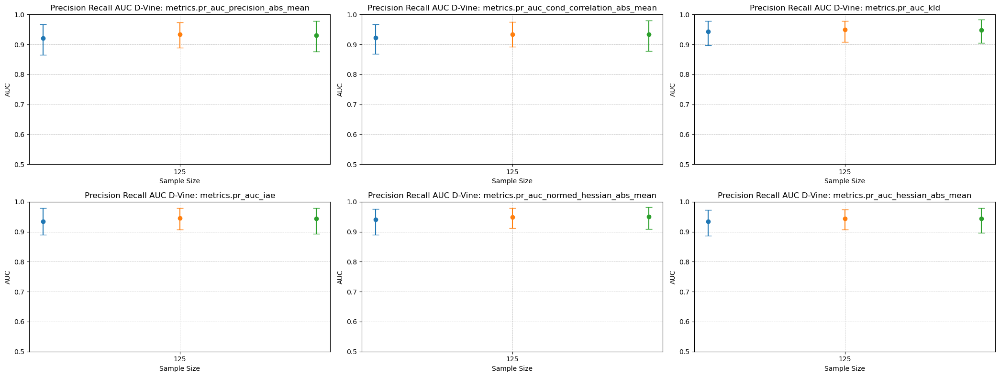

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC D-Vine",
        sample_sizes = [125], #, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

### R-Vine

#### Normal

In [94]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

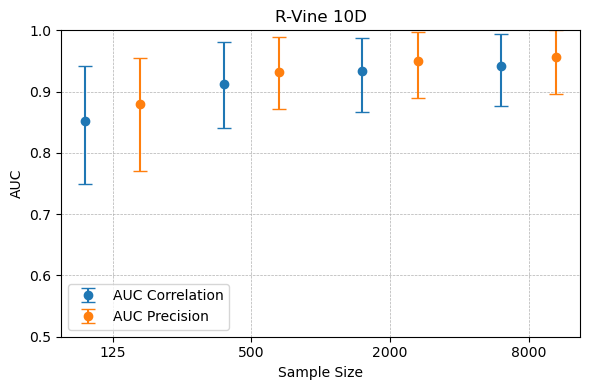

In [95]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_rvine_10D_125obs",
    500  : "ggm_rvine_10D_500obs",
    2000 : "ggm_rvine_10D_2000obs",
    8000 : "ggm_rvine_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "rvine_10D_125obs" : experiment_dfs[125]["metrics.auc_c"],
    "rvine_10D_500obs" : experiment_dfs[500]["metrics.auc_c"],
    "rvine_10D_2000obs" : experiment_dfs[2000]["metrics.auc_c"],
}

In [114]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_10D_125obs"]

auc_dict_adapt2 =  get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)


kld_dict_adapt2 = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

diff_df = pd.DataFrame({
    "auc_iae_diff": np.array(auc_dict_adapt2['rvine_10D_125obs']['metrics.auc_iae']) - np.array(auc_adaptive['rvine_10D_125obs']['metrics.auc_iae']),
    "auc_h_diff": np.array(auc_dict_adapt2['rvine_10D_125obs']['metrics.auc_hessian']) - np.array(auc_adaptive['rvine_10D_125obs']['metrics.auc_hessian']),
    "auc_nh_diff": np.array(auc_dict_adapt2['rvine_10D_125obs']['metrics.auc_normed_hessian']) - np.array(auc_adaptive['rvine_10D_125obs']['metrics.auc_normed_hessian']),
    "rel_kld_test_diff": np.array(kld_dict_adapt2['rvine_10D_125obs']['metrics.relative_kld_gtm_test']) - np.array(kld_no['rvine_10D_125obs']['metrics.relative_kld_gtm_test'])
})

# positive numbers are good for auc and negative numbers good for kld
diff_df.mean(0)

auc_iae_diff        -0.002686
auc_h_diff          -0.007556
auc_nh_diff         -0.001002
rel_kld_test_diff    0.116377
dtype: float64

In [119]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_10D_125obs"]
experiment_name = experiment_name_list[0]

auc_dict_adapt2 =  get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)


kld_dict_adapt2 = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

diff_df = pd.DataFrame({
    "auc_iae_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_iae']) - np.array(auc_adaptive[experiment_name]['metrics.auc_iae']),
    "auc_h_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_hessian']),
    "auc_nh_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_normed_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_normed_hessian']),
    "rel_kld_test_diff": np.array(kld_dict_adapt2[experiment_name]['metrics.relative_kld_gtm_test']) - np.array(kld_no[experiment_name]['metrics.relative_kld_gtm_test'])
})

# positive numbers are good for auc and negative numbers good for kld
diff_df.mean(0)

auc_iae_diff        -0.001706
auc_h_diff          -0.009821
auc_nh_diff          0.005952
rel_kld_test_diff    0.030796
dtype: float64

In [120]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_10D_125obs"]
experiment_name = experiment_name_list[0]

auc_dict_adapt2 =  get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)


kld_dict_adapt2 = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

diff_df = pd.DataFrame({
    "auc_iae_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_iae']) - np.array(auc_adaptive[experiment_name]['metrics.auc_iae']),
    "auc_h_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_hessian']),
    "auc_nh_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_normed_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_normed_hessian']),
    "rel_kld_test_diff": np.array(kld_dict_adapt2[experiment_name]['metrics.relative_kld_gtm_test']) - np.array(kld_no[experiment_name]['metrics.relative_kld_gtm_test'])
})

# positive numbers are good for auc and negative numbers good for kld
diff_df.mean(0)

auc_iae_diff        -0.005437
auc_h_diff          -0.005079
auc_nh_diff         -0.004464
rel_kld_test_diff    0.163196
dtype: float64

In [121]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_strong_10D_125obs"]
experiment_name = experiment_name_list[0]

auc_dict_adapt2 =  get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)


kld_dict_adapt2 = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

diff_df = pd.DataFrame({
    "auc_iae_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_iae']) - np.array(auc_adaptive[experiment_name]['metrics.auc_iae']),
    "auc_h_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_hessian']),
    "auc_nh_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_normed_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_normed_hessian']),
    "rel_kld_test_diff": np.array(kld_dict_adapt2[experiment_name]['metrics.relative_kld_gtm_test']) - np.array(kld_no[experiment_name]['metrics.relative_kld_gtm_test'])
})

# positive numbers are good for auc and negative numbers good for kld
diff_df.mean(0)

auc_iae_diff         0.001230
auc_h_diff           0.001389
auc_nh_diff          0.002381
rel_kld_test_diff   -0.027058
dtype: float64

In [122]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["cvine_10D_125obs"]
experiment_name = experiment_name_list[0]

auc_dict_adapt2 =  get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)


kld_dict_adapt2 = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adapt2"
)

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

diff_df = pd.DataFrame({
    "auc_iae_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_iae']) - np.array(auc_adaptive[experiment_name]['metrics.auc_iae']),
    "auc_h_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_hessian']),
    "auc_nh_diff": np.array(auc_dict_adapt2[experiment_name]['metrics.auc_normed_hessian']) - np.array(auc_adaptive[experiment_name]['metrics.auc_normed_hessian']),
    "rel_kld_test_diff": np.array(kld_dict_adapt2[experiment_name]['metrics.relative_kld_gtm_test']) - np.array(kld_no[experiment_name]['metrics.relative_kld_gtm_test'])
})

# positive numbers are good for auc and negative numbers good for kld
diff_df.mean(0)

auc_iae_diff        -0.004544
auc_h_diff          -0.013393
auc_nh_diff         -0.002480
rel_kld_test_diff    0.111325
dtype: float64

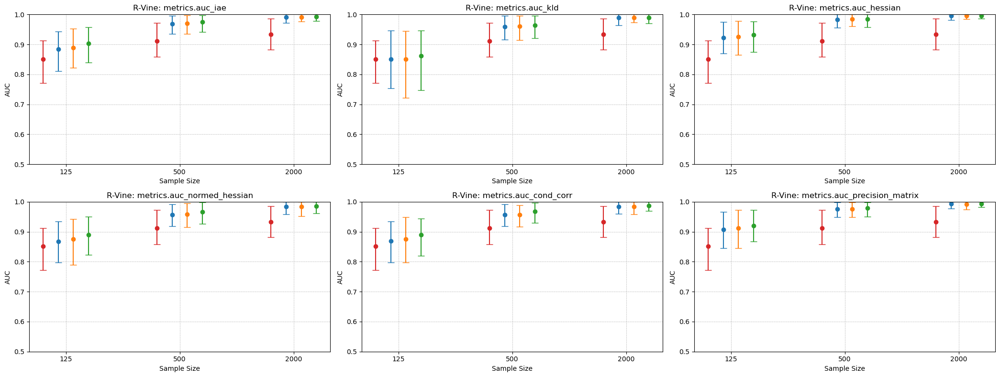

In [62]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

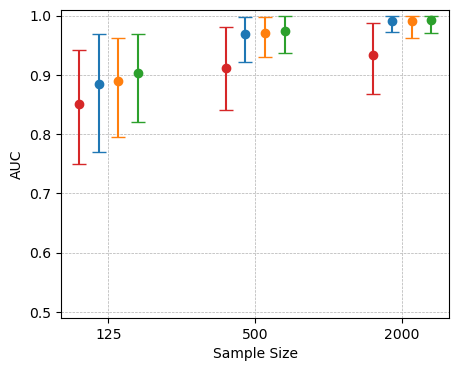

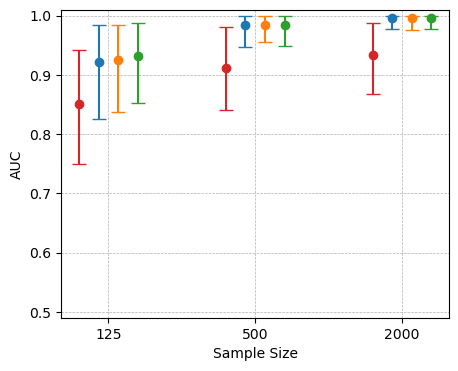

In [41]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_iae_rvine_normal.png")

metrics_list = ["metrics.auc_iae"] # "metrics.auc_normed_hessian"

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_hessian_rvine_normal.png")

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

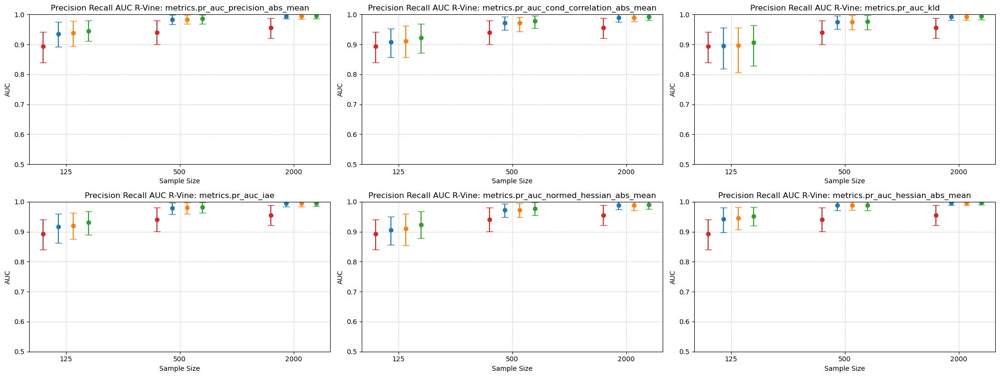

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

#### Strong

In [42]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_10D_125obs", "rvine_strong_10D_500obs", "rvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

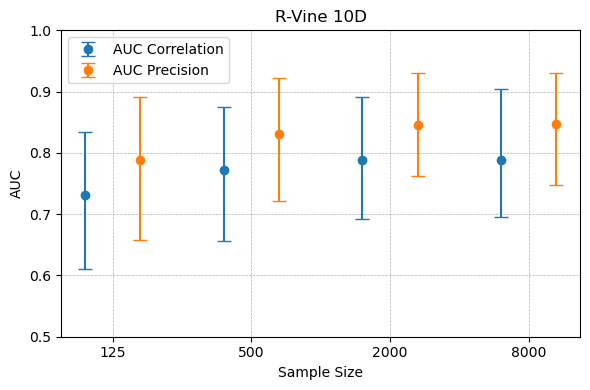

In [43]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_rvine_strong_10D_125obs",
    500  : "ggm_rvine_strong_10D_500obs",
    2000 : "ggm_rvine_strong_10D_2000obs",
    8000 : "ggm_rvine_strong_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "rvine_strong_10D_125obs" : experiment_dfs[125]["metrics.auc_c"],
    "rvine_strong_10D_500obs" : experiment_dfs[500]["metrics.auc_c"],
    "rvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.auc_c"],
}

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_kld, the number is  1
there are nan values in metrics.auc_kld, the number is  1
there are nan values in metrics.auc_kld, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is

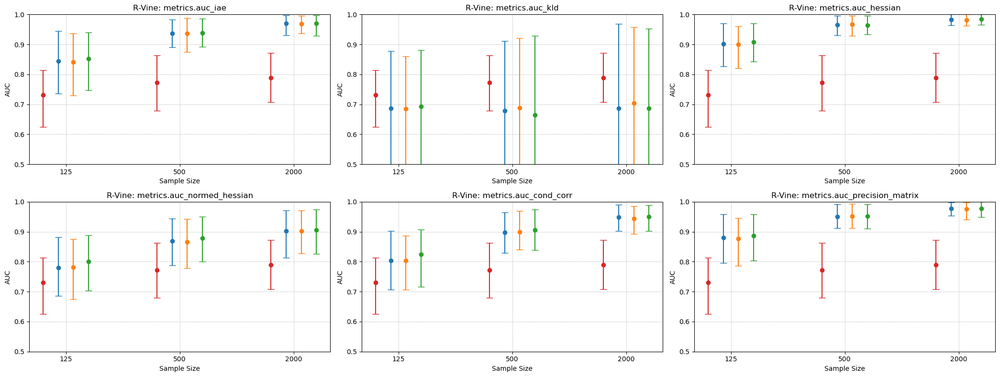

In [44]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1


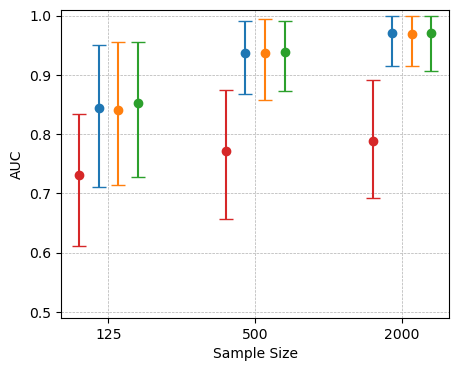

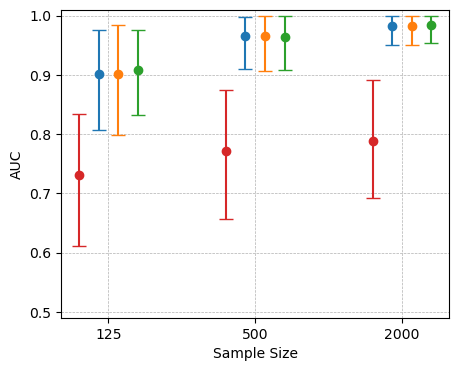

In [45]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_iae_rvine_strong.png")

metrics_list = ["metrics.auc_iae"] # "metrics.auc_normed_hessian"

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_hessian_rvine_strong.png")

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_normed_hessian_abs_mean, the number is  1
there are nan values in metrics.pr_auc_normed_hessian_abs_mean, the number i

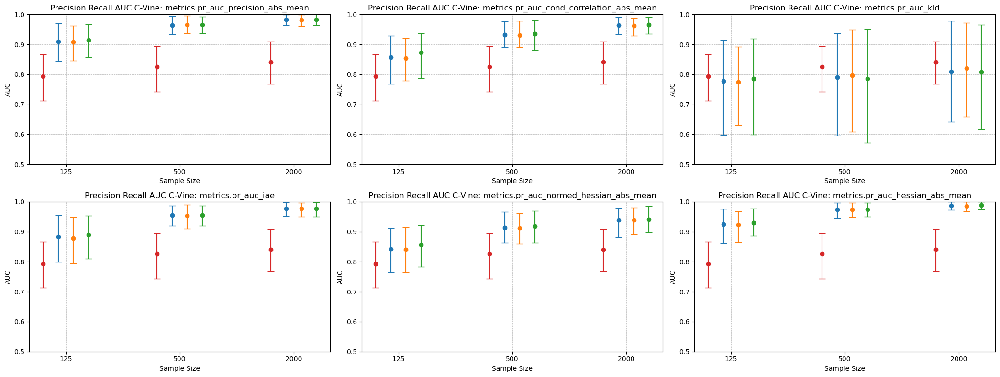

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_precision_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_cond_correlation_abs_mean, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_kld, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_iae, the number is  1
there are nan values in metrics.pr_auc_normed_hessian_abs_mean, the number is  1
there are nan values in metrics.pr_auc_normed_hessian_abs_mean, the number i

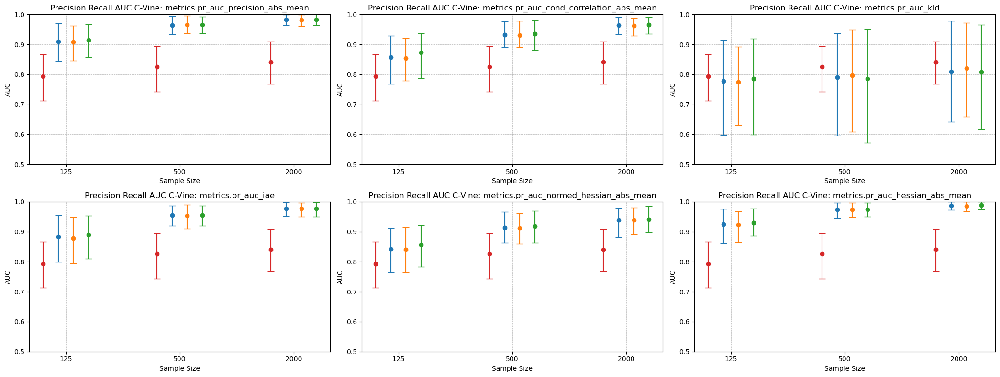

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

#### Strong Positive Only

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_posonly_10D_125obs"] #, "rvine_strong_10D_500obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

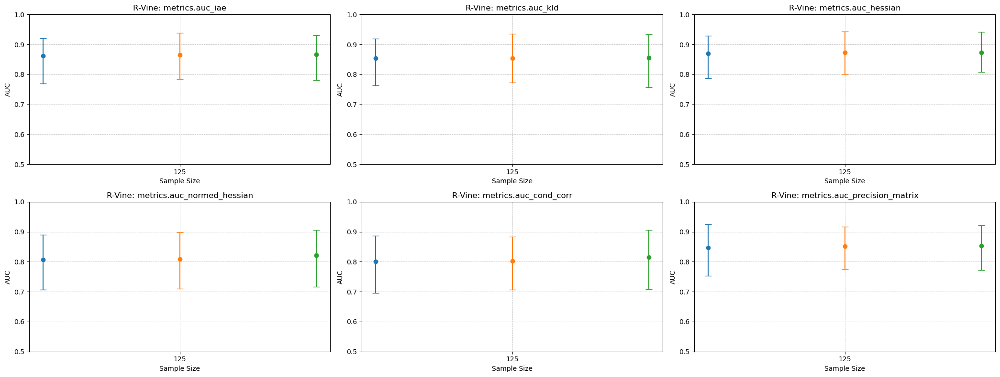

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]
nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [125], #, 500],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 99,
    verbose              = False,
)

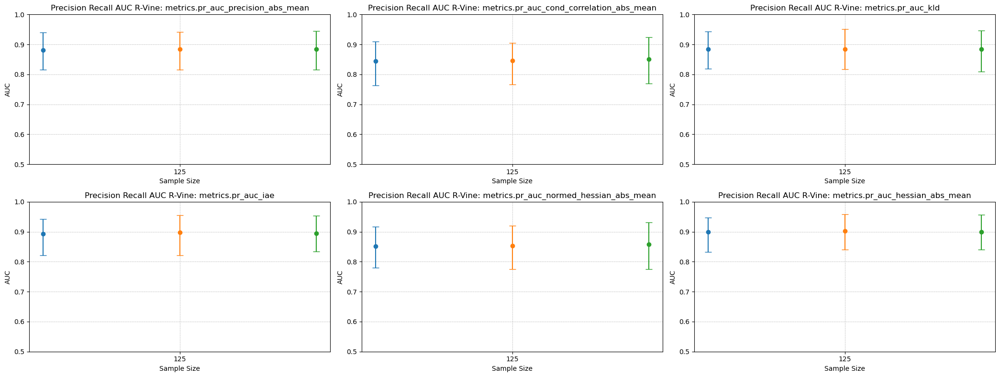

In [ ]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC R-Vine",
        sample_sizes = [125], #, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

### 20 Dimensional D-R-C-Vine

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

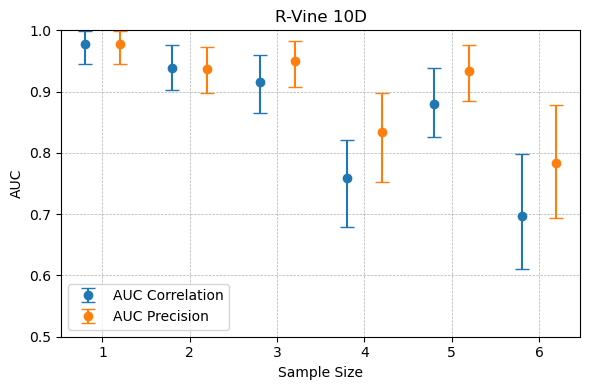

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

In [42]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    1  : "ggm_dvine_20D_2000obs",
    2  : "ggm_dvine_strong_20D_2000obs",
    3  : "ggm_rvine_20D_2000obs",
    4  : "ggm_rvine_strong_20D_2000obs",
    5  : "ggm_cvine_20D_2000obs",
    6  : "ggm_cvine_strong_20D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "rvine_strong_20D_2000obs" : mlflow.search_runs(mlflow.get_experiment_by_name("ggm_rvine_strong_20D_2000obs").experiment_id)["metrics.auc_c"]
}

In [45]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_20D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=100
)

there are nan values in metrics.auc_iae, the number is  2
there are nan values in metrics.auc_kld, the number is  2
there are nan values in metrics.auc_hessian, the number is  2
there are nan values in metrics.auc_normed_hessian, the number is  2
there are nan values in metrics.auc_cond_corr, the number is  2
there are nan values in metrics.auc_precision_matrix, the number is  2


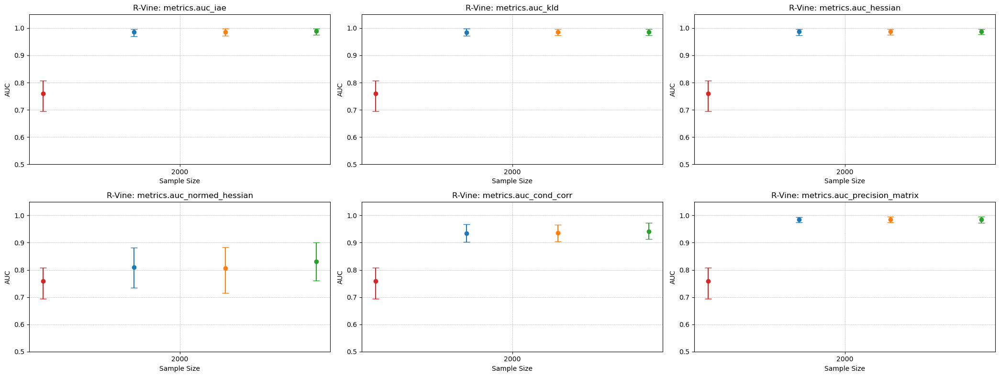

there are nan values in metrics.auc_iae, the number is  2
there are nan values in metrics.auc_kld, the number is  2
there are nan values in metrics.auc_hessian, the number is  2
there are nan values in metrics.auc_normed_hessian, the number is  2
there are nan values in metrics.auc_cond_corr, the number is  2
there are nan values in metrics.auc_precision_matrix, the number is  2


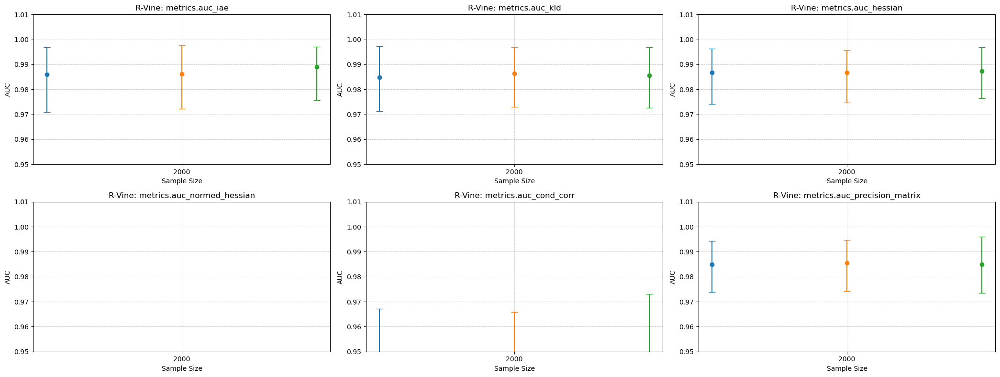

In [46]:
import matplotlib.pyplot as plt

#metrics_list = ["metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data"]
#ncols = 4

metrics_list = ["metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]

nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1.05,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

# No Benchamark as to zoom in

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.95,
        y_max = 1.01,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [47]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

  [ERROR] ggm_rvine_strong_20D_2000obs: name 'compute_pr_auc_for_experiment' is not defined


In [48]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', 'kld', 'iae', 'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min             = 0,
    seed_max             = 40,
    verbose              = False,
)

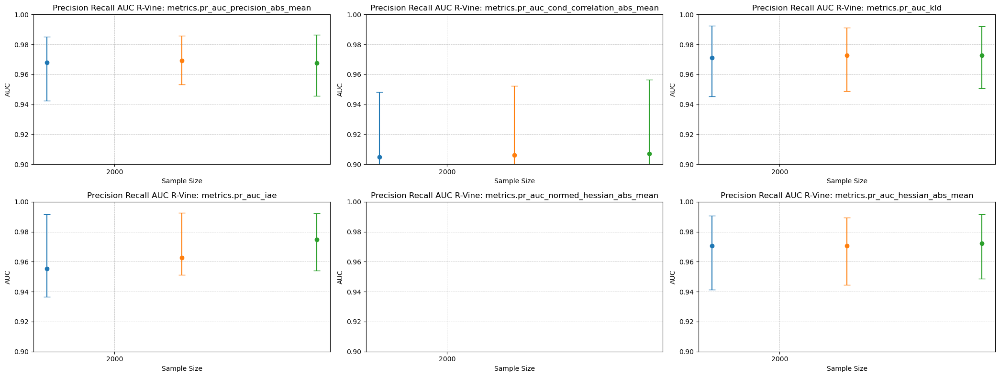

In [49]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.9,
        y_max = 1,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_iae_rvine_strong_20D.png")


create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_hessian",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False
    )
plt.savefig("auc_hessian_rvine_strong_20D.png")

### 50 Dimensional D-R-C-Vine

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

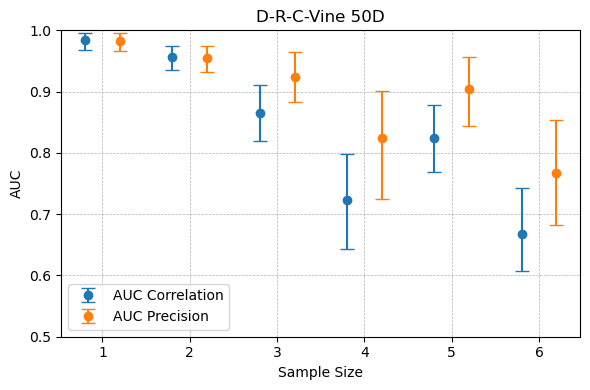

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

In [81]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    1  : "ggm_dvine_50D_2000obs",
    2  : "ggm_dvine_strong_50D_2000obs",
    3  : "ggm_rvine_50D_2000obs",
    4  : "ggm_rvine_strong_50D_2000obs",
    5  : "ggm_cvine_50D_2000obs",
    6  : "ggm_cvine_strong_50D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-R-C-Vine 50D",
    legend          = True,
)

benchmark_dict = {
    "rvine_strong_50D_2000obs_maxpen" : mlflow.search_runs(mlflow.get_experiment_by_name("ggm_rvine_strong_50D_2000obs").experiment_id)["metrics.auc_c"]
}

In [66]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_50D_2000obs_maxpen"]

auc_no = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=["Adaptive", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", #"metrics.auc_global_normed_hessian",
                                  ]
)

In [70]:
auc_adaptive = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=["No", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", #"metrics.auc_global_normed_hessian",
                                  ]
)

In [78]:
auc_no.keys()

dict_keys(['rvine_strong_50D_2000obs_maxpen'])

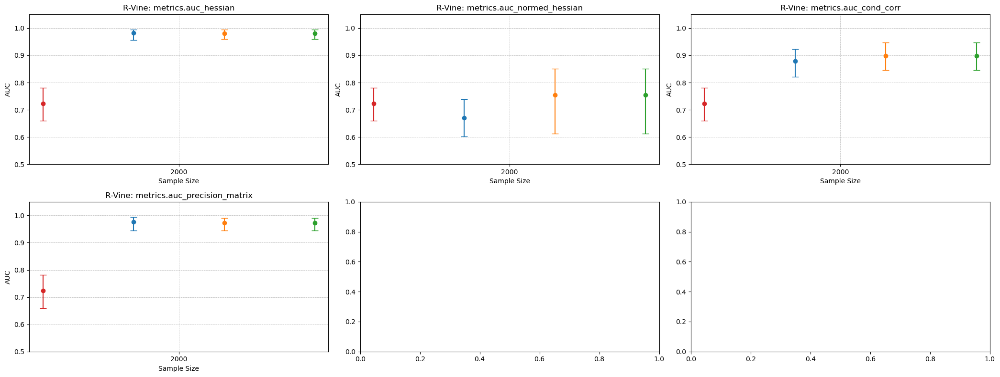

In [84]:
import matplotlib.pyplot as plt

metrics_list = [#"metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]

nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_adaptive, ###auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1.05,
        benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

In [86]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

experiment_name_list = ["rvine_strong_50D_2000obs"]

benchmark_dict = get_benchmark_pr_auc_dict(
    experiment_name_list  = experiment_name_list,
    metric_col            = "ggm_c_matrix_abs",
    ggm_experiment_prefix = "ggm_",
    artifact_filename     = "conditional_independence_table.csv",
    extra_metric_cols     = ["ggm_p_matrix_abs"],   # computed but not primary
    verbose               = False,
)

experiment_name_list = ["rvine_strong_50D_2000obs_maxpen"]

  [ERROR] ggm_rvine_strong_50D_2000obs: name 'compute_pr_auc_for_experiment' is not defined


In [95]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


auc_dict_no, auc_dict_lasso, auc_dict_adaptive = get_pr_auc_dicts_from_artifacts(
    experiment_name_list = experiment_name_list,
    metric_cols          = [ 'precision_abs_mean', 'cond_correlation_abs_mean', #'kld', 'iae', 
                            'normed_hessian_abs_mean', 'hessian_abs_mean'],
    seed_min=0,
    seed_max=99,
    verbose              = False,
)

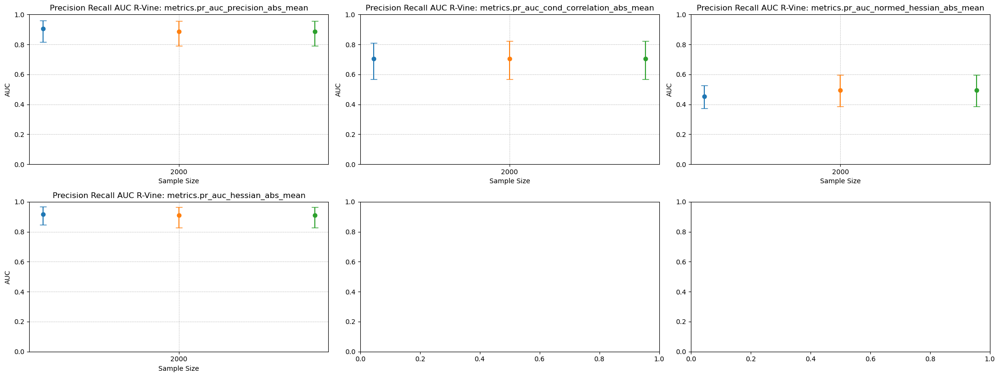

In [96]:
metrics_list = list(auc_dict_no[list(auc_dict_no.keys())[0]].keys())[:-1] # last is seeds
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21, 8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_dict_no,
        auc_dict_adaptive, #auc_dict_lasso,
        auc_dict_adaptive,
        metric = metric,
        title_str = "Precision Recall AUC R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

### 100 Dimensional D-R-C-Vine

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

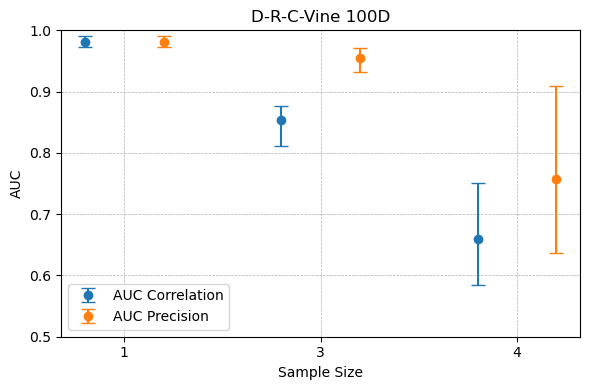

In [169]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    1  : "ggm_dvine_100D_2000obs",
    #2  : "ggm_dvine_strong_100D_2000obs",
    3  : "ggm_rvine_100D_2000obs",
    4  : "ggm_rvine_strong_100D_2000obs",
    #5  : "ggm_cvine_100D_2000obs",
    #6  : "ggm_cvine_strong_100D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-R-C-Vine 100D",
    legend          = True,
)

In [170]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_100D_2000obs_maxpen_I3", "rvine_strong_100D_2000obs"]

auc_no = get_auc_dicts_no(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=100
)

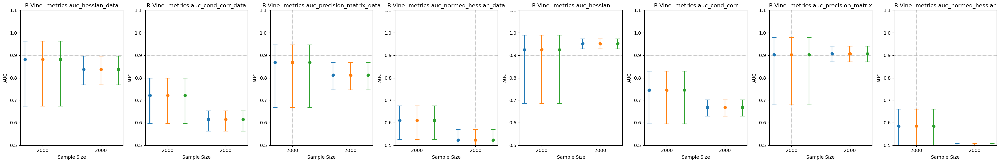

In [171]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", 
                "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian"]
ncols = 8

fig, axes = plt.subplots(1,ncols, figsize=(30, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_no,
        auc_no, #auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [2000, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1.1,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str="AUC",
    )

plt.tight_layout()
plt.show()

In [184]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_100D_2000obs_maxpen_I3"]

auc_no = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=["Adaptive", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", "metrics.auc_global_normed_hessian",
                                  ]
)

In [185]:
auc_adaptive = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=["No", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", "metrics.auc_global_normed_hessian",
                                  ]
)

In [190]:
auc_adaptive["rvine_strong_100D_2000obs_maxpen_I3"]['metrics.auc_hessian'].shape

(81,)

there are nan values in metrics.auc_global_normed_hessian, the number is  1
there are nan values in metrics.auc_global_normed_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is  1


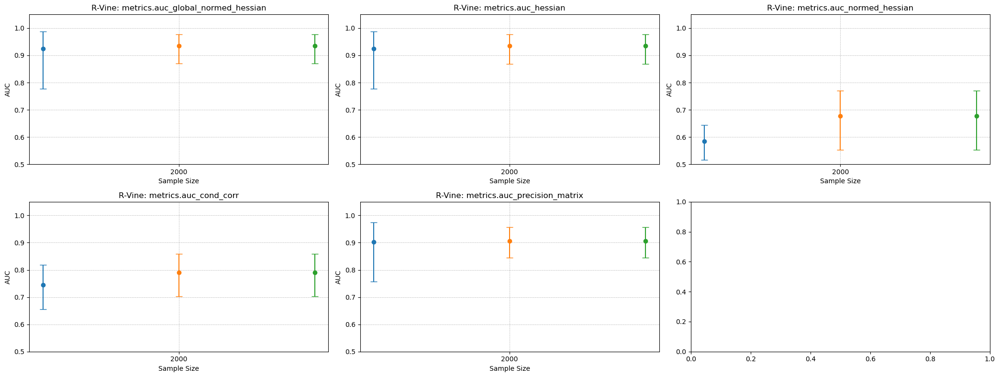

In [186]:
import matplotlib.pyplot as plt

metrics_list = [#"metrics.auc_iae", "metrics.auc_kld", 
                "metrics.auc_global_normed_hessian", "metrics.auc_hessian", "metrics.auc_normed_hessian", 
                "metrics.auc_cond_corr", "metrics.auc_precision_matrix"]

nrows = 2
ncols = 3

fig, axes = plt.subplots(nrows, ncols, figsize=(21,8))

for idx, metric in enumerate(metrics_list):
    row = idx // ncols
    col = idx % ncols
    ax = axes[row, col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_adaptive, ###auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.5,
        y_max = 1.05,
        #benchmark=benchmark_dict,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax
    )

plt.tight_layout()
plt.show()

### Plots for paper

In [288]:
from tqdm import tqdm
import mlflow
import matplotlib.pyplot as plt

# ── Configuration ─────────────────────────────────────────────────────────────

vine_types = ["cvine", "dvine", "rvine"]

scenarios = {
    "normal": {
        "sample_sizes"   : [125, 500, 2000],
        "obs_strings"    : ["125obs", "500obs", "2000obs"],
        "ggm_sample_sizes": [125, 500, 2000, 8000],
    },
    "strong": {
        "sample_sizes"   : [125, 500, 2000],
        "obs_strings"    : ["125obs", "500obs", "2000obs"],
        "ggm_sample_sizes": [125, 500, 2000, 8000],
    },
}

metrics_to_plot = [
    "metrics.auc_iae",
    "metrics.auc_hessian",
    "metrics.auc_normed_hessian",
    "metrics.auc_cond_corr",
    "metrics.auc_precision_matrix",
    #"metrics.auc_kld",
    "metrics.auc_global_normed_hessian",
]

metric_file_names = {
    "metrics.auc_iae"              : "auc_iae",
    "metrics.auc_hessian"          : "auc_hessian",
    "metrics.auc_normed_hessian"   : "auc_normed_hessian",
    "metrics.auc_cond_corr"        : "auc_cond_corr",
    "metrics.auc_precision_matrix" : "auc_precision_matrix",
    #"metrics.auc_kld" : "auc_kld",
    "metrics.auc_global_normed_hessian" : "auc_global_normed_hessian",
}

metric_cols_ggm = ["metrics.auc_c", "metrics.auc_p"]

mlruns_scratch_uri = "/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch"
mlruns_uri         = "/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns"

# ── Main loop ─────────────────────────────────────────────────────────────────

# Total = n_vines × n_scenarios = 3 × 2 = 6 combinations
vine_scenario_combinations = [
    (vine, scenario_name, scenario_cfg)
    for vine in vine_types
    for scenario_name, scenario_cfg in scenarios.items()
]

pbar_outer = tqdm(
    vine_scenario_combinations,
    desc="Vine × Scenario",
    position=0,
)

for vine, scenario_name, scenario_cfg in pbar_outer:

    pbar_outer.set_description(f"Vine={vine} | Scenario={scenario_name}")

    sample_sizes      = scenario_cfg["sample_sizes"]
    obs_strings       = scenario_cfg["obs_strings"]
    ggm_sample_sizes  = scenario_cfg["ggm_sample_sizes"]
    scenario_suffix   = "_strong" if scenario_name == "strong" else ""

    # ── Build experiment name lists ───────────────────────────────────────────
    experiment_name_list = [
        f"{vine}{scenario_suffix}_10D_{obs}"
        for obs in obs_strings
    ]
    ggm_experiment_names = {
        ss: f"ggm_{vine}{scenario_suffix}_10D_{obs}"
        for ss, obs in zip(ggm_sample_sizes, obs_strings + ["8000obs"])
    }

    # ── Load GTM runs ─────────────────────────────────────────────────────────
    mlflow.set_tracking_uri(mlruns_scratch_uri)

    try:
        auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
            experiment_name_list=experiment_name_list,
            seed_min=0,
            seed_max=99,
        )
    except Exception as e:
        tqdm.write(f"  SKIPPING {vine} {scenario_name} — could not load GTM runs: {e}")
        continue

    # ── Load GGM runs ─────────────────────────────────────────────────────────
    mlflow.set_tracking_uri(mlruns_uri)

    experiment_dfs = {}
    for ss, exp_name in ggm_experiment_names.items():
        try:
            experiment     = mlflow.get_experiment_by_name(exp_name)
            df_runs        = mlflow.search_runs([experiment.experiment_id])
            experiment_dfs[ss] = df_runs[metric_cols_ggm + ["tags.seed_value"]]
        except Exception as e:
            tqdm.write(f"  WARNING: could not load GGM experiment '{exp_name}': {e}")

    # ── Build benchmark dict ──────────────────────────────────────────────────
    benchmark_dict = {
        exp_name: experiment_dfs[ss]["metrics.auc_c"]
        for exp_name, ss in zip(experiment_name_list, sample_sizes)
        if ss in experiment_dfs
    }
    benchmark_available = len(benchmark_dict) == len(experiment_name_list)
    if not benchmark_available:
        tqdm.write(f"  WARNING: benchmark dict incomplete for {vine} {scenario_name} — plotting without benchmark.")
        benchmark_dict = False

    # ── Labels ───────────────────────────────────────────────────────────────
    vine_label     = vine[0].upper() + "-" + vine[1:]
    scenario_label = "Strong" if scenario_name == "strong" else "Normal"
    title_str      = f"{vine_label} ({scenario_label})"

    # ── Plot each metric ──────────────────────────────────────────────────────
    pbar_inner = tqdm(
        metrics_to_plot,
        desc=f"  Metrics [{vine} {scenario_name}]",
        position=1,
        leave=False,   # clears inner bar when done so outer bar stays clean
    )

    for metric in pbar_inner:

        pbar_inner.set_description(f"  {metric_file_names[metric]} [{vine} {scenario_name}]")

        fig, ax = plt.subplots(figsize=(6, 4))
        
        if "cvine" in vine:
            legend_bool = True
        else:
            legend_bool = False

        create_comparison_plot_one_scenario(
            auc_no,
            auc_lasso,
            auc_adaptive,
            metric             = metric,
            title_str          = title_str,
            sample_sizes       = sample_sizes,
            experiment_strings = experiment_name_list,
            y_min              = 0.49,
            y_max              = 1.01,
            benchmark          = benchmark_dict,
            lower_quantile     = 5,
            upper_quantile     = 95,
            add_metric_title   = False,
            legend             = legend_bool,
            ax                 = ax,
        )

        filename = (
            f"{metric_file_names[metric]}"
            f"_{vine}"
            f"{scenario_suffix}"
            f"_{scenario_name}.png"
        )
        plt.tight_layout()
        plt.savefig(filename, dpi=150)
        plt.close(fig)
        tqdm.write(f"  Saved: {filename}")

tqdm.write("\nAll done.")

Vine=cvine | Scenario=normal:   0%|          | 0/6 [00:00<?, ?it/s]WARNING:root:Malformed experiment 'models'. Detailed error Yaml file '/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns/models/meta.yaml' does not exist.
Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    re

  Saved: auc_iae_cvine_normal.png
  Saved: auc_hessian_cvine_normal.png
  Saved: auc_normed_hessian_cvine_normal.png


                                                                   
                                                                             
                                                                                    
Vine=cvine | Scenario=strong:  17%|█▋        | 1/6 [00:23<01:55, 23.11s/it]              

  Saved: auc_cond_corr_cvine_normal.png
  Saved: auc_precision_matrix_cvine_normal.png
  Saved: auc_global_normed_hessian_cvine_normal.png


Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

  Saved: auc_iae_cvine_strong_strong.png
  Saved: auc_hessian_cvine_strong_strong.png
  Saved: auc_normed_hessian_cvine_strong_strong.png


... (16 outputs left out)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
  Saved: auc_iae_rvine_strong_strong.png
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
there are nan values in metrics.auc_hessian, the number is  1
  Saved: auc_hessian_rvine_strong_strong.png
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
  Saved: auc_normed_hessian_rvine_strong_strong.png
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1
there are nan values in metrics.auc_cond_corr, the number is  1


                                                                           
                                                                             
                                                                                    
Vine=rvine | Scenario=strong: 100%|██████████| 6/6 [01:56<00:00, 19.45s/it]              

  Saved: auc_cond_corr_rvine_strong_strong.png
there are nan values in metrics.auc_precision_matrix, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is  1
there are nan values in metrics.auc_precision_matrix, the number is  1
  Saved: auc_precision_matrix_rvine_strong_strong.png
  Saved: auc_global_normed_hessian_rvine_strong_strong.png

All done.


In [384]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = {
    "rvine_strong_20D_2000obs" : mlflow.search_runs(mlflow.get_experiment_by_name("ggm_rvine_strong_20D_2000obs").experiment_id)["metrics.auc_c"]
}

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name = "rvine_strong_20D_2000obs"

metrics_to_plot = [
    "metrics.auc_iae",
    "metrics.auc_hessian",
    "metrics.auc_normed_hessian",
    "metrics.auc_cond_corr",
    "metrics.auc_precision_matrix",
    #"metrics.auc_kld",
    "metrics.auc_global_normed_hessian",
]

metric_file_names = {
     "metrics.auc_iae" :  "auc_iae",
    "metrics.auc_hessian": "auc_hessian",
    "metrics.auc_normed_hessian" :    "auc_normed_hessian",
    "metrics.auc_cond_corr" :     "auc_cond_corr",
    "metrics.auc_precision_matrix" :    "auc_precision_matrix",
    "metrics.auc_global_normed_hessian" : "auc_global_normed_hessian",
}

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list=[experiment_name],
    seed_min=0,
    seed_max=99,
)

for metric in tqdm(metrics_to_plot):

    fig, ax = plt.subplots(figsize=(6, 4))

    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric=metric,
        title_str="R-Vine Strong (20D)",
        sample_sizes=[20],
        experiment_strings=[experiment_name],
        y_min=0.49,
        y_max=1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True,
        ax=ax,
    )

    plt.tight_layout()
    plt.savefig(f"{metric_file_names[metric]}_20D.png", dpi=150)
    plt.close(fig)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

In [388]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = {
    "rvine_strong_50D_2000obs_maxpen" : mlflow.search_runs(mlflow.get_experiment_by_name("ggm_rvine_strong_50D_2000obs").experiment_id)["metrics.auc_c"]
}

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


experiment_name = "rvine_strong_50D_2000obs_maxpen"
experiment_name_list = [experiment_name]

metrics_to_plot = [
    "metrics.auc_hessian",
    "metrics.auc_normed_hessian",
    "metrics.auc_cond_corr",
    "metrics.auc_precision_matrix",
    "metrics.auc_global_normed_hessian",
]

metric_file_names = {
    "metrics.auc_hessian": "auc_hessian",
    "metrics.auc_normed_hessian" :    "auc_normed_hessian",
    "metrics.auc_cond_corr" :     "auc_cond_corr",
    "metrics.auc_precision_matrix" :    "auc_precision_matrix",
    "metrics.auc_global_normed_hessian" : "auc_global_normed_hessian",
}

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

auc_no = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=["Adaptive", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", #"metrics.auc_global_normed_hessian",
                                  ]
)
auc_adaptive = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=["No", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", #"metrics.auc_global_normed_hessian",
                                  ]
)

from copy import deepcopy
auc_lasso = deepcopy(auc_adaptive)

for metric in tqdm(metrics_to_plot):
    
    auc_lasso[experiment_name][metric] += -100

    fig, ax = plt.subplots(figsize=(6, 4))

    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric=metric,
        title_str="R-Vine Strong (50D)",
        sample_sizes=[2000],
        experiment_strings=[experiment_name],
        y_min=0.49,
        y_max=1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=False,
        ax=ax,
    )

    plt.tight_layout()
    plt.savefig(f"{metric_file_names[metric]}_50D.png", dpi=150)
    plt.close(fig)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

KeyError: 'metrics.auc_global_normed_hessian'

In [390]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

benchmark_dict = {
    "rvine_strong_100D_2000obs_maxpen_I3" : mlflow.search_runs(mlflow.get_experiment_by_name("ggm_rvine_strong_100D_2000obs").experiment_id)["metrics.auc_c"]
}

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")


experiment_name = "rvine_strong_100D_2000obs_maxpen_I3"
experiment_name_list = [experiment_name]
 

metrics_to_plot = [
    "metrics.auc_hessian",
    "metrics.auc_normed_hessian",
    "metrics.auc_cond_corr",
    "metrics.auc_precision_matrix",
    "metrics.auc_global_normed_hessian",
]

metric_file_names = {
    "metrics.auc_hessian": "auc_hessian",
    "metrics.auc_normed_hessian" :    "auc_normed_hessian",
    "metrics.auc_cond_corr" :     "auc_cond_corr",
    "metrics.auc_precision_matrix" :    "auc_precision_matrix",
    "metrics.auc_global_normed_hessian" : "auc_global_normed_hessian",
}


mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

auc_no = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=["Adaptive", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", #"metrics.auc_global_normed_hessian",
                                  ]
)
auc_adaptive = get_auc_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=["No", "Lasso"],
    metrics_list=[ "metrics.auc_hessian", "metrics.auc_cond_corr", "metrics.auc_precision_matrix", "metrics.auc_normed_hessian", 
                                  "metrics.auc_hessian_data", "metrics.auc_cond_corr_data", "metrics.auc_precision_matrix_data", "metrics.auc_normed_hessian_data", #"metrics.auc_global_normed_hessian",
                                  ]
)

from copy import deepcopy
auc_lasso = deepcopy(auc_adaptive)

for metric in tqdm(metrics_to_plot):
    
    auc_lasso[experiment_name][metric] += -100

    fig, ax = plt.subplots(figsize=(6, 4))

    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric=metric,
        title_str="R-Vine Strong (100D)",
        sample_sizes=[50],
        experiment_strings=[experiment_name],
        y_min=0.49,
        y_max=1.01,
        benchmark=benchmark_dict,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=False,
        ax=ax,
    )

    plt.tight_layout()
    plt.savefig(f"{metric_file_names[metric]}_100D.png", dpi=150)
    plt.close(fig)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 271, in list_experiments
    experiment = self._get_experiment(exp_id, view_type)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 405, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/trac

there are nan values in False, the number is  1
there are nan values in False, the number is  1
there are nan values in False, the number is  1
there are nan values in False, the number is  1


KeyError: 'metrics.auc_global_normed_hessian'

## KLD Results

### C-Vine

#### Normal

In [17]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["cvine_10D_125obs", "cvine_10D_500obs", "cvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

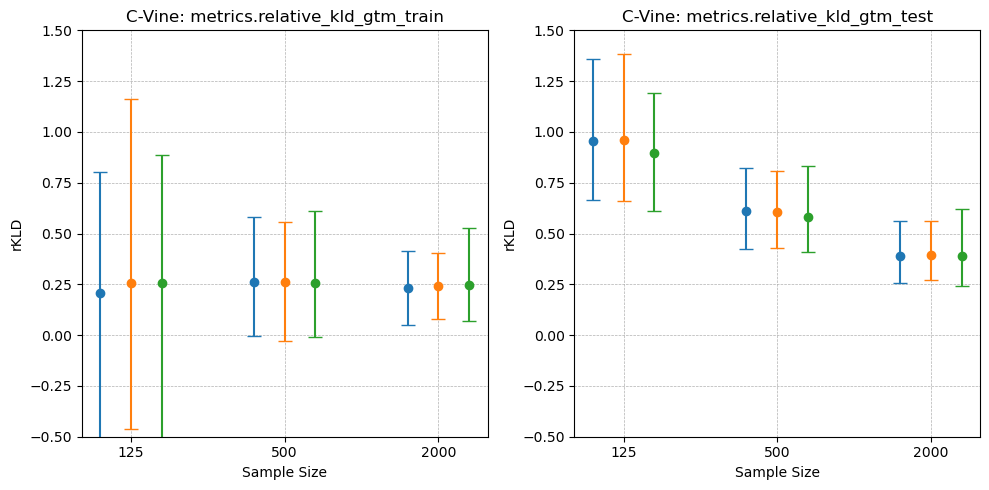

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

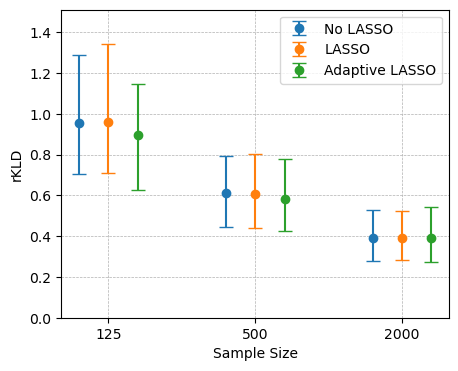

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_cvine_normal.png")

#### Strong

In [12]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["cvine_strong_10D_125obs", "cvine_strong_10D_500obs", "cvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

there are nan values in metrics.relative_kld_gtm_train, the number is  1
there are nan values in metrics.relative_kld_gtm_test, the number is  1


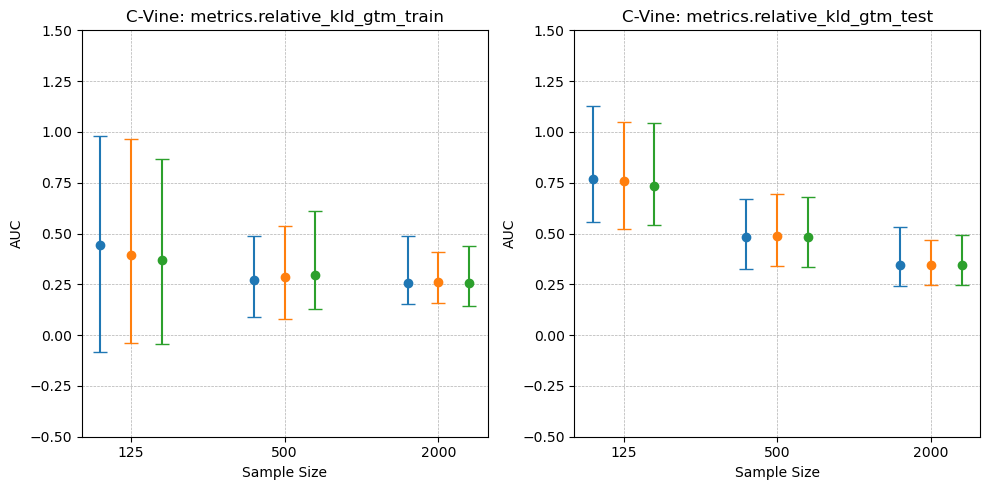

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

there are nan values in metrics.relative_kld_gtm_test, the number is  1


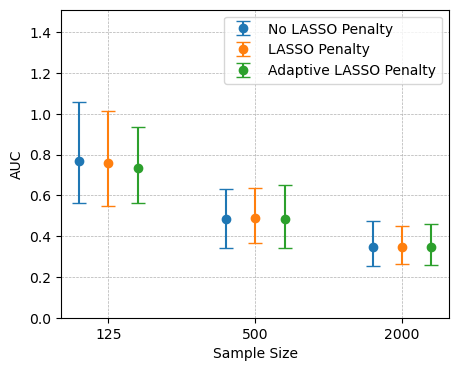

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "C-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_cvine_strong.png")

#### Strong Positive Only

In [65]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_posonly_10D_125obs", "rvine_strong_posonly_10D_500obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

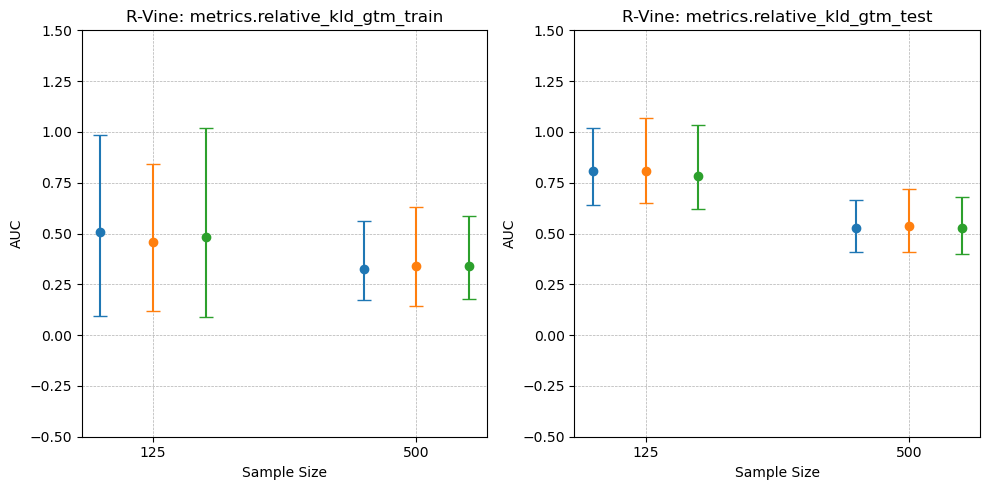

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [125, 500],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

### D-Vine

#### normal

In [69]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_10D_125obs", "dvine_10D_500obs", "dvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

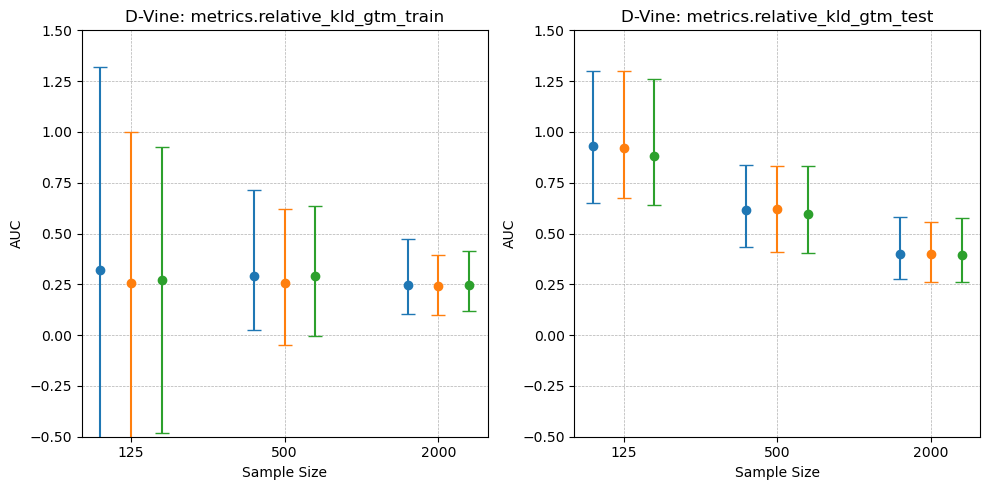

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

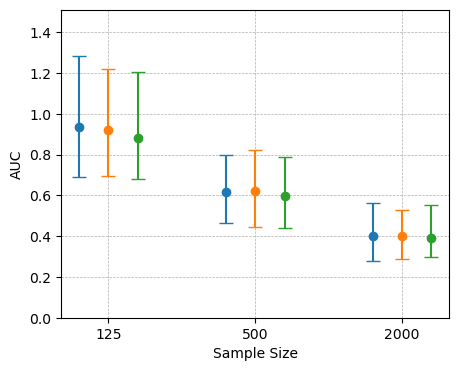

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_dvine_normal.png")

#### Strong

In [72]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["dvine_strong_10D_125obs", "dvine_strong_10D_500obs", "dvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

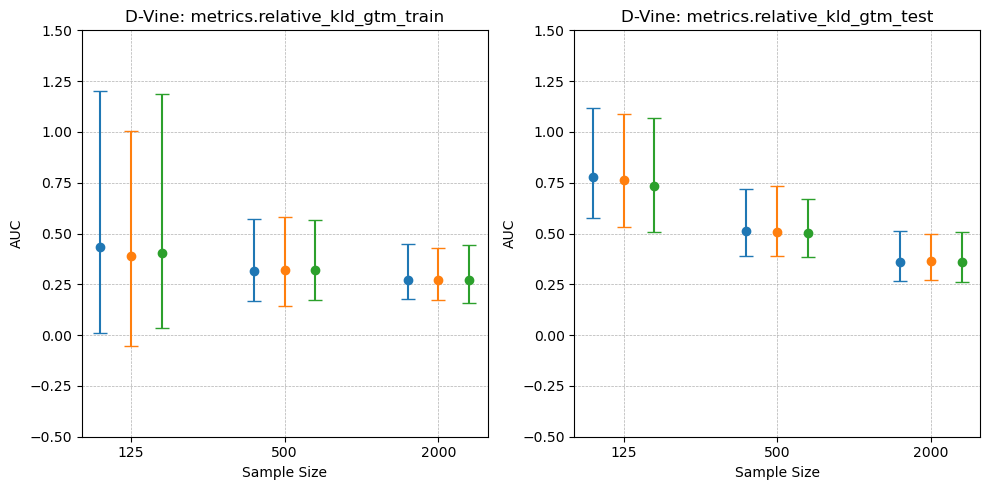

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

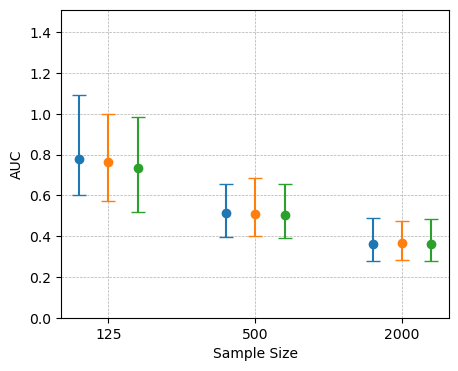

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "D-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_dvine_strong.png")

### R-vine

#### Normal

In [27]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

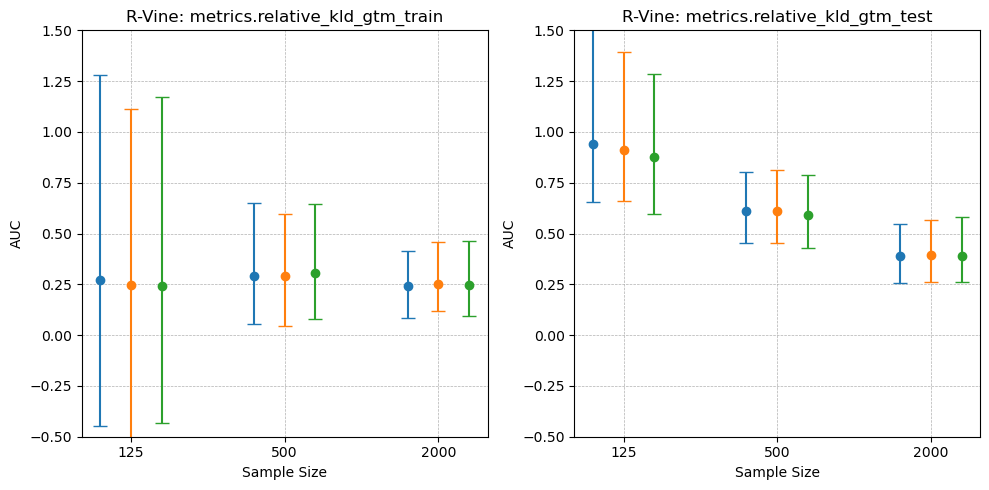

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

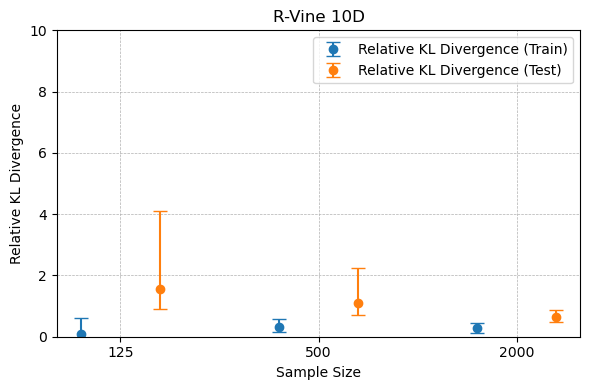

In [ ]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "maf_rvine_10D_125obs",
    500  : "maf_rvine_10D_500obs",
    2000 : "maf_rvine_10D_2000obs"
}

metric_cols = ["metrics.relative_kld_gtm_train", 
               "metrics.relative_kld_gtm_test"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]
    
    # needed for the plot to not break down
    experiment_dfs[sample_size] = experiment_dfs[sample_size][experiment_dfs[sample_size]["metrics.relative_kld_gtm_test"] < 10]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["Relative KL Divergence (Train)", "Relative KL Divergence (Test)"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.0,
    y_max           = 10.0,
    xlabel          = "Sample Size",
    ylabel          = "Relative KL Divergence",y
    
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict = {
    "maf_rvine_10D_125obs" : experiment_dfs[125]["metrics.relative_kld_gtm_test"],
    "maf_rvine_10D_500obs" : experiment_dfs[500]["metrics.relative_kld_gtm_test"],
    "maf_rvine_10D_2000obs" : experiment_dfs[2000]["metrics.relative_kld_gtm_test"],
}

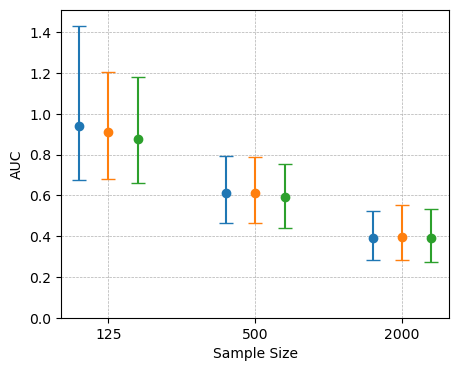

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_normal.png")

#### Strong

In [78]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_10D_125obs", "rvine_strong_10D_500obs", "rvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

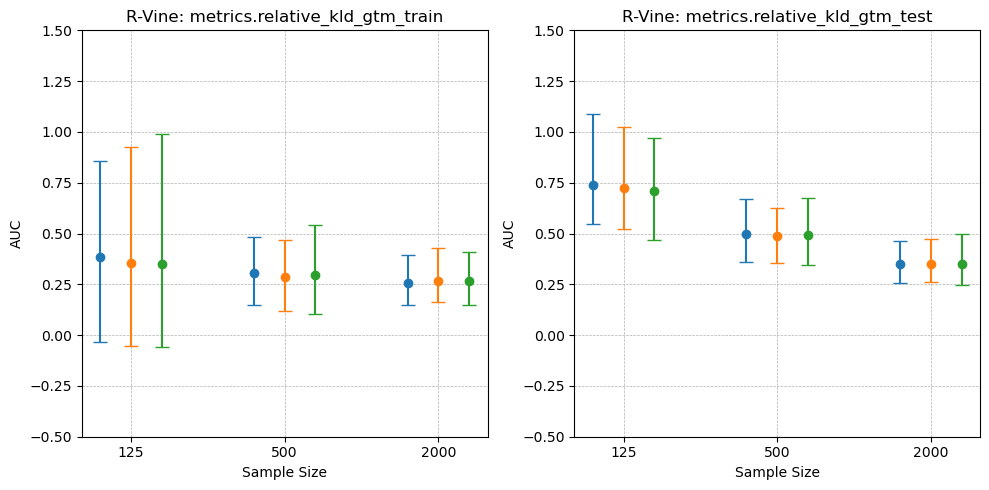

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = -0.5,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=2.5,
        upper_quantile=97.5,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

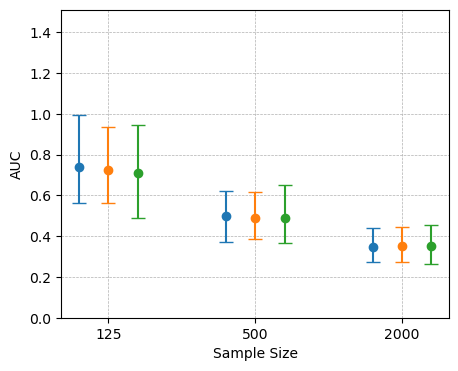

In [ ]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_strong.png")

### R-vine 20D, 50D, 100D

#### Strong

In [323]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_20D_2000obs", "rvine_strong_50D_2000obs_maxpen"]

#kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
#    experiment_name_list = experiment_name_list,
#    seed_min=0,
#    seed_max=99
#)

kld_no = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=[]
)

kld_adaptive = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=[]
)

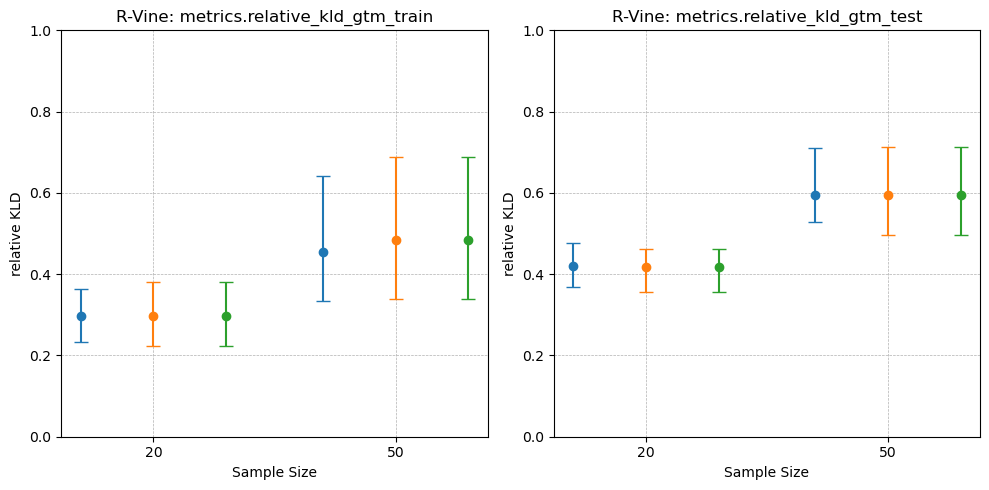

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        kld_no,
        kld_adaptive, #kld_lasso,
        kld_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [20, 50],
        experiment_strings=experiment_name_list,
        y_min = -0.0,
        y_max = 1.,
        benchmark=False,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

In [120]:
kld_no["rvine_strong_20D_2000obs"]["metrics.relative_kld_gtm_test"].mean() - kld_adaptive["rvine_strong_20D_2000obs"]["metrics.relative_kld_gtm_test"].mean()
kld_no["rvine_strong_50D_2000obs_maxpen"]["metrics.relative_kld_gtm_test"].mean() - kld_adaptive["rvine_strong_50D_2000obs_maxpen"]["metrics.relative_kld_gtm_test"].mean()

0.0008010000000000517

In [126]:
((np.array(kld_no["rvine_strong_20D_2000obs"]["metrics.relative_kld_gtm_test"]) - np.array(kld_adaptive["rvine_strong_20D_2000obs"]["metrics.relative_kld_gtm_test"]))>0).mean()

0.6

In [125]:
((np.array(kld_no["rvine_strong_50D_2000obs_maxpen"]["metrics.relative_kld_gtm_test"]) - np.array(kld_adaptive["rvine_strong_50D_2000obs_maxpen"]["metrics.relative_kld_gtm_test"]))>0).mean()

0.55

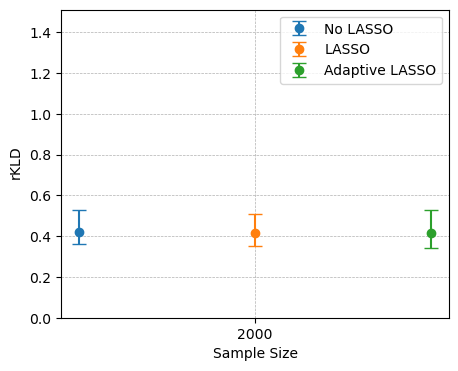

In [325]:
from copy import deepcopy

experiment_name_list = ["rvine_strong_20D_2000obs"]

kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

create_comparison_plot_one_scenario(
        kld_no,
        kld_lasso,
        kld_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        legend=True,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_strong_20D.png")

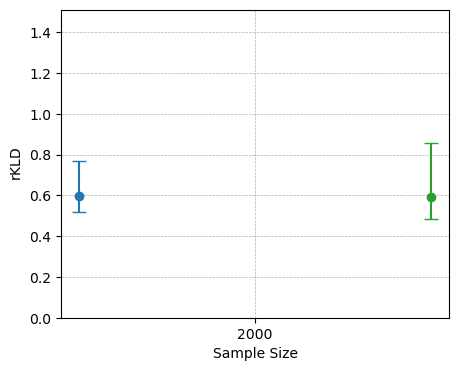

In [326]:
from copy import deepcopy

experiment_name_list = ["rvine_strong_50D_2000obs_maxpen"]

kld_no = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=[]
)

kld_adaptive = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=[]
)

kld_lasso = deepcopy(kld_adaptive)
kld_lasso[experiment_name_list[0]]["metrics.relative_kld_gtm_test"] = -100

create_comparison_plot_one_scenario(
        kld_no,
        kld_lasso,
        kld_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_strong_50D.png")

#### 100D Strong

In [327]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_100D_2000obs_maxpen_I3"]

#kld_no, kld_lasso, kld_adaptive = get_kld_dicts_all(
#    experiment_name_list = experiment_name_list,
#    seed_min=0,
#    seed_max=99
#)

kld_no = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="No",
    names_not_look=[]
)

kld_adaptive = get_kld_dicts_specific(
    experiment_name_list,
    seed_min=0,
    seed_max=99,
    name_look="Adaptive",
    names_not_look=[]
)

there are nan values in metrics.relative_kld_gtm_test, the number is  3
there are nan values in metrics.relative_kld_gtm_test, the number is  3
there are nan values in metrics.relative_kld_gtm_test, the number is  3


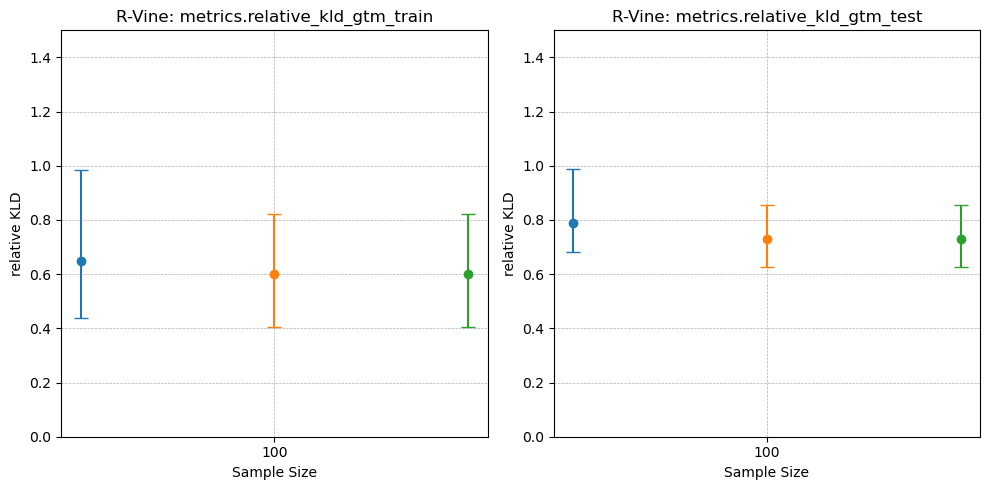

In [ ]:
import matplotlib.pyplot as plt

metrics_list = ["metrics.relative_kld_gtm_train", "metrics.relative_kld_gtm_test"]
ncols = 2

fig, axes = plt.subplots(1,ncols, figsize=(10, 5))

for idx, metric in enumerate(metrics_list):
    col = idx
    ax = axes[col]
    create_comparison_plot_one_scenario(
        kld_no,
        kld_adaptive, #kld_lasso,
        kld_adaptive,
        metric = metric,
        title_str = "R-Vine",
        sample_sizes = [100],
        experiment_strings=experiment_name_list,
        y_min = -0.0,
        y_max = 1.5,
        benchmark=False,
        lower_quantile=10,
        upper_quantile=90,
        ax=ax,
        metric_str=r"$\mathrm{rKLD}$"
    )

plt.tight_layout()
plt.show()

there are nan values in metrics.relative_kld_gtm_test, the number is  3
there are nan values in metrics.relative_kld_gtm_test, the number is  3


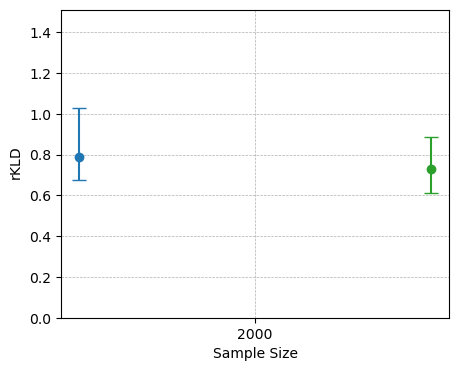

In [328]:
from copy import deepcopy

kld_lasso = deepcopy(kld_adaptive)
kld_lasso[experiment_name_list[0]]["metrics.relative_kld_gtm_test"] = -100

create_comparison_plot_one_scenario(
        kld_no,
        kld_lasso,
        kld_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 1.51,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_strong_100D.png")

### Plots for paper

In [329]:
from tqdm import tqdm
import mlflow
import matplotlib.pyplot as plt

# ── Configuration ─────────────────────────────────────────────────────────────

vine_types = ["cvine", "dvine", "rvine"]

scenarios = {
    "normal": {
        "sample_sizes"   : [125, 500, 2000],
        "obs_strings"    : ["125obs", "500obs", "2000obs"],
        "ggm_sample_sizes": [125, 500, 2000, 8000],
    },
    "strong": {
        "sample_sizes"   : [125, 500, 2000],
        "obs_strings"    : ["125obs", "500obs", "2000obs"],
        "ggm_sample_sizes": [125, 500, 2000, 8000],
    },
}

metrics_to_plot = [
    "metrics.relative_kld_gtm_test",
]

metric_file_names = {
    "metrics.relative_kld_gtm_test" : "relative_kld_gtm_test",
}

#metric_cols_ggm = ["metrics.auc_c", "metrics.auc_p"]

mlruns_scratch_uri = "/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch"
#mlruns_uri         = "/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns"

# ── Main loop ─────────────────────────────────────────────────────────────────

# Total = n_vines × n_scenarios = 3 × 2 = 6 combinations
vine_scenario_combinations = [
    (vine, scenario_name, scenario_cfg)
    for vine in vine_types
    for scenario_name, scenario_cfg in scenarios.items()
]

pbar_outer = tqdm(
    vine_scenario_combinations,
    desc="Vine × Scenario",
    position=0,
)

for vine, scenario_name, scenario_cfg in pbar_outer:

    pbar_outer.set_description(f"Vine={vine} | Scenario={scenario_name}")

    sample_sizes      = scenario_cfg["sample_sizes"]
    obs_strings       = scenario_cfg["obs_strings"]
    ggm_sample_sizes  = scenario_cfg["ggm_sample_sizes"]
    scenario_suffix   = "_strong" if scenario_name == "strong" else ""

    # ── Build experiment name lists ───────────────────────────────────────────
    experiment_name_list = [
        f"{vine}{scenario_suffix}_10D_{obs}"
        for obs in obs_strings
    ]
    ggm_experiment_names = {
        ss: f"ggm_{vine}{scenario_suffix}_10D_{obs}"
        for ss, obs in zip(ggm_sample_sizes, obs_strings + ["8000obs"])
    }

    # ── Load GTM runs ─────────────────────────────────────────────────────────
    mlflow.set_tracking_uri(mlruns_scratch_uri)

    try:
        auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
            experiment_name_list=experiment_name_list,
            seed_min=0,
            seed_max=99,
        )
    except Exception as e:
        tqdm.write(f"  SKIPPING {vine} {scenario_name} — could not load GTM runs: {e}")
        continue

    ## ── Load GGM runs ─────────────────────────────────────────────────────────
    #mlflow.set_tracking_uri(mlruns_uri)
#
    #experiment_dfs = {}
    #for ss, exp_name in ggm_experiment_names.items():
    #    try:
    #        experiment     = mlflow.get_experiment_by_name(exp_name)
    #        df_runs        = mlflow.search_runs([experiment.experiment_id])
    #        experiment_dfs[ss] = df_runs[metric_cols_ggm + ["tags.seed_value"]]
    #    except Exception as e:
    #        tqdm.write(f"  WARNING: could not load GGM experiment '{exp_name}': {e}")
#
    ## ── Build benchmark dict ──────────────────────────────────────────────────
    #benchmark_dict = {
    #    exp_name: experiment_dfs[ss]["metrics.auc_c"]
    #    for exp_name, ss in zip(experiment_name_list, sample_sizes)
    #    if ss in experiment_dfs
    #}
    #benchmark_available = len(benchmark_dict) == len(experiment_name_list)
    #if not benchmark_available:
    #    tqdm.write(f"  WARNING: benchmark dict incomplete for {vine} {scenario_name} — plotting without benchmark.")
    #    benchmark_dict = False
#
    # ── Labels ───────────────────────────────────────────────────────────────
    vine_label     = vine[0].upper() + "-" + vine[1:]
    scenario_label = "Strong" if scenario_name == "strong" else "Normal"
    title_str      = f"{vine_label} ({scenario_label})"

    # ── Plot each metric ──────────────────────────────────────────────────────
    pbar_inner = tqdm(
        metrics_to_plot,
        desc=f"  Metrics [{vine} {scenario_name}]",
        position=1,
        leave=False,   # clears inner bar when done so outer bar stays clean
    )

    for metric in pbar_inner:

        pbar_inner.set_description(f"  {metric_file_names[metric]} [{vine} {scenario_name}]")

        fig, ax = plt.subplots(figsize=(6, 4))
        
        if "cvine" in vine:
            legend_bool = True
        else:
            legend_bool = False

        create_comparison_plot_one_scenario(
            auc_no,
            auc_lasso,
            auc_adaptive,
            metric             = metric,
            title_str          = title_str,
            sample_sizes       = sample_sizes,
            experiment_strings = experiment_name_list,
            y_min = 0.0,
            y_max = 1.51,
            lower_quantile=5,
            upper_quantile=95,
            benchmark=False,
            add_metric_title   = False,
            legend             = legend_bool,
            ax                 = ax,
            metric_str=r"$\mathrm{rKLD}$"
        )

        filename = (
            f"{metric_file_names[metric]}"
            f"_{vine}"
            f"{scenario_suffix}"
            f"_{scenario_name}.png"
        )
        plt.tight_layout()
        plt.savefig(filename, dpi=150)
        plt.close(fig)
        tqdm.write(f"  Saved: {filename}")

tqdm.write("\nAll done.")

Vine=cvine | Scenario=normal:   0%|          | 0/6 [00:00<?, ?it/s]
Vine=cvine | Scenario=strong:  17%|█▋        | 1/6 [00:21<01:48, 21.62s/it]  

  Saved: relative_kld_gtm_test_cvine_normal.png



Vine=dvine | Scenario=normal:  33%|███▎      | 2/6 [00:36<01:11, 17.89s/it]  

  Saved: relative_kld_gtm_test_cvine_strong_strong.png



Vine=dvine | Scenario=strong:  50%|█████     | 3/6 [00:59<01:00, 20.19s/it]  

  Saved: relative_kld_gtm_test_dvine_normal.png


... (2 outputs left out)


Vine=rvine | Scenario=strong:  83%|████████▎ | 5/6 [01:36<00:19, 19.40s/it]  

  Saved: relative_kld_gtm_test_rvine_normal.png



Vine=rvine | Scenario=strong: 100%|██████████| 6/6 [01:52<00:00, 18.70s/it]  

  Saved: relative_kld_gtm_test_rvine_strong_strong.png

All done.


### Raw KLD and Raw Log Scores for appendix

In [411]:
from tqdm import tqdm
import mlflow
import numpy as np
import pandas as pd


# ── Configuration ─────────────────────────────────────────────────────────────

vine_types = ["cvine", "dvine", "rvine"]

scenarios = {
    "normal": {
        "sample_sizes": [125, 500, 2000],
        "obs_strings": ["125obs", "500obs", "2000obs"],
    },
    "strong": {
        "sample_sizes": [125, 500, 2000],
        "obs_strings": ["125obs", "500obs", "2000obs"],
    },
}

mlruns_scratch_uri = (
    "/Users/matthiasherp/Desktop/"
    "phd_github_repositories/gtm/mlruns_scratch"
)

seed_col = "tags.seed_value"
runname_col = "tags.mlflow.runName"

raw_kld_columns = [
    "metrics.kld_gtm_test",
    "metrics.kld_gaussian_test",
]

mlflow.set_tracking_uri(mlruns_scratch_uri)

In [418]:
def classify_lasso_method(run_name):
    """
    Classify an MLflow run as no LASSO, LASSO, or adaptive LASSO.

    The order is important because 'adaptive' run names may also contain
    the word 'lasso'.
    """
    run_name = str(run_name)#.lower()

    if "Adaptive" in run_name:
        return "adaptive"

    if "Lasso" in run_name:
        return "lasso"

    if "No" in run_name:
        return "no"

    return None


def load_raw_kld_runs(
    experiment_name,
    seed_min=0,
    seed_max=99,
):
    """
    Load raw GTM and GGM KLD values directly from one MLflow experiment.
    """
    experiment = mlflow.get_experiment_by_name(experiment_name)

    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found.")

    runs_df = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        output_format="pandas",
    )

    required_columns = [
        runname_col,
        seed_col,
        "status",
        *raw_kld_columns,
    ]

    missing_columns = [
        column for column in required_columns
        if column not in runs_df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing columns in experiment '{experiment_name}': "
            f"{missing_columns}"
        )

    # Keep successfully completed runs only
    runs_df = runs_df.loc[
        runs_df["status"].eq("FINISHED"),
        required_columns,
    ].copy()

    # Convert seed safely to numeric
    runs_df[seed_col] = pd.to_numeric(
        runs_df[seed_col],
        errors="coerce",
    )

    # Restrict seed range
    runs_df = runs_df.loc[
        runs_df[seed_col].between(seed_min, seed_max)
    ].copy()

    # Convert metrics safely to numeric
    for metric_column in raw_kld_columns:
        runs_df[metric_column] = pd.to_numeric(
            runs_df[metric_column],
            errors="coerce",
        )

    # Determine the penalty method from the run name
    runs_df["lasso"] = runs_df[runname_col].apply(
        classify_lasso_method
    )

    unknown_runs = runs_df["lasso"].isna()

    if unknown_runs.any():
        unknown_names = (
            runs_df.loc[unknown_runs, runname_col]
            .drop_duplicates()
            .tolist()
        )

        tqdm.write(
            f"  WARNING: ignoring unclassified runs in "
            f"'{experiment_name}': {unknown_names}"
        )

        runs_df = runs_df.loc[~unknown_runs].copy()

    return runs_df

In [421]:
summary_rows = []

experiment_configurations = [
    (vine, dependence, scenario_config)
    for vine in vine_types
    for dependence, scenario_config in scenarios.items()
]

for vine, dependence, scenario_config in tqdm(
    experiment_configurations,
    desc="Vine × dependence",
):
    scenario_suffix = "_strong" if dependence == "strong" else ""

    for N, obs_string in zip(
        scenario_config["sample_sizes"],
        scenario_config["obs_strings"],
    ):
        experiment_name = (
            f"{vine}{scenario_suffix}_10D_{obs_string}"
        )

        try:
            runs_df = load_raw_kld_runs(
                experiment_name=experiment_name,
                seed_min=0,
                seed_max=99,
            )
        except Exception as error:
            tqdm.write(f"SKIPPING {experiment_name}: {error}")
            continue

        row = {
            "N": N,
            "vine": vine,
            "dependence": dependence,
            "experiment": experiment_name,
        }

        # GTM KLD separately for no, lasso, and adaptive
        for method in ["no", "lasso", "adaptive"]:
            values = runs_df.loc[
                runs_df["lasso"].eq(method),
                "metrics.kld_gtm_test",
            ].dropna()

            if values.empty:
                row[f"kld_gtm_{method}"] = np.nan
                tqdm.write(
                    f"  WARNING: no GTM KLD values for "
                    f"{experiment_name}, method={method}"
                )
            else:
                row[f"kld_gtm_{method}"] = (
                    f"{values.mean():.3f} "
                    f"({values.std(ddof=1):.3f})"
                )

        # GGM KLD should not depend on the GTM penalty method.
        # Keep one GGM value per seed to avoid counting it three times.
        ggm_values = (
            runs_df[
                [seed_col, "metrics.kld_gaussian_test"]
            ]
            .dropna(subset=["metrics.kld_gaussian_test"])
            .drop_duplicates(subset=[seed_col])
            ["metrics.kld_gaussian_test"]
        )

        if ggm_values.empty:
            row["kld_ggm"] = np.nan
            tqdm.write(
                f"  WARNING: no GGM KLD values for {experiment_name}"
            )
        else:
            row["kld_ggm"] = (
                f"{ggm_values.mean():.3f} "
                f"({ggm_values.std(ddof=1):.3f})"
            )

        summary_rows.append(row)

Vine × dependence:   0%|          | 0/6 [00:01<?, ?it/s]

Vine × dependence:  33%|███▎      | 2/6 [00:16<00:27,  6.84s/it]

Vine × dependence:  50%|█████     | 3/6 [00:25<00:22,  7.64s/it]

Vine × dependence:  67%|██████▋   | 4/6 [00:34<00:16,  8.24s/it]

Vine × dependence:  83%|████████▎ | 5/6 [00:43<00:08,  8.34s/it]

Vine × dependence: 100%|██████████| 6/6 [00:48<00:00,  8.04s/it]


In [422]:
raw_kld_table = pd.DataFrame(summary_rows)

raw_kld_table["vine"] = pd.Categorical(
    raw_kld_table["vine"],
    categories=["cvine", "dvine", "rvine"],
    ordered=True,
)

raw_kld_table["dependence"] = pd.Categorical(
    raw_kld_table["dependence"],
    categories=["normal", "strong"],
    ordered=True,
)

raw_kld_table = (
    raw_kld_table[
        [
            "N",
            "vine",
            "dependence",
            "kld_gtm_no",
            "kld_gtm_lasso",
            "kld_gtm_adaptive",
            "kld_ggm",
        ]
    ]
    .sort_values(["vine", "dependence", "N"])
    .reset_index(drop=True)
)

display(raw_kld_table)

raw_kld_table.to_csv(
    "raw_kld_summary_one_row_per_experiment.csv",
    index=False,
)

,N,vine,dependence,kld_gtm_no,kld_gtm_lasso,kld_gtm_adaptive,kld_ggm
0,125,cvine,normal,2.022 (0.388),2.027 (0.412),1.941 (0.410),2.105 (0.362)
1,500,cvine,normal,1.086 (0.218),1.079 (0.216),1.046 (0.224),1.704 (0.301)
2,2000,cvine,normal,0.653 (0.170),0.654 (0.170),0.648 (0.181),1.623 (0.299)
3,125,cvine,strong,3.957 (0.798),3.842 (0.719),3.792 (0.711),4.905 (0.809)
4,500,cvine,strong,2.253 (0.421),2.271 (0.424),2.257 (0.456),4.369 (0.735)
5,2000,cvine,strong,1.519 (0.412),1.510 (0.327),1.500 (0.352),4.255 (0.734)
6,125,dvine,normal,2.053 (0.374),2.041 (0.372),1.979 (0.376),2.182 (0.351)
7,500,dvine,normal,1.147 (0.227),1.153 (0.230),1.114 (0.219),1.788 (0.305)
8,2000,dvine,normal,0.698 (0.161),0.697 (0.158),0.685 (0.151),1.711 (0.304)
9,125,dvine,strong,4.344 (0.816),4.269 (0.818),4.143 (0.810),5.326 (0.871)


In [425]:
raw_kld_table.to_latex(
    "raw_kld_summary_one_row_per_experiment.tex",
    index=False,
    escape=False,
    caption="Mean (SD) of the raw KLD.",
    label="tab:raw_kld",
)

# Does Penalty reduce values of hessian for independent parts?

### Analysis Functions

In [146]:
def get_metric_differences_experiment(
    experiment_name="rvine_10D_125obs", 
    name_ending_group_one=False, 
    name_ending_group_two=False, 
    seed_min=False, 
    seed_max=False,
    metrics_list=[],
    dependence=0,
    ommit_bootstraps=True
):
    import pandas as pd
    experiment = mlflow.get_experiment_by_name(experiment_name) 
    df_runs = mlflow.search_runs([experiment.experiment_id])
    
    if ommit_bootstraps == True:
        df_runs = df_runs[["Bootstrap" not in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]

    if seed_min is not False:
        df_runs = df_runs[[int(df_runs.iloc[i]["tags.seed_value"]) >= seed_min for i in range(df_runs.shape[0])]]
    if seed_max is not False:
        df_runs = df_runs[[int(df_runs.iloc[i]["tags.seed_value"]) <= seed_max for i in range(df_runs.shape[0])]]
    
    if name_ending_group_one is not False:
        subset_group_1 = df_runs[[name_ending_group_one in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]
    else:
        subset_group_1 = df_runs

    if name_ending_group_two is not False:
        subset_group_2 = df_runs[[name_ending_group_two in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]
    else:
        subset_group_2 = df_runs
    
    # take only unique runs
    subset_group_1 = subset_group_1.drop_duplicates(subset="tags.mlflow.runName", keep="first").reset_index(drop=True)
    subset_group_2 = subset_group_2.drop_duplicates(subset="tags.mlflow.runName", keep="first").reset_index(drop=True)

    dict_results = {}
    if "tags.seed_value" not in metrics_list:
        metrics_list.append("tags.seed_value")
    
    seeds_group1 = set(subset_group_1["tags.seed_value"].astype(int))
    seeds_group2 = set(subset_group_2["tags.seed_value"].astype(int))
    shared_seeds = seeds_group1 & seeds_group2

    for seed in shared_seeds:
        run_1 = subset_group_1[subset_group_1["tags.seed_value"].astype(int) == seed].iloc[0]
        run_2 = subset_group_2[subset_group_2["tags.seed_value"].astype(int) == seed].iloc[0]

        uri_1 = run_1["artifact_uri"][7:] + "/conditional_independence_table_model_samples.csv"
        uri_2 = run_2["artifact_uri"][7:] + "/conditional_independence_table_model_samples.csv"

        df1 = pd.read_csv(uri_1)
        df2 = pd.read_csv(uri_2)

        df1_indep = df1[df1["dependence"] == dependence].reset_index(drop=True)
        df2_indep = df2[df2["dependence"] == dependence].reset_index(drop=True)

        result = {"tags.seed_value": seed}
        for metric in metrics_list:
            if metric == "tags.seed_value":
                continue
            if metric in df1_indep.columns and metric in df2_indep.columns:
                min_len = min(len(df1_indep), len(df2_indep))
                # Compute entrywise differences (can adapt as needed)
                vals1 = df1_indep[metric][:min_len].values
                vals2 = df2_indep[metric][:min_len].values
                differences = (vals2 - vals1) / (vals1 + 1e-8)  # avoid div by zero!
                result[metric] = differences.tolist()
            else:
                result[metric] = []
        dict_results[seed] = result
    return dict_results

In [182]:
def plot_differences_metrics(experiment_name, differences_dict_0, differences_dict_1, metrics_to_plot = ["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean"], plot_title=True):
    import matplotlib.pyplot as plt
    import math

    n_metrics = len(metrics_to_plot)
    ncols = 3
    nrows = math.ceil(n_metrics / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
    axes = axes.flatten()

    for idx, metric in enumerate(metrics_to_plot):
        diffs_0 = []
        for v in differences_dict_0.values():
            diffs_0.extend([d for d in v[metric] if d is not None and not pd.isna(d)])
        diffs_1 = []
        for v in differences_dict_1.values():
            diffs_1.extend([d for d in v[metric] if d is not None and not pd.isna(d)])
        ax = axes[idx]
        bins = np.linspace(-1.5, 1.5, num=100)
        ax.hist(diffs_0, bins=bins, color='red', alpha=0.4, edgecolor='black', label="dependence=0")
        ax.hist(diffs_1, bins=bins, color='blue', alpha=0.4, edgecolor='black', label="dependence=1")
        if plot_title == True:
            ax.set_title(f"{metric} differences")
        ax.set_xlabel(f"{metric} relative differences")
        ax.set_ylabel("Frequency")
        ax.grid(True, linestyle='--', linewidth=0.5)
    ax.legend()
    for idx in range(len(metrics_to_plot), len(axes)):
        axes[idx].set_visible(False)
    if plot_title == True:
        plt.suptitle(experiment_name, fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    return fig

## No vs Adaptive

### C-Vine

#### Normal

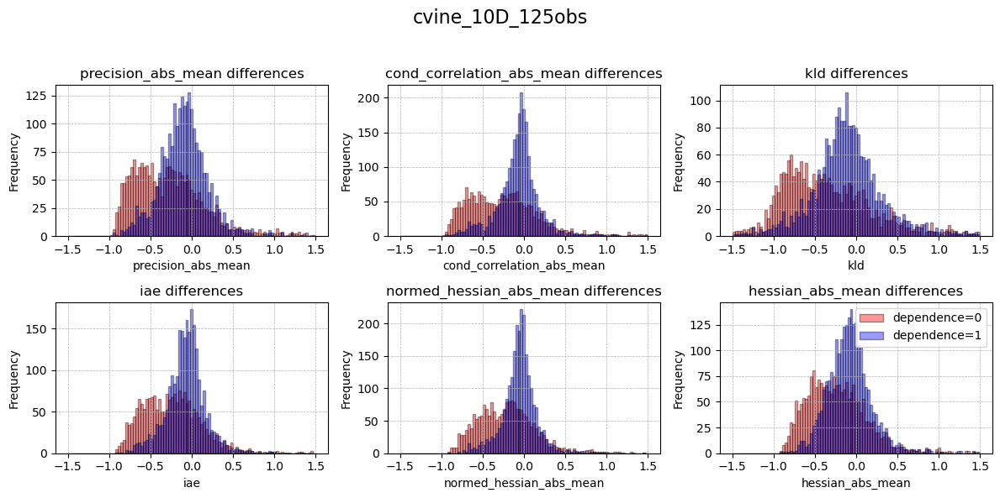

In [128]:
experiment_name="cvine_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

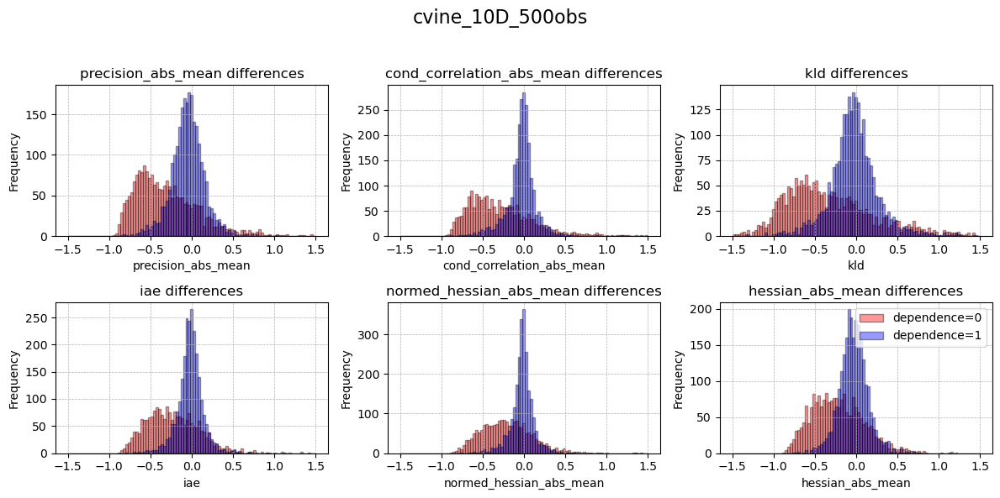

In [129]:
experiment_name="cvine_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

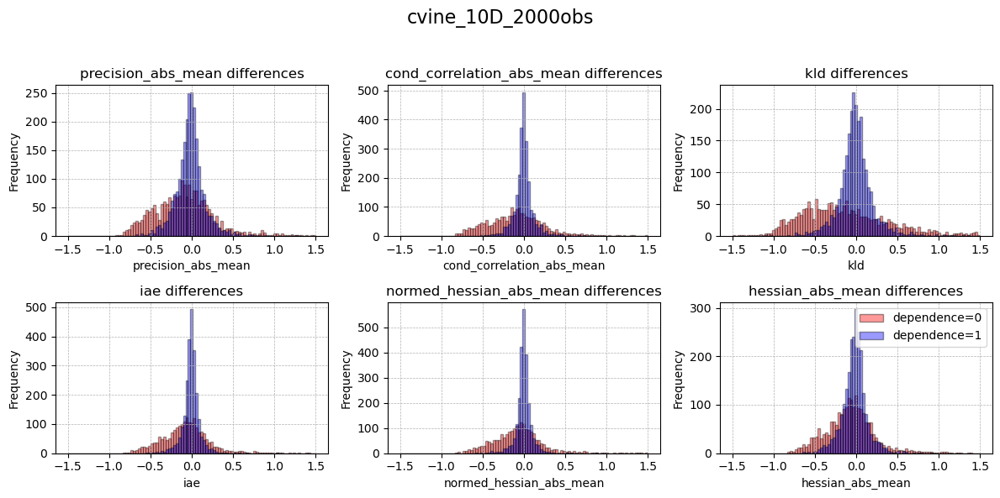

In [130]:
experiment_name="cvine_10D_2000obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

#### Strong

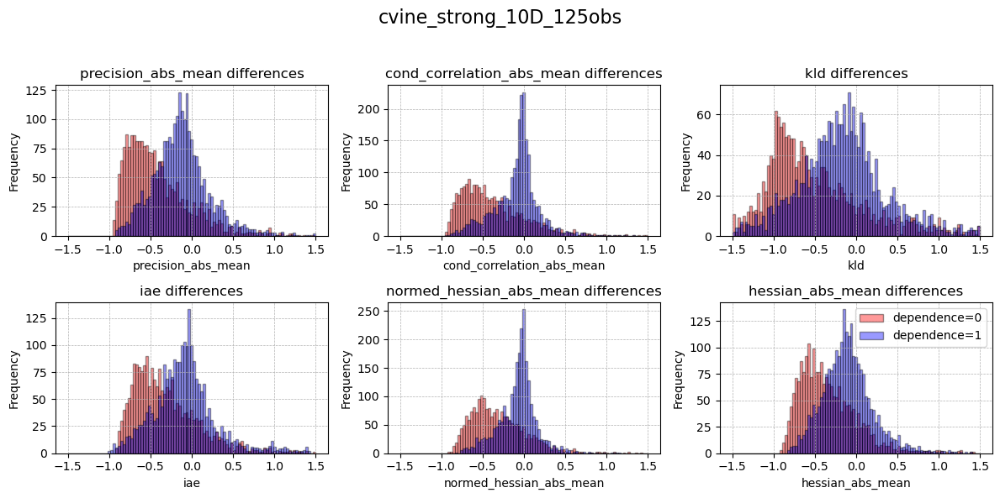

In [131]:
experiment_name="cvine_strong_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

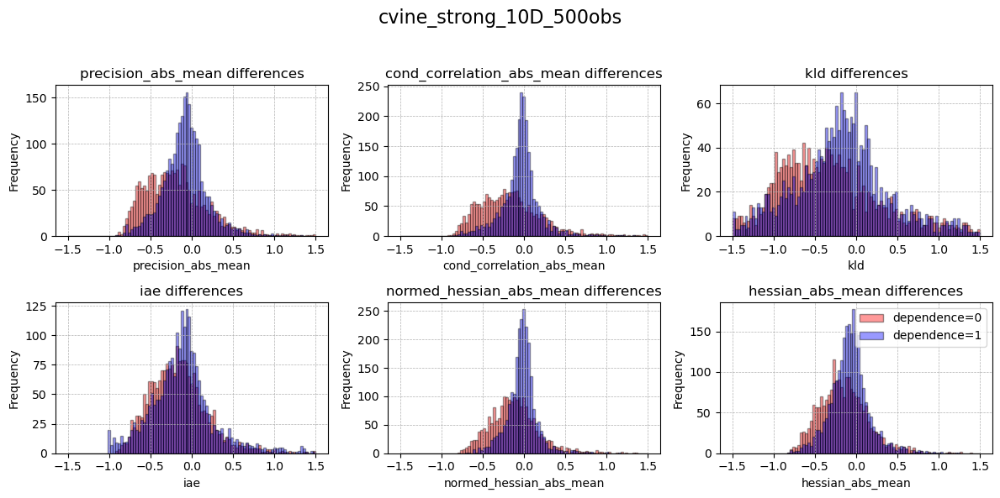

In [132]:
experiment_name="cvine_strong_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

### D-Vine

#### Normal

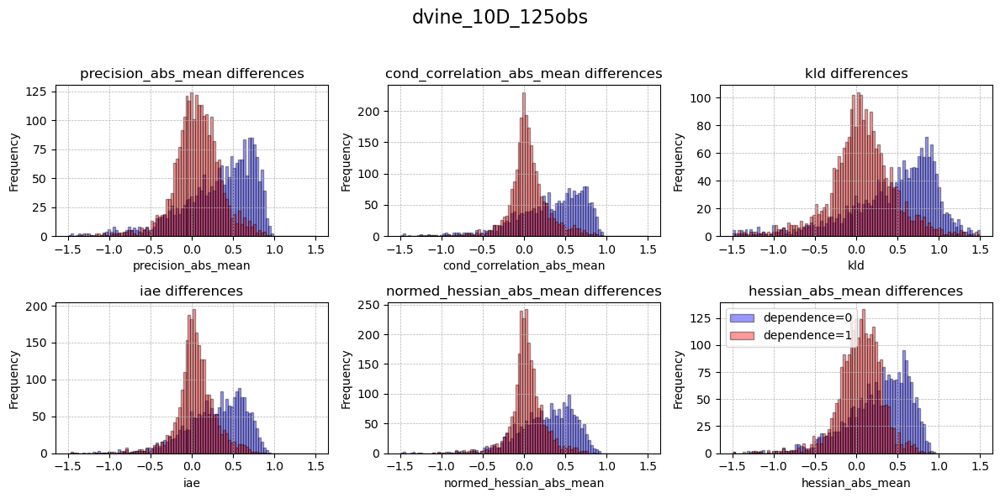

In [401]:
experiment_name="dvine_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

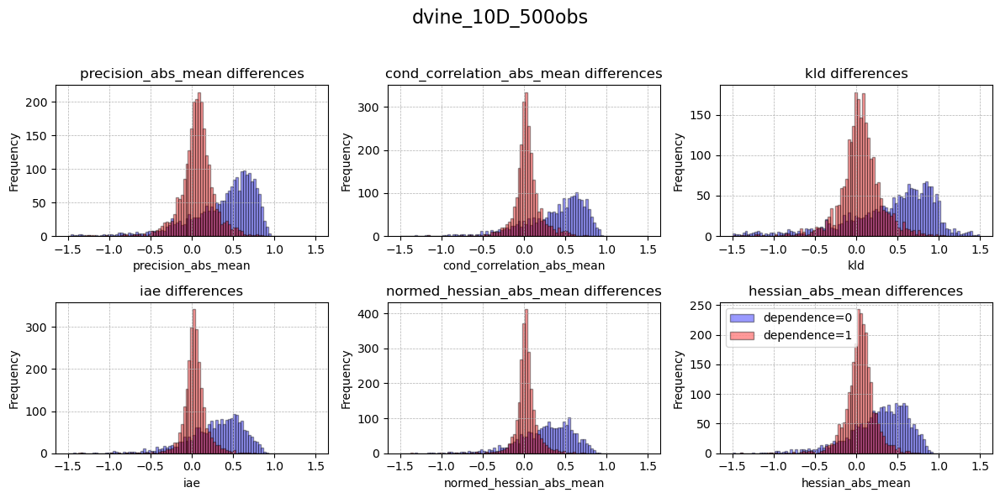

In [402]:
experiment_name="dvine_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

#### Strong

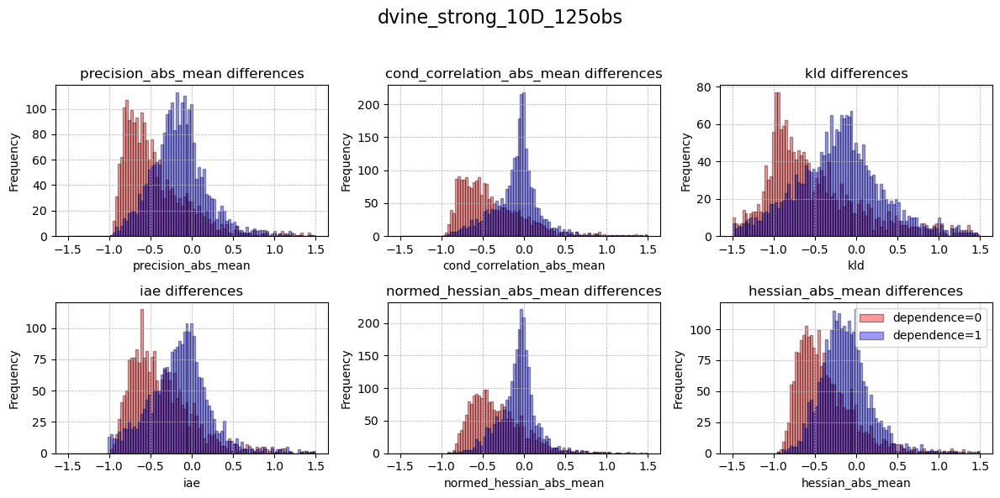

In [133]:
experiment_name="dvine_strong_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

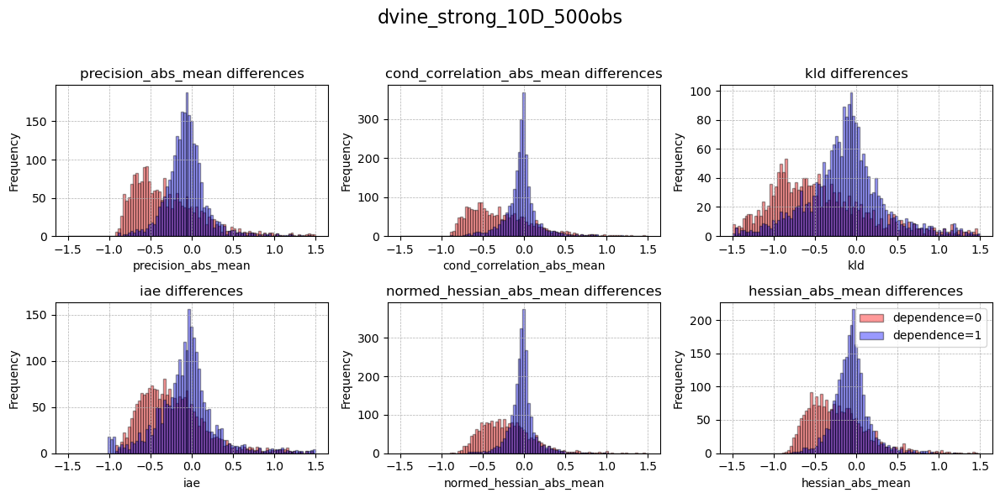

In [134]:
experiment_name="dvine_strong_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

### R-Vine

#### Normal

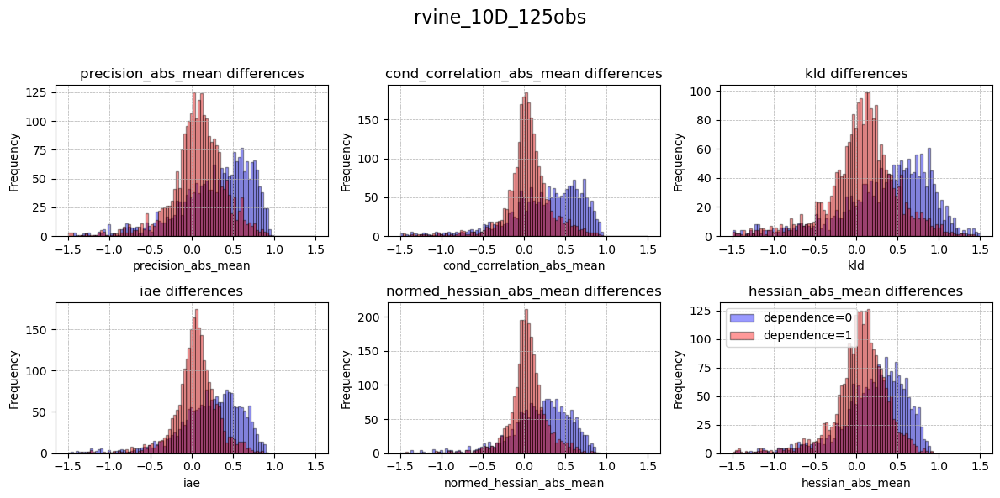

In [405]:
experiment_name="rvine_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

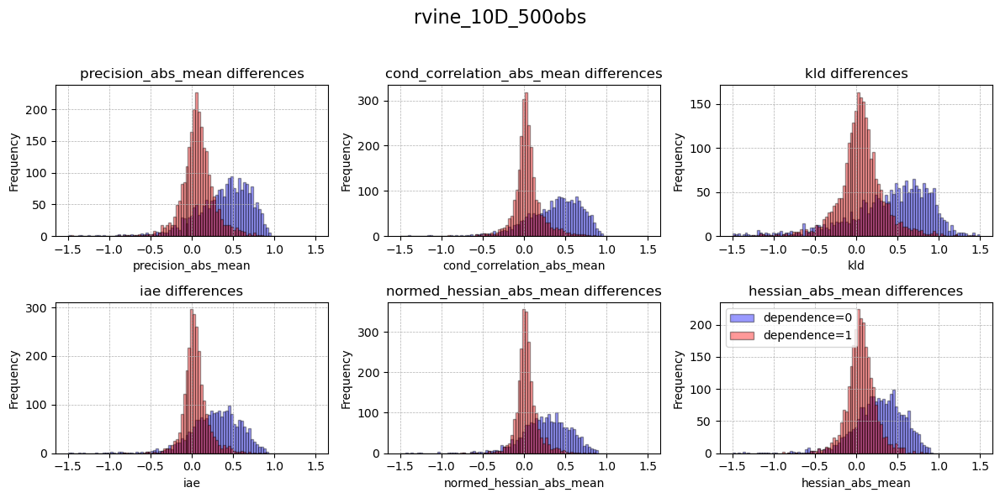

In [406]:
experiment_name="rvine_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

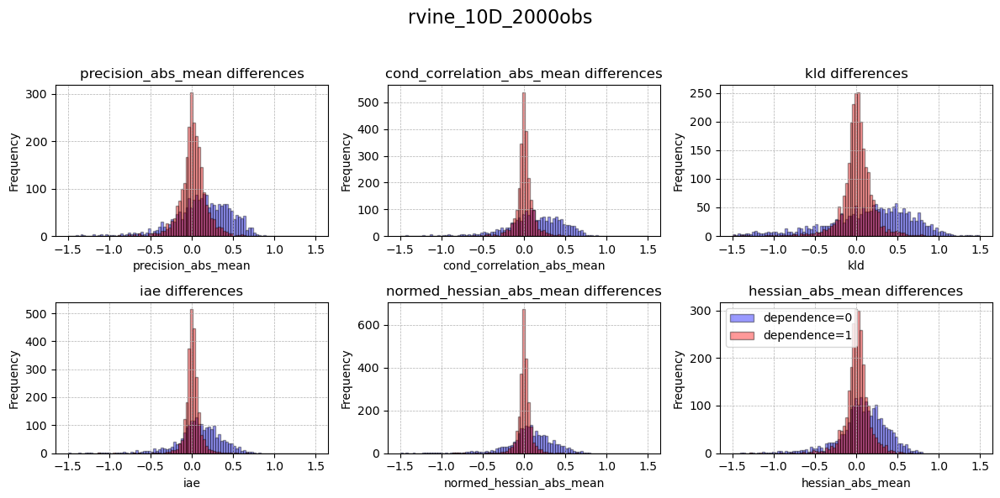

In [14]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_10D_2000obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

#### Strong

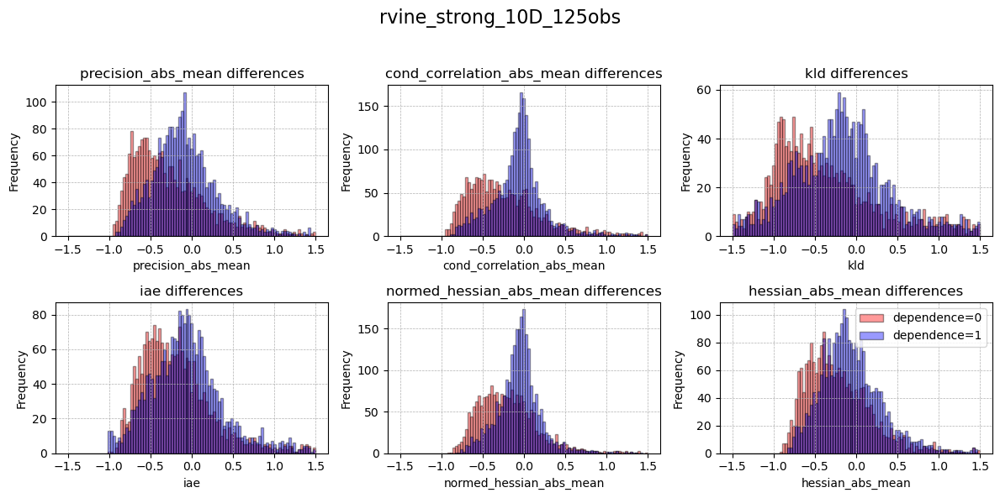

In [135]:
experiment_name="rvine_strong_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

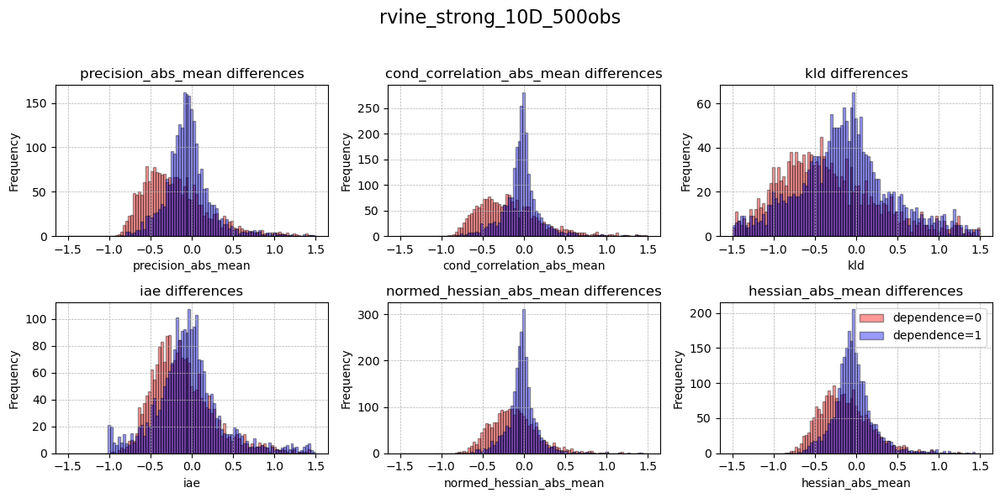

In [137]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_strong_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

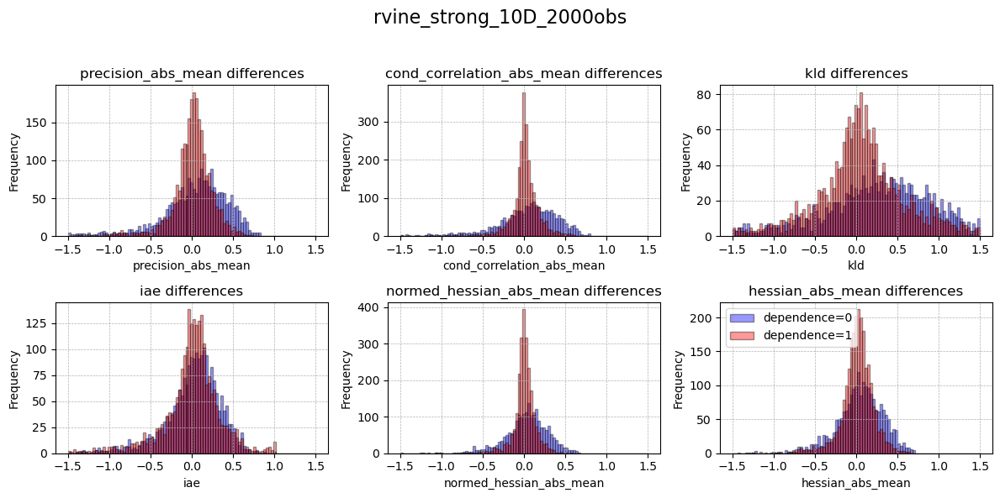

In [13]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_strong_10D_2000obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

### Bootstrap Experiments

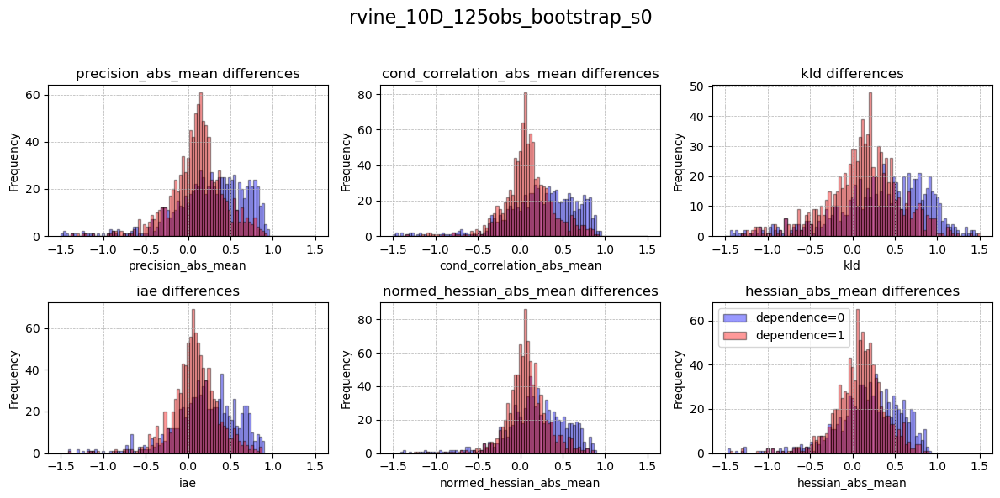

In [100]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_10D_125obs_bootstrap_s0"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

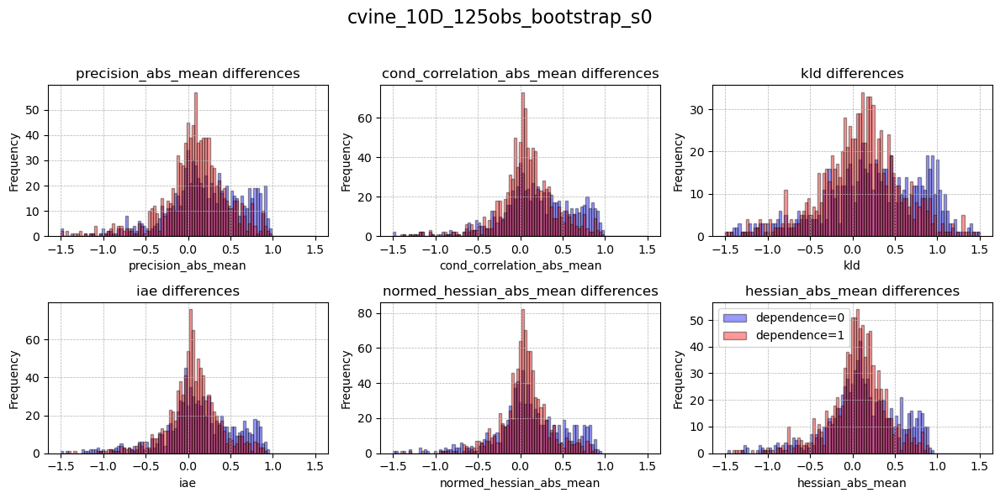

In [101]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="cvine_10D_125obs_bootstrap_s0"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

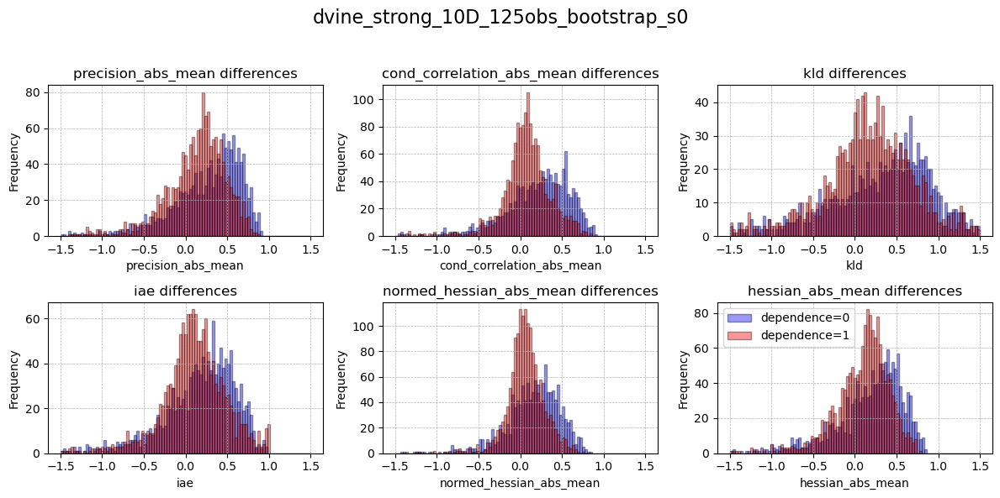

In [ ]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="dvine_strong_10D_125obs_bootstrap_s0"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

### Plots for Presentation

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


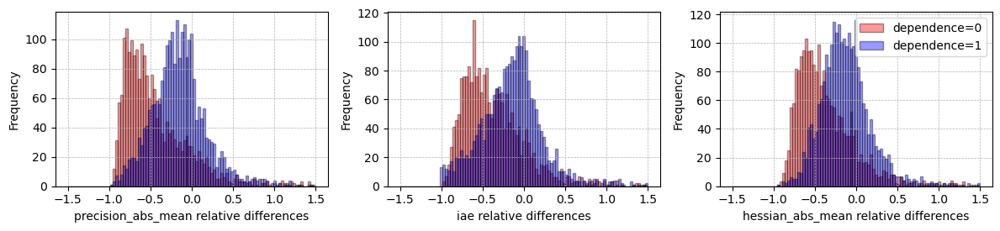

In [183]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="dvine_strong_10D_125obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_dvine_strong_125")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


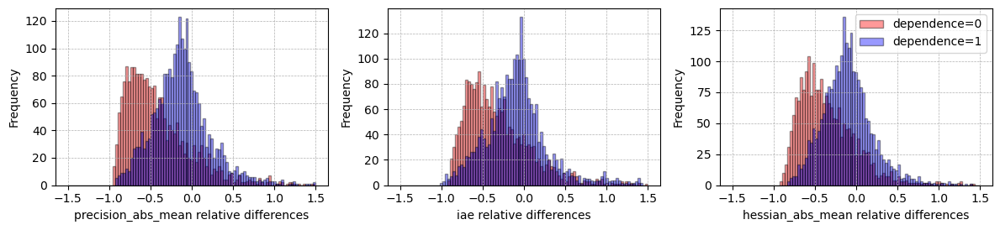

In [184]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="cvine_strong_10D_125obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_cvine_strong_125")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


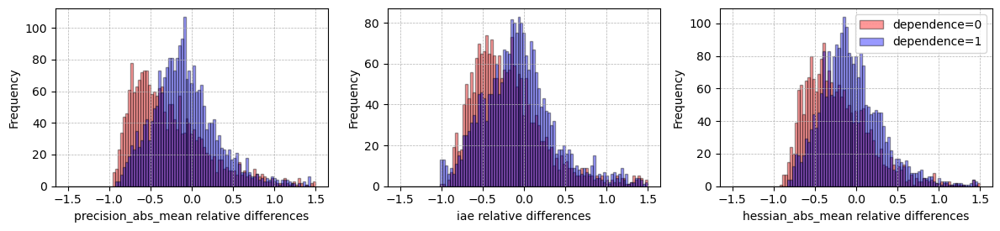

In [185]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_strong_10D_125obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_rvine_strong_125")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


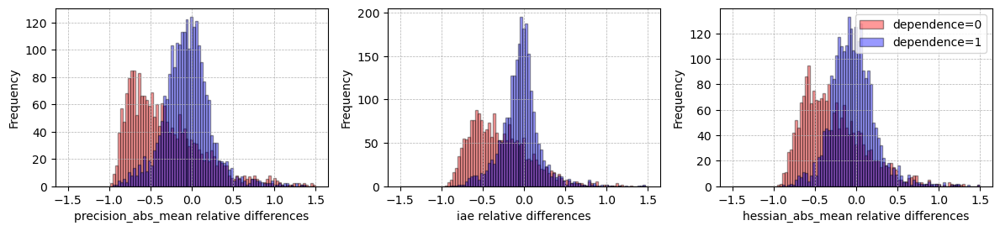

In [186]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="dvine_10D_125obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_dvine_125")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


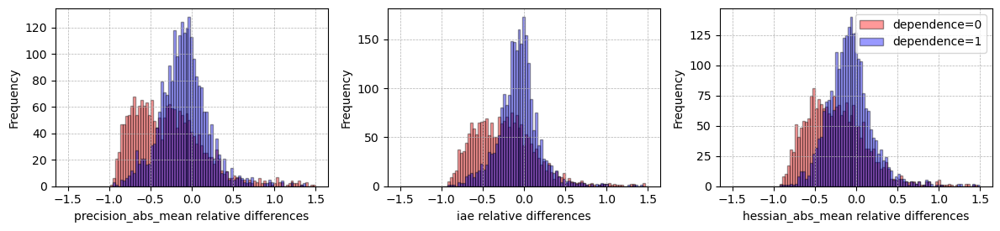

In [187]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="cvine_10D_125obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_cvine_125")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


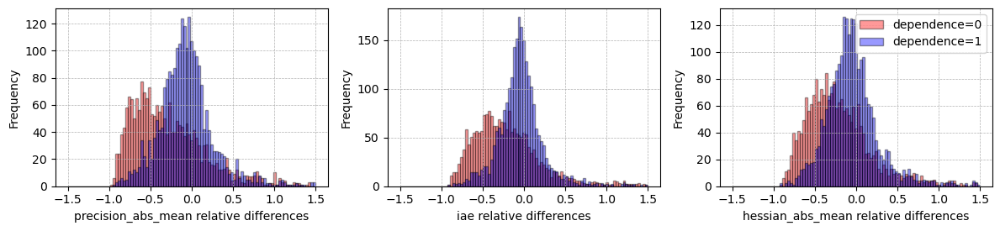

In [188]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_10D_125obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_rvine_125")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


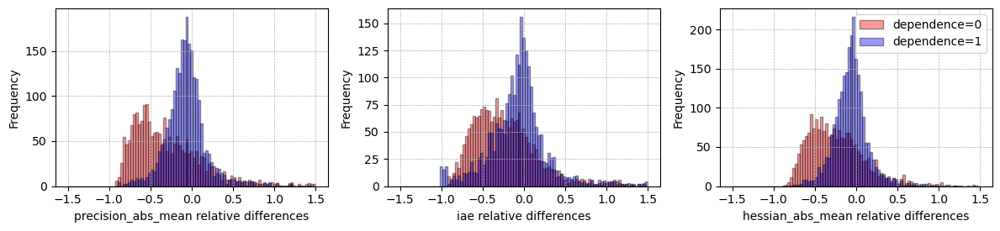

In [189]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="dvine_strong_10D_500obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_dvine_strong_500")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


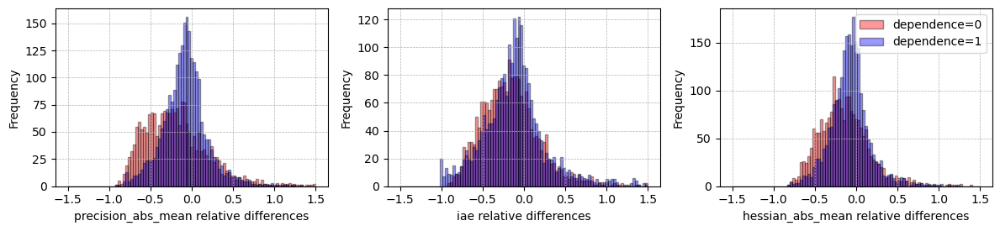

In [190]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="cvine_strong_10D_500obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_cvine_strong_500")

['precision_abs_mean', 'iae', 'hessian_abs_mean', 'tags.seed_value']
['precision_abs_mean', 'iae', 'hessian_abs_mean']


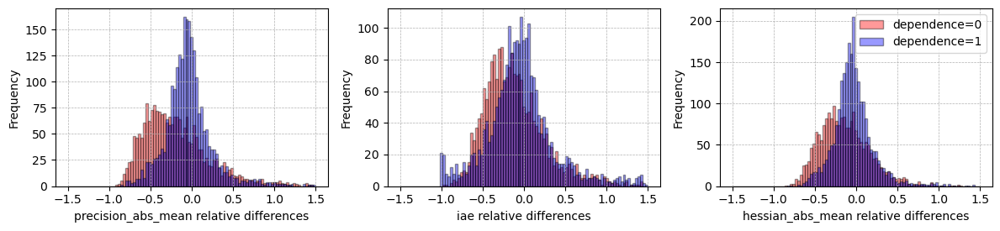

In [191]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name="rvine_strong_10D_500obs"

metrics_to_plot = ["precision_abs_mean", "iae", "hessian_abs_mean" ]


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Adaptive", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=metrics_to_plot,
                          dependence=1)

print(metrics_to_plot)
metrics_to_plot = metrics_to_plot[:-1]
print(metrics_to_plot)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1, metrics_to_plot=metrics_to_plot, plot_title=False)
plt.savefig("reldiff_adaptive_no_rvine_strong_500")

## No vs Lasso

### C-Vine

#### Normal

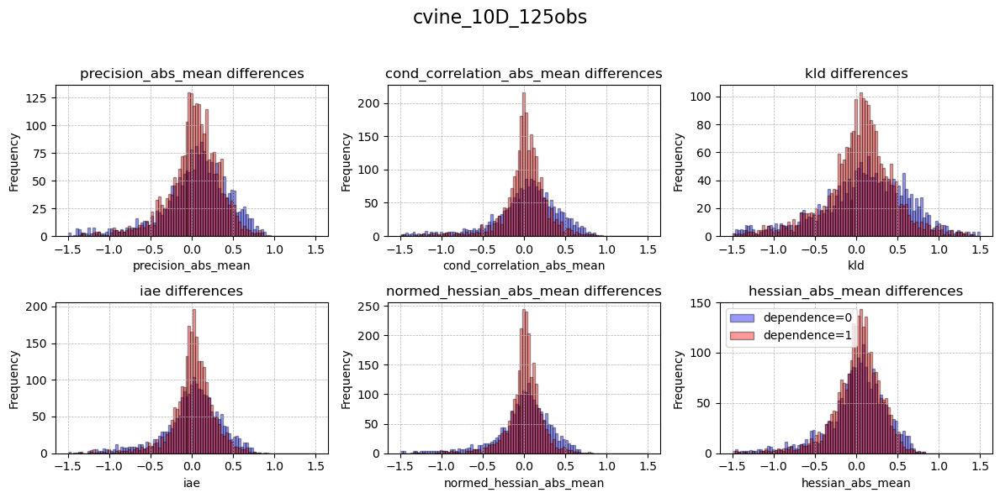

In [408]:
experiment_name="cvine_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

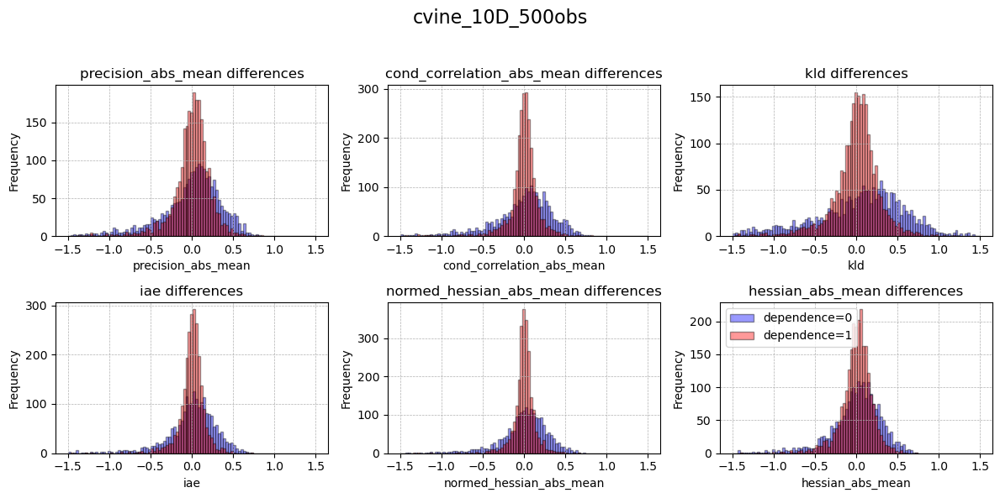

In [409]:
experiment_name="cvine_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

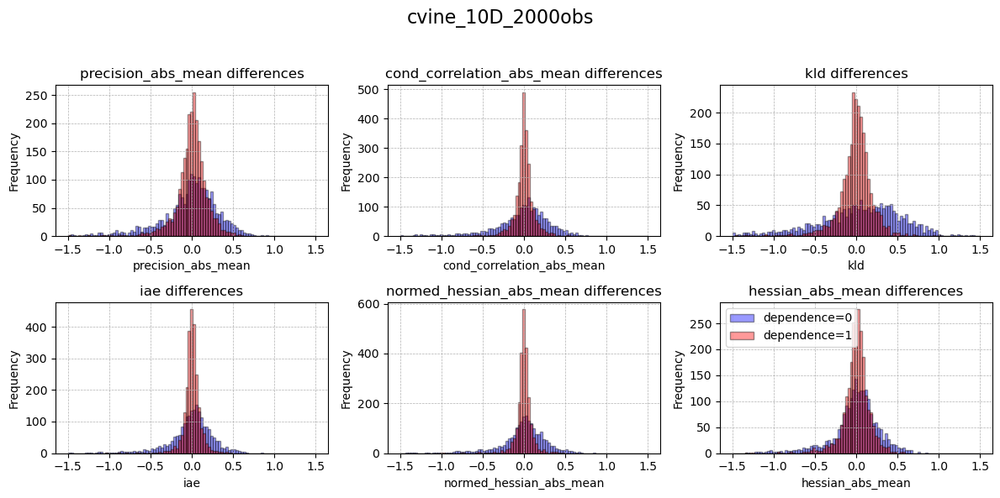

In [16]:
experiment_name="cvine_10D_2000obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

#### Strong

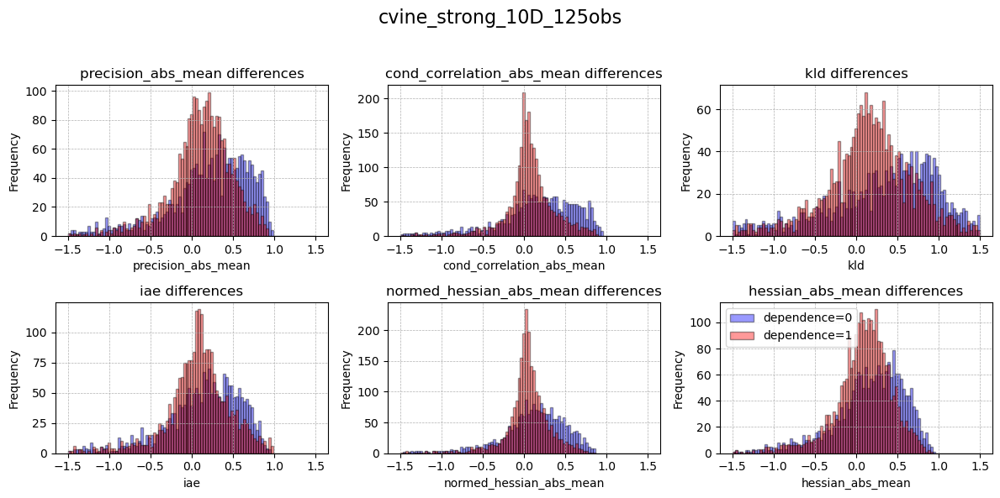

In [410]:
experiment_name="cvine_strong_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

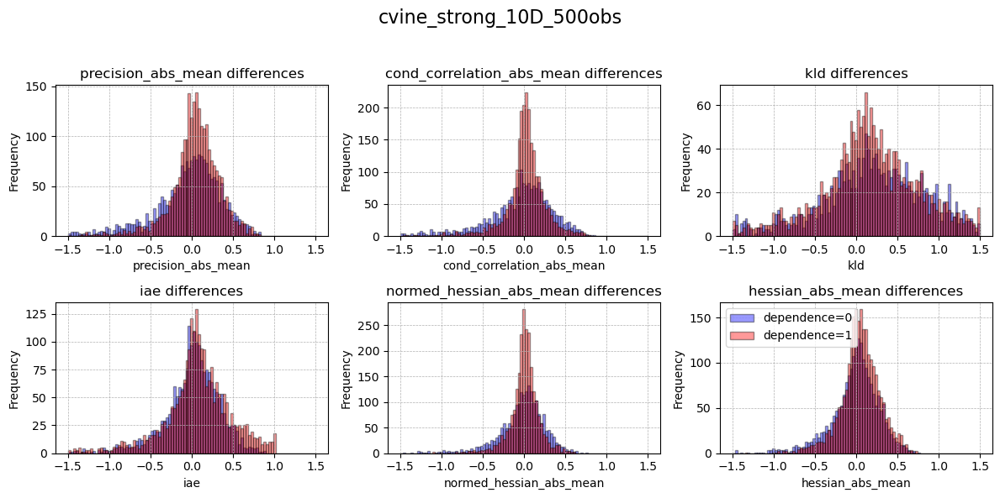

In [411]:
experiment_name="cvine_strong_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

### D-Vine

#### Normal

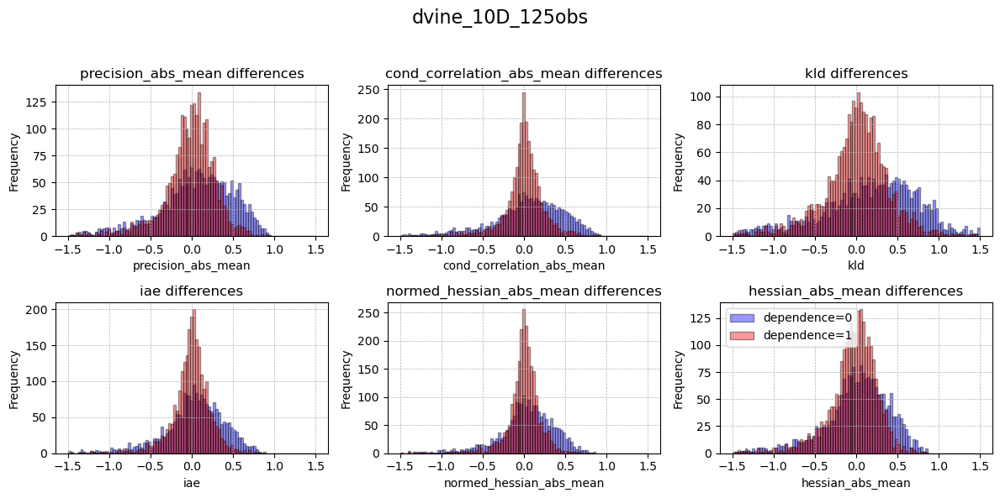

In [412]:
experiment_name="dvine_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

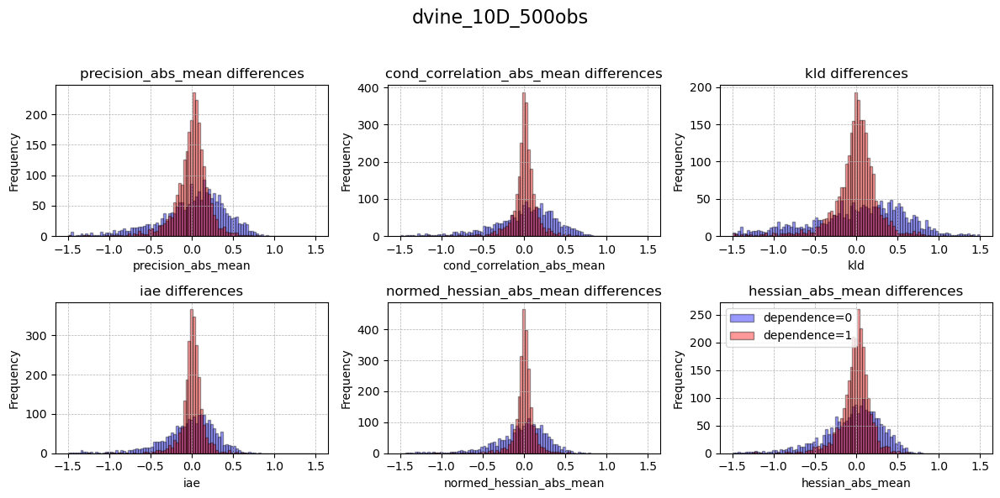

In [413]:
experiment_name="dvine_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

#### Strong

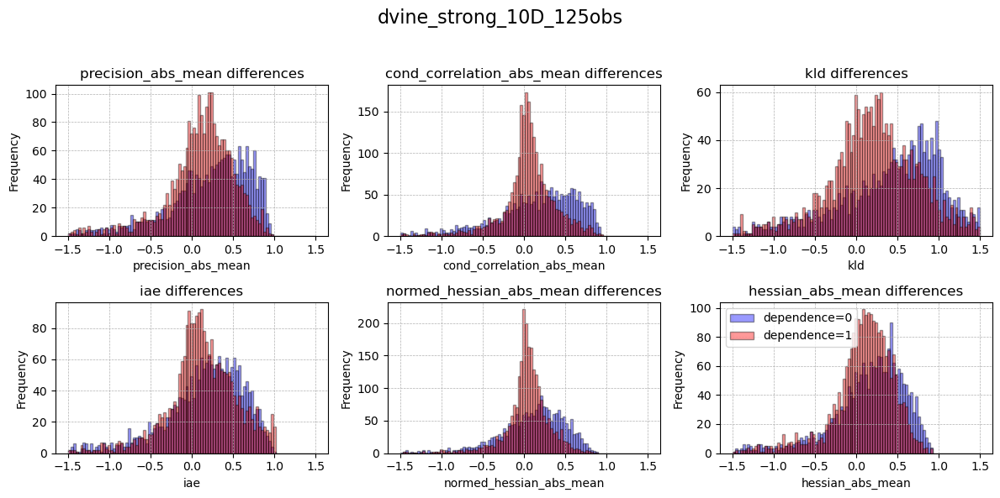

In [414]:
experiment_name="dvine_strong_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

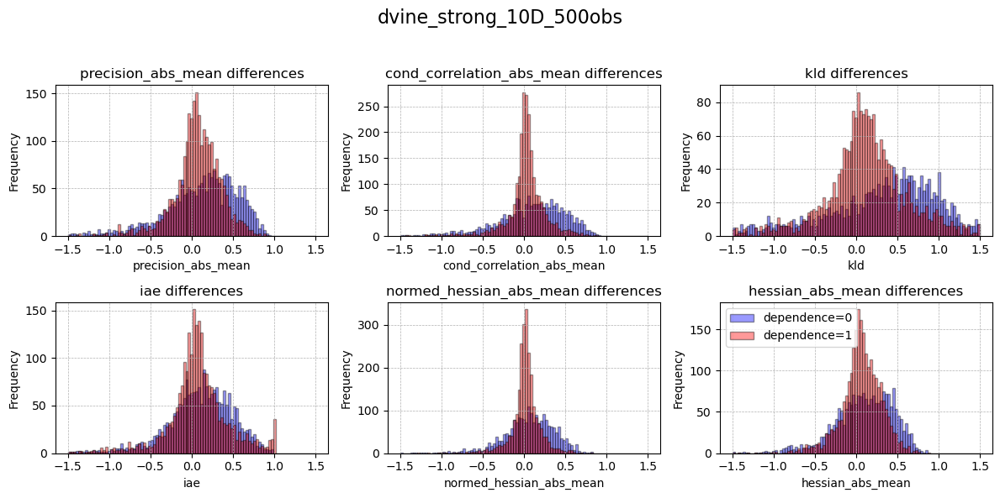

In [415]:
experiment_name="dvine_strong_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

### R-Vine

#### Normal

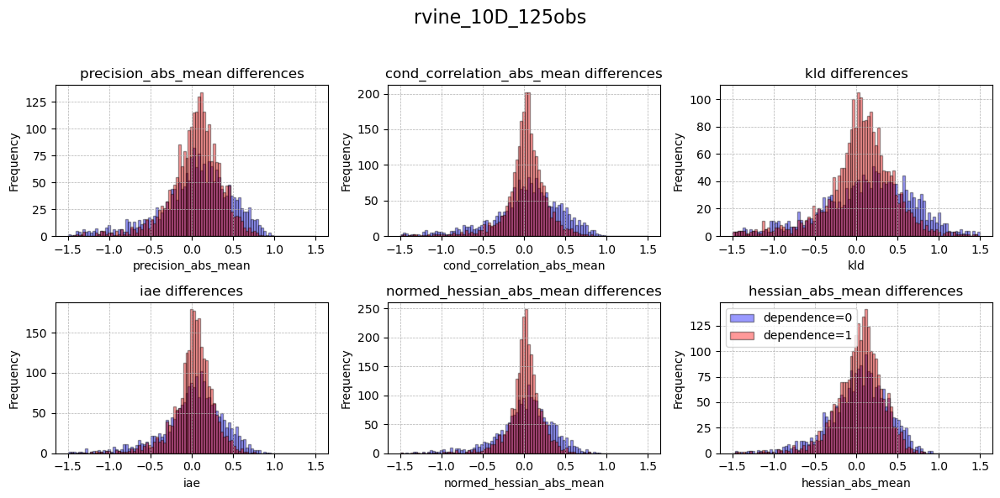

In [416]:
experiment_name="rvine_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

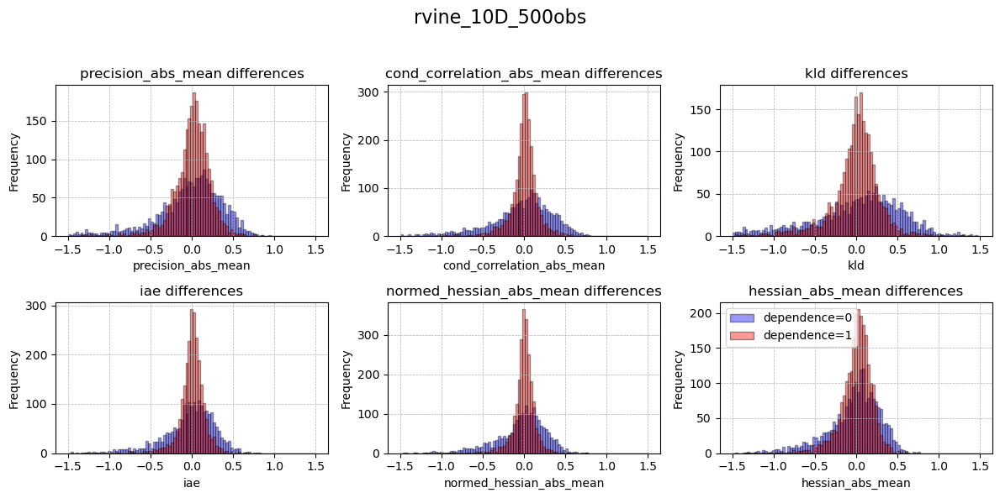

In [417]:
experiment_name="rvine_10D_500obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

#### Strong

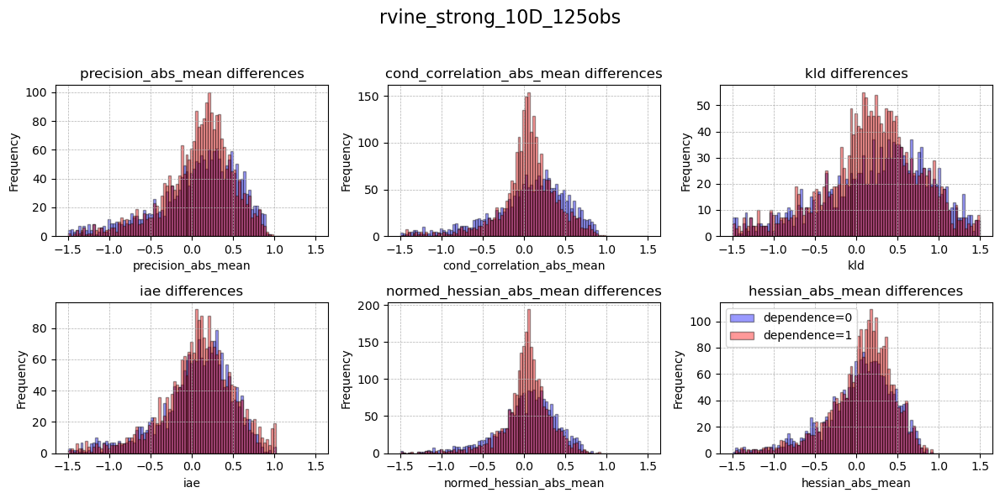

In [418]:
experiment_name="rvine_strong_10D_125obs"


differences_dict_0 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=0)

differences_dict_1 = get_metric_differences_experiment(experiment_name=experiment_name, 
                          name_ending_group_one="No", 
                          name_ending_group_two="Lasso", 
                          seed_min=0, 
                          seed_max=99,
                          metrics_list=["precision_abs_mean", "cond_correlation_abs_mean", "kld", "iae", "normed_hessian_abs_mean", "hessian_abs_mean" ],
                          dependence=1)

plot_differences_metrics(experiment_name,differences_dict_0,differences_dict_1)

# AUC GGM vs GM

### C-Vine

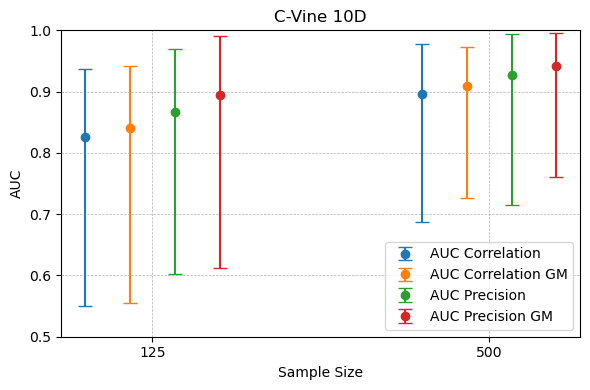

In [76]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_gm_cvine_10D_125obs",
    500  : "ggm_gm_cvine_10D_500obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 10D",
    legend          = True,
)


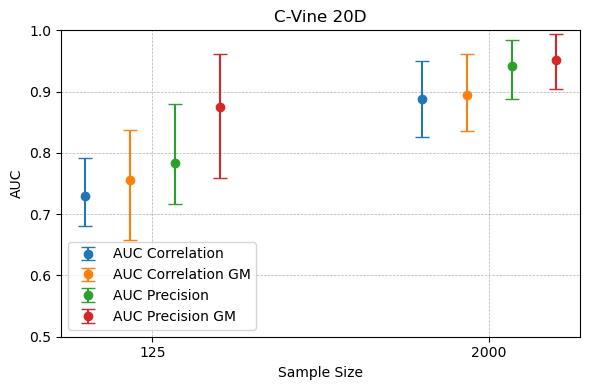

In [80]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125 : "ggm_gm_cvine_20D_125obs",
    2000 : "ggm_gm_cvine_20D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 20D",
    legend          = True,
)


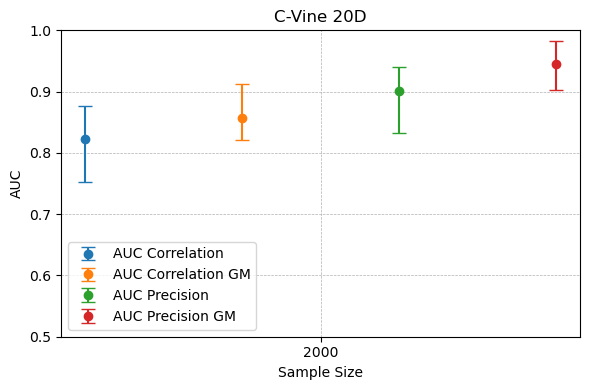

In [79]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    2000 : "ggm_gm_cvine_50D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 20D",
    legend          = True,
)


### D-Vine

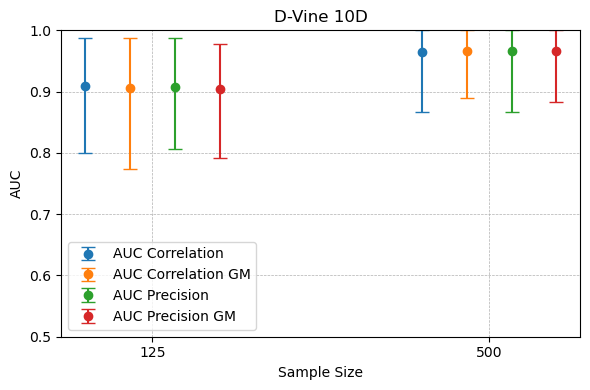

In [81]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_gm_dvine_10D_125obs",
    500  : "ggm_gm_dvine_10D_500obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 10D",
    legend          = True,
)


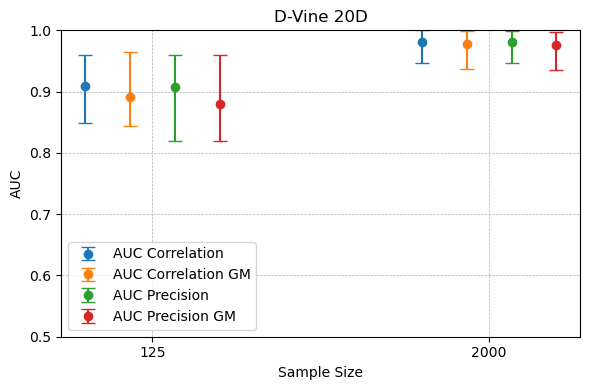

In [83]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125 : "ggm_gm_dvine_20D_125obs",
    2000 : "ggm_gm_dvine_20D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 20D",
    legend          = True,
)


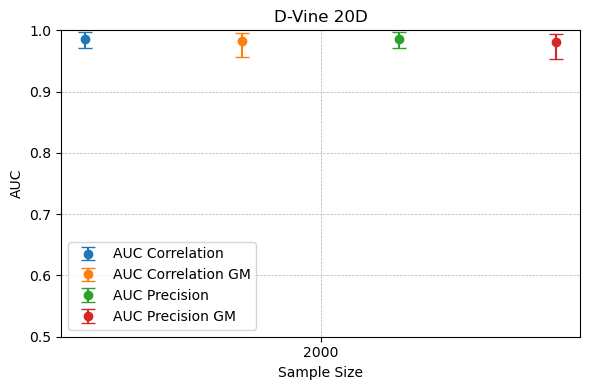

In [85]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    2000 : "ggm_gm_dvine_50D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 20D",
    legend          = True,
)


### R-Vine

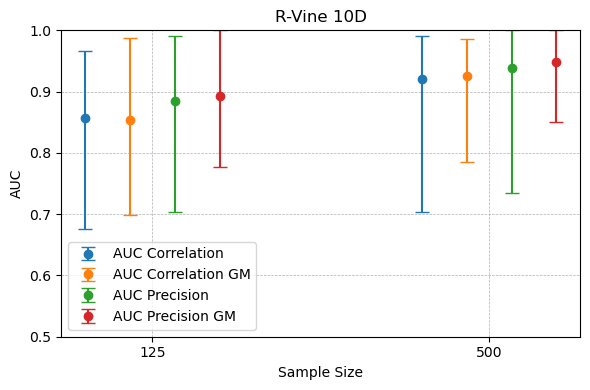

In [75]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_gm_rvine_10D_125obs",
    500  : "ggm_gm_rvine_10D_500obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)


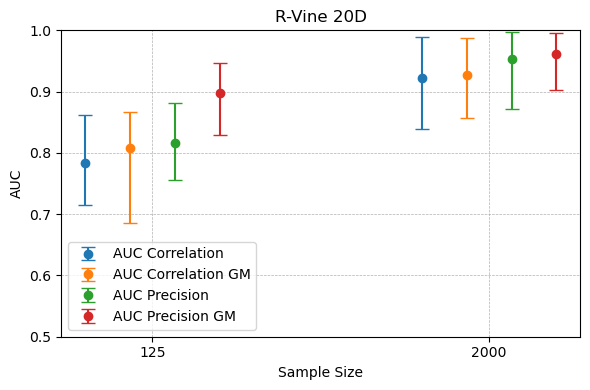

In [74]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125 : "ggm_gm_rvine_20D_125obs",
    2000 : "ggm_gm_rvine_20D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 20D",
    legend          = True,
)


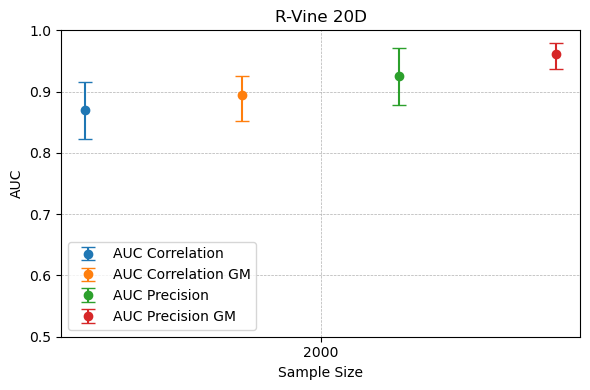

In [73]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    2000 : "ggm_gm_rvine_50D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 20D",
    legend          = True,
)


# F1 and MCC Scores Across Threshholds

### Analysis Functions

In [2]:
import mlflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, matthews_corrcoef
from tqdm import tqdm

def evaluate_experiment_scores_allplots(
    experiment_name,
    metrics=["iae", "hessian_abs_mean"],
    thresholds_dict= {"iae": np.linspace(0, 0.1, 51),
                      "hessian_abs_mean": np.linspace(0, 0.5, 51)},  # {"iae": array, "hessian_abs_mean": array}, or use default grid
    seed_col="tags.seed_value",
    runname_col="tags.mlflow.runName",
    artifact_name="conditional_independence_table_model_samples.csv",
    conf_percentiles=(5, 95),
    differences_plot=False
):
    methods = ["no", "lasso", "adaptive"]
    all_method_colors = {'no': '#1f77b4', 'lasso': '#ff7f0e', 'adaptive': '#2ca02c'} #default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

    # MLflow experiment/runs loading
    client = mlflow.tracking.MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found!")
    runs_df = mlflow.search_runs([experiment.experiment_id])
    runs_df[seed_col] = runs_df[seed_col].astype(int)
    seed_min = runs_df[seed_col].min()
    seed_max = runs_df[seed_col].max()
    seeds_all = np.arange(seed_min, seed_max + 1)

    # Use thresholds_dict or default
    if thresholds_dict is None:
        # Default: same threshold grid for both
        thresholds_dict = {metric: np.linspace(-2, 2, 101) for metric in metrics}

    # This will hold arrays for all methods/metrics/scores
    plot_arrays = {
        metric: {
            "f1": {method: [] for method in methods},
            "mcc": {method: [] for method in methods}
        }
        for metric in metrics
    }

    summary_df_rows = []

    # Score functions again
    score_funcs = {
        "f1": lambda y, p: f1_score(y, p, zero_division=0),
        "mcc": lambda y, p: matthews_corrcoef(y, p)
    }

    for seed in tqdm(seeds_all, desc="Processing seeds"):
        summary_row = {'seed': seed}
        for metric in metrics:
            thresholds = thresholds_dict[metric]
            metric_data = {}
            y_data = {}
            for method in methods:
                mask = runs_df[runname_col].str.contains(method, case=False, na=False) & (runs_df[seed_col] == seed)
                if mask.sum() == 0:
                    continue
                this_run = runs_df[mask].iloc[0]
                artifact_uri = this_run["artifact_uri"][7:]
                file_path = artifact_uri + f"/{artifact_name}"
                df = pd.read_csv(file_path)
                y_true = df["dependence"].values
                vals = df[metric].values
                metric_data[method] = vals
                y_data[method] = y_true

            for method in methods:
                vals = metric_data.get(method)
                y_true = y_data.get(method)
                if vals is None or y_true is None:
                    summary_row[f"f1_{metric}_{method}"] = np.nan
                    summary_row[f"mcc_{metric}_{method}"] = np.nan
                    plot_arrays[metric]["f1"][method].append([np.nan] * len(thresholds))
                    plot_arrays[metric]["mcc"][method].append([np.nan] * len(thresholds))
                    continue

                f1s = []
                mccs = []
                for t in thresholds:
                    pred = (vals >= t).astype(int)
                    try:
                        f1s.append(score_funcs["f1"](y_true, pred))
                        mccs.append(score_funcs["mcc"](y_true, pred))
                    except Exception:
                        f1s.append(np.nan)
                        mccs.append(np.nan)
                plot_arrays[metric]["f1"][method].append(f1s)
                plot_arrays[metric]["mcc"][method].append(mccs)
                # Save best for summary
                summary_row[f"f1_{metric}_{method}"] = np.nanmax(f1s)
                summary_row[f"mcc_{metric}_{method}"] = np.nanmax(mccs)
        summary_df_rows.append(summary_row)

    summary_df = pd.DataFrame(summary_df_rows)

    if differences_plot==True:
        # Make the 2x2 grid plot: plot (Lasso - No) and (Adaptive - No), with uncertainty
        fig, axs = plt.subplots(len(metrics), 2, figsize=(14, 9), sharex=False, sharey=False)
        for i, metric in enumerate(metrics):
            thresholds = thresholds_dict[metric]
            for j, score_type in enumerate(["mcc", "f1"]):
                ax = axs[i, j]
                arr_no = np.array(plot_arrays[metric][score_type]["no"])
                arr_lasso = np.array(plot_arrays[metric][score_type]["lasso"])
                arr_adaptive = np.array(plot_arrays[metric][score_type]["adaptive"])
                # Make sure shape: (n_seeds, n_thresholds)
                # Plot Lasso - No
                if arr_lasso.size > 0 and arr_no.size > 0:
                    diff_lasso = arr_lasso - arr_no
                    means_lasso = np.nanmean(diff_lasso, axis=0)
                    lower_lasso = np.nanpercentile(diff_lasso, conf_percentiles[0], axis=0)
                    upper_lasso = np.nanpercentile(diff_lasso, conf_percentiles[1], axis=0)
                    diff_lasso_pos = (diff_lasso>=0).mean(0)
                    ax.plot(thresholds, means_lasso, color='#ff7f0e', label="Lasso - No")
                    ax.fill_between(thresholds, lower_lasso, upper_lasso, color='#ff7f0e', alpha=0.15)
                    ax.plot(thresholds, diff_lasso_pos, color='#ff7f0e', linestyle="dashed")
                # Plot Adaptive - No
                if arr_adaptive.size > 0 and arr_no.size > 0:
                    diff_adaptive = arr_adaptive - arr_no
                    means_adaptive = np.nanmean(diff_adaptive, axis=0)
                    lower_adaptive = np.nanpercentile(diff_adaptive, conf_percentiles[0], axis=0)
                    upper_adaptive = np.nanpercentile(diff_adaptive, conf_percentiles[1], axis=0)
                    diff_adaptive_pos = (diff_adaptive>=0).mean(0)
                    ax.plot(thresholds, means_adaptive, color='#2ca02c', label="Adaptive - No")
                    ax.fill_between(thresholds, lower_adaptive, upper_adaptive, color='#2ca02c', alpha=0.15)
                    ax.plot(thresholds, diff_adaptive_pos, color='#2ca02c', linestyle="dashed")
                ax.axhline(0, color='gray', linestyle='-', linewidth=1)
                ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
                ax.set_xlabel(f"{metric} threshold")
                ax.set_ylabel(f"{score_type.upper()} score difference")
                ax.set_title(f"Δ {score_type.upper()}: {metric}")
                ax.legend()
                ax.grid(True, linestyle='--', linewidth=0.5)
                axs[i, 0].set_ylim(-0.3, 1)
                axs[i, 1].set_ylim(-0.3, 1)
        #axs[1, 0].set_ylim(-0.3, 1)
        #axs[1, 1].set_ylim(-0.3, 1)
        plt.suptitle(f"Experiment: {experiment_name} (Lasso/Adaptive - No Difference for {metrics})")
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()
    else:
        # Make the 2x2 grid plot
        fig, axs = plt.subplots(len(metrics), 2, figsize=(14, 9), sharex=False, sharey=False)
        for i, metric in enumerate(metrics):
            thresholds = thresholds_dict[metric]
            for j, score_type in enumerate(["mcc", "f1"]):
                ax = axs[i, j]
                for method in methods:
                    arr = np.array(plot_arrays[metric][score_type][method])
                    if len(arr) == 0: continue
                    means = np.nanmean(arr, axis=0)
                    lower = np.nanpercentile(arr, conf_percentiles[0], axis=0)
                    upper = np.nanpercentile(arr, conf_percentiles[1], axis=0)
                    ax.plot(thresholds, means, color=all_method_colors[method], label=method.capitalize())
                    ax.fill_between(thresholds, lower, upper, color=all_method_colors[method], alpha=0.15)
                ax.set_xlabel(f"{metric} threshold")
                ax.set_ylabel(f"{score_type.upper()} score")
                ax.set_title(f"{score_type.upper()} score: {metric}")
                ax.legend()
                ax.grid(True, linestyle='--', linewidth=0.5)
                axs[i, 0].set_ylim(-0.3, 1)
                axs[i, 1].set_ylim(-0.3, 1)
        #axs[1, 0].set_ylim(-0.3, 1)
        #axs[1, 1].set_ylim(-0.3, 1)
        plt.suptitle(f"Experiment: {experiment_name} (Lasso/Adaptive - No Difference for {metrics})")
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # Print comparison statistics
    for metric in metrics:
        f_adaptive = summary_df[f"f1_{metric}_adaptive"]
        f_no = summary_df[f"f1_{metric}_no"]
        m_adaptive = summary_df[f"mcc_{metric}_adaptive"]
        m_no = summary_df[f"mcc_{metric}_no"]
        # Remove NAs before computing
        valid_f_mask = ~f_adaptive.isna() & ~f_no.isna()
        valid_m_mask = ~m_adaptive.isna() & ~m_no.isna()
        pct_f = np.mean((f_adaptive[valid_f_mask] - f_no[valid_f_mask]) > 0) * 100
        pct_m = np.mean((m_adaptive[valid_m_mask] - m_no[valid_m_mask]) > 0) * 100
        mean_f_diff = np.mean((f_adaptive[valid_f_mask] - f_no[valid_f_mask]))
        mean_m_diff = np.mean((m_adaptive[valid_m_mask] - m_no[valid_m_mask]))
        print(f"Metric: {metric}")
        print(f"  F1: Adaptive better than No {pct_f:.1f}% of seeds (mean diff: {mean_f_diff:.4f})")
        print(f"  MCC: Adaptive better than No {pct_m:.1f}% of seeds (mean diff: {mean_m_diff:.4f})")
        print("")

    return summary_df

In [10]:
from matplotlib.ticker import MaxNLocator

def evaluate_experiment_scores_allplots(
    experiment_name,
    metrics=["iae", "hessian_abs_mean"],
    thresholds_dict= {"iae": np.linspace(0, 0.1, 51),
                      "hessian_abs_mean": np.linspace(0, 0.5, 51)},
    score_types=["mcc", "f1"],   # NEW: which scores to plot
    seed_col="tags.seed_value",
    runname_col="tags.mlflow.runName",
    artifact_name="conditional_independence_table_model_samples.csv",
    conf_percentiles=(5, 95),
    differences_plot=False,
    title=True,
    legend=True,
    xlabel=None,   # str (applied to all subplots) or dict {metric: latex str}
    max_xticks=None,   # maximum number of x-axis ticks
):
    methods = ["no", "lasso", "adaptive"]
    all_method_colors = {'no': '#1f77b4', 'lasso': '#ff7f0e', 'adaptive': '#2ca02c'}

    def _resolve_xlabel(metric):
        if xlabel is None:
            return f"{metric} threshold"
        if isinstance(xlabel, dict):
            return xlabel.get(metric, f"{metric} threshold")
        return xlabel

    # MLflow experiment/runs loading
    client = mlflow.tracking.MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found!")
    runs_df = mlflow.search_runs([experiment.experiment_id])
    runs_df[seed_col] = runs_df[seed_col].astype(int)
    seed_min = runs_df[seed_col].min()
    seed_max = runs_df[seed_col].max()
    seeds_all = np.arange(seed_min, seed_max + 1)
    
    
    ############################################################################
    runs_df = mlflow.search_runs([experiment.experiment_id])

    # Ensure seed column is of integer type
    runs_df[seed_col] = runs_df[seed_col].astype(int)

    # Filter for finished runs only
    finished_runs_df = runs_df[runs_df["status"] == "FINISHED"]

    # Count number of finished runs per seed
    seed_counts = finished_runs_df[seed_col].value_counts()

    # Keep only seeds with at least 2 finished runs
    seeds_all = seed_counts[seed_counts >= 2].index.values

    # (Optional) convert to numpy array explicitly
    seeds_all = np.array(seeds_all)
    ############################################################################

    if thresholds_dict is None:
        thresholds_dict = {metric: np.linspace(-2, 2, 101) for metric in metrics}

    plot_arrays = {
        metric: {
            "f1": {method: [] for method in methods},
            "mcc": {method: [] for method in methods}
        }
        for metric in metrics
    }

    summary_df_rows = []

    score_funcs = {
        "f1": lambda y, p: f1_score(y, p, zero_division=0),
        "mcc": lambda y, p: matthews_corrcoef(y, p)
    }

    for seed in tqdm(seeds_all, desc="Processing seeds"):
        summary_row = {'seed': seed}
        for metric in metrics:
            thresholds = thresholds_dict[metric]
            metric_data = {}
            y_data = {}
            for method in methods:
                mask = runs_df[runname_col].str.contains(method, case=False, na=False) & (runs_df[seed_col] == seed)
                if mask.sum() == 0:
                    continue
                this_run = runs_df[mask].iloc[0]
                artifact_uri = this_run["artifact_uri"][7:]
                file_path = artifact_uri + f"/{artifact_name}"
                df = pd.read_csv(file_path)
                y_true = df["dependence"].values
                vals = df[metric].values
                metric_data[method] = vals
                y_data[method] = y_true

            for method in methods:
                vals = metric_data.get(method)
                y_true = y_data.get(method)
                if vals is None or y_true is None:
                    summary_row[f"f1_{metric}_{method}"] = np.nan
                    summary_row[f"mcc_{metric}_{method}"] = np.nan
                    plot_arrays[metric]["f1"][method].append([np.nan] * len(thresholds))
                    plot_arrays[metric]["mcc"][method].append([np.nan] * len(thresholds))
                    continue

                f1s = []
                mccs = []
                for t in thresholds:
                    pred = (vals >= t).astype(int)
                    try:
                        f1s.append(score_funcs["f1"](y_true, pred))
                        mccs.append(score_funcs["mcc"](y_true, pred))
                    except Exception:
                        f1s.append(np.nan)
                        mccs.append(np.nan)
                plot_arrays[metric]["f1"][method].append(f1s)
                plot_arrays[metric]["mcc"][method].append(mccs)
                summary_row[f"f1_{metric}_{method}"] = np.nanmax(f1s)
                summary_row[f"mcc_{metric}_{method}"] = np.nanmax(mccs)
        summary_df_rows.append(summary_row)

    summary_df = pd.DataFrame(summary_df_rows)

    nrows = len(metrics)
    ncols = len(score_types)
    # Choose tight grid vs. single axis as needed
    if nrows == 1 and ncols == 1:
        figsize = (5, 4)
        fig, axs = plt.subplots(1, 1, figsize=figsize)
        axs = np.array([[axs]])  # for consistent indexing
    elif nrows == 1:
        figsize = (6 * ncols, 4)
        fig, axs = plt.subplots(1, ncols, figsize=figsize)
        axs = np.expand_dims(np.atleast_1d(axs), axis=0)
    elif ncols == 1:
        figsize = (5, 4 * nrows)
        fig, axs = plt.subplots(nrows, 1, figsize=figsize)
        axs = np.atleast_2d(axs).T
    else:
        figsize = (7 * ncols, 4 * nrows)
        fig, axs = plt.subplots(nrows, ncols, figsize=figsize)
    if differences_plot:
        for i, metric in enumerate(metrics):
            thresholds = thresholds_dict[metric]
            for j, score_type in enumerate(score_types):
                ax = axs[i, j] if axs.ndim==2 else axs[max(i,j)]
                arr_no = np.array(plot_arrays[metric][score_type]["no"])
                arr_lasso = np.array(plot_arrays[metric][score_type]["lasso"])
                arr_adaptive = np.array(plot_arrays[metric][score_type]["adaptive"])
                if arr_lasso.size > 0 and arr_no.size > 0:
                    diff_lasso = arr_lasso - arr_no
                    means_lasso = np.nanmean(diff_lasso, axis=0)
                    lower_lasso = np.nanpercentile(diff_lasso, conf_percentiles[0], axis=0)
                    upper_lasso = np.nanpercentile(diff_lasso, conf_percentiles[1], axis=0)
                    diff_lasso_pos = (diff_lasso>=0).mean(0)
                    ax.plot(thresholds, means_lasso, color='#ff7f0e', label="$\Delta$ Lasso")
                    ax.fill_between(thresholds, lower_lasso, upper_lasso, color='#ff7f0e', alpha=0.15)
                    ax.plot(thresholds, diff_lasso_pos, color='#ff7f0e', linestyle="dashed")
                if arr_adaptive.size > 0 and arr_no.size > 0:
                    diff_adaptive = arr_adaptive - arr_no
                    means_adaptive = np.nanmean(diff_adaptive, axis=0)
                    lower_adaptive = np.nanpercentile(diff_adaptive, conf_percentiles[0], axis=0)
                    upper_adaptive = np.nanpercentile(diff_adaptive, conf_percentiles[1], axis=0)
                    diff_adaptive_pos = (diff_adaptive>=0).mean(0)
                    ax.plot(thresholds, means_adaptive, color='#2ca02c', label="$\Delta$ Adaptive")
                    ax.fill_between(thresholds, lower_adaptive, upper_adaptive, color='#2ca02c', alpha=0.15)
                    ax.plot(thresholds, diff_adaptive_pos, color='#2ca02c', linestyle="dashed")
                ax.axhline(0, color='gray', linestyle='-', linewidth=1)
                ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
                ax.set_xlabel(_resolve_xlabel(metric), fontsize=20)
                ax.set_ylabel(r"$\Delta$ MCC, MCC$>0$", fontsize=20)
                if max_xticks is not None:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=max_xticks))
                if title == True:
                    ax.set_title(f"Δ {score_type.upper()}: {metric}")
                if legend == True:    
                    ax.legend()
                ax.grid(True, linestyle='--', linewidth=0.5)
                ax.set_ylim(-0.3, 1)
        if title == True:
            plt.suptitle(f"Experiment: {experiment_name} (Lasso/Adaptive - No Difference)")
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        #plt.show()
    else:
        for i, metric in enumerate(metrics):
            thresholds = thresholds_dict[metric]
            for j, score_type in enumerate(score_types):
                ax = axs[i, j] if axs.ndim==2 else axs[max(i,j)]
                for method in methods:
                    arr = np.array(plot_arrays[metric][score_type][method])
                    if arr.size == 0: continue
                    means = np.nanmean(arr, axis=0)
                    lower = np.nanpercentile(arr, conf_percentiles[0], axis=0)
                    upper = np.nanpercentile(arr, conf_percentiles[1], axis=0)
                    ax.plot(thresholds, means, color=all_method_colors[method], label=method.capitalize())
                    ax.fill_between(thresholds, lower, upper, color=all_method_colors[method], alpha=0.15)
                ax.set_xlabel(_resolve_xlabel(metric), fontsize=20)
                ax.set_ylabel(f"{score_type.upper()} score", fontsize=20)
                if max_xticks is not None:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=max_xticks))
                if title == True:
                    ax.set_title(f"{score_type.upper()} score: {metric}")
                if legend == True:    
                    ax.legend()
                ax.grid(True, linestyle='--', linewidth=0.5)
                ax.set_ylim(-0.3, 1)
        if title == True:
            plt.suptitle(f"Experiment: {experiment_name} (Lasso/Adaptive/No)")
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        #plt.show()

    # Print comparison statistics (as before)
    for metric in metrics:
        f_adaptive = summary_df.get(f"f1_{metric}_adaptive", pd.Series([np.nan]*len(summary_df)))
        f_no = summary_df.get(f"f1_{metric}_no", pd.Series([np.nan]*len(summary_df)))
        m_adaptive = summary_df.get(f"mcc_{metric}_adaptive", pd.Series([np.nan]*len(summary_df)))
        m_no = summary_df.get(f"mcc_{metric}_no", pd.Series([np.nan]*len(summary_df)))
        valid_f_mask = ~f_adaptive.isna() & ~f_no.isna()
        valid_m_mask = ~m_adaptive.isna() & ~m_no.isna()
        pct_f = np.mean((f_adaptive[valid_f_mask] - f_no[valid_f_mask]) > 0) * 100
        pct_m = np.mean((m_adaptive[valid_m_mask] - m_no[valid_m_mask]) > 0) * 100
        mean_f_diff = np.mean((f_adaptive[valid_f_mask] - f_no[valid_f_mask]))
        mean_m_diff = np.mean((m_adaptive[valid_m_mask] - m_no[valid_m_mask]))
        print(f"Metric: {metric}")
        print(f"  F1: Adaptive better than No {pct_f:.1f}% of seeds (mean diff: {mean_f_diff:.4f})")
        print(f"  MCC: Adaptive better than No {pct_m:.1f}% of seeds (mean diff: {mean_m_diff:.4f})")
        print("")
    return summary_df, fig

### R-Vine

#### Normal

Processing seeds: 100%|██████████| 100/100 [00:19<00:00,  5.07it/s]


Metric: iae
  F1: Adaptive better than No 62.0% of seeds (mean diff: 0.0150)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0340)

Metric: hessian_abs_mean
  F1: Adaptive better than No 51.0% of seeds (mean diff: 0.0069)
  MCC: Adaptive better than No 56.0% of seeds (mean diff: 0.0173)



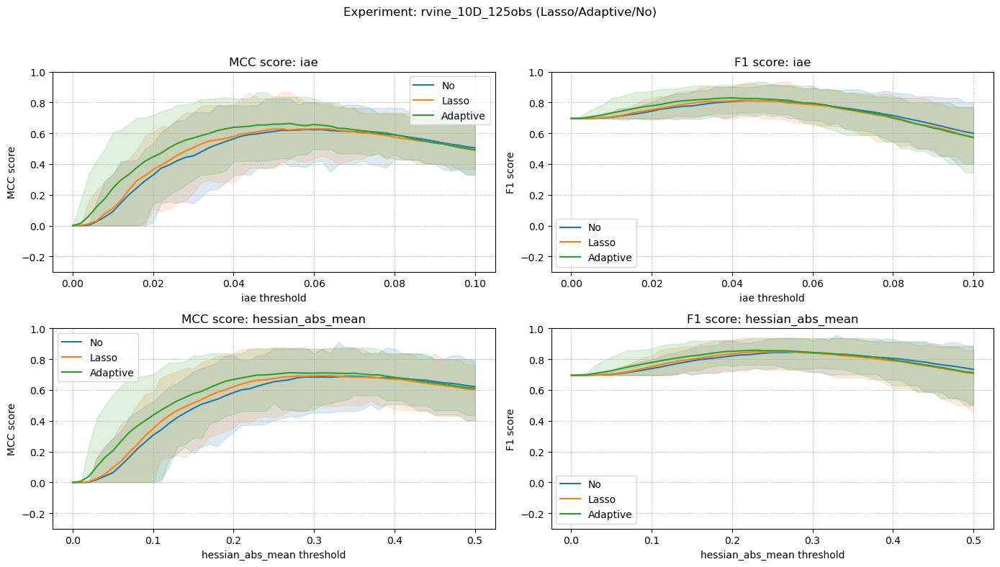

In [16]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

summary_df = evaluate_experiment_scores_allplots("rvine_10D_125obs", differences_plot=False)

Processing seeds: 100%|██████████| 100/100 [00:31<00:00,  3.20it/s]


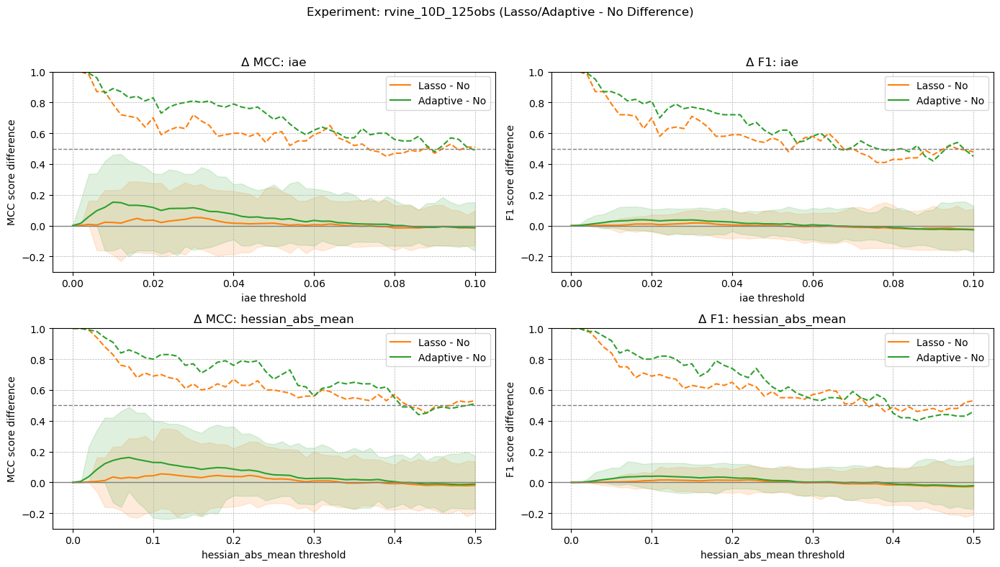

Metric: iae
  F1: Adaptive better than No 62.0% of seeds (mean diff: 0.0150)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0340)

Metric: hessian_abs_mean
  F1: Adaptive better than No 51.0% of seeds (mean diff: 0.0069)
  MCC: Adaptive better than No 56.0% of seeds (mean diff: 0.0173)



In [34]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

summary_df = evaluate_experiment_scores_allplots("rvine_10D_125obs", differences_plot=True, conf_percentiles=(5, 95))

Processing seeds: 100%|██████████| 100/100 [00:14<00:00,  7.03it/s]


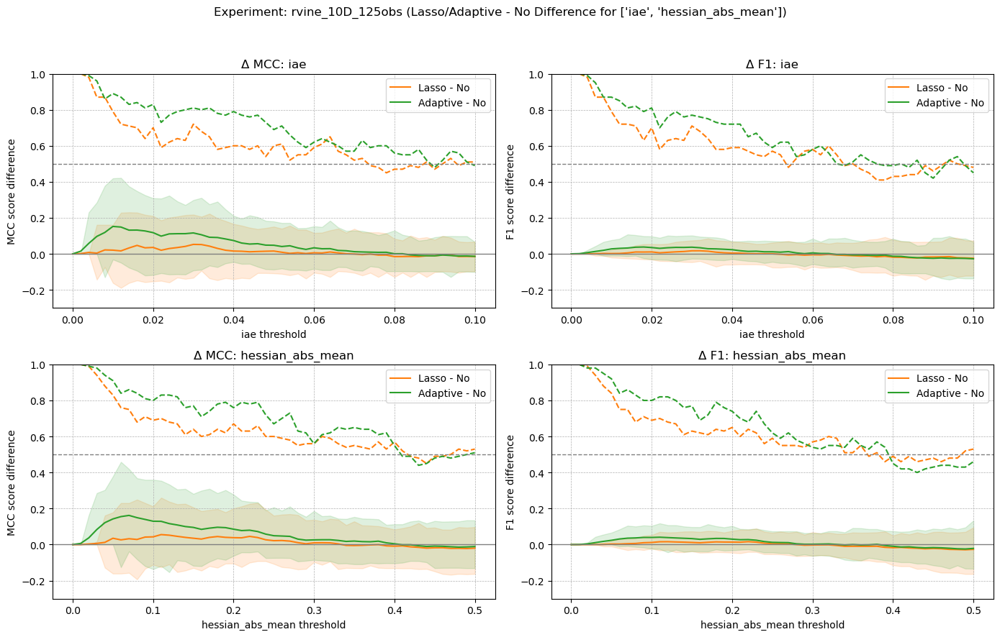

Metric: iae
  F1: Adaptive better than No 62.0% of seeds (mean diff: 0.0150)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0340)

Metric: hessian_abs_mean
  F1: Adaptive better than No 51.0% of seeds (mean diff: 0.0069)
  MCC: Adaptive better than No 56.0% of seeds (mean diff: 0.0173)



In [14]:
summary_df = evaluate_experiment_scores_allplots("rvine_10D_125obs", differences_plot=True, conf_percentiles=(10, 90))

In [ ]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


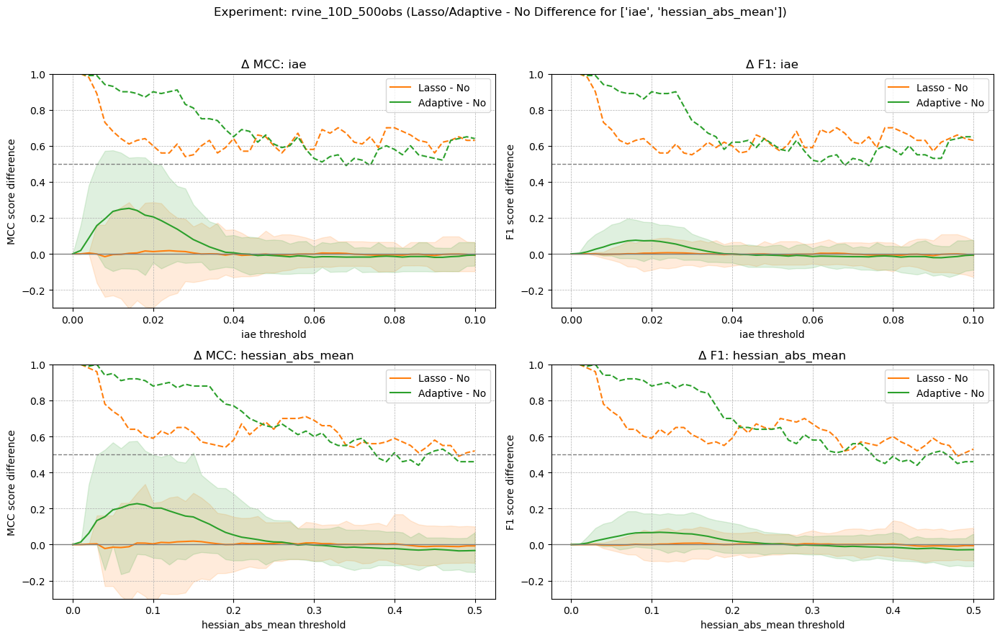

Metric: iae
  F1: Adaptive better than No 50.0% of seeds (mean diff: 0.0063)
  MCC: Adaptive better than No 48.0% of seeds (mean diff: 0.0123)

Metric: hessian_abs_mean
  F1: Adaptive better than No 38.0% of seeds (mean diff: 0.0038)
  MCC: Adaptive better than No 34.0% of seeds (mean diff: 0.0079)



In [112]:
summary_df = evaluate_experiment_scores_allplots("rvine_10D_500obs", differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.39it/s]


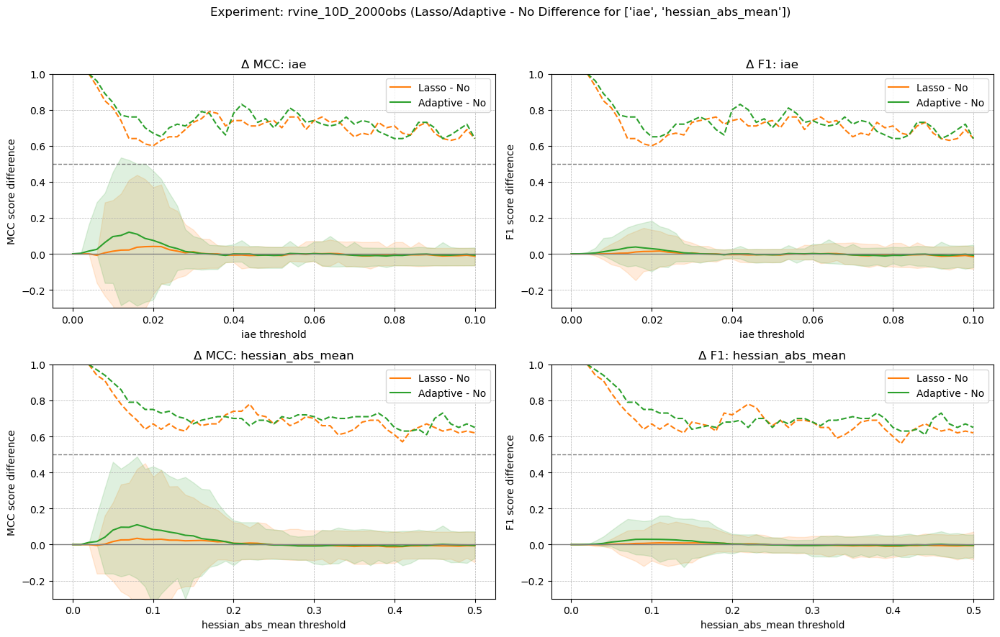

Metric: iae
  F1: Adaptive better than No 28.0% of seeds (mean diff: 0.0028)
  MCC: Adaptive better than No 23.0% of seeds (mean diff: 0.0055)

Metric: hessian_abs_mean
  F1: Adaptive better than No 23.0% of seeds (mean diff: 0.0003)
  MCC: Adaptive better than No 15.0% of seeds (mean diff: 0.0004)



In [113]:
summary_df = evaluate_experiment_scores_allplots("rvine_10D_2000obs", differences_plot=True)

#### Strong

Processing seeds: 100%|██████████| 100/100 [00:30<00:00,  3.31it/s]


Metric: iae
  F1: Adaptive better than No 55.0% of seeds (mean diff: 0.0084)
  MCC: Adaptive better than No 61.0% of seeds (mean diff: 0.0266)

Metric: hessian_abs_mean
  F1: Adaptive better than No 48.0% of seeds (mean diff: 0.0060)
  MCC: Adaptive better than No 56.0% of seeds (mean diff: 0.0199)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 60.0% of seeds (mean diff: 0.0139)
  MCC: Adaptive better than No 66.0% of seeds (mean diff: 0.0353)



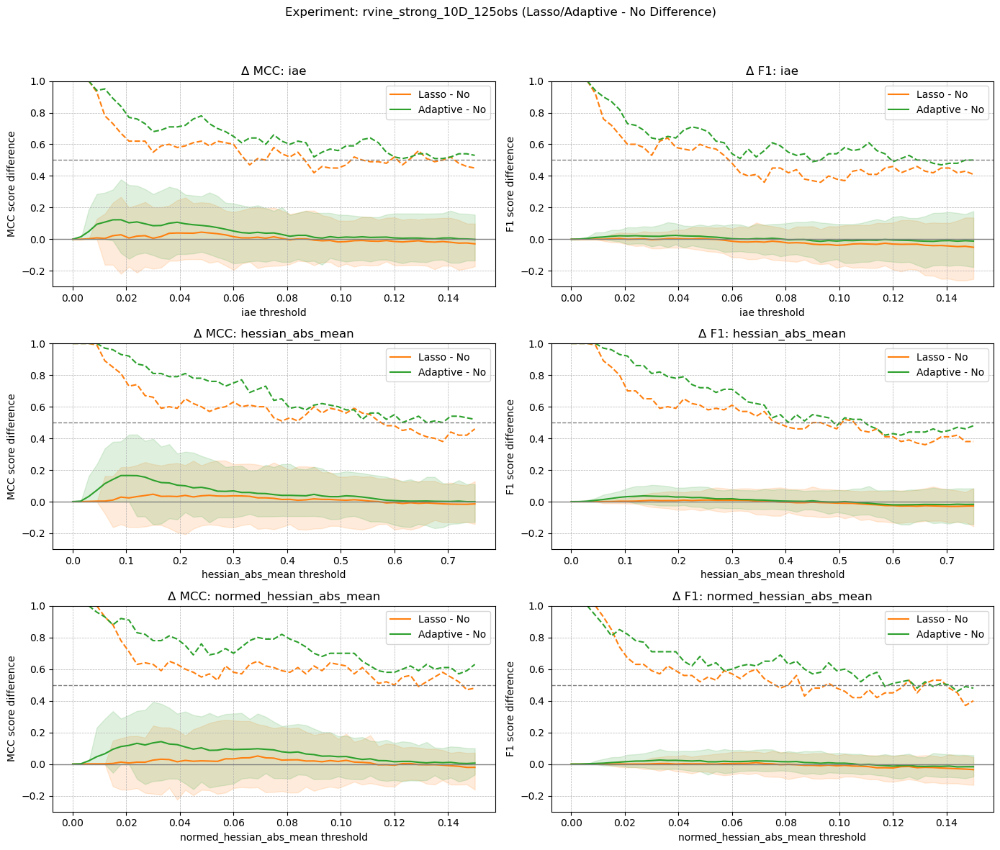

In [22]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.75, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.15, 51)}, differences_plot=True,
                                                 conf_percentiles=(10, 90))

Processing seeds: 100%|██████████| 100/100 [00:44<00:00,  2.24it/s]


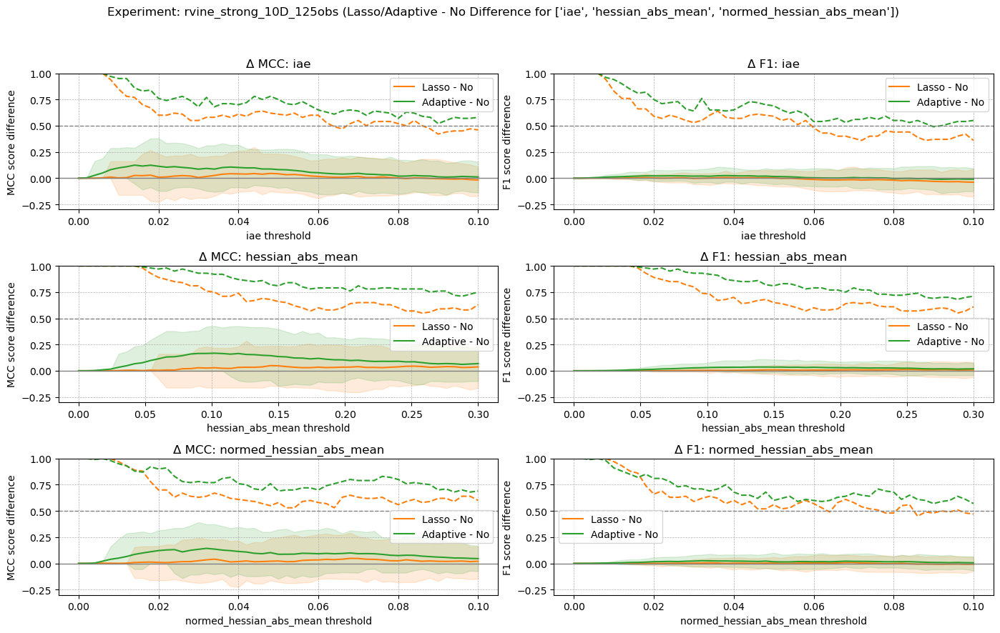

Metric: iae
  F1: Adaptive better than No 58.0% of seeds (mean diff: 0.0114)
  MCC: Adaptive better than No 59.0% of seeds (mean diff: 0.0306)

Metric: hessian_abs_mean
  F1: Adaptive better than No 67.0% of seeds (mean diff: 0.0229)
  MCC: Adaptive better than No 70.0% of seeds (mean diff: 0.0708)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 60.0% of seeds (mean diff: 0.0152)
  MCC: Adaptive better than No 73.0% of seeds (mean diff: 0.0609)



In [27]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.3, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

Processing seeds: 100%|██████████| 100/100 [00:42<00:00,  2.37it/s]


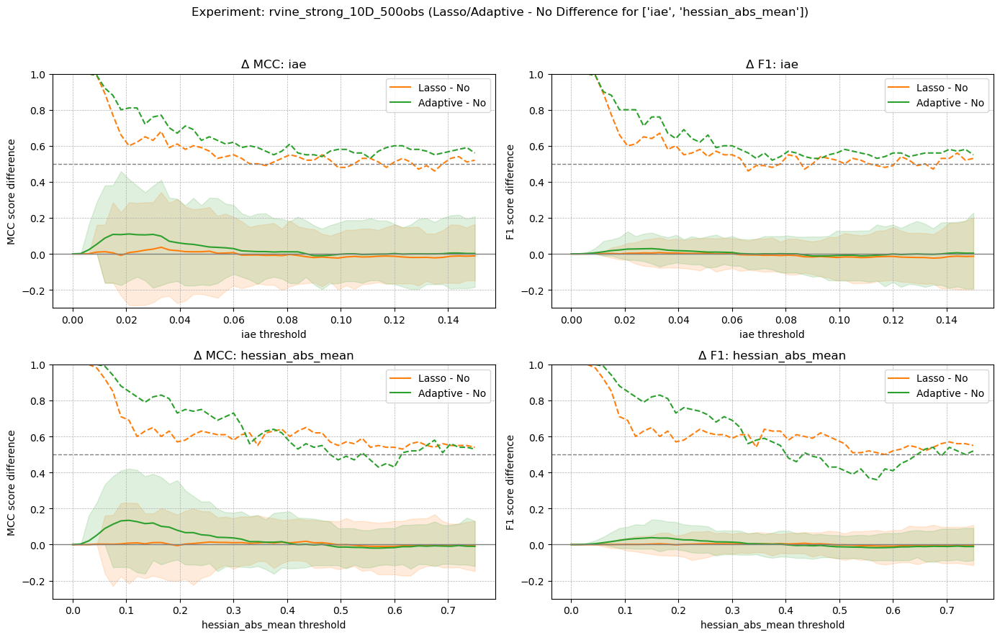

Metric: iae
  F1: Adaptive better than No 52.0% of seeds (mean diff: 0.0027)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0010)

Metric: hessian_abs_mean
  F1: Adaptive better than No 41.0% of seeds (mean diff: -0.0008)
  MCC: Adaptive better than No 43.0% of seeds (mean diff: -0.0014)



In [115]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.75, 51)}, differences_plot=True)

#### Strong PosOnly

Processing seeds: 100%|██████████| 100/100 [00:29<00:00,  3.35it/s]


Metric: iae
  F1: Adaptive better than No 51.0% of seeds (mean diff: 0.0040)
  MCC: Adaptive better than No 54.0% of seeds (mean diff: 0.0126)

Metric: hessian_abs_mean
  F1: Adaptive better than No 53.0% of seeds (mean diff: 0.0070)
  MCC: Adaptive better than No 55.0% of seeds (mean diff: 0.0166)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 63.0% of seeds (mean diff: 0.0128)
  MCC: Adaptive better than No 66.0% of seeds (mean diff: 0.0249)



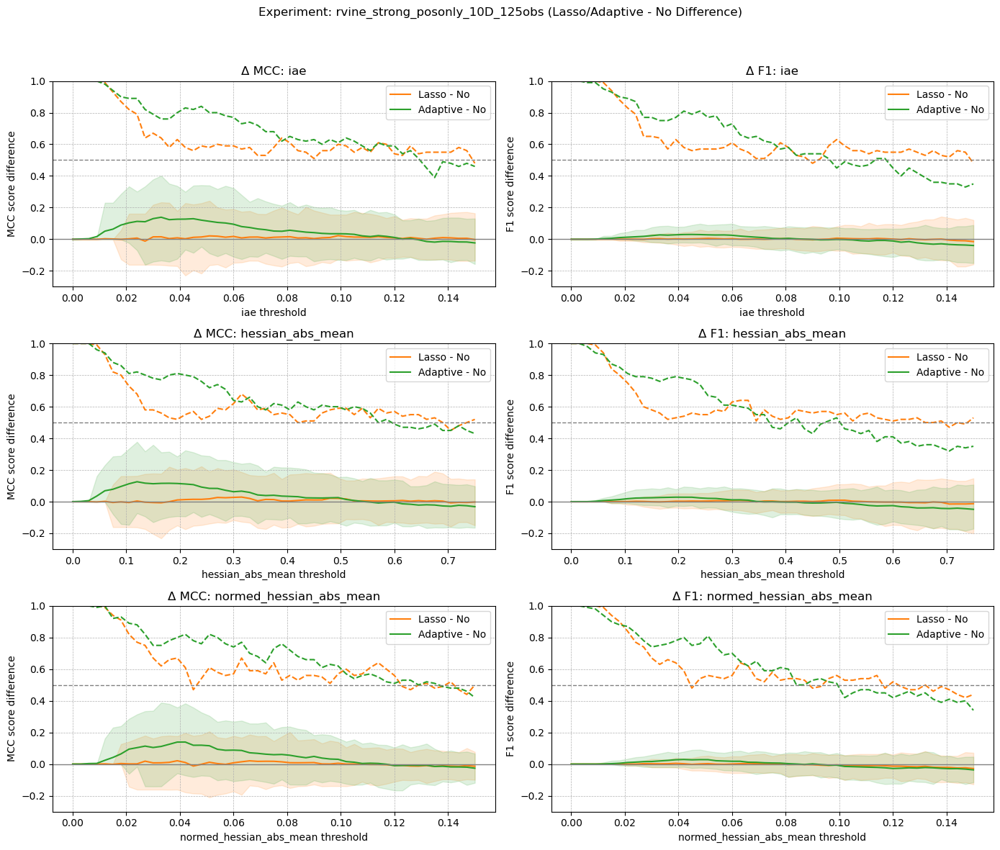

In [21]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_posonly_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.75, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.15, 51)}, differences_plot=True,
                                                 conf_percentiles=(10, 90))

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


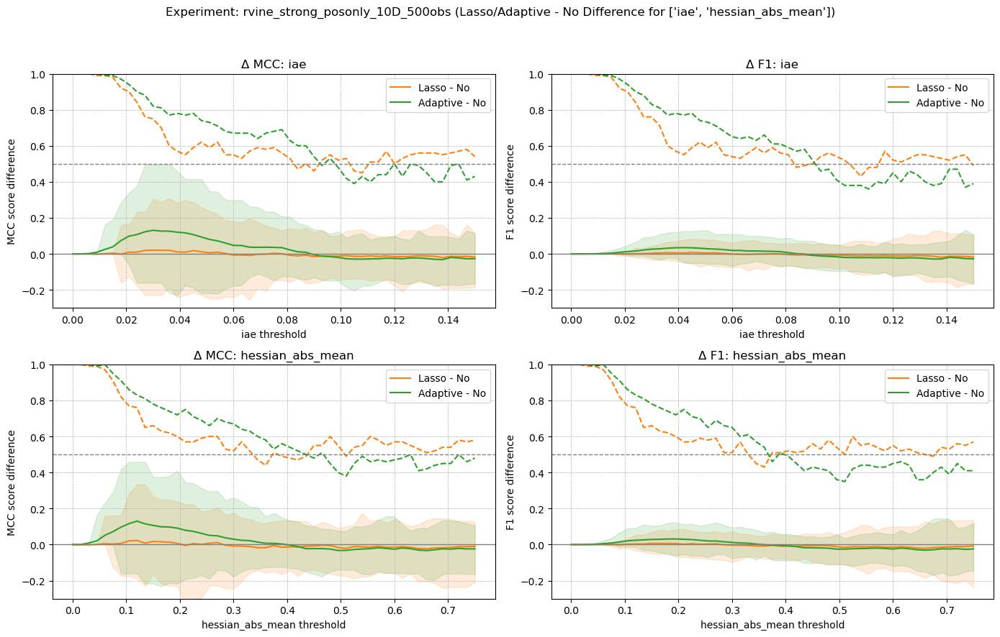

Metric: iae
  F1: Adaptive better than No 43.0% of seeds (mean diff: -0.0012)
  MCC: Adaptive better than No 41.0% of seeds (mean diff: -0.0032)

Metric: hessian_abs_mean
  F1: Adaptive better than No 40.0% of seeds (mean diff: -0.0011)
  MCC: Adaptive better than No 42.0% of seeds (mean diff: -0.0010)



In [117]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_posonly_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.75, 51)}, differences_plot=True)

#### Higher Dimensions

Processing seeds: 100%|██████████| 100/100 [00:29<00:00,  3.37it/s]


Metric: iae
  F1: Adaptive better than No 71.0% of seeds (mean diff: 0.0167)
  MCC: Adaptive better than No 74.0% of seeds (mean diff: 0.0230)

Metric: hessian_abs_mean
  F1: Adaptive better than No 70.0% of seeds (mean diff: 0.0098)
  MCC: Adaptive better than No 72.0% of seeds (mean diff: 0.0139)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 75.0% of seeds (mean diff: 0.0230)
  MCC: Adaptive better than No 75.0% of seeds (mean diff: 0.0371)

Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 59.0% of seeds (mean diff: 0.0030)
  MCC: Adaptive better than No 62.0% of seeds (mean diff: 0.0038)



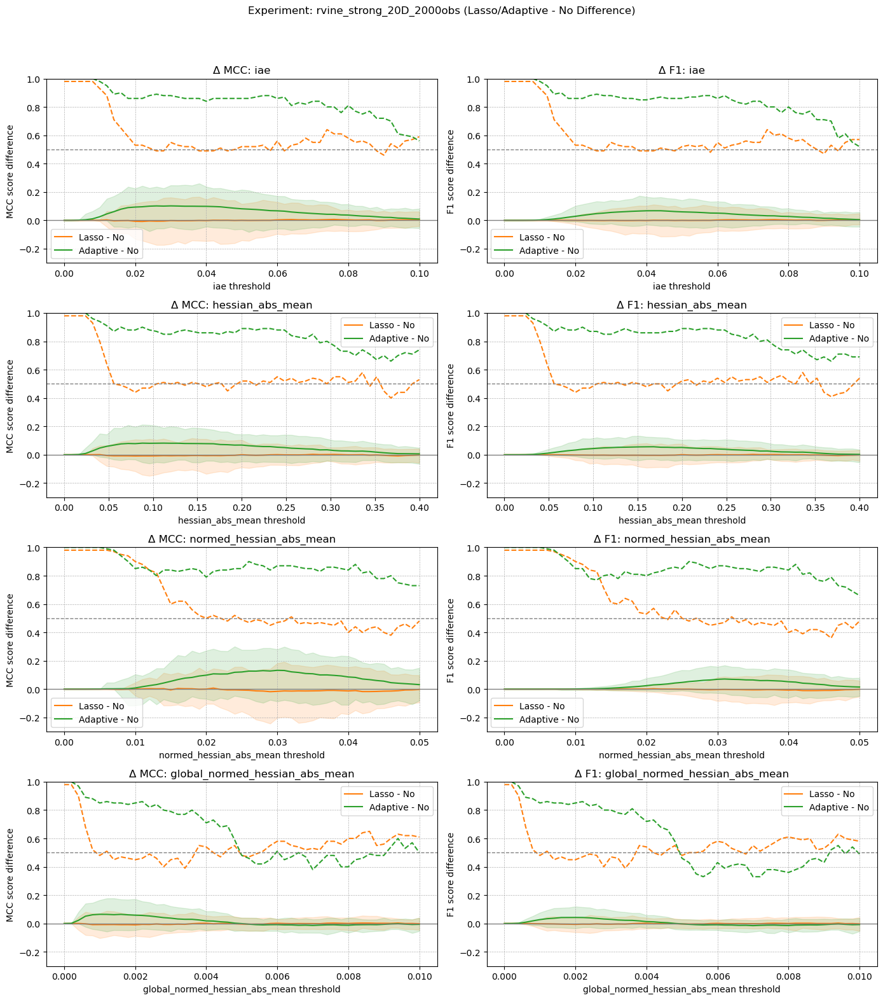

In [194]:
#summary_df = evaluate_experiment_scores_allplots("rvine_strong_20D_2000obs",
#                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
#                                                  "hessian_abs_mean": np.linspace(0, 0.75, 51)}, differences_plot=True)


summary_df = evaluate_experiment_scores_allplots("rvine_strong_20D_2000obs",
                                                 metrics=["iae", 
                                                          "hessian_abs_mean", 
                                                          "normed_hessian_abs_mean", 
                                                          "global_normed_hessian_abs_mean"],
                                                 thresholds_dict={
                                                     "iae": np.linspace(0, 0.1, 51),
                                                  "global_normed_hessian_abs_mean": np.linspace(0, 0.01, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.4, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.05, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 40/40 [00:08<00:00,  4.58it/s]


Metric: iae
  F1: Adaptive better than No 55.0% of seeds (mean diff: -0.0000)
  MCC: Adaptive better than No 55.0% of seeds (mean diff: 0.0008)

Metric: hessian_abs_mean
  F1: Adaptive better than No 55.0% of seeds (mean diff: 0.0028)
  MCC: Adaptive better than No 55.0% of seeds (mean diff: 0.0055)



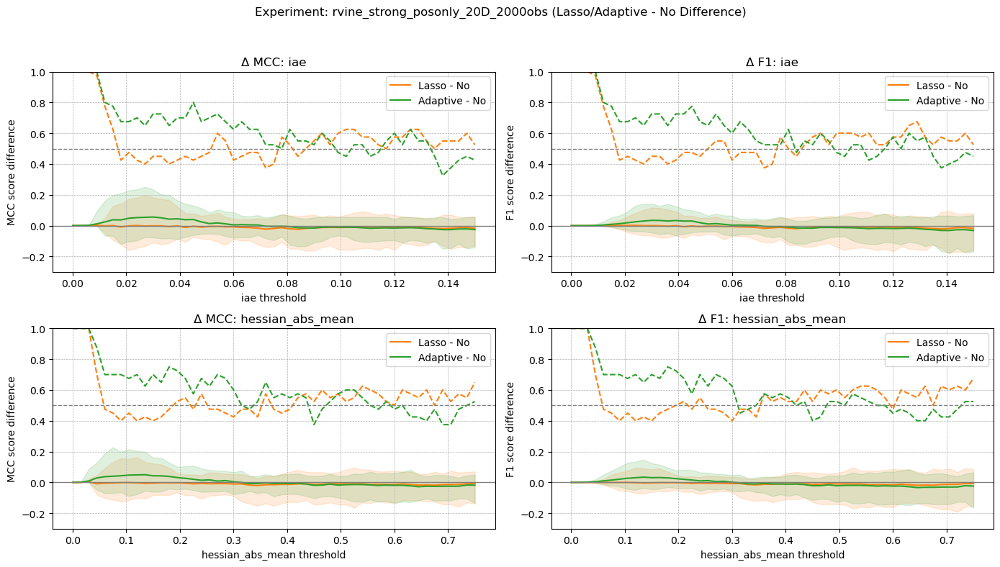

In [136]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_posonly_20D_2000obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.75, 51)}, differences_plot=True)

In [9]:
import torch
a = torch.randn([5,5])
a = a.fill_diagonal_(0)
a
a

tensor([[ 0.0000, -0.1198,  0.5318,  0.0396,  0.1823],
        [ 0.3601,  0.0000, -0.7666, -0.5429,  0.1874],
        [-1.8330, -0.1743,  0.0000, -1.2195,  0.5322],
        [-0.0837, -0.3053, -0.1906,  0.0000,  0.1882],
        [ 1.5453,  0.8686, -0.7839, -0.5114,  0.0000]])

Processing seeds: 100%|██████████| 100/100 [00:31<00:00,  3.13it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 72.0% of seeds (mean diff: 0.0213)
  MCC: Adaptive better than No 72.0% of seeds (mean diff: 0.0203)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 76.0% of seeds (mean diff: 0.0296)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0029)

Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 45.0% of seeds (mean diff: -0.0116)
  MCC: Adaptive better than No 46.0% of seeds (mean diff: -0.0124)



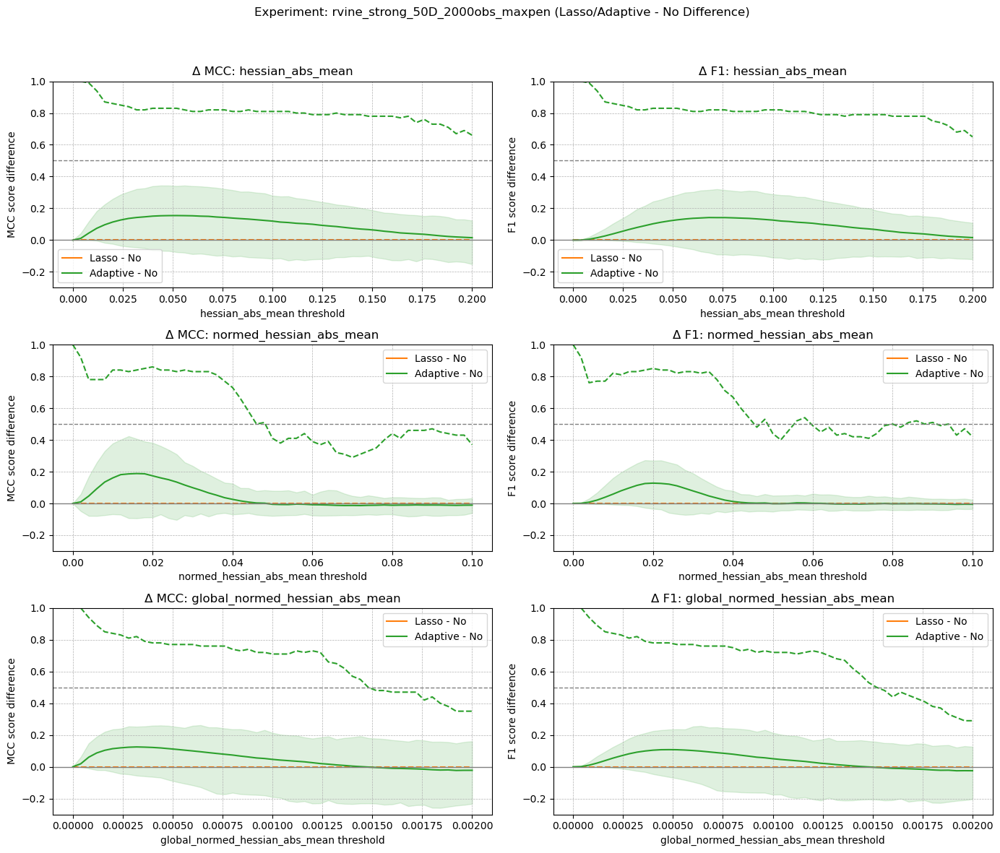

In [132]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_50D_2000obs_maxpen",
                                                 metrics=["hessian_abs_mean", "normed_hessian_abs_mean", "global_normed_hessian_abs_mean"],
                                                 thresholds_dict={#"iae": np.linspace(0, 0.15, 51),
                                                  "global_normed_hessian_abs_mean": np.linspace(0, 0.002, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.2, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 18/18 [00:09<00:00,  1.87it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 50.0% of seeds (mean diff: 0.0202)
  MCC: Adaptive better than No 44.4% of seeds (mean diff: 0.0142)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 11.1% of seeds (mean diff: 0.0007)
  MCC: Adaptive better than No 38.9% of seeds (mean diff: -0.0046)

Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 33.3% of seeds (mean diff: -0.0283)
  MCC: Adaptive better than No 33.3% of seeds (mean diff: -0.0311)



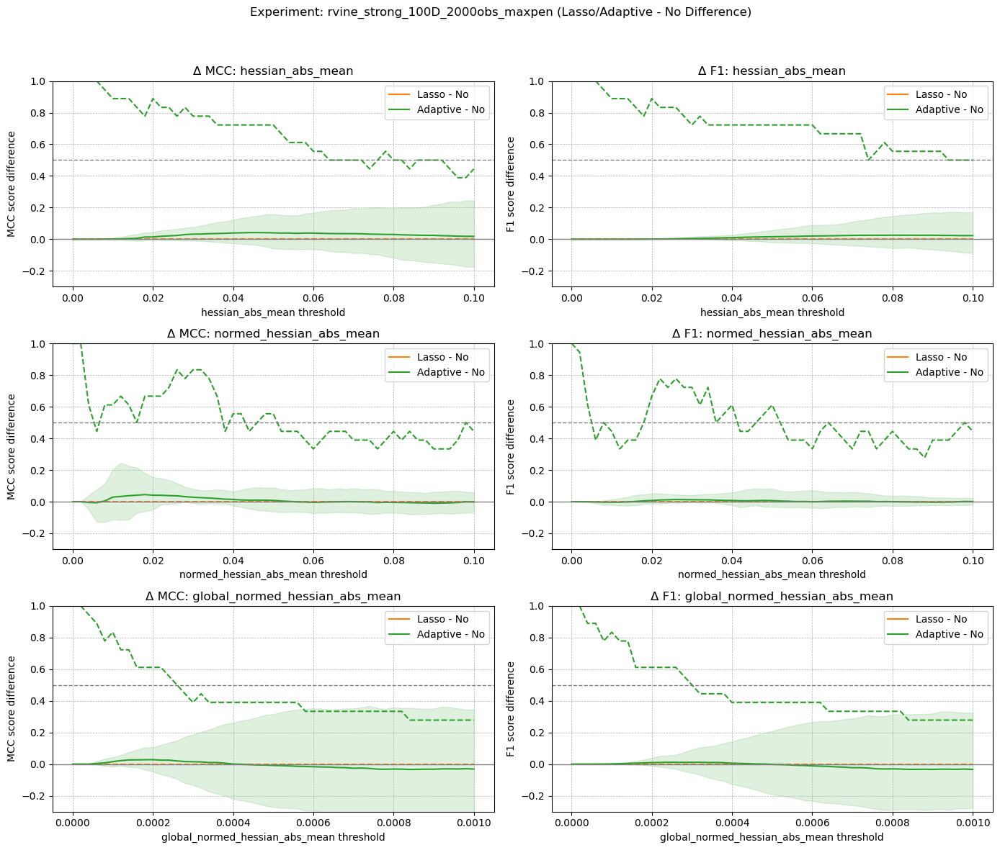

In [144]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_100D_2000obs_maxpen",
                                                 metrics=["hessian_abs_mean", "normed_hessian_abs_mean", "global_normed_hessian_abs_mean"],
                                                 thresholds_dict={#"iae": np.linspace(0, 0.15, 51),
                                                  "global_normed_hessian_abs_mean": np.linspace(0, 0.001, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.1, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 80/80 [00:45<00:00,  1.75it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 55.0% of seeds (mean diff: 0.0156)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0137)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 81.2% of seeds (mean diff: 0.0257)
  MCC: Adaptive better than No 33.8% of seeds (mean diff: -0.0057)

Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 40.0% of seeds (mean diff: -0.0050)
  MCC: Adaptive better than No 42.5% of seeds (mean diff: -0.0010)



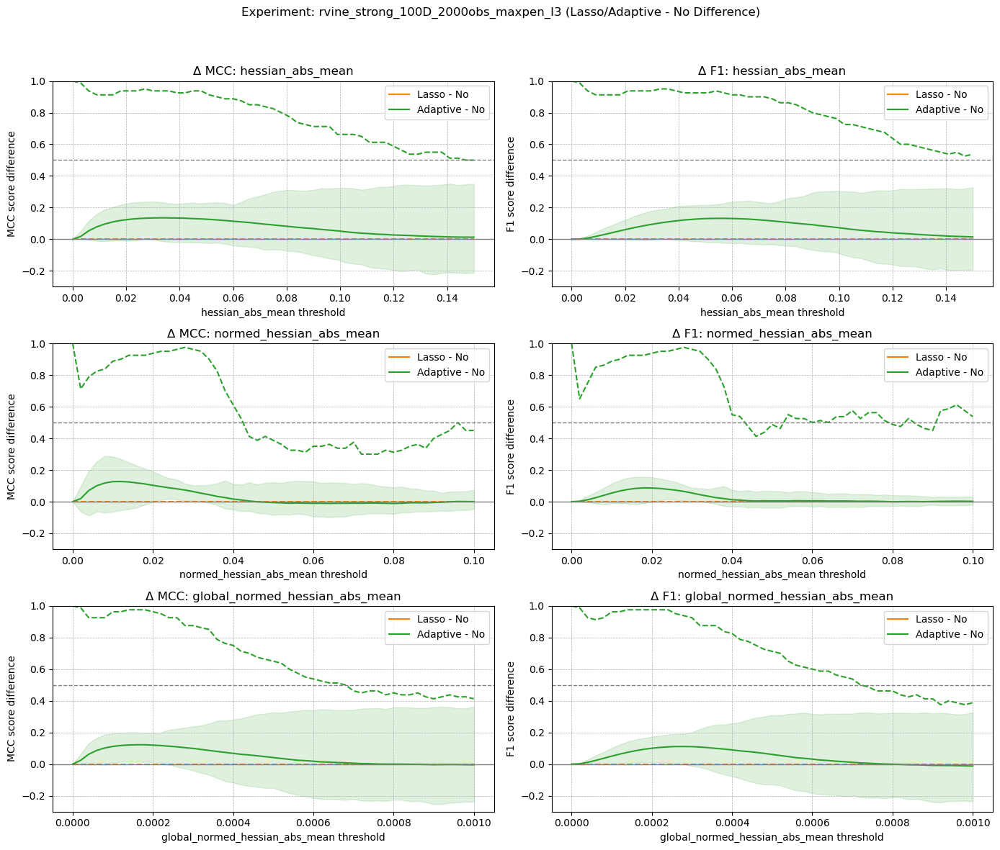

In [200]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_100D_2000obs_maxpen_I3",
                                                 metrics=["hessian_abs_mean", "normed_hessian_abs_mean", "global_normed_hessian_abs_mean"],
                                                 thresholds_dict={#"iae": np.linspace(0, 0.15, 51),
                                                  "global_normed_hessian_abs_mean": np.linspace(0, 0.001, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.15, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)}, differences_plot=True)

### C-vine

#### Normal

Processing seeds: 100%|██████████| 100/100 [00:42<00:00,  2.37it/s]


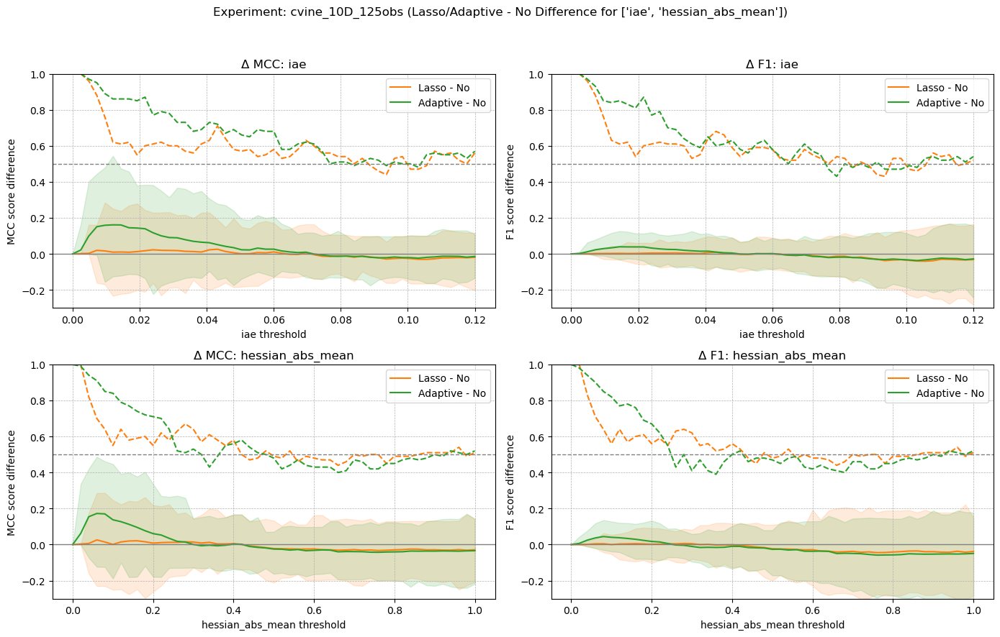

Metric: iae
  F1: Adaptive better than No 58.0% of seeds (mean diff: 0.0066)
  MCC: Adaptive better than No 56.0% of seeds (mean diff: 0.0104)

Metric: hessian_abs_mean
  F1: Adaptive better than No 44.0% of seeds (mean diff: -0.0006)
  MCC: Adaptive better than No 38.0% of seeds (mean diff: -0.0048)



In [121]:
summary_df = evaluate_experiment_scores_allplots("cvine_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:45<00:00,  2.20it/s]


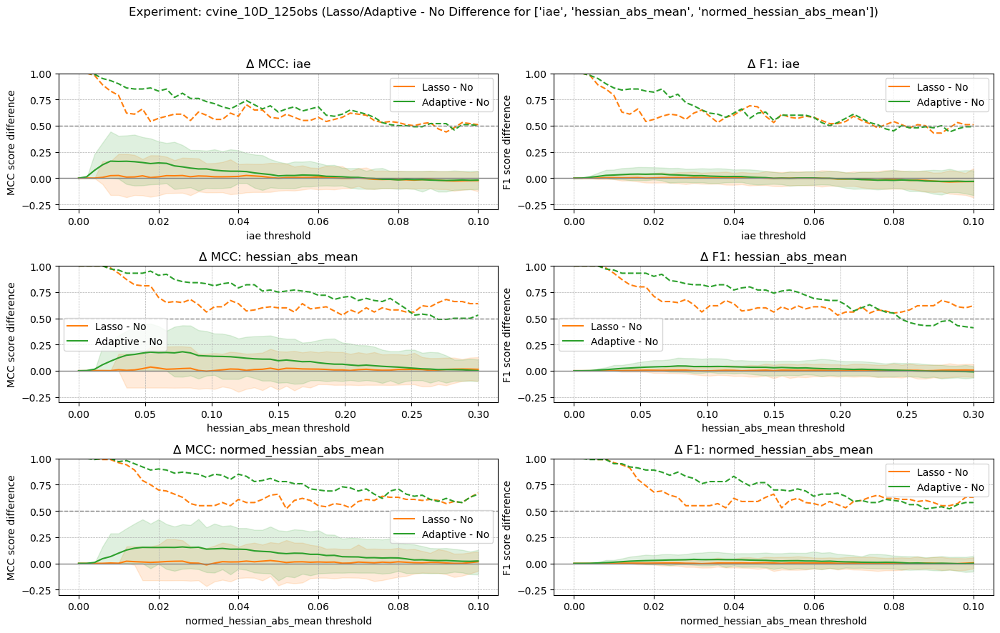

Metric: iae
  F1: Adaptive better than No 60.0% of seeds (mean diff: 0.0080)
  MCC: Adaptive better than No 53.0% of seeds (mean diff: 0.0147)

Metric: hessian_abs_mean
  F1: Adaptive better than No 50.0% of seeds (mean diff: 0.0056)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0187)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 62.0% of seeds (mean diff: 0.0132)
  MCC: Adaptive better than No 61.0% of seeds (mean diff: 0.0282)



In [24]:
summary_df = evaluate_experiment_scores_allplots("cvine_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.3, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.38it/s]


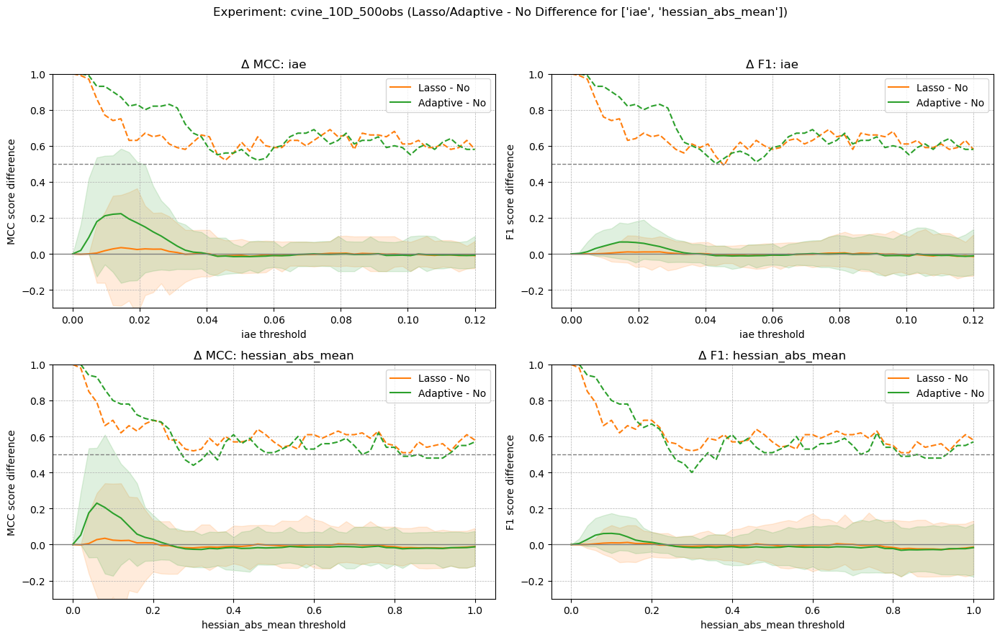

Metric: iae
  F1: Adaptive better than No 48.0% of seeds (mean diff: 0.0033)
  MCC: Adaptive better than No 42.0% of seeds (mean diff: 0.0047)

Metric: hessian_abs_mean
  F1: Adaptive better than No 29.0% of seeds (mean diff: -0.0011)
  MCC: Adaptive better than No 26.0% of seeds (mean diff: -0.0019)



In [ ]:
summary_df = evaluate_experiment_scores_allplots("cvine_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.41it/s]


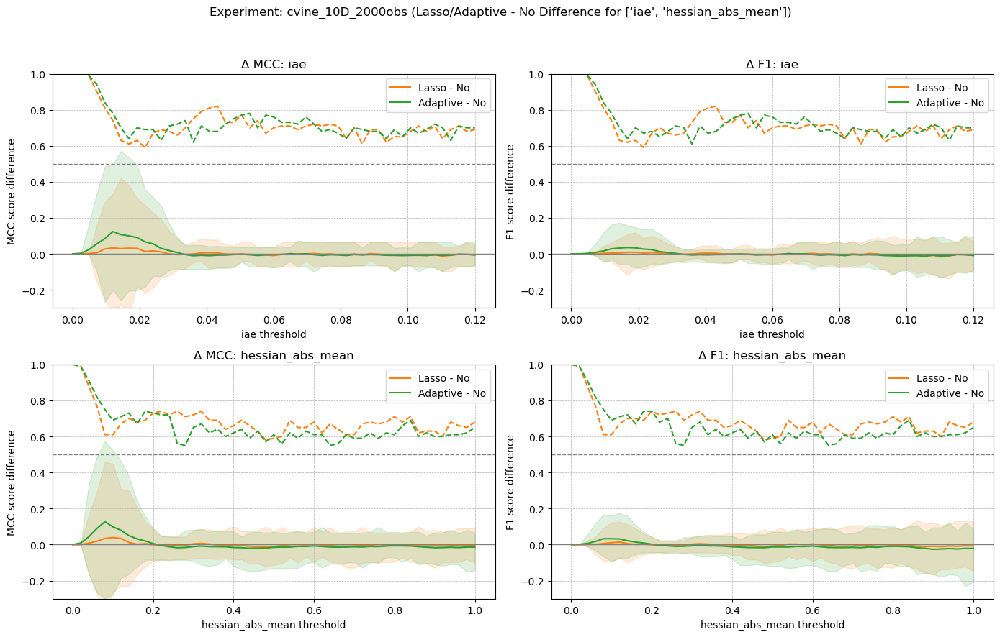

Metric: iae
  F1: Adaptive better than No 26.0% of seeds (mean diff: -0.0010)
  MCC: Adaptive better than No 20.0% of seeds (mean diff: -0.0027)

Metric: hessian_abs_mean
  F1: Adaptive better than No 21.0% of seeds (mean diff: 0.0001)
  MCC: Adaptive better than No 18.0% of seeds (mean diff: 0.0006)



In [123]:
summary_df = evaluate_experiment_scores_allplots("cvine_10D_2000obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

#### Strong

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.39it/s]


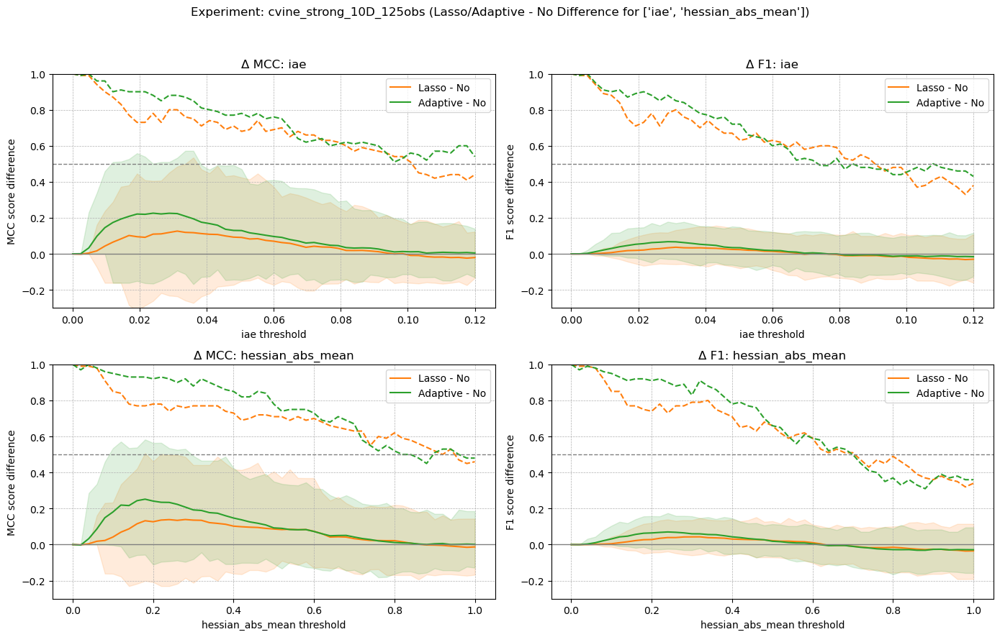

Metric: iae
  F1: Adaptive better than No 75.0% of seeds (mean diff: 0.0270)
  MCC: Adaptive better than No 70.0% of seeds (mean diff: 0.0502)

Metric: hessian_abs_mean
  F1: Adaptive better than No 72.0% of seeds (mean diff: 0.0264)
  MCC: Adaptive better than No 72.0% of seeds (mean diff: 0.0610)



In [124]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:44<00:00,  2.25it/s]


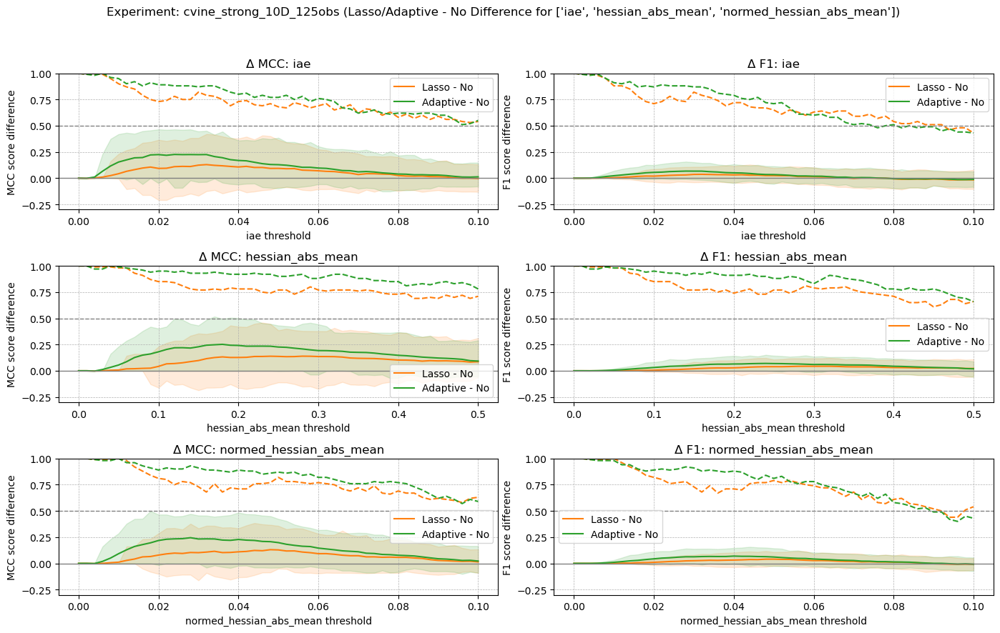

Metric: iae
  F1: Adaptive better than No 76.0% of seeds (mean diff: 0.0292)
  MCC: Adaptive better than No 71.0% of seeds (mean diff: 0.0590)

Metric: hessian_abs_mean
  F1: Adaptive better than No 83.0% of seeds (mean diff: 0.0444)
  MCC: Adaptive better than No 84.0% of seeds (mean diff: 0.1216)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 71.0% of seeds (mean diff: 0.0236)
  MCC: Adaptive better than No 70.0% of seeds (mean diff: 0.0593)



In [26]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

Processing seeds: 100%|██████████| 100/100 [00:45<00:00,  2.20it/s]


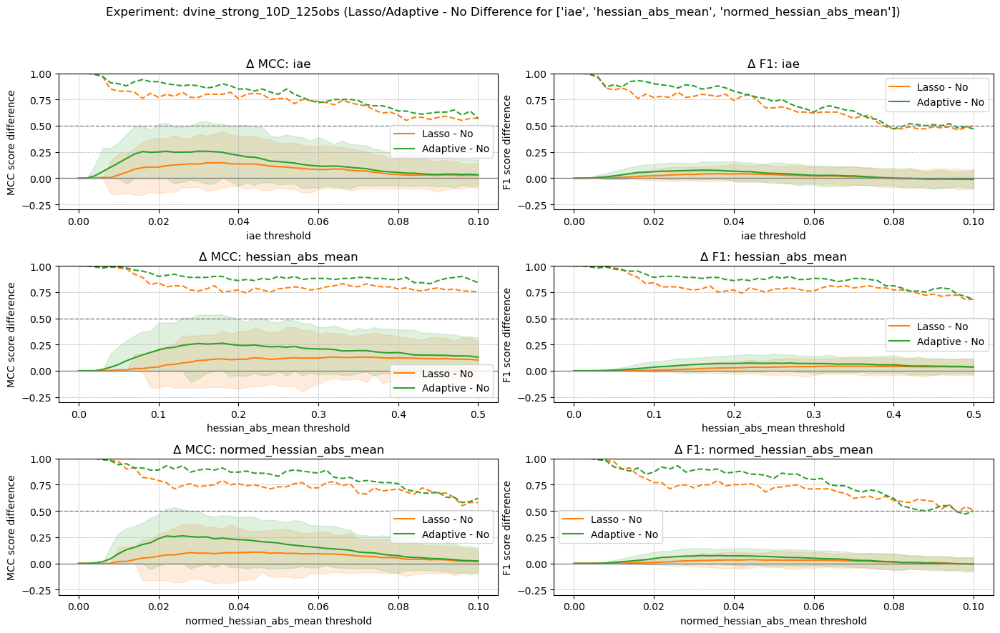

Metric: iae
  F1: Adaptive better than No 66.0% of seeds (mean diff: 0.0337)
  MCC: Adaptive better than No 73.0% of seeds (mean diff: 0.0792)

Metric: hessian_abs_mean
  F1: Adaptive better than No 82.0% of seeds (mean diff: 0.0538)
  MCC: Adaptive better than No 86.0% of seeds (mean diff: 0.1464)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 64.0% of seeds (mean diff: 0.0267)
  MCC: Adaptive better than No 67.0% of seeds (mean diff: 0.0615)



In [30]:
summary_df = evaluate_experiment_scores_allplots("dvine_strong_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

Processing seeds: 100%|██████████| 100/100 [00:45<00:00,  2.22it/s]


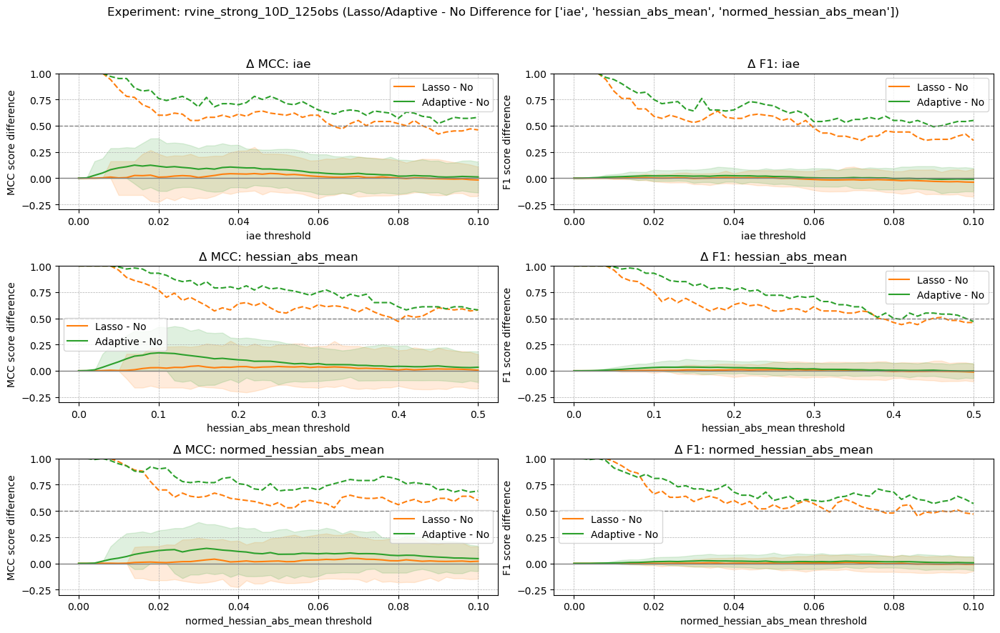

Metric: iae
  F1: Adaptive better than No 58.0% of seeds (mean diff: 0.0114)
  MCC: Adaptive better than No 59.0% of seeds (mean diff: 0.0306)

Metric: hessian_abs_mean
  F1: Adaptive better than No 50.0% of seeds (mean diff: 0.0106)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0370)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 60.0% of seeds (mean diff: 0.0152)
  MCC: Adaptive better than No 73.0% of seeds (mean diff: 0.0609)



In [31]:
summary_df = evaluate_experiment_scores_allplots("rvine_strong_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

Processing seeds: 100%|██████████| 100/100 [00:42<00:00,  2.36it/s]


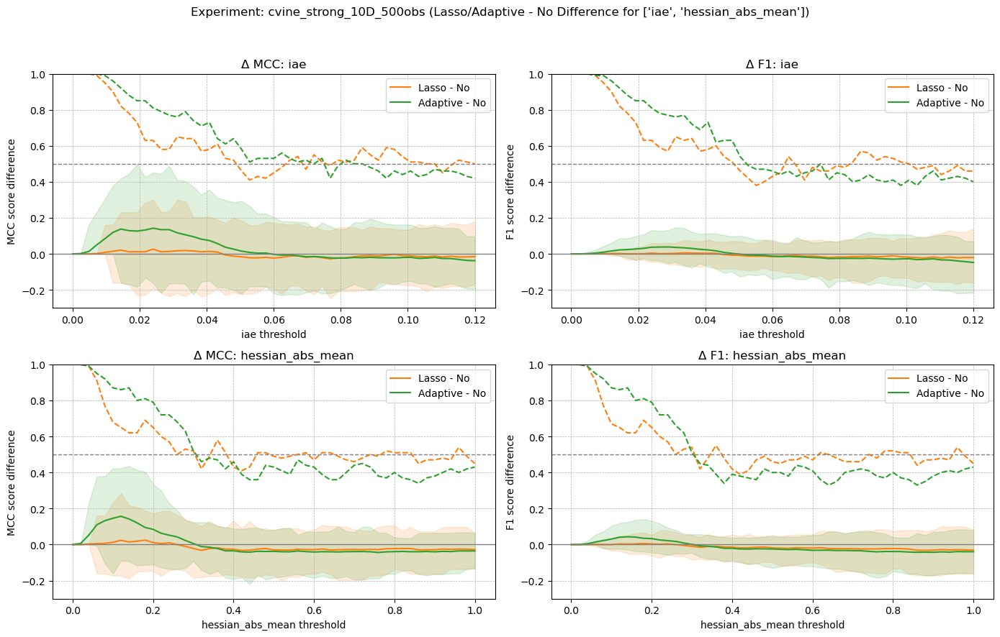

Metric: iae
  F1: Adaptive better than No 39.0% of seeds (mean diff: -0.0037)
  MCC: Adaptive better than No 37.0% of seeds (mean diff: -0.0070)

Metric: hessian_abs_mean
  F1: Adaptive better than No 23.0% of seeds (mean diff: -0.0119)
  MCC: Adaptive better than No 22.0% of seeds (mean diff: -0.0239)



In [125]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

#### Strong PosOnly

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


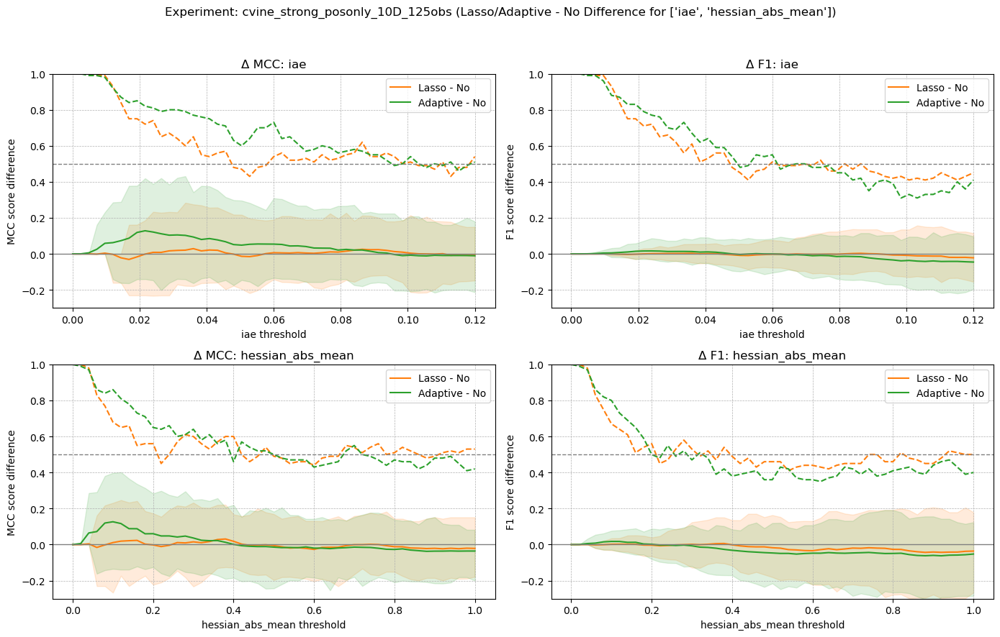

Metric: iae
  F1: Adaptive better than No 47.0% of seeds (mean diff: 0.0038)
  MCC: Adaptive better than No 52.0% of seeds (mean diff: 0.0168)

Metric: hessian_abs_mean
  F1: Adaptive better than No 51.0% of seeds (mean diff: 0.0010)
  MCC: Adaptive better than No 47.0% of seeds (mean diff: 0.0031)



In [126]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_posonly_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:44<00:00,  2.22it/s]


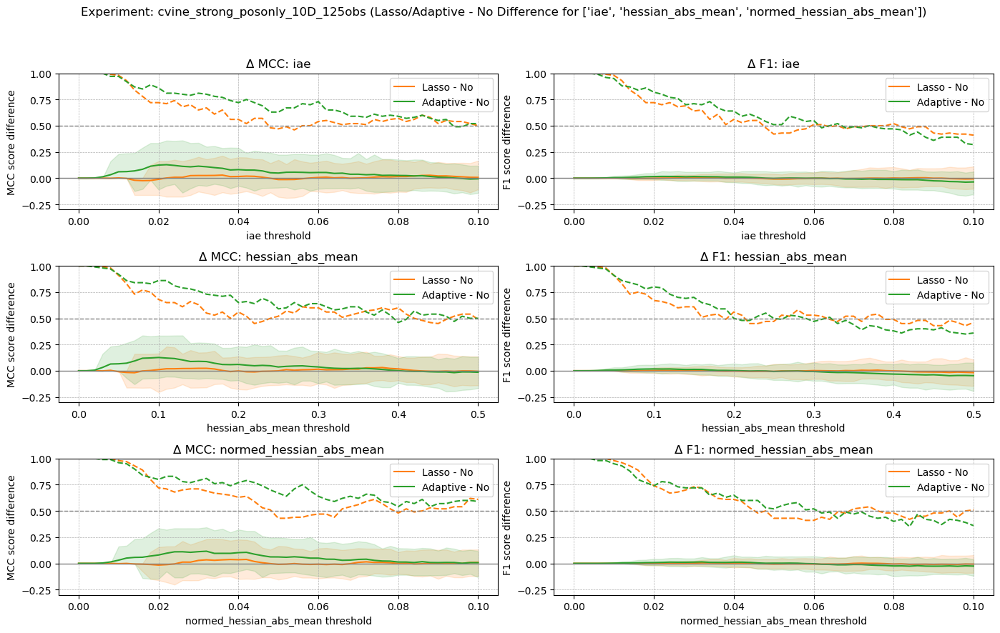

Metric: iae
  F1: Adaptive better than No 52.0% of seeds (mean diff: 0.0064)
  MCC: Adaptive better than No 57.0% of seeds (mean diff: 0.0211)

Metric: hessian_abs_mean
  F1: Adaptive better than No 52.0% of seeds (mean diff: 0.0031)
  MCC: Adaptive better than No 53.0% of seeds (mean diff: 0.0170)

Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 49.0% of seeds (mean diff: 0.0050)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0202)



In [29]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_posonly_10D_125obs",
                                                 metrics=["iae", "hessian_abs_mean", "normed_hessian_abs_mean"],
                                                 thresholds_dict={"iae": np.linspace(0, 0.1, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51),
                                                  "normed_hessian_abs_mean": np.linspace(0, 0.1, 51)},
                                                 differences_plot=True,
                                                 conf_percentiles=(10,90))

In [ ]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_posonly_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.39it/s]


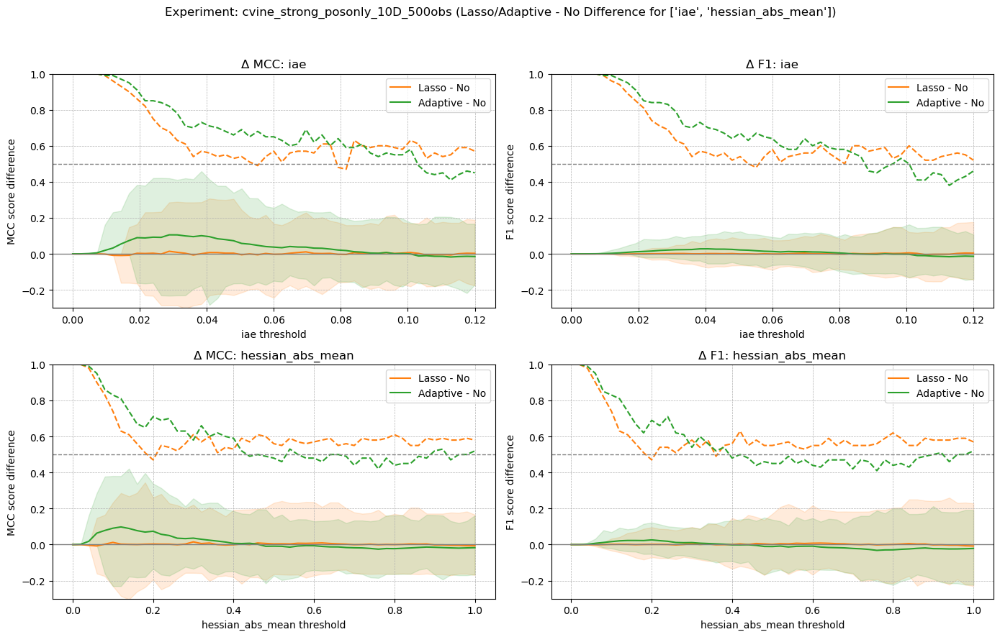

Metric: iae
  F1: Adaptive better than No 45.0% of seeds (mean diff: 0.0020)
  MCC: Adaptive better than No 51.0% of seeds (mean diff: 0.0063)

Metric: hessian_abs_mean
  F1: Adaptive better than No 45.0% of seeds (mean diff: 0.0031)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0074)



In [127]:
summary_df = evaluate_experiment_scores_allplots("cvine_strong_posonly_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

### D-Vine

#### Normal

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


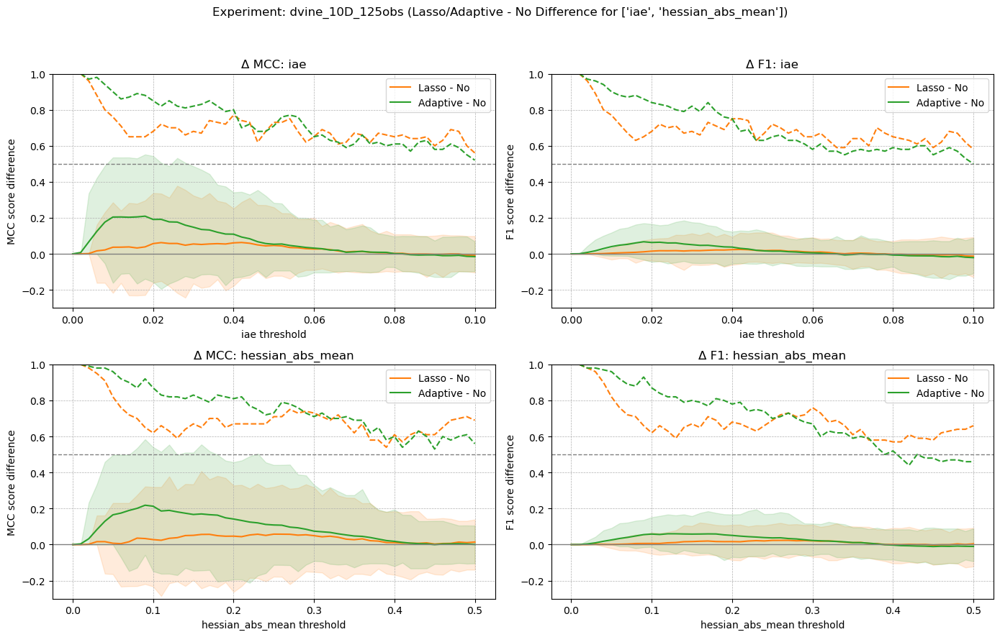

Metric: iae
  F1: Adaptive better than No 66.0% of seeds (mean diff: 0.0242)
  MCC: Adaptive better than No 62.0% of seeds (mean diff: 0.0482)

Metric: hessian_abs_mean
  F1: Adaptive better than No 69.0% of seeds (mean diff: 0.0263)
  MCC: Adaptive better than No 71.0% of seeds (mean diff: 0.0545)



In [128]:
summary_df = evaluate_experiment_scores_allplots("dvine_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.10, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


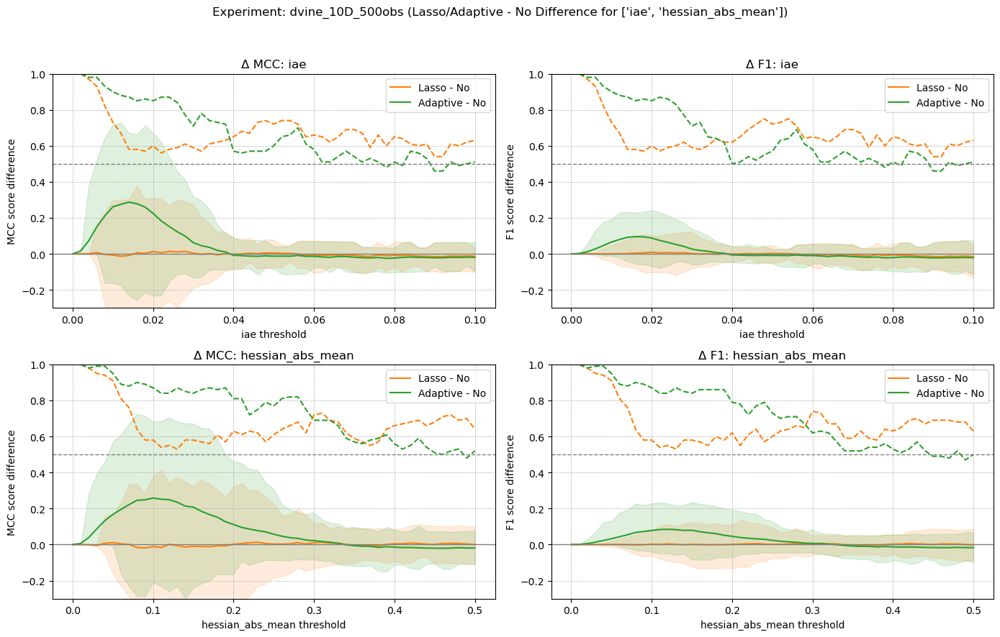

Metric: iae
  F1: Adaptive better than No 44.0% of seeds (mean diff: 0.0073)
  MCC: Adaptive better than No 41.0% of seeds (mean diff: 0.0137)

Metric: hessian_abs_mean
  F1: Adaptive better than No 57.0% of seeds (mean diff: 0.0113)
  MCC: Adaptive better than No 48.0% of seeds (mean diff: 0.0219)



In [129]:
summary_df = evaluate_experiment_scores_allplots("dvine_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.10, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.38it/s]


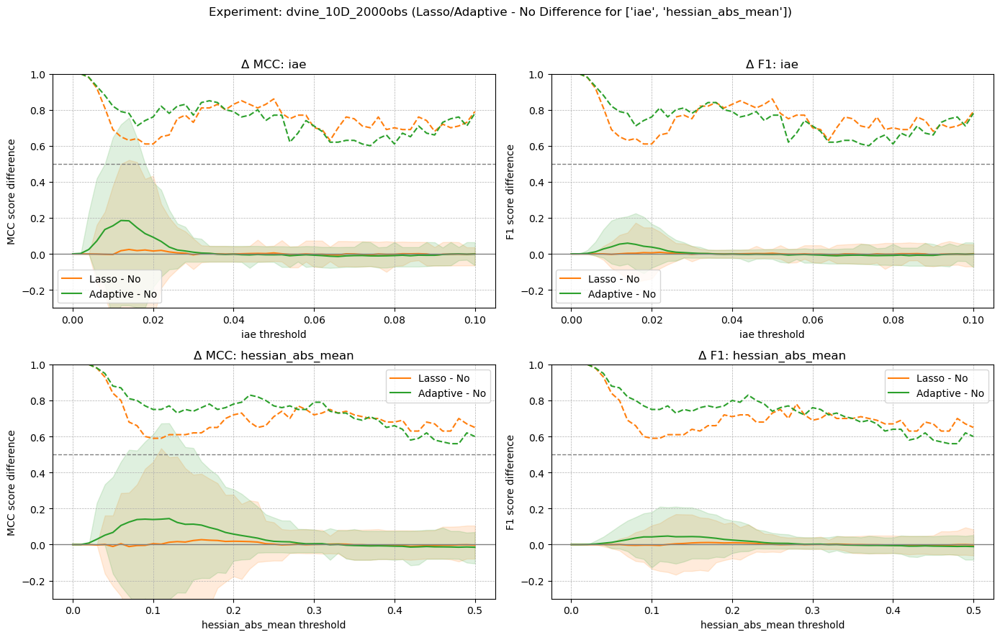

Metric: iae
  F1: Adaptive better than No 11.0% of seeds (mean diff: 0.0009)
  MCC: Adaptive better than No 11.0% of seeds (mean diff: 0.0017)

Metric: hessian_abs_mean
  F1: Adaptive better than No 25.0% of seeds (mean diff: 0.0035)
  MCC: Adaptive better than No 22.0% of seeds (mean diff: 0.0072)



In [130]:
summary_df = evaluate_experiment_scores_allplots("dvine_10D_2000obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.10, 51),
                                                  "hessian_abs_mean": np.linspace(0, 0.5, 51)}, differences_plot=True)

#### Strong

Processing seeds: 100%|██████████| 100/100 [00:42<00:00,  2.36it/s]


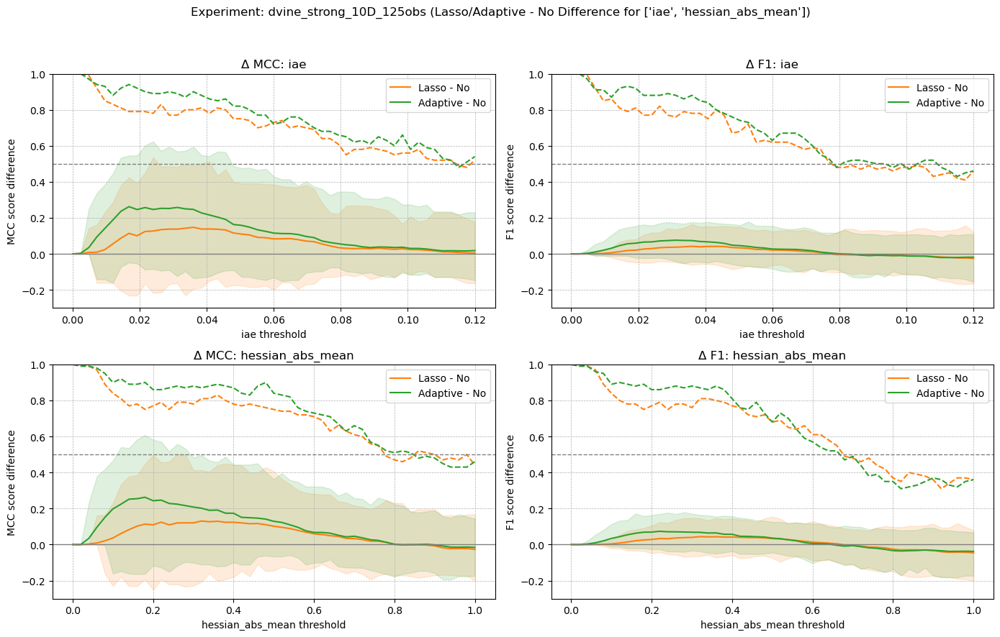

Metric: iae
  F1: Adaptive better than No 65.0% of seeds (mean diff: 0.0323)
  MCC: Adaptive better than No 70.0% of seeds (mean diff: 0.0693)

Metric: hessian_abs_mean
  F1: Adaptive better than No 73.0% of seeds (mean diff: 0.0305)
  MCC: Adaptive better than No 72.0% of seeds (mean diff: 0.0639)



In [131]:
summary_df = evaluate_experiment_scores_allplots("dvine_strong_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


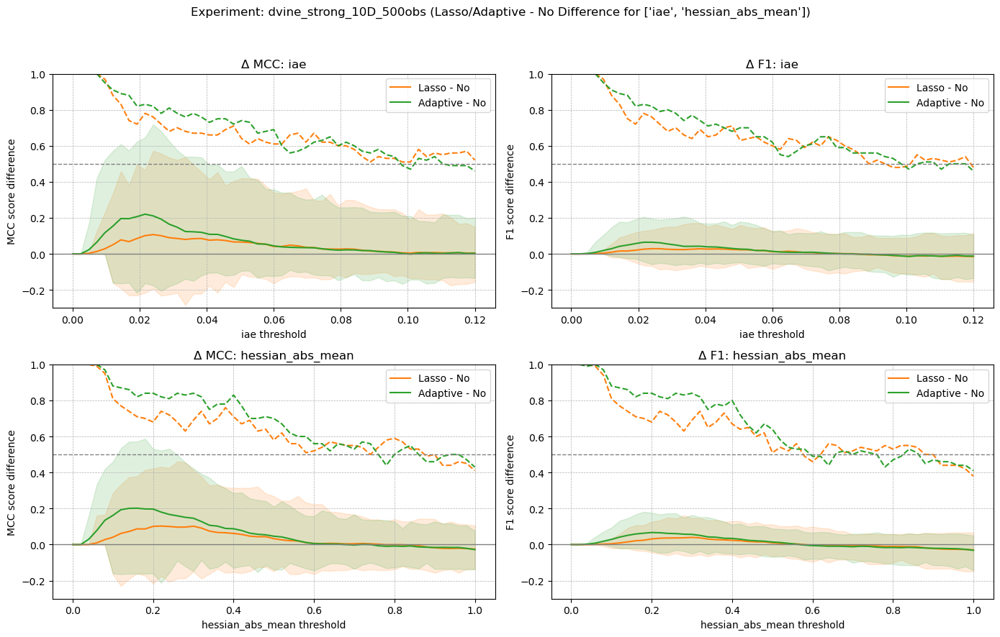

Metric: iae
  F1: Adaptive better than No 56.0% of seeds (mean diff: 0.0151)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0360)

Metric: hessian_abs_mean
  F1: Adaptive better than No 62.0% of seeds (mean diff: 0.0149)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0318)



In [132]:
summary_df = evaluate_experiment_scores_allplots("dvine_strong_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.39it/s]


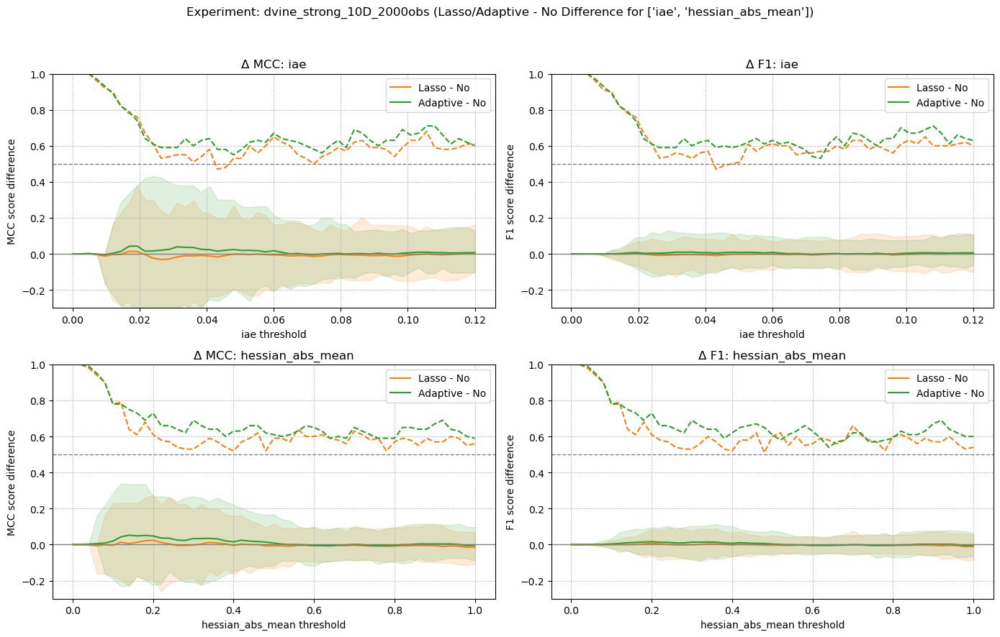

Metric: iae
  F1: Adaptive better than No 34.0% of seeds (mean diff: 0.0009)
  MCC: Adaptive better than No 29.0% of seeds (mean diff: 0.0020)

Metric: hessian_abs_mean
  F1: Adaptive better than No 41.0% of seeds (mean diff: 0.0040)
  MCC: Adaptive better than No 39.0% of seeds (mean diff: 0.0080)



In [133]:
summary_df = evaluate_experiment_scores_allplots("dvine_strong_10D_2000obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.12, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

#### Strong PosOnly

Processing seeds: 100%|██████████| 100/100 [00:41<00:00,  2.42it/s]


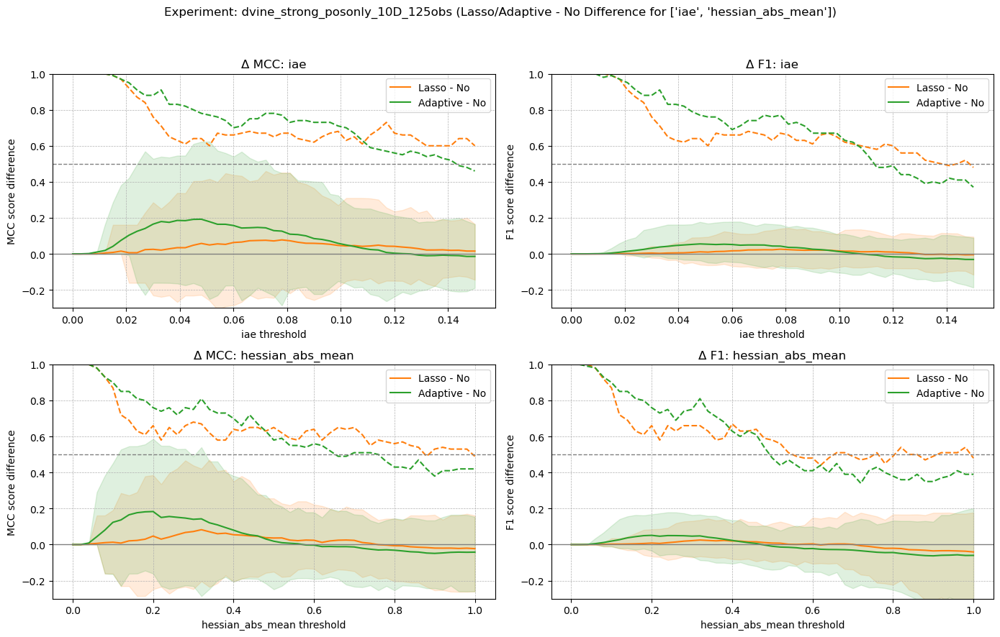

Metric: iae
  F1: Adaptive better than No 69.0% of seeds (mean diff: 0.0171)
  MCC: Adaptive better than No 63.0% of seeds (mean diff: 0.0360)

Metric: hessian_abs_mean
  F1: Adaptive better than No 64.0% of seeds (mean diff: 0.0153)
  MCC: Adaptive better than No 65.0% of seeds (mean diff: 0.0299)



In [134]:
summary_df = evaluate_experiment_scores_allplots("dvine_strong_posonly_10D_125obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

In [142]:
summary_df = evaluate_experiment_scores_allplots("dvine_strong_posonly_10D_500obs",
                                                 thresholds_dict={"iae": np.linspace(0, 0.15, 51),
                                                  "hessian_abs_mean": np.linspace(0, 1, 51)}, differences_plot=True)

Processing seeds:  98%|█████████▊| 41/42 [00:05<00:00,  7.38it/s]


FileNotFoundError: [Errno 2] No such file or directory: '/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch/172202589055772942/d4b8cf9ee2b94e58a4a91905880bd2a1/artifacts/conditional_independence_table_model_samples.csv'

### For the paper/presentation

In [8]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

obs_list = [125, 500, 2000]

vine_types = ["rvine", "dvine", "cvine"]

strength_types = ["", "_strong"]  # "" = normal, "_strong" = strong

metrics_config = [
    {
        "metric"    : "iae",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.1, 51),
        "file_str"  : "mcc_iae_diff",
    },
    {
        "metric"    : "hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.5, 51),
        "file_str"  : "mcc_hessian_abs_diff",
    },
    {
        "metric"    : "normed_hessian_abs_mean",
        "metric_name": "$",
        "threshold" : np.linspace(0, 0.1, 51),
        "file_str"  : "mcc_hessian_pair_normed_diff",
    },
    {
        "metric"    : "global_normed_hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.03, 51),
        "file_str"  : "mcc_hessian_global_normed_diff",
    },
]

for obs in obs_list:
    for strength in strength_types:
        for vine in vine_types:

            experiment_name = f"{vine}{strength}_10D_{obs}obs"

            # legend only for rvine
            show_legend = (vine == "rvine")

            print(f"\nStarting experiment: {experiment_name} | legend={show_legend}")

            for metric_cfg in metrics_config:

                metric     = metric_cfg["metric"]
                threshold  = metric_cfg["threshold"]
                file_str   = metric_cfg["file_str"]

                print(f"  Metric: {metric}")

                try:
                    summary_df, fig = evaluate_experiment_scores_allplots(
                        experiment_name,
                        metrics         = [metric],
                        thresholds_dict = {metric: threshold},
                        score_types     = ["mcc"],
                        differences_plot = True,
                        conf_percentiles = (10, 90),
                        title           = False,     # always off
                        legend          = show_legend,
                    )

                    filename = f"{file_str}_{experiment_name}.png"
                    plt.savefig(filename)
                    plt.close()
                    print(f"  Saved: {filename}")

                except Exception as e:
                    print(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
                    plt.close()
                    continue

print("\nAll done.")


Starting experiment: rvine_10D_125obs | legend=True
  Metric: iae


KeyboardInterrupt: 

In [11]:
import matplotlib.pyplot as plt

# Use matplotlib's built-in mathtext renderer instead of a system LaTeX install
plt.rcParams["text.usetex"] = False

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

obs_list = [125, 500, 2000]

vine_types = ["rvine", "dvine", "cvine"]

strength_types = ["", "_strong"]  # "" = normal, "_strong" = strong

metrics_config = [
    {
        "metric"    : "iae",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.1, 51),
        "file_str"  : "mcc_iae_diff",
        "xlabel"    : r"$\mathrm{IAE}$ threshold $L$",
    },
    {
        "metric"    : "hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.5, 51),
        "file_str"  : "mcc_hessian_abs_diff",
        "xlabel"    : r"$|\overline{\mathbf{H}_{u,v}}|$ threshold $L$",
    },
    {
        "metric"    : "normed_hessian_abs_mean",
        "metric_name": "$",
        "threshold" : np.linspace(0, 0.1, 51),
        "file_str"  : "mcc_hessian_pair_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}^{(2)}}|$ threshold $L$",
    },
    {
        "metric"    : "global_normed_hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.03, 51),
        "file_str"  : "mcc_hessian_global_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}}|$ threshold $L$",
    },
]

for obs in obs_list:
    for strength in strength_types:
        for vine in vine_types:

            experiment_name = f"{vine}{strength}_10D_{obs}obs"

            # legend only for rvine
            show_legend = (vine == "cvine")

            print(f"\nStarting experiment: {experiment_name} | legend={show_legend}")

            for metric_cfg in metrics_config:

                metric     = metric_cfg["metric"]
                threshold  = metric_cfg["threshold"]
                file_str   = metric_cfg["file_str"]
                xlabel     = metric_cfg["xlabel"]

                print(f"  Metric: {metric}")

                try:
                    summary_df, fig = evaluate_experiment_scores_allplots(
                        experiment_name,
                        metrics         = [metric],
                        thresholds_dict = {metric: threshold},
                        score_types     = ["mcc"],
                        differences_plot = True,
                        conf_percentiles = (10, 90),
                        title           = False,     # always off
                        legend          = show_legend,
                        xlabel          = xlabel,
                    )

                    filename = f"{file_str}_{experiment_name}.png"
                    plt.savefig(filename)
                    plt.close()
                    print(f"  Saved: {filename}")

                except Exception as e:
                    print(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
                    plt.close()
                    continue

print("\nAll done.")


Starting experiment: rvine_10D_125obs | legend=False
  Metric: iae


Processing seeds: 100%|██████████| 100/100 [00:10<00:00,  9.69it/s]


Metric: iae
  F1: Adaptive better than No 62.0% of seeds (mean diff: 0.0150)
  MCC: Adaptive better than No 58.0% of seeds (mean diff: 0.0340)

  Saved: mcc_iae_diff_rvine_10D_125obs.png
  Metric: hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:09<00:00, 10.05it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 51.0% of seeds (mean diff: 0.0069)
  MCC: Adaptive better than No 56.0% of seeds (mean diff: 0.0173)

  Saved: mcc_hessian_abs_diff_rvine_10D_125obs.png
  Metric: normed_hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:09<00:00, 10.03it/s]


... (135 outputs left out)

Processing seeds: 100%|██████████| 100/100 [00:09<00:00, 10.94it/s]


Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 46.0% of seeds (mean diff: 0.0026)
  MCC: Adaptive better than No 41.0% of seeds (mean diff: 0.0041)

  Saved: mcc_hessian_pair_normed_diff_cvine_strong_10D_2000obs.png
  Metric: global_normed_hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:09<00:00, 10.70it/s]


Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 41.0% of seeds (mean diff: 0.0053)
  MCC: Adaptive better than No 37.0% of seeds (mean diff: 0.0111)

  Saved: mcc_hessian_global_normed_diff_cvine_strong_10D_2000obs.png

All done.


In [314]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# legend only for rvine
show_legend = False
experiment_name = "rvine_strong_20D_2000obs"

metrics_config = [
    #{
    #    "metric"    : "iae",
    #    "metric_name": "",
    #    "threshold" : np.linspace(0, 0.1, 51),
    #    "file_str"  : "mcc_iae_diff",
    #    "xlabel"    : r"$\mathrm{IAE}$ threshold $L$",
    #},
    {
        "metric"    : "hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.5, 51),
        "file_str"  : "mcc_hessian_abs_diff",
        "xlabel"    : r"$|\overline{\mathbf{H}_{u,v}}|$ threshold $L$",
        "max_xticks" : None,
    },
    {
        "metric"    : "normed_hessian_abs_mean",
        "metric_name": "$",
        "threshold" : np.linspace(0, 0.1, 51),
        "file_str"  : "mcc_hessian_pair_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}^{(2)}}|$ threshold $L$",
        "max_xticks" : None,
    },
    {
        "metric"    : "global_normed_hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.01, 51),
        "file_str"  : "mcc_hessian_global_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}}|$ threshold $L$",
        "max_xticks" : None,
    },
]

print(f"\nStarting experiment: {experiment_name} | legend={show_legend}")   
for metric_cfg in metrics_config:   
    metric     = metric_cfg["metric"]
    threshold  = metric_cfg["threshold"]
    file_str   = metric_cfg["file_str"]
    xlabel     = metric_cfg["xlabel"]
    max_xticks     = metric_cfg["max_xticks"] # max_xticks=None

    print(f"  Metric: {metric}")

    try:
        summary_df, fig = evaluate_experiment_scores_allplots(
            experiment_name,
            metrics         = [metric],
            thresholds_dict = {metric: threshold},
            score_types     = ["mcc"],
            differences_plot = True,
            conf_percentiles = (10, 90),
            title           = False,     # always off
            legend          = show_legend,
            xlabel          = xlabel,
            max_xticks=max_xticks
        )

        filename = f"{file_str}_{experiment_name}.png"
        plt.savefig(filename)
        plt.close()
        print(f"  Saved: {filename}")

    except Exception as e:
        print(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
        plt.close()
        continue
    

print("\nAll done.")


Starting experiment: rvine_strong_20D_2000obs | legend=False
  Metric: hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:08<00:00, 12.41it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 59.0% of seeds (mean diff: 0.0048)
  MCC: Adaptive better than No 63.0% of seeds (mean diff: 0.0068)

  Saved: mcc_hessian_abs_diff_rvine_strong_20D_2000obs.png
  Metric: normed_hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:07<00:00, 12.58it/s]


Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 70.0% of seeds (mean diff: 0.0133)
  MCC: Adaptive better than No 62.0% of seeds (mean diff: 0.0093)

  Saved: mcc_hessian_pair_normed_diff_rvine_strong_20D_2000obs.png
  Metric: global_normed_hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:08<00:00, 12.17it/s]

Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 59.0% of seeds (mean diff: 0.0030)
  MCC: Adaptive better than No 62.0% of seeds (mean diff: 0.0038)

  Saved: mcc_hessian_global_normed_diff_rvine_strong_20D_2000obs.png

All done.


In [310]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# legend only for rvine
show_legend = False
experiment_name = "rvine_strong_50D_2000obs_maxpen"

metrics_config = [
    #{
    #    "metric"    : "iae",
    #    "metric_name": "",
    #    "threshold" : np.linspace(0, 0.1, 51),
    #    "file_str"  : "mcc_iae_diff",
    #    "xlabel"    : r"$\mathrm{IAE}$ threshold $L$",
    #},
    {
        "metric"    : "hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.2, 51),
        "file_str"  : "mcc_hessian_abs_diff",
        "xlabel"    : r"$|\overline{\mathbf{H}_{u,v}}|$ threshold $L$",
        "max_xticks" : None,
    },
    {
        "metric"    : "normed_hessian_abs_mean",
        "metric_name": "$",
        "threshold" : np.linspace(0, 0.6, 51),
        "file_str"  : "mcc_hessian_pair_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}^{(2)}}|$ threshold $L$",
        "max_xticks" : None,
    },
    {
        "metric"    : "global_normed_hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.002, 51),
        "file_str"  : "mcc_hessian_global_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}}|$ threshold $L$",
        "max_xticks" : 5,
    },
]

print(f"\nStarting experiment: {experiment_name} | legend={show_legend}")   
for metric_cfg in metrics_config:   
    metric     = metric_cfg["metric"]
    threshold  = metric_cfg["threshold"]
    file_str   = metric_cfg["file_str"]
    xlabel     = metric_cfg["xlabel"]
    max_xticks     = metric_cfg["max_xticks"] # max_xticks=None

    print(f"  Metric: {metric}")

    try:
        summary_df, fig = evaluate_experiment_scores_allplots(
            experiment_name,
            metrics         = [metric],
            thresholds_dict = {metric: threshold},
            score_types     = ["mcc"],
            differences_plot = True,
            conf_percentiles = (10, 90),
            title           = False,     # always off
            legend          = show_legend,
            xlabel          = xlabel,
            max_xticks=max_xticks
        )

        filename = f"{file_str}_{experiment_name}.png"
        plt.savefig(filename)
        plt.close()
        print(f"  Saved: {filename}")

    except Exception as e:
        print(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
        plt.close()
        continue
    

print("\nAll done.")


Starting experiment: rvine_strong_50D_2000obs_maxpen | legend=False
  Metric: hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:07<00:00, 12.62it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 72.0% of seeds (mean diff: 0.0213)
  MCC: Adaptive better than No 72.0% of seeds (mean diff: 0.0203)

  Saved: mcc_hessian_abs_diff_rvine_strong_50D_2000obs_maxpen.png
  Metric: normed_hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:07<00:00, 13.19it/s]


Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 76.0% of seeds (mean diff: 0.0332)
  MCC: Adaptive better than No 53.0% of seeds (mean diff: 0.0044)

  Saved: mcc_hessian_pair_normed_diff_rvine_strong_50D_2000obs_maxpen.png
  Metric: global_normed_hessian_abs_mean


Processing seeds: 100%|██████████| 100/100 [00:07<00:00, 13.01it/s]

Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 45.0% of seeds (mean diff: -0.0116)
  MCC: Adaptive better than No 46.0% of seeds (mean diff: -0.0124)

  Saved: mcc_hessian_global_normed_diff_rvine_strong_50D_2000obs_maxpen.png

All done.


In [313]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# legend only for rvine
show_legend = False
experiment_name = "rvine_strong_100D_2000obs_maxpen_I3"

metrics_config = [
    #{
    #    "metric"    : "iae",
    #    "metric_name": "",
    #    "threshold" : np.linspace(0, 0.1, 51),
    #    "file_str"  : "mcc_iae_diff",
    #    "xlabel"    : r"$\mathrm{IAE}$ threshold $L$",
    #},
    {
        "metric"    : "hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.15, 51),
        "file_str"  : "mcc_hessian_abs_diff",
        "xlabel"    : r"$|\overline{\mathbf{H}_{u,v}}|$ threshold $L$",
        "max_xticks" : None,
    },
    {
        "metric"    : "normed_hessian_abs_mean",
        "metric_name": "$",
        "threshold" : np.linspace(0, 0.06, 51),
        "file_str"  : "mcc_hessian_pair_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}^{(2)}}|$ threshold $L$",
        "max_xticks" : None,
    },
    {
        "metric"    : "global_normed_hessian_abs_mean",
        "metric_name": "",
        "threshold" : np.linspace(0, 0.0008, 51),
        "file_str"  : "mcc_hessian_global_normed_diff",
        "xlabel"    : r"$|\overline{\breve{\mathbf{H}}_{u,v}}|$ threshold $L$",
        "max_xticks" : 5,
    },
]

print(f"\nStarting experiment: {experiment_name} | legend={show_legend}")   
for metric_cfg in metrics_config:   
    metric     = metric_cfg["metric"]
    threshold  = metric_cfg["threshold"]
    file_str   = metric_cfg["file_str"]
    xlabel     = metric_cfg["xlabel"]
    max_xticks     = metric_cfg["max_xticks"] # max_xticks=None

    print(f"  Metric: {metric}")

    try:
        summary_df, fig = evaluate_experiment_scores_allplots(
            experiment_name,
            metrics         = [metric],
            thresholds_dict = {metric: threshold},
            score_types     = ["mcc"],
            differences_plot = True,
            conf_percentiles = (10, 90),
            title           = False,     # always off
            legend          = show_legend,
            xlabel          = xlabel,
            max_xticks=max_xticks
        )

        filename = f"{file_str}_{experiment_name}.png"
        plt.savefig(filename)
        plt.close()
        print(f"  Saved: {filename}")

    except Exception as e:
        print(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
        plt.close()
        continue
    

print("\nAll done.")


Starting experiment: rvine_strong_100D_2000obs_maxpen_I3 | legend=False
  Metric: hessian_abs_mean


Processing seeds: 100%|██████████| 80/80 [00:13<00:00,  5.78it/s]


Metric: hessian_abs_mean
  F1: Adaptive better than No 55.0% of seeds (mean diff: 0.0156)
  MCC: Adaptive better than No 50.0% of seeds (mean diff: 0.0137)

  Saved: mcc_hessian_abs_diff_rvine_strong_100D_2000obs_maxpen_I3.png
  Metric: normed_hessian_abs_mean


Processing seeds: 100%|██████████| 80/80 [00:13<00:00,  5.85it/s]


Metric: normed_hessian_abs_mean
  F1: Adaptive better than No 80.0% of seeds (mean diff: 0.0256)
  MCC: Adaptive better than No 36.2% of seeds (mean diff: -0.0031)

  Saved: mcc_hessian_pair_normed_diff_rvine_strong_100D_2000obs_maxpen_I3.png
  Metric: global_normed_hessian_abs_mean


Processing seeds: 100%|██████████| 80/80 [00:13<00:00,  5.86it/s]


Metric: global_normed_hessian_abs_mean
  F1: Adaptive better than No 47.5% of seeds (mean diff: 0.0013)
  MCC: Adaptive better than No 43.8% of seeds (mean diff: 0.0010)

  Saved: mcc_hessian_global_normed_diff_rvine_strong_100D_2000obs_maxpen_I3.png

All done.


## Gauss Graphical Model

In [307]:
import mlflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, matthews_corrcoef
from tqdm import tqdm

def evaluate_gaussian_vs_gm_scores_all(
    experiment_name,
    thresholds_dict=None,  # e.g. {"c": np.linspace(0, 1, 101), "p": np.linspace(0, 1, 101)}
    seed_col="tags.seed_value",
    artifact_name="conditional_independence_table.csv",
    conf_percentiles=(5, 95)
):
    # Default thresholds if not provided
    if thresholds_dict is None:
        thresholds_dict = {
            "c": np.linspace(0, 0.4, 101),  # for conditional correlation
            "p": np.linspace(0, 0.8, 101),  # for precision
        }

    metric_pairs = [
        ("ggm_c_matrix_abs", "gm_c_matrix_abs", "Conditional correlation"),
        ("ggm_p_matrix_abs", "gm_p_matrix_abs", "Precision"),
    ]
    score_types = ["mcc", "f1"]
    methods = ["ggm", "gm"]
    method_names = {"ggm": "GGM (Lasso)", "gm": "GM (No Lasso)"}
    method_colors = {"ggm": "blue", "gm": "red"}

    # MLflow setup
    client = mlflow.tracking.MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)
    if experiment is None:
        raise ValueError(f"Experiment '{experiment_name}' not found!")

    runs_df = mlflow.search_runs([experiment.experiment_id])
    runs_df[seed_col] = runs_df[seed_col].astype(int)
    seed_min = runs_df[seed_col].min()
    seed_max = runs_df[seed_col].max()
    seeds_all = np.arange(seed_min, seed_max + 1)

    plot_arrays = {
        "c": {score: {meth: [] for meth in methods} for score in score_types},
        "p": {score: {meth: [] for meth in methods} for score in score_types},
    }
    summary_rows = []

    score_funcs = {
        "f1": lambda y, p: f1_score(y, p, zero_division=0),
        "mcc": lambda y, p: matthews_corrcoef(y, p)
    }

    for seed in tqdm(seeds_all, desc="Processing seeds"):
        summary_row = {"seed": seed}
        # Find run with this seed
        run_mask = runs_df[seed_col] == seed
        if run_mask.sum() == 0:
            continue
        this_run = runs_df[run_mask].iloc[0]
        artifact_uri = this_run["artifact_uri"][7:]
        file_path = artifact_uri + f"/{artifact_name}"
        df = pd.read_csv(file_path)
        y_true = df["dependence"].astype(int).values

        for (ggm_col, gm_col, metric_label), mtype in zip(metric_pairs, ["c", "p"]):
            thresholds = thresholds_dict[mtype]
            vals_ggm = df[ggm_col].values
            vals_gm = df[gm_col].values

            # For each score type, aggregate across thresholds
            result_per_score = {}
            for score_type in score_types:
                f_ggm = []
                f_gm = []
                for t in thresholds:
                    pred_ggm = (vals_ggm >= t).astype(int)
                    pred_gm = (vals_gm >= t).astype(int)
                    try:
                        f_ggm.append(score_funcs[score_type](y_true, pred_ggm))
                        f_gm.append(score_funcs[score_type](y_true, pred_gm))
                    except Exception:
                        f_ggm.append(np.nan)
                        f_gm.append(np.nan)
                plot_arrays[mtype][score_type]["ggm"].append(f_ggm)
                plot_arrays[mtype][score_type]["gm"].append(f_gm)
                # Best for this seed (across thresholds)
                summary_row[f"{score_type}_{mtype}_ggm"] = np.nanmax(f_ggm)
                summary_row[f"{score_type}_{mtype}_gm"] = np.nanmax(f_gm)
        summary_rows.append(summary_row)

    summary_df = pd.DataFrame(summary_rows)

    # Plot 2x2: Top row is c (conditional corr), bottom is p (precision)
    fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharex=False, sharey=False)
    for i, mtype in enumerate(["c", "p"]):
        for j, score_type in enumerate(score_types):
            ax = axs[i, j]
            thresholds = thresholds_dict[mtype]
            for method in methods:
                arr = np.array(plot_arrays[mtype][score_type][method])
                if len(arr) == 0: continue
                means = np.nanmean(arr, axis=0)
                lower = np.nanpercentile(arr, conf_percentiles[0], axis=0)
                upper = np.nanpercentile(arr, conf_percentiles[1], axis=0)
                ax.plot(thresholds, means, color=method_colors[method], label=method_names[method])
                ax.fill_between(thresholds, lower, upper, color=method_colors[method], alpha=0.15)
            ax.set_xlabel(f"{'Conditional correlation' if mtype=='c' else 'Precision'} threshold")
            ax.set_ylabel(f"{score_type.upper()} score")
            ax.set_title(f"{score_type.upper()} score: {'Cond. corr.' if mtype=='c' else 'Precision'}")
            ax.legend()
            ax.grid(True, linestyle='--', linewidth=0.5)
    axs[0, 0].set_ylim(-0.01, 1.05)
    axs[0, 1].set_ylim(-0.01, 1.01)
    axs[1, 0].set_ylim(-0.01, 1.05)
    axs[1, 1].set_ylim(-0.01, 1.01)
    plt.suptitle(f"Gaussian Graphical Model: F1 and MCC [GGM vs GM] ({experiment_name})")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    # Print summary stats
    for mtype, label in zip(["c", "p"], ["Conditional Corr", "Precision"]):
        for score_type in score_types:
            a_col = f"{score_type}_{mtype}_ggm"
            n_col = f"{score_type}_{mtype}_gm"
            v1 = summary_df[a_col]
            v2 = summary_df[n_col]
            mask = ~v1.isna() & ~v2.isna()
            pct_better = np.mean((v1[mask] - v2[mask]) > 0) * 100
            mean_diff = np.mean((v1[mask] - v2[mask]))
            print(f"{label} ({score_type.upper()}): GGM better than GM in {pct_better:.1f}% of seeds (mean diff: {mean_diff:.4f})")

    return summary_df

Processing seeds: 100%|██████████| 40/40 [00:07<00:00,  5.66it/s]


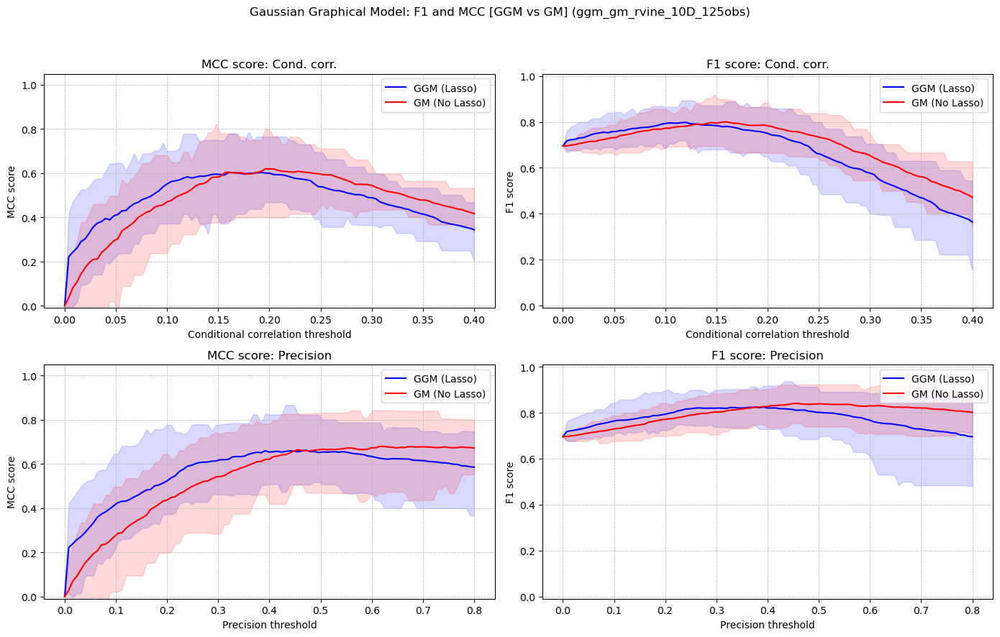

Conditional Corr (MCC): GGM better than GM in 37.5% of seeds (mean diff: -0.0084)
Conditional Corr (F1): GGM better than GM in 52.5% of seeds (mean diff: 0.0036)
Precision (MCC): GGM better than GM in 37.5% of seeds (mean diff: -0.0109)
Precision (F1): GGM better than GM in 35.0% of seeds (mean diff: -0.0072)


In [308]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_rvine_10D_125obs",
)

#### Normal 125

Processing seeds: 100%|██████████| 40/40 [00:07<00:00,  5.70it/s]


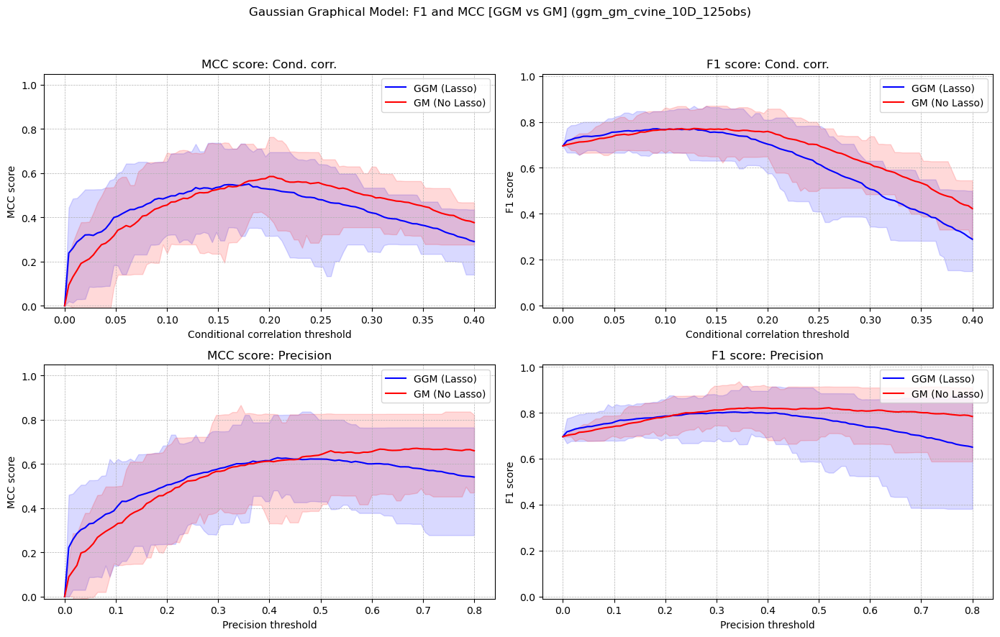

Conditional Corr (MCC): GGM better than GM in 27.5% of seeds (mean diff: -0.0167)
Conditional Corr (F1): GGM better than GM in 50.0% of seeds (mean diff: -0.0032)
Precision (MCC): GGM better than GM in 22.5% of seeds (mean diff: -0.0390)
Precision (F1): GGM better than GM in 27.5% of seeds (mean diff: -0.0219)


In [309]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_cvine_10D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:07<00:00,  5.66it/s]


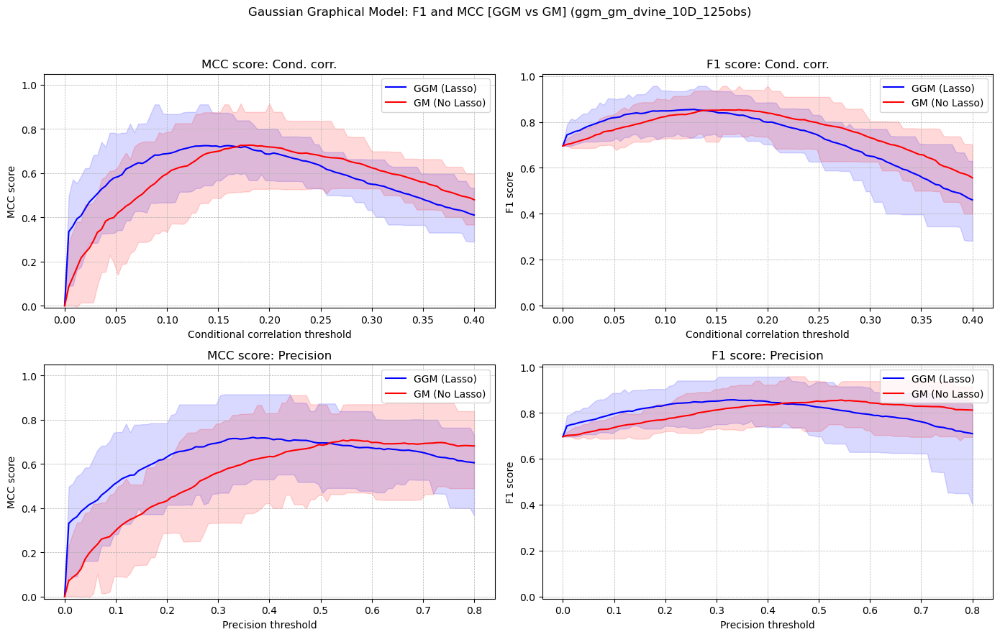

Conditional Corr (MCC): GGM better than GM in 40.0% of seeds (mean diff: 0.0041)
Conditional Corr (F1): GGM better than GM in 55.0% of seeds (mean diff: -0.0008)
Precision (MCC): GGM better than GM in 52.5% of seeds (mean diff: 0.0270)
Precision (F1): GGM better than GM in 52.5% of seeds (mean diff: 0.0041)


In [310]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_dvine_10D_125obs",
)

#### Normal 125obs 20D

Processing seeds: 100%|██████████| 40/40 [00:10<00:00,  3.79it/s]


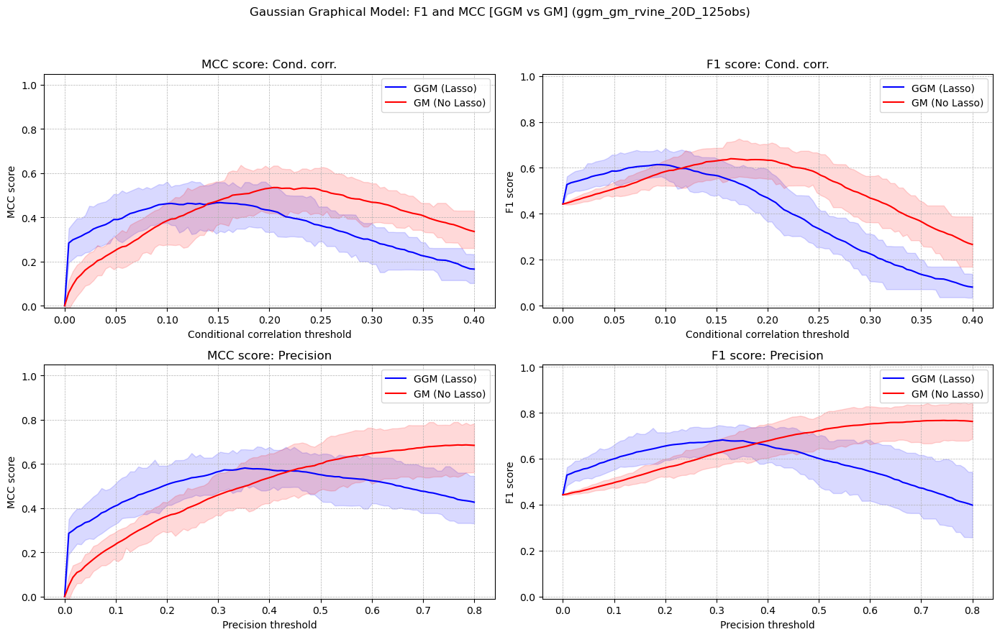

Conditional Corr (MCC): GGM better than GM in 22.5% of seeds (mean diff: -0.0567)
Conditional Corr (F1): GGM better than GM in 27.5% of seeds (mean diff: -0.0309)
Precision (MCC): GGM better than GM in 12.5% of seeds (mean diff: -0.0873)
Precision (F1): GGM better than GM in 5.0% of seeds (mean diff: -0.0803)


In [314]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_rvine_20D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:10<00:00,  3.85it/s]


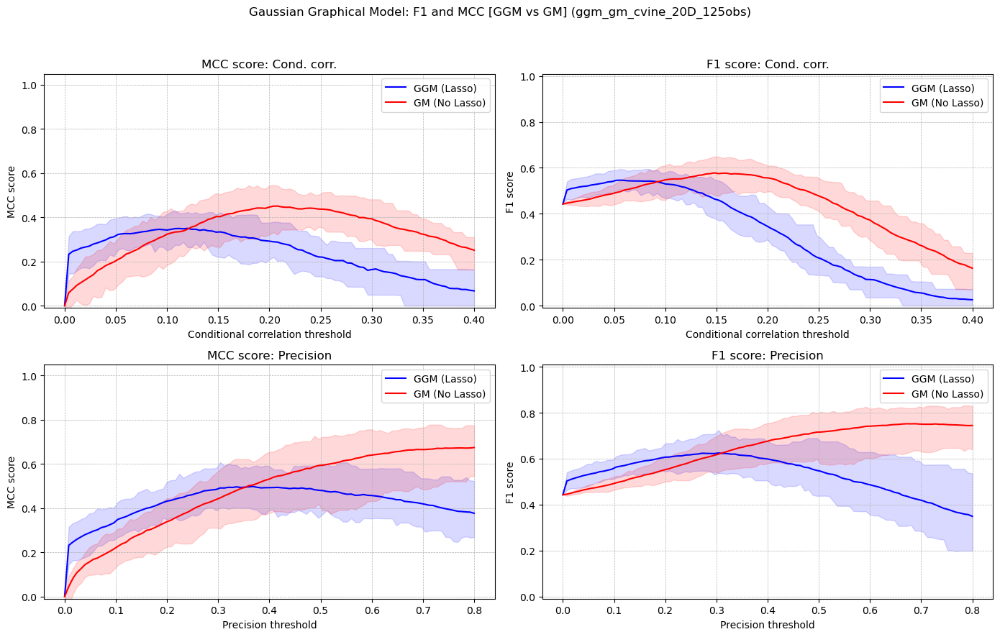

Conditional Corr (MCC): GGM better than GM in 0.0% of seeds (mean diff: -0.0975)
Conditional Corr (F1): GGM better than GM in 27.5% of seeds (mean diff: -0.0308)
Precision (MCC): GGM better than GM in 5.0% of seeds (mean diff: -0.1575)
Precision (F1): GGM better than GM in 5.0% of seeds (mean diff: -0.1190)


In [313]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_cvine_20D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:10<00:00,  3.88it/s]


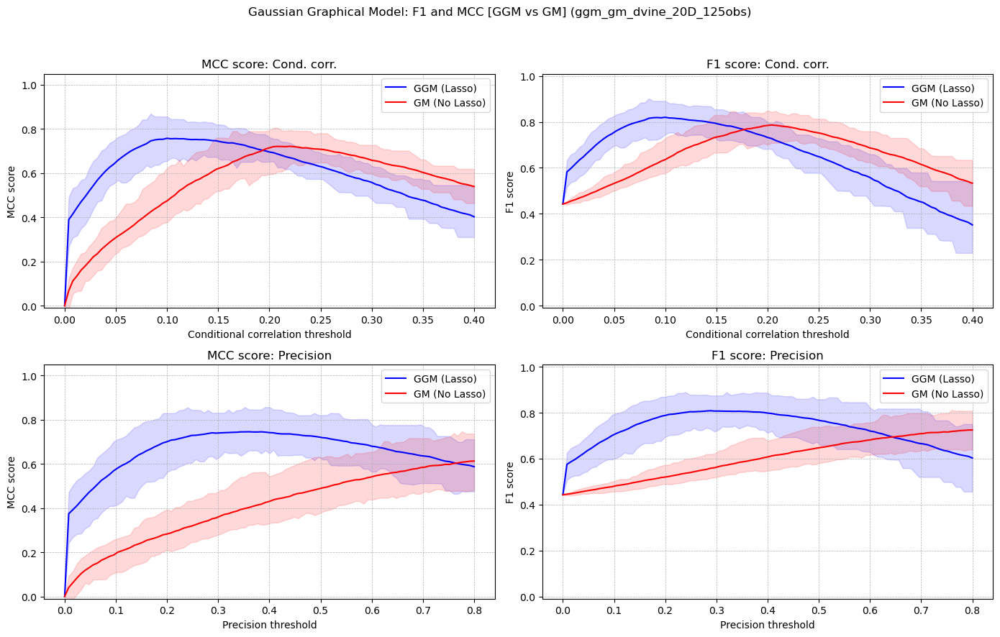

Conditional Corr (MCC): GGM better than GM in 67.5% of seeds (mean diff: 0.0446)
Conditional Corr (F1): GGM better than GM in 67.5% of seeds (mean diff: 0.0380)
Precision (MCC): GGM better than GM in 95.0% of seeds (mean diff: 0.1637)
Precision (F1): GGM better than GM in 92.5% of seeds (mean diff: 0.1058)


In [315]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_dvine_20D_125obs",
)

### Gaussonly Normal Results

#### 10D 125obs

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.40it/s]


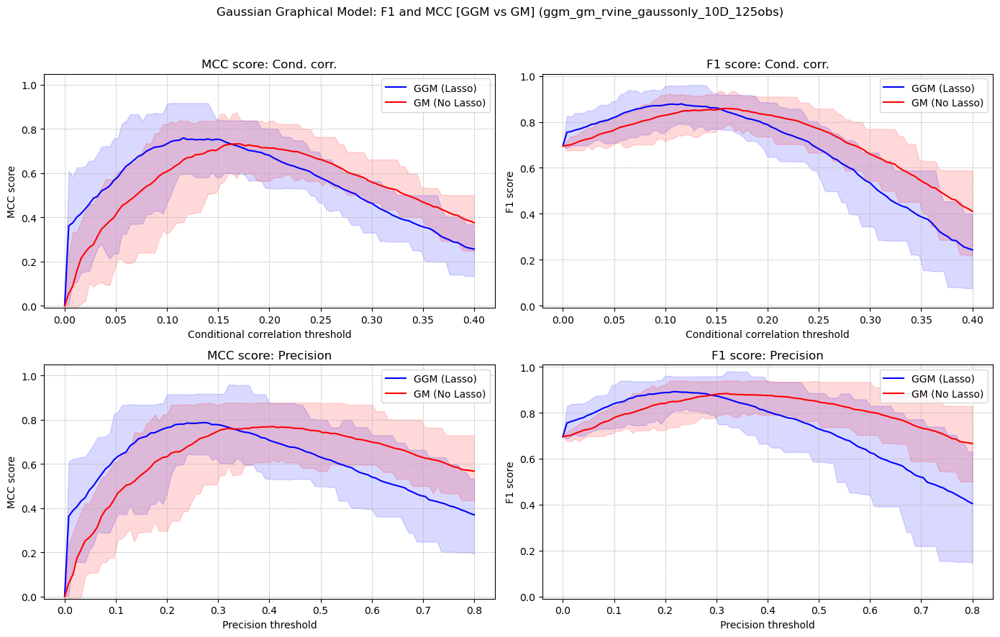

Conditional Corr (MCC): GGM better than GM in 67.5% of seeds (mean diff: 0.0312)
Conditional Corr (F1): GGM better than GM in 72.5% of seeds (mean diff: 0.0204)
Precision (MCC): GGM better than GM in 57.5% of seeds (mean diff: 0.0257)
Precision (F1): GGM better than GM in 67.5% of seeds (mean diff: 0.0137)


In [318]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_rvine_gaussonly_10D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:12<00:00,  3.10it/s]


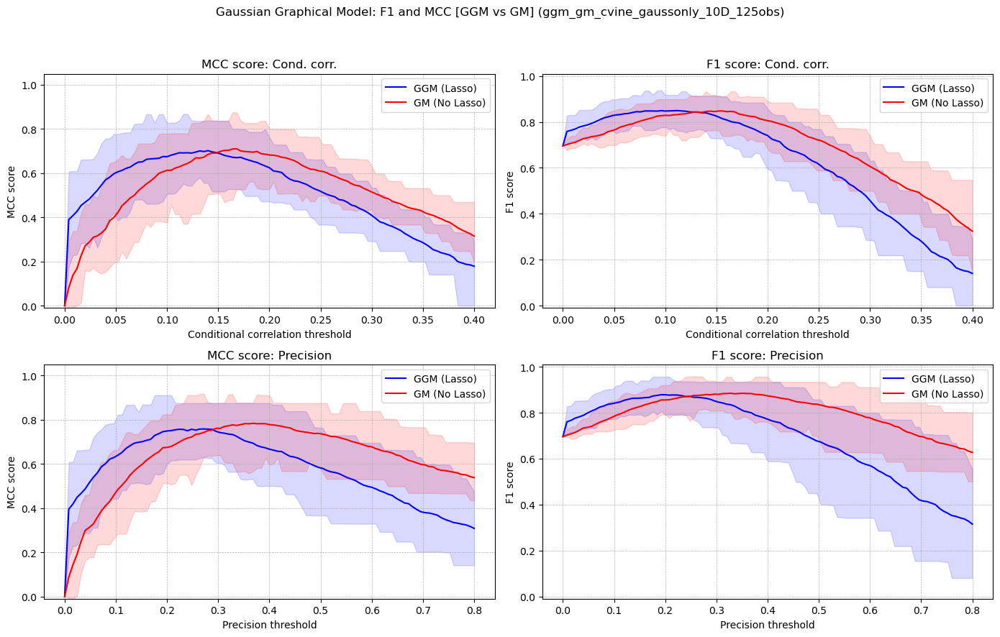

Conditional Corr (MCC): GGM better than GM in 55.0% of seeds (mean diff: 0.0033)
Conditional Corr (F1): GGM better than GM in 57.5% of seeds (mean diff: 0.0068)
Precision (MCC): GGM better than GM in 37.5% of seeds (mean diff: -0.0069)
Precision (F1): GGM better than GM in 45.0% of seeds (mean diff: -0.0001)


In [316]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_cvine_gaussonly_10D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:12<00:00,  3.15it/s]


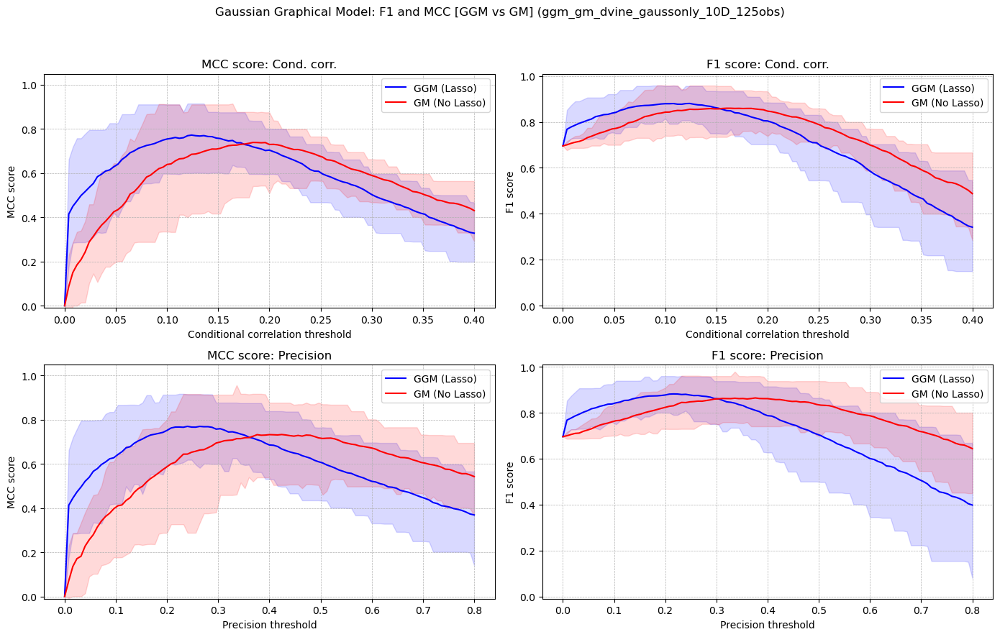

Conditional Corr (MCC): GGM better than GM in 52.5% of seeds (mean diff: 0.0275)
Conditional Corr (F1): GGM better than GM in 55.0% of seeds (mean diff: 0.0152)
Precision (MCC): GGM better than GM in 55.0% of seeds (mean diff: 0.0318)
Precision (F1): GGM better than GM in 55.0% of seeds (mean diff: 0.0162)


In [317]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_dvine_gaussonly_10D_125obs",
)

#### 10D 500obs

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.39it/s]


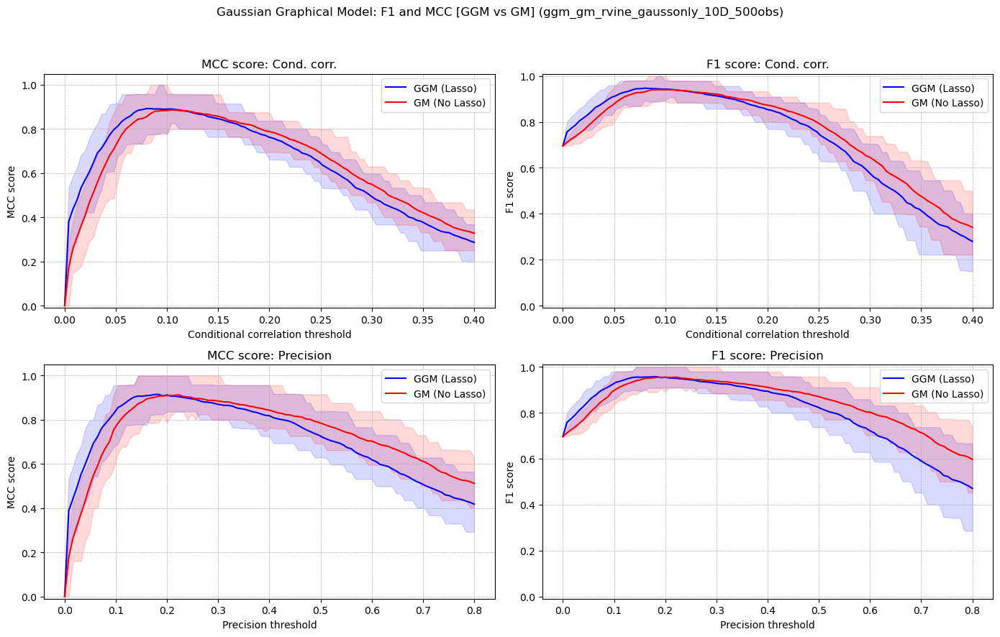

Conditional Corr (MCC): GGM better than GM in 35.0% of seeds (mean diff: 0.0062)
Conditional Corr (F1): GGM better than GM in 45.0% of seeds (mean diff: 0.0038)
Precision (MCC): GGM better than GM in 30.0% of seeds (mean diff: 0.0014)
Precision (F1): GGM better than GM in 25.0% of seeds (mean diff: 0.0006)


In [319]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_rvine_gaussonly_10D_500obs",
)

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.56it/s]


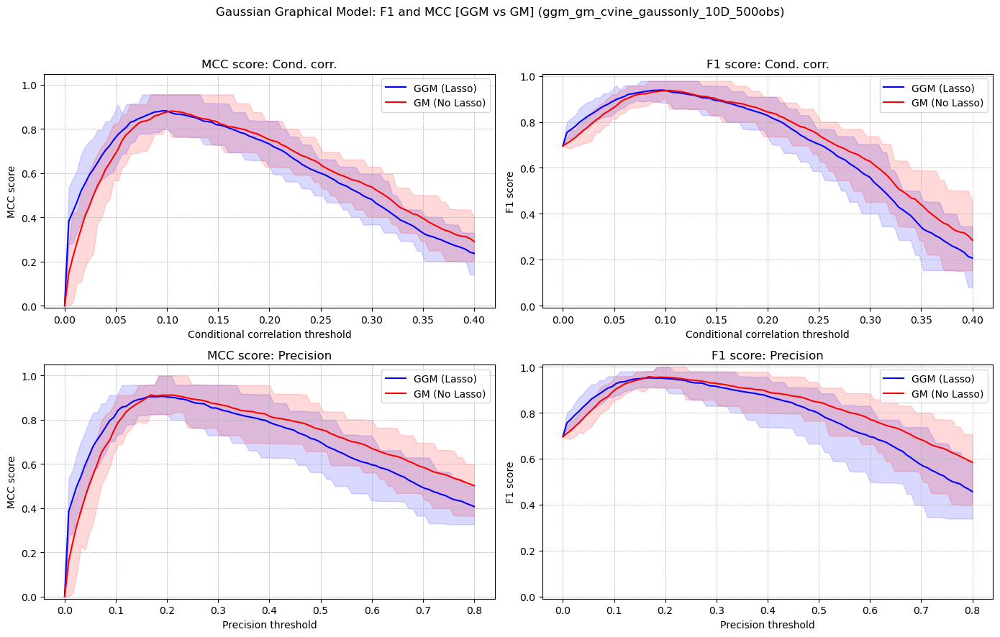

Conditional Corr (MCC): GGM better than GM in 37.5% of seeds (mean diff: 0.0069)
Conditional Corr (F1): GGM better than GM in 42.5% of seeds (mean diff: 0.0041)
Precision (MCC): GGM better than GM in 20.0% of seeds (mean diff: -0.0030)
Precision (F1): GGM better than GM in 25.0% of seeds (mean diff: -0.0016)


In [320]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_cvine_gaussonly_10D_500obs",
)

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.38it/s]


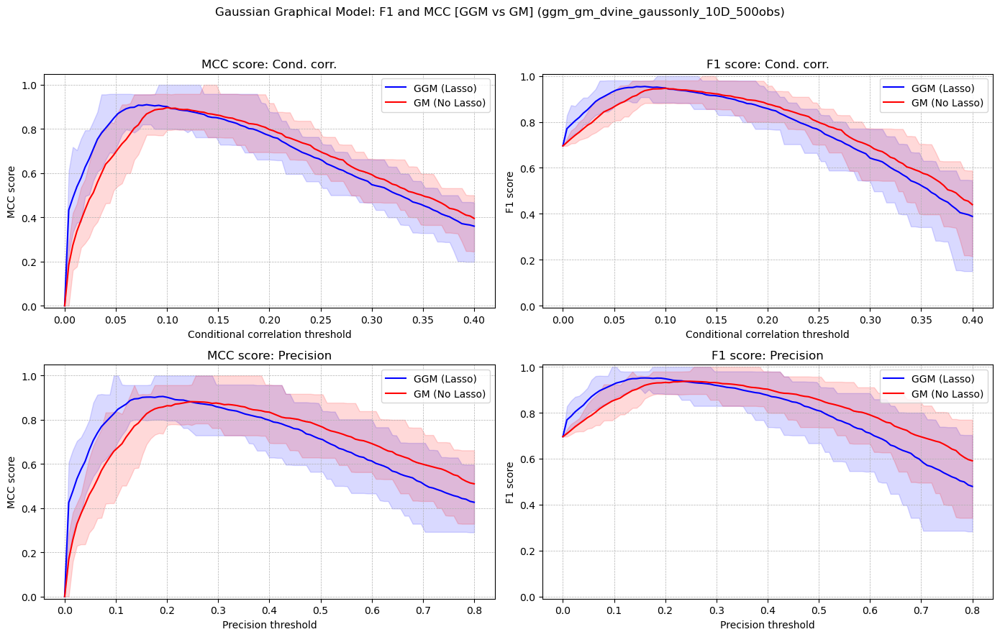

Conditional Corr (MCC): GGM better than GM in 35.0% of seeds (mean diff: 0.0180)
Conditional Corr (F1): GGM better than GM in 40.0% of seeds (mean diff: 0.0102)
Precision (MCC): GGM better than GM in 50.0% of seeds (mean diff: 0.0274)
Precision (F1): GGM better than GM in 50.0% of seeds (mean diff: 0.0140)


In [321]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_dvine_gaussonly_10D_500obs",
)

#### 20D 125obs

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.46it/s]


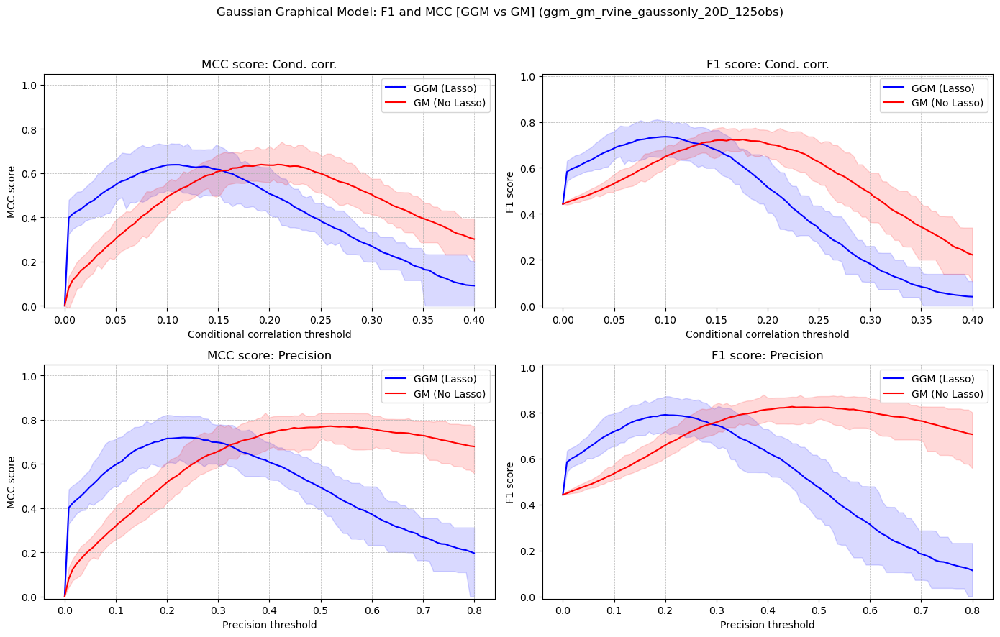

Conditional Corr (MCC): GGM better than GM in 55.0% of seeds (mean diff: -0.0050)
Conditional Corr (F1): GGM better than GM in 62.5% of seeds (mean diff: 0.0060)
Precision (MCC): GGM better than GM in 27.5% of seeds (mean diff: -0.0479)
Precision (F1): GGM better than GM in 27.5% of seeds (mean diff: -0.0355)


In [322]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_rvine_gaussonly_20D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.53it/s]


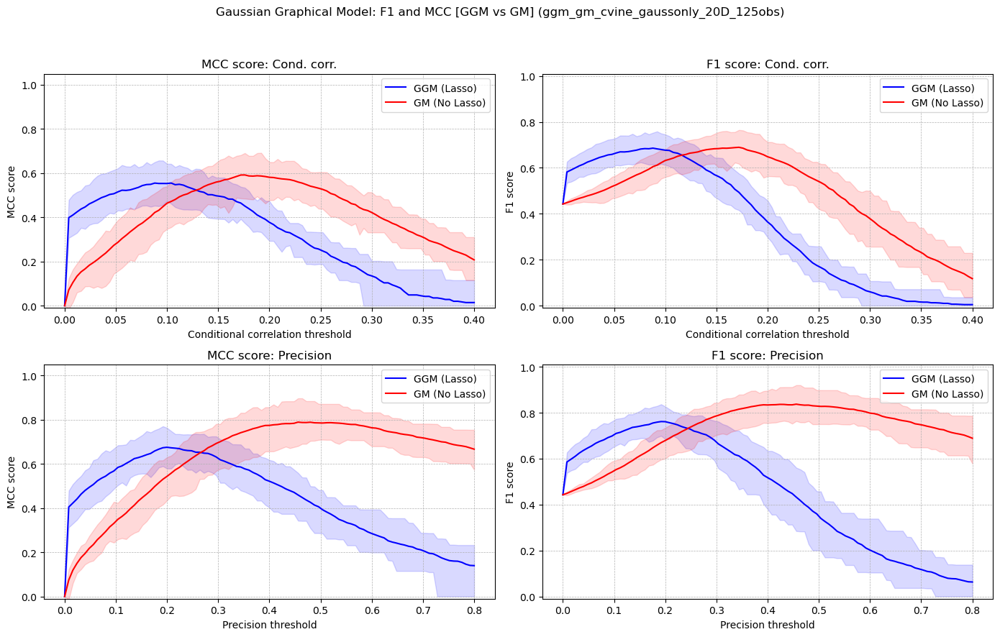

Conditional Corr (MCC): GGM better than GM in 37.5% of seeds (mean diff: -0.0325)
Conditional Corr (F1): GGM better than GM in 55.0% of seeds (mean diff: -0.0002)
Precision (MCC): GGM better than GM in 2.5% of seeds (mean diff: -0.1119)
Precision (F1): GGM better than GM in 10.0% of seeds (mean diff: -0.0770)


In [323]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_cvine_gaussonly_20D_125obs",
)

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.61it/s]


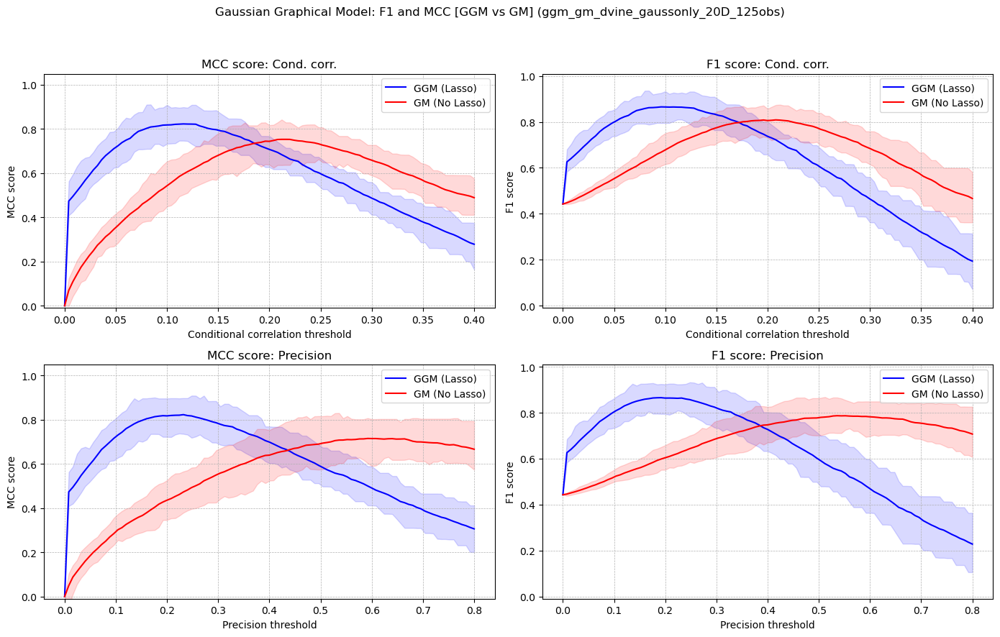

Conditional Corr (MCC): GGM better than GM in 92.5% of seeds (mean diff: 0.0682)
Conditional Corr (F1): GGM better than GM in 90.0% of seeds (mean diff: 0.0553)
Precision (MCC): GGM better than GM in 95.0% of seeds (mean diff: 0.0921)
Precision (F1): GGM better than GM in 90.0% of seeds (mean diff: 0.0697)


In [324]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_dvine_gaussonly_20D_125obs",
)

#### 20D 500obs

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.40it/s]


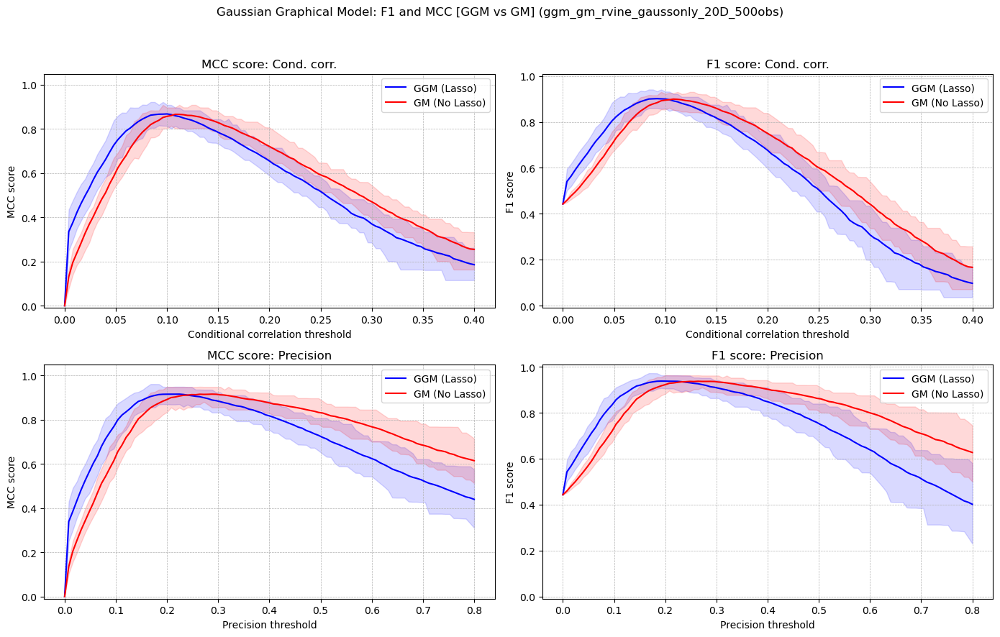

Conditional Corr (MCC): GGM better than GM in 60.0% of seeds (mean diff: 0.0041)
Conditional Corr (F1): GGM better than GM in 65.0% of seeds (mean diff: 0.0039)
Precision (MCC): GGM better than GM in 27.5% of seeds (mean diff: 0.0004)
Precision (F1): GGM better than GM in 37.5% of seeds (mean diff: 0.0001)


In [325]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_rvine_gaussonly_20D_500obs",
)

Processing seeds: 100%|██████████| 40/40 [00:11<00:00,  3.51it/s]


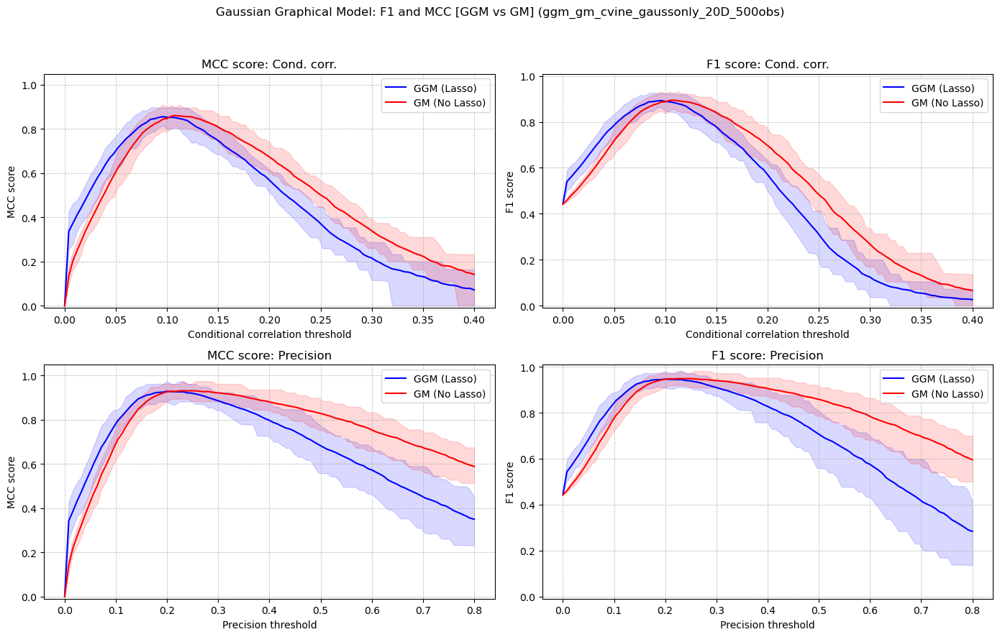

Conditional Corr (MCC): GGM better than GM in 42.5% of seeds (mean diff: -0.0021)
Conditional Corr (F1): GGM better than GM in 47.5% of seeds (mean diff: -0.0000)
Precision (MCC): GGM better than GM in 42.5% of seeds (mean diff: -0.0013)
Precision (F1): GGM better than GM in 45.0% of seeds (mean diff: -0.0009)


In [326]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_cvine_gaussonly_20D_500obs",
)

Processing seeds: 100%|██████████| 40/40 [00:10<00:00,  3.69it/s]


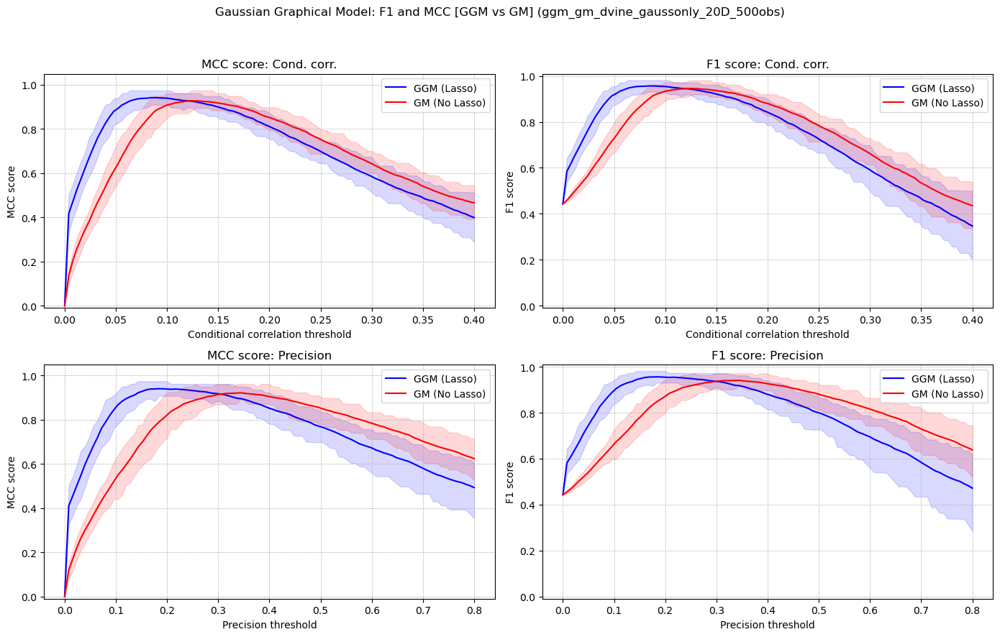

Conditional Corr (MCC): GGM better than GM in 70.0% of seeds (mean diff: 0.0139)
Conditional Corr (F1): GGM better than GM in 72.5% of seeds (mean diff: 0.0106)
Precision (MCC): GGM better than GM in 80.0% of seeds (mean diff: 0.0210)
Precision (F1): GGM better than GM in 85.0% of seeds (mean diff: 0.0159)


In [327]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# Example usage:
summary_df = evaluate_gaussian_vs_gm_scores_all(
    experiment_name="ggm_gm_dvine_gaussonly_20D_500obs",
)

#### AUC on Gaussian Data

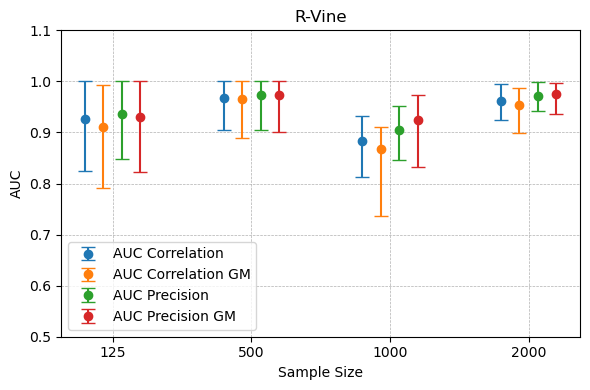

In [348]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125 : "ggm_gm_rvine_gaussonly_10D_125obs",
    500 : "ggm_gm_rvine_gaussonly_10D_500obs",
    1000 : "ggm_gm_rvine_gaussonly_20D_125obs",
    2000 : "ggm_gm_rvine_gaussonly_20D_500obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.1,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine",
    legend          = True,
)


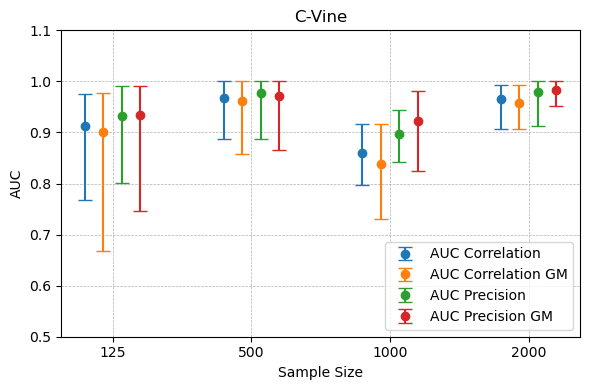

In [349]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125 : "ggm_gm_cvine_gaussonly_10D_125obs",
    500 : "ggm_gm_cvine_gaussonly_10D_500obs",
    1000 : "ggm_gm_cvine_gaussonly_20D_125obs",
    2000 : "ggm_gm_cvine_gaussonly_20D_500obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.1,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine",
    legend          = True,
)


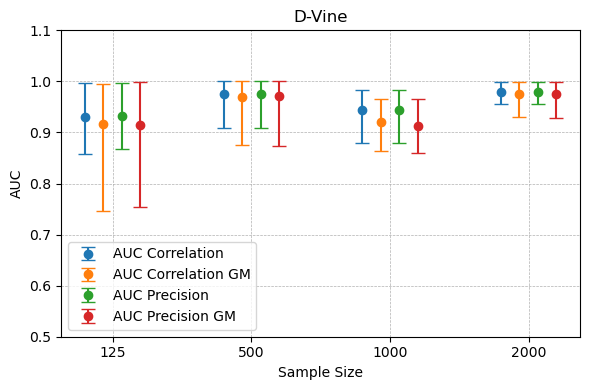

In [352]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125 : "ggm_gm_dvine_gaussonly_10D_125obs",
    500 : "ggm_gm_dvine_gaussonly_10D_500obs",
    1000 : "ggm_gm_dvine_gaussonly_20D_125obs",
    2000 : "ggm_gm_dvine_gaussonly_20D_500obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_c_gm", 
               "metrics.auc_p", "metrics.auc_p_gm"
               ]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Correlation GM", "AUC Precision", "AUC Precision GM"],
    #colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 0,
    upper_quantile  = 100,
    y_min           = 0.5,
    y_max           = 1.1,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine",
    legend          = True,
)


# Check max penalties

Conclusion: 
- For 10D we are already some times at the border also for the lasso, that is okay however as its not to concentrated.
- For 20 and 50D and 100D seems clear we need to increase penalty max for all three penalties

In [34]:
import matplotlib.pyplot as plt

In [35]:
def get_plot_penalties_from_experiment(experiment_name, adapt2=False):

    experiment = mlflow.get_experiment_by_name(experiment_name)
    runs_df_all = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
    
    runs_df = _filter_runs(runs_df_all, name_look_for="No", name_not_look_for_list=["Adaptive","Lasso"], seed_min=0, seed_max=100)
    pen_values_first = runs_df["params.penalty_decorrelation_ridge_first_difference_chosen"].values.astype(float)
    pen_values_second = runs_df["params.penalty_decorrelation_ridge_second_difference_chosen"].values.astype(float)
    plt.scatter(pen_values_first, pen_values_second)
    plt.xlabel("penalty_lasso_conditional_independence")
    plt.ylabel("penalty_decorrelation_ridge_second")
    plt.title(f"Penalty values for experiment: {experiment_name} No Lasso")
    plt.tight_layout()
    plt.show()
    
    runs_df = _filter_runs(runs_df_all, name_look_for="Adaptive", name_not_look_for_list=["No","Lasso"], seed_min=0, seed_max=100)

    # Assuming these are numpy arrays of same length
    pen_values_first = runs_df["params.penalty_decorrelation_ridge_first_difference_chosen"].values.astype(float)
    pen_values_second = runs_df["params.penalty_decorrelation_ridge_second_difference_chosen"].values.astype(float)
    pen_values_lasso = runs_df["params.penalty_lasso_conditional_independence_chosen"].values.astype(float)
    
    fig, axs = plt.subplots(2,2, figsize=(9,9))

    # (0,1): first vs. second
    axs[0, 1].scatter(pen_values_first, pen_values_second, alpha=0.7)
    axs[0, 1].set_xlabel("penalty_decorrelation_ridge_first")
    axs[0, 1].set_ylabel("penalty_decorrelation_ridge_second")

    # (1,0): lasso vs. first
    axs[1, 0].scatter(pen_values_lasso, pen_values_first, alpha=0.7)
    axs[1, 0].set_xlabel("penalty_lasso_conditional_independence")
    axs[1, 0].set_ylabel("penalty_decorrelation_ridge_first")

    # (1,1): lasso vs. second
    axs[1, 1].scatter(pen_values_lasso, pen_values_second, alpha=0.7)
    axs[1, 1].set_xlabel("penalty_lasso_conditional_independence")
    axs[1, 1].set_ylabel("penalty_decorrelation_ridge_second")

    # (0,0): leave blank or annotate
    axs[0,0].axis('off')
    axs[0,0].text(0.5, 0.5, 'Penalty Grid\nScatter Plots', ha='center', va='center', fontsize=13)
    plt.suptitle(f"Penalty values for experiment: {experiment_name} Adaptive Lasso")
    plt.tight_layout()
    plt.show()
    
    if adapt2 == True:
        runs_df = _filter_runs(runs_df_all, name_look_for="Adapt2", name_not_look_for_list=["No","Lasso"], seed_min=0, seed_max=100)
        # Assuming these are numpy arrays of same length
        pen_values_first = runs_df["params.penalty_decorrelation_ridge_first_difference_chosen"].values.astype(float)
        pen_values_second = runs_df["params.penalty_decorrelation_ridge_second_difference_chosen"].values.astype(float)
        pen_values_lasso = runs_df["params.penalty_lasso_conditional_independence_chosen"].values.astype(float)
        
        fig, axs = plt.subplots(2,2, figsize=(9,9))

        # (0,1): first vs. second
        axs[0, 1].scatter(pen_values_first, pen_values_second, alpha=0.7)
        axs[0, 1].set_xlabel("penalty_decorrelation_ridge_first")
        axs[0, 1].set_ylabel("penalty_decorrelation_ridge_second")

        # (1,0): lasso vs. first
        axs[1, 0].scatter(pen_values_lasso, pen_values_first, alpha=0.7)
        axs[1, 0].set_xlabel("penalty_lasso_conditional_independence")
        axs[1, 0].set_ylabel("penalty_decorrelation_ridge_first")

        # (1,1): lasso vs. second
        axs[1, 1].scatter(pen_values_lasso, pen_values_second, alpha=0.7)
        axs[1, 1].set_xlabel("penalty_lasso_conditional_independence")
        axs[1, 1].set_ylabel("penalty_decorrelation_ridge_second")

        # (0,0): leave blank or annotate
        axs[0,0].axis('off')
        axs[0,0].text(0.5, 0.5, 'Penalty Grid\nScatter Plots', ha='center', va='center', fontsize=13)
        plt.suptitle(f"Penalty values for experiment: {experiment_name} Adaptive Lasso")
        plt.tight_layout()
        plt.show()
            


## R-Vine

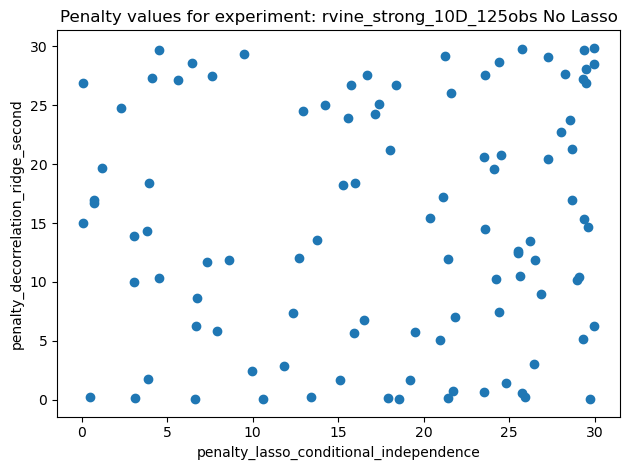

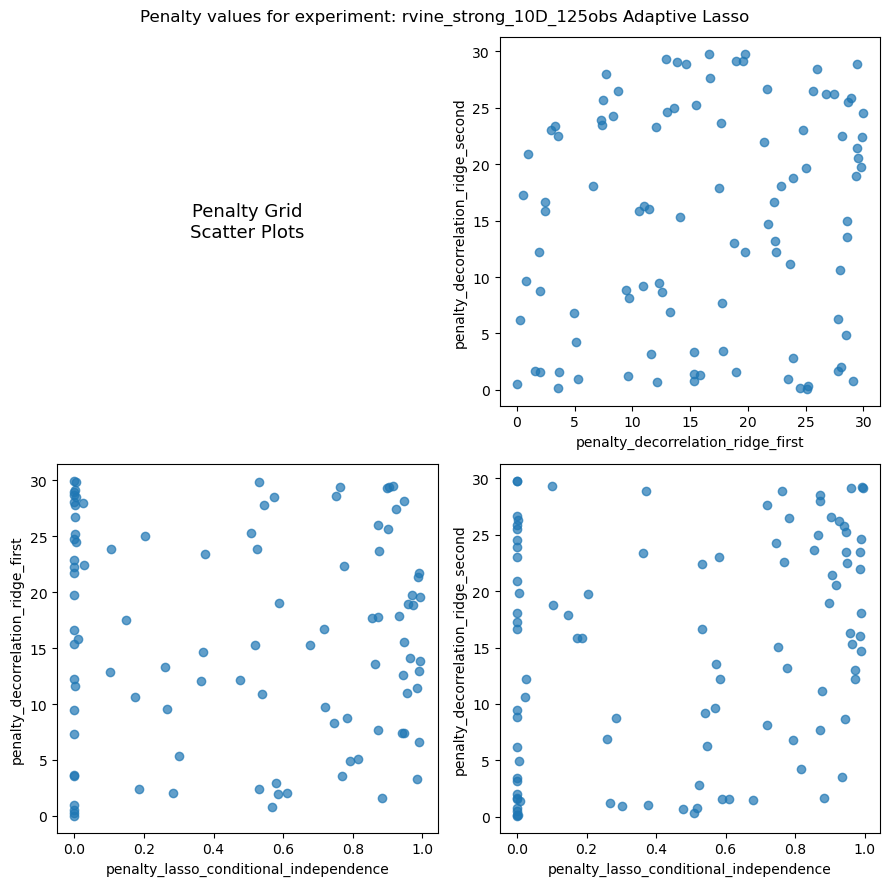

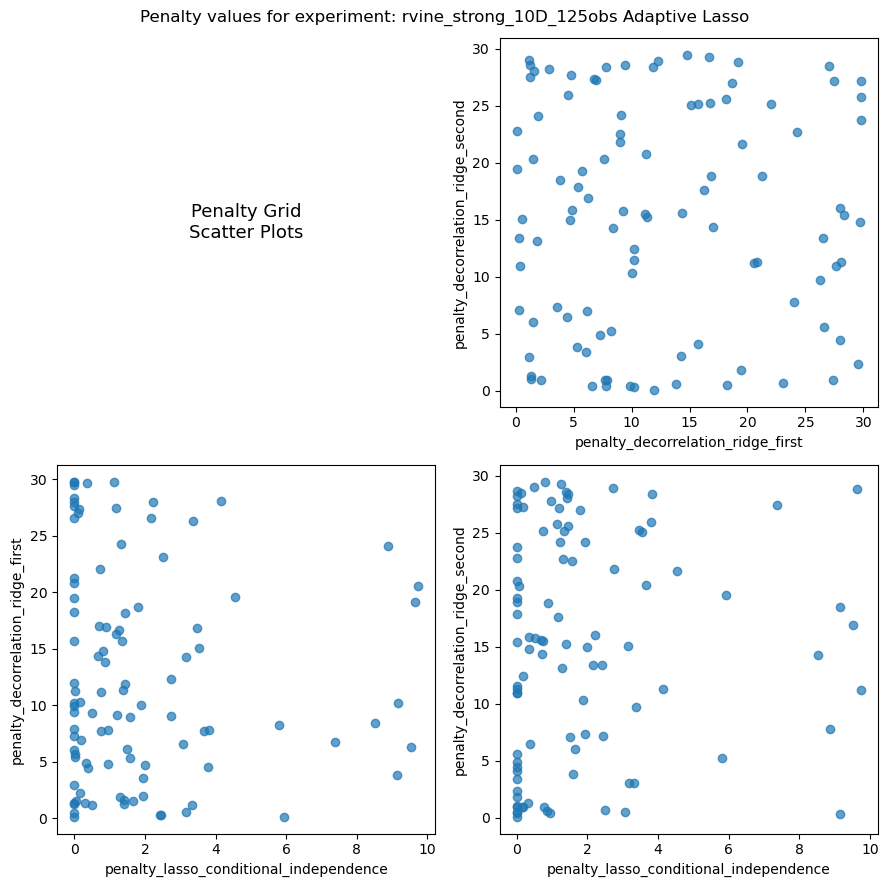

In [124]:
get_plot_penalties_from_experiment("rvine_strong_10D_125obs", adapt2=True)

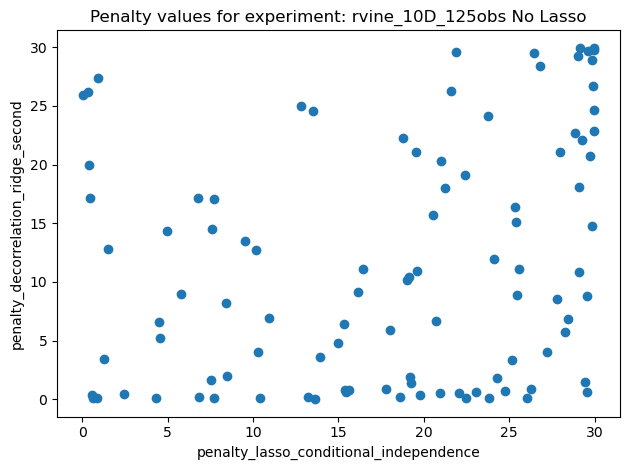

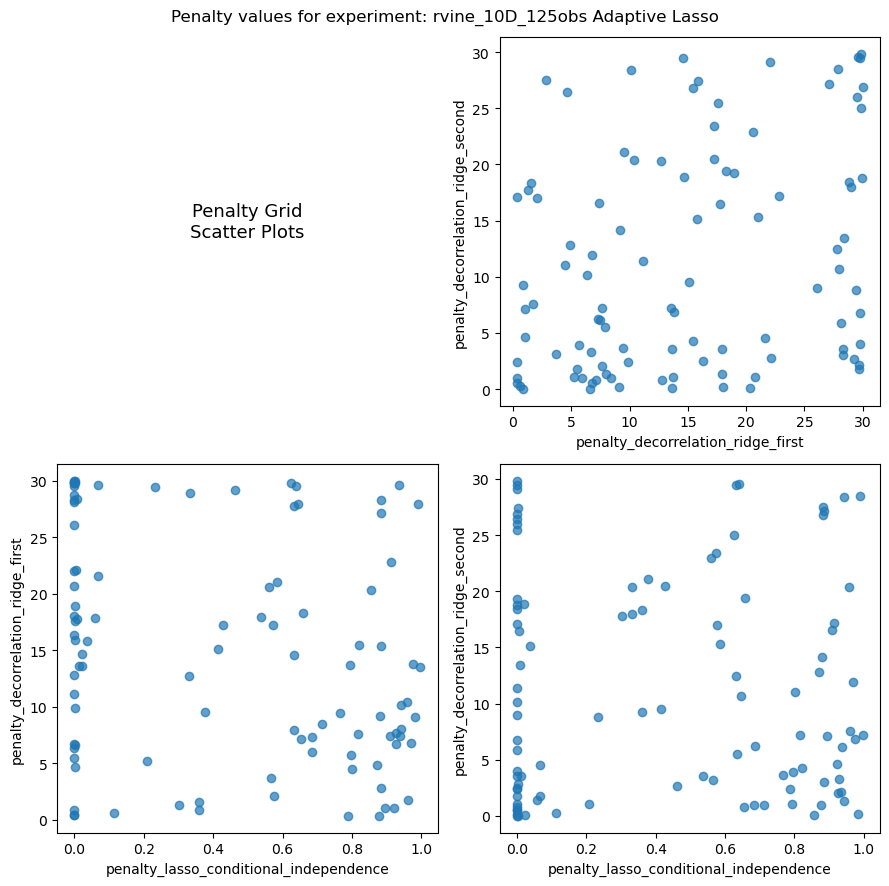

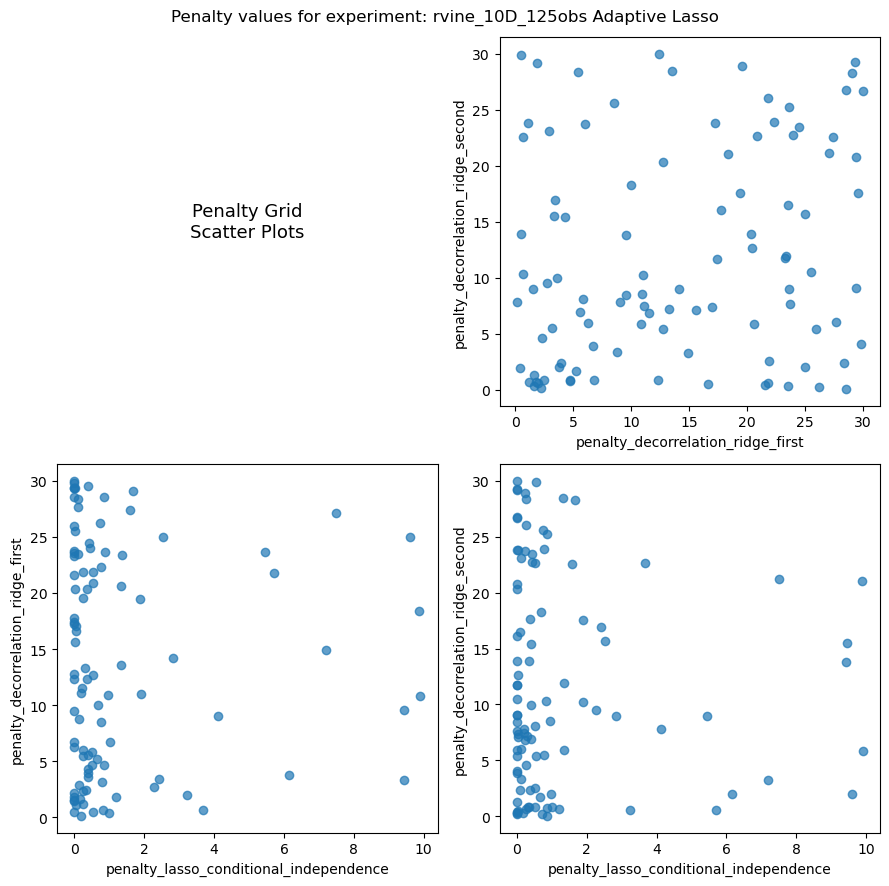

In [125]:
get_plot_penalties_from_experiment("rvine_10D_125obs", adapt2=True)

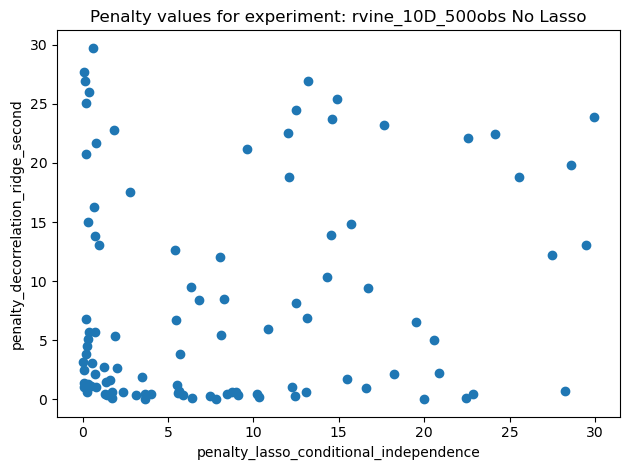

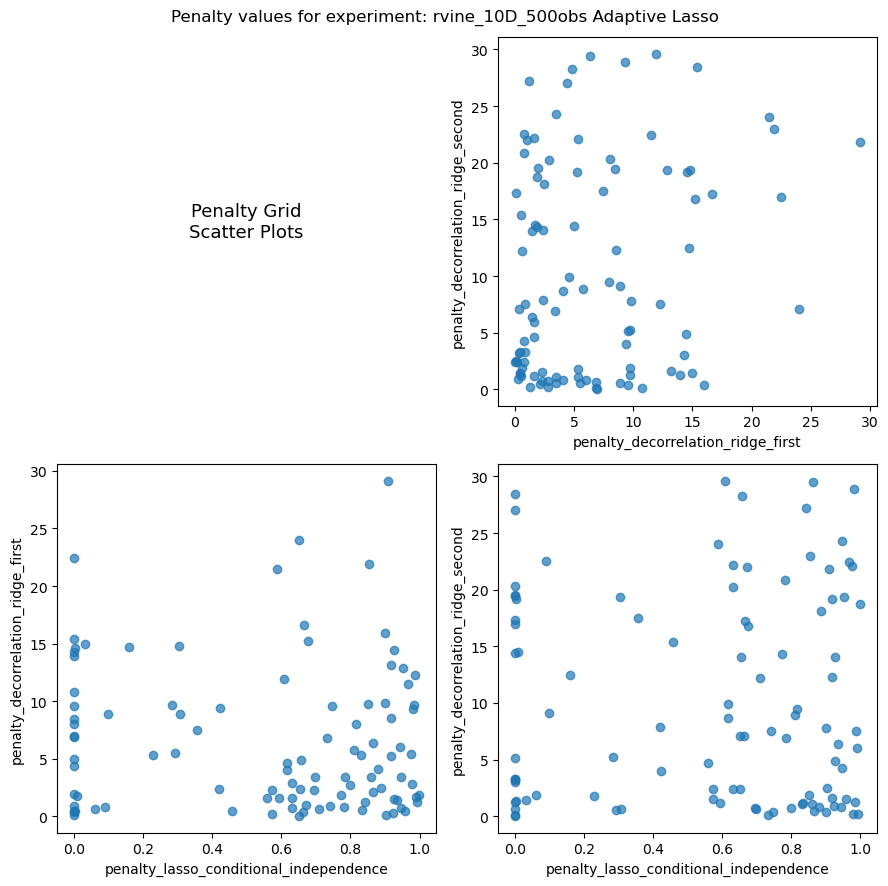

In [65]:
get_plot_penalties_from_experiment("rvine_10D_500obs")

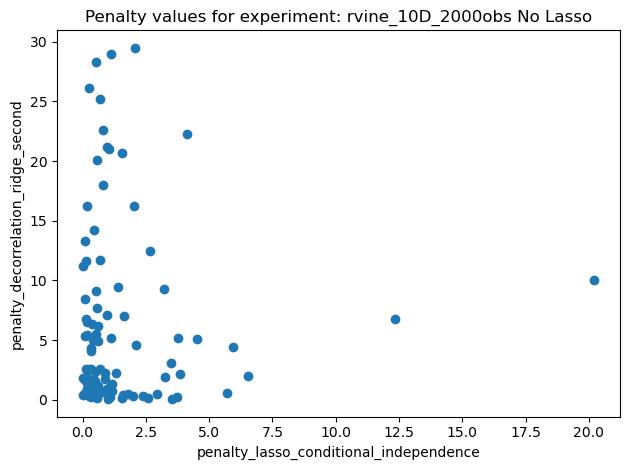

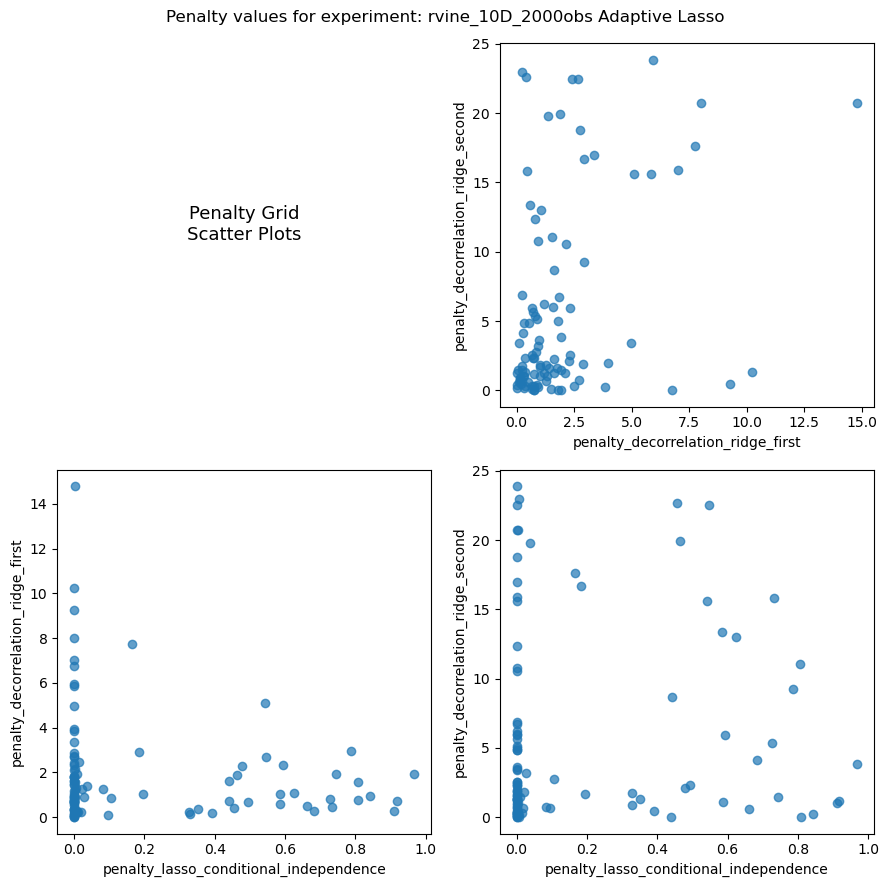

In [66]:
get_plot_penalties_from_experiment("rvine_10D_2000obs")

### higher dims

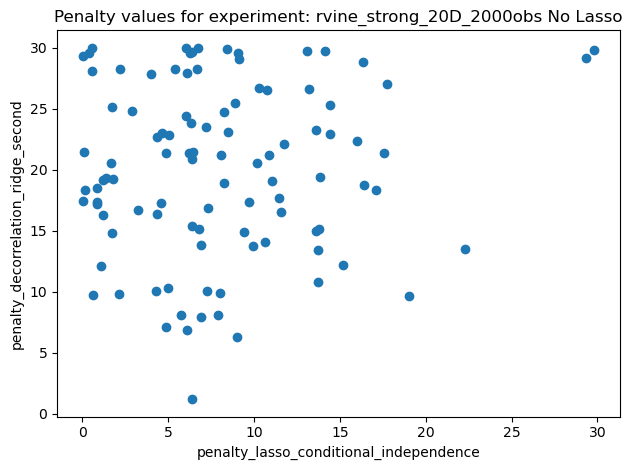

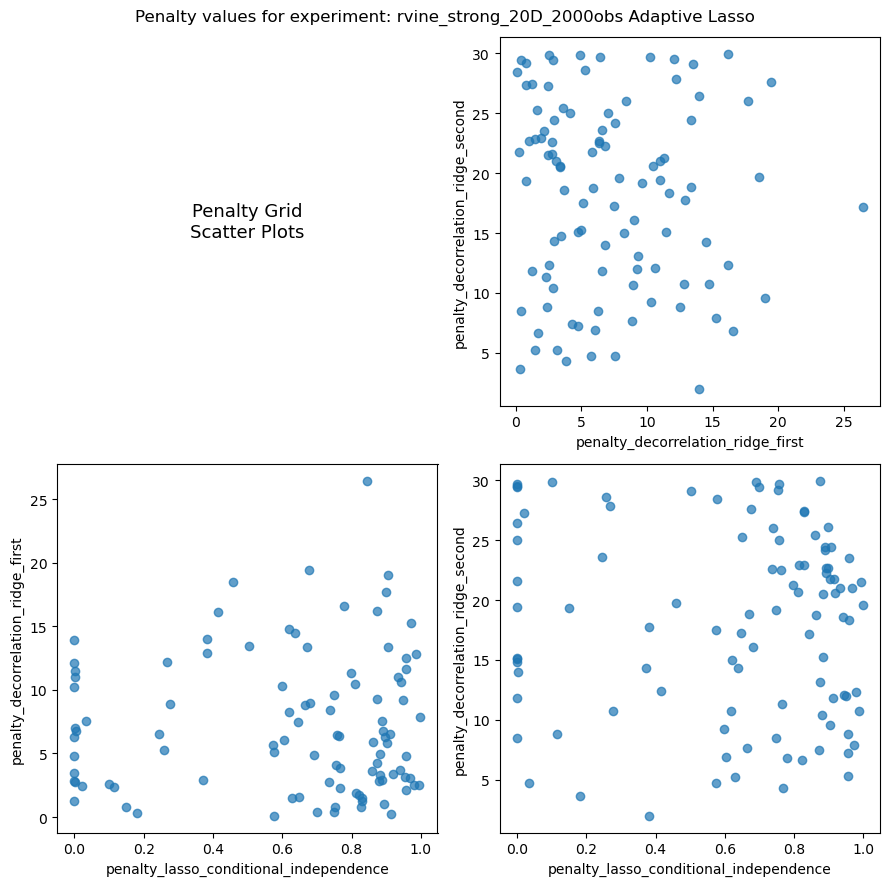

In [36]:
get_plot_penalties_from_experiment("rvine_strong_20D_2000obs")

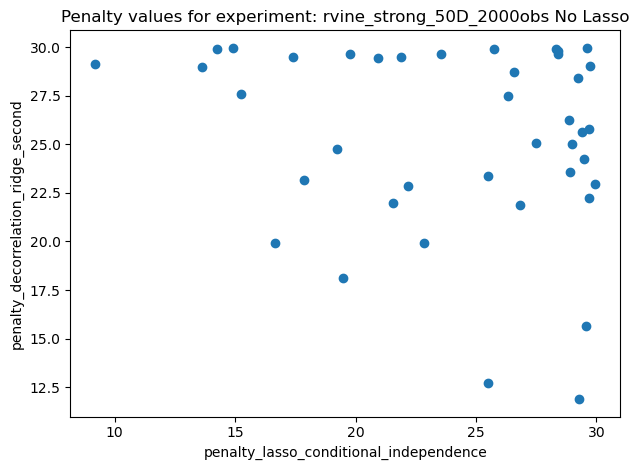

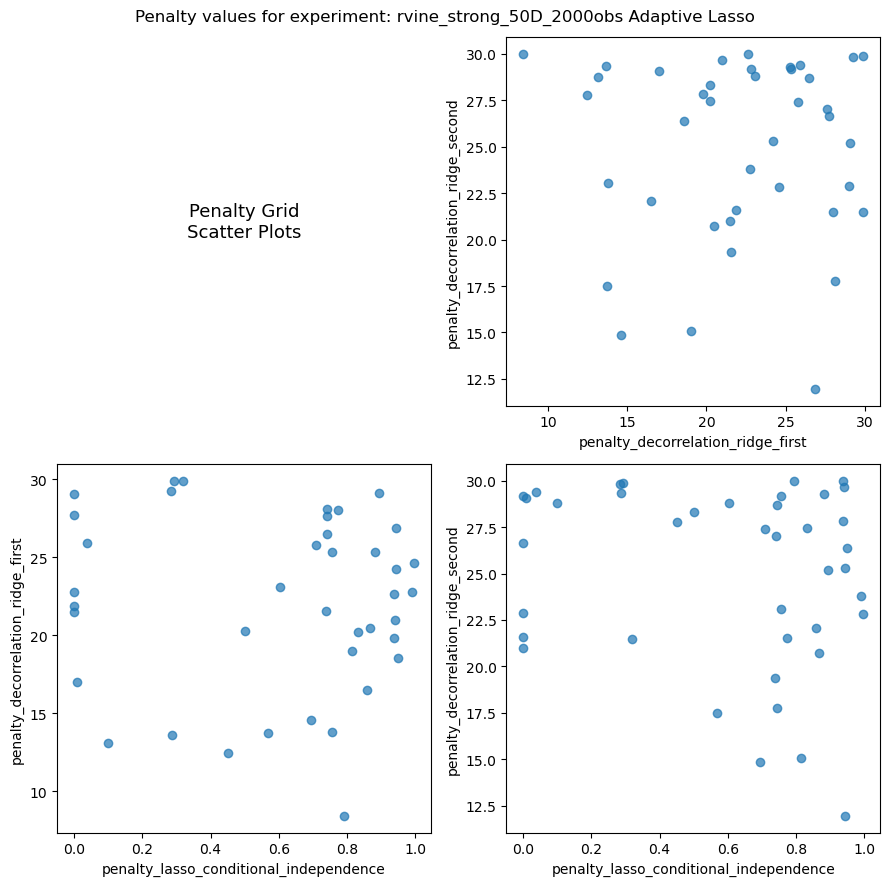

In [39]:
get_plot_penalties_from_experiment("rvine_strong_50D_2000obs")

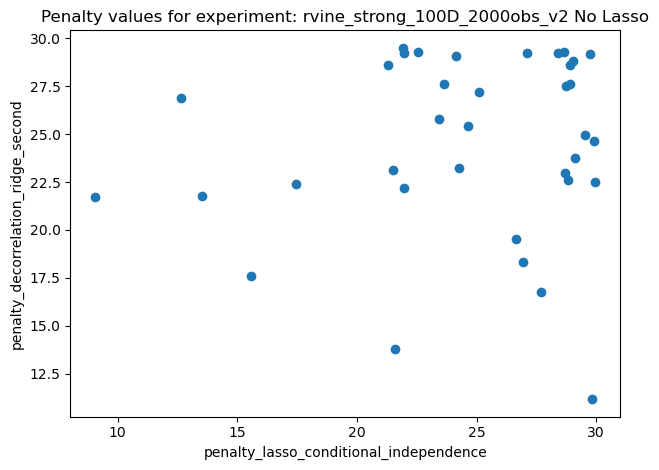

KeyError: 'params.penalty_decorrelation_ridge_first_difference_chosen'

In [41]:
get_plot_penalties_from_experiment("rvine_strong_100D_2000obs_v2")

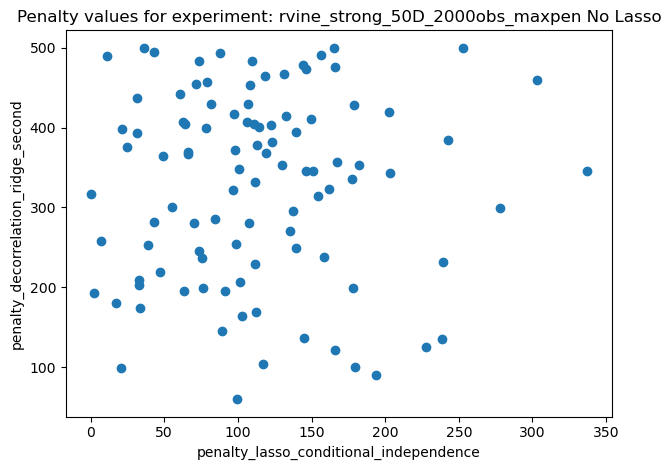

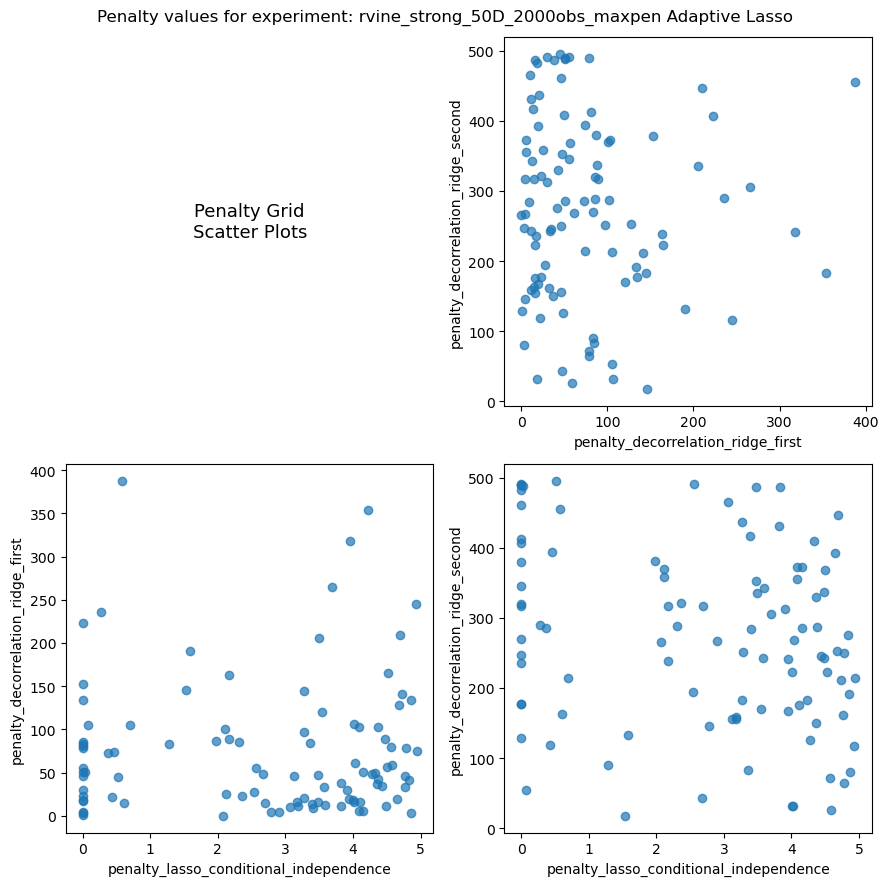

In [137]:
get_plot_penalties_from_experiment("rvine_strong_50D_2000obs_maxpen")

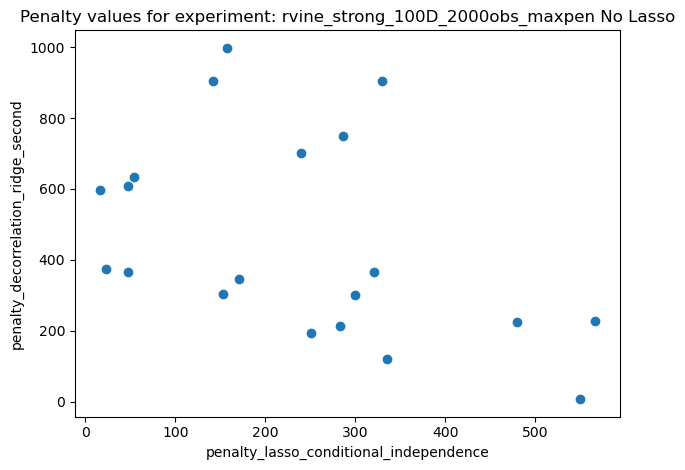

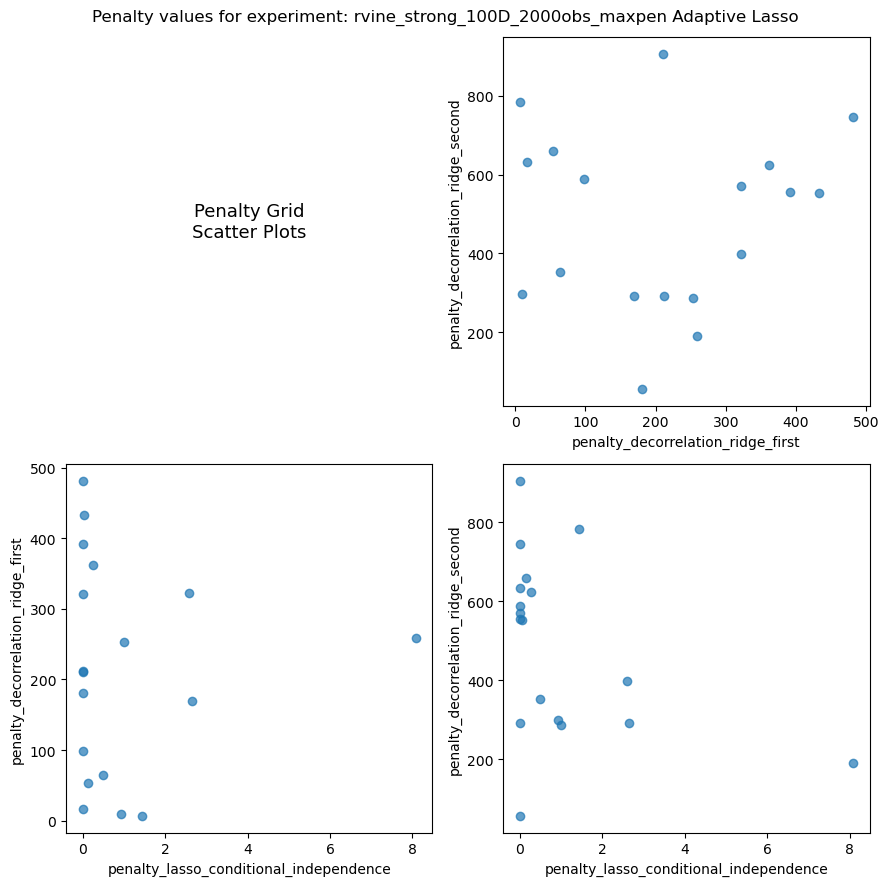

In [139]:
get_plot_penalties_from_experiment("rvine_strong_100D_2000obs_maxpen")

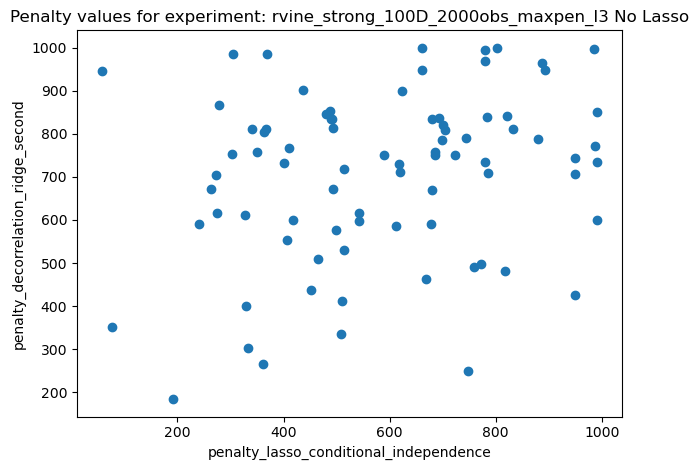

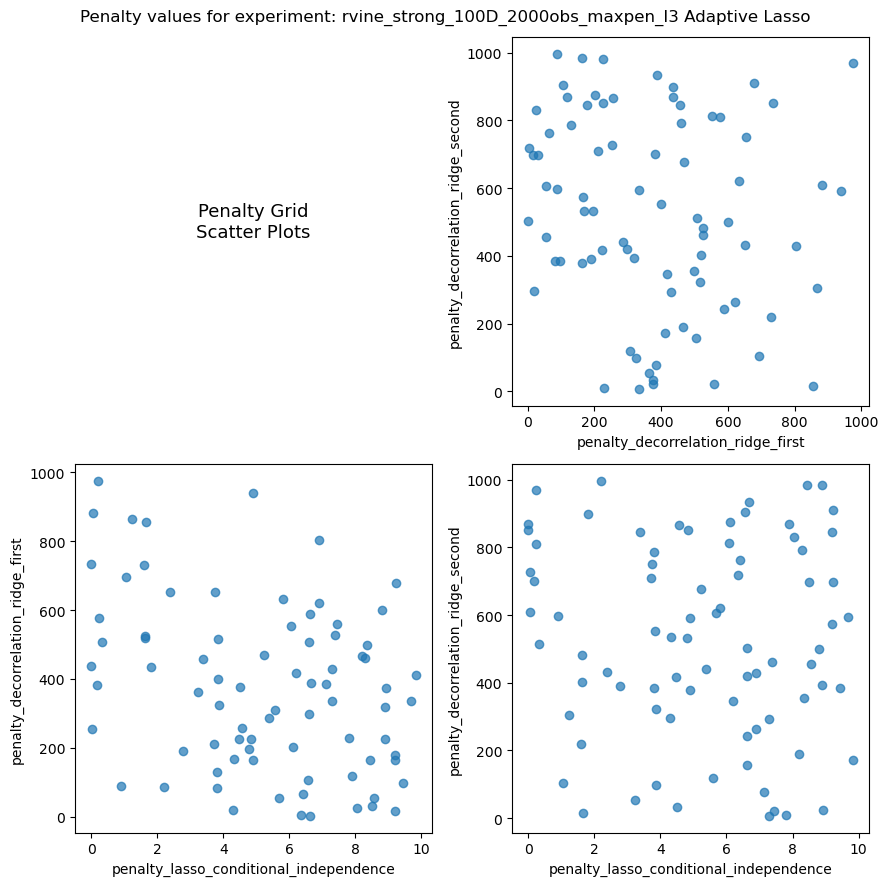

In [192]:
get_plot_penalties_from_experiment("rvine_strong_100D_2000obs_maxpen_I3")

## C-Vine

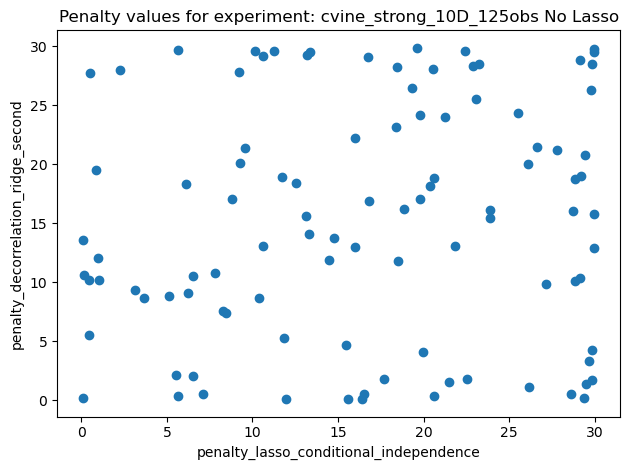

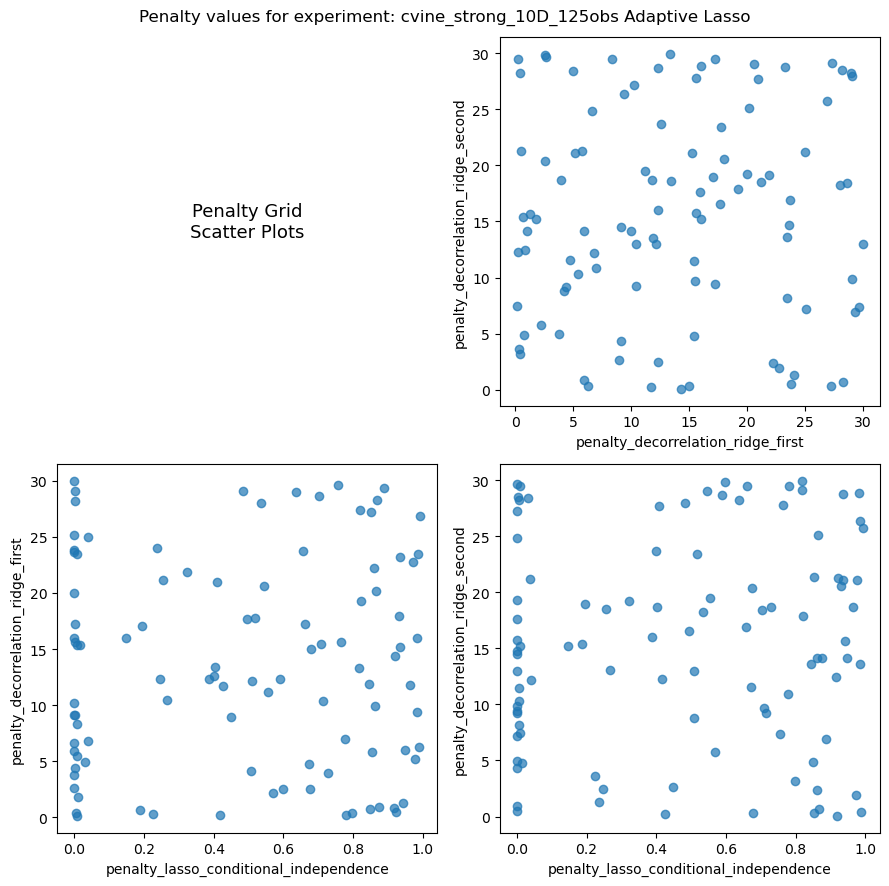

In [126]:
get_plot_penalties_from_experiment("cvine_strong_10D_125obs")

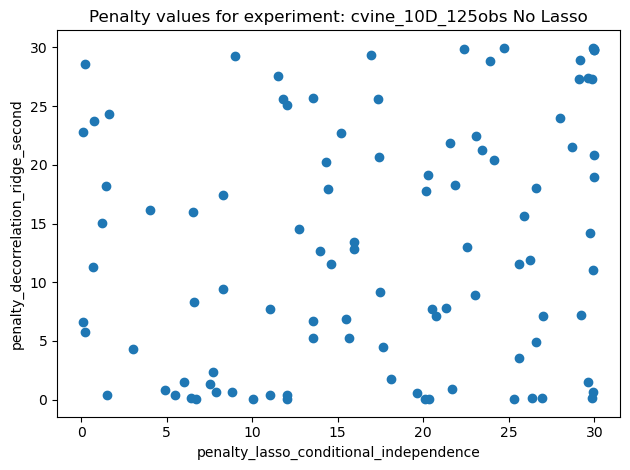

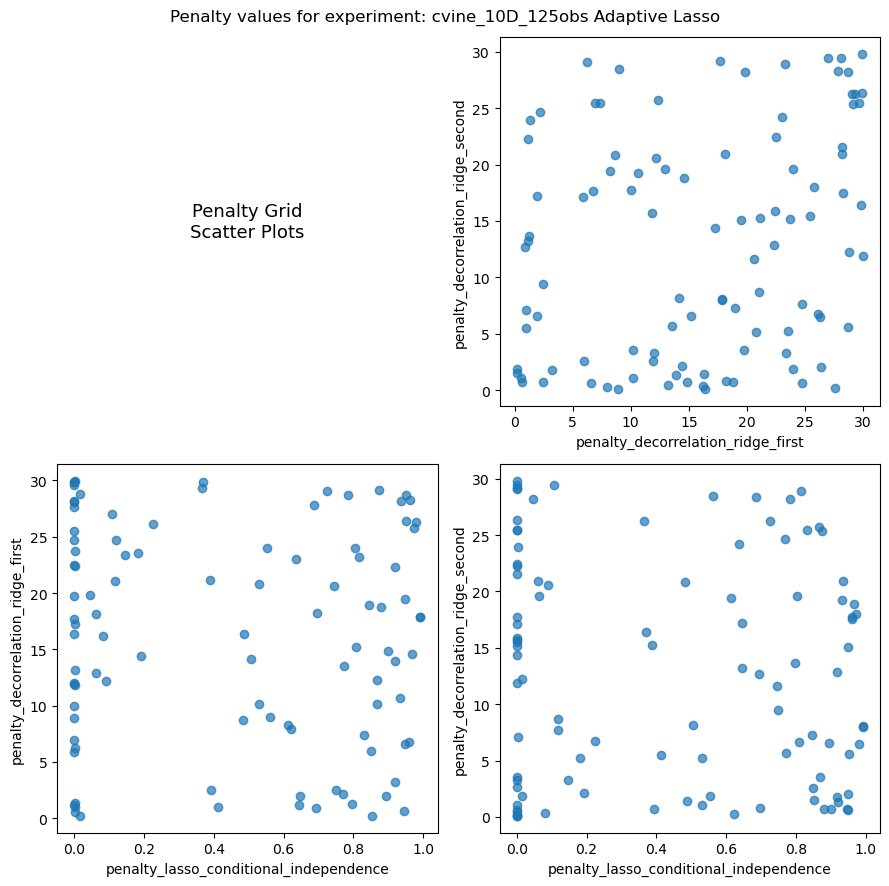

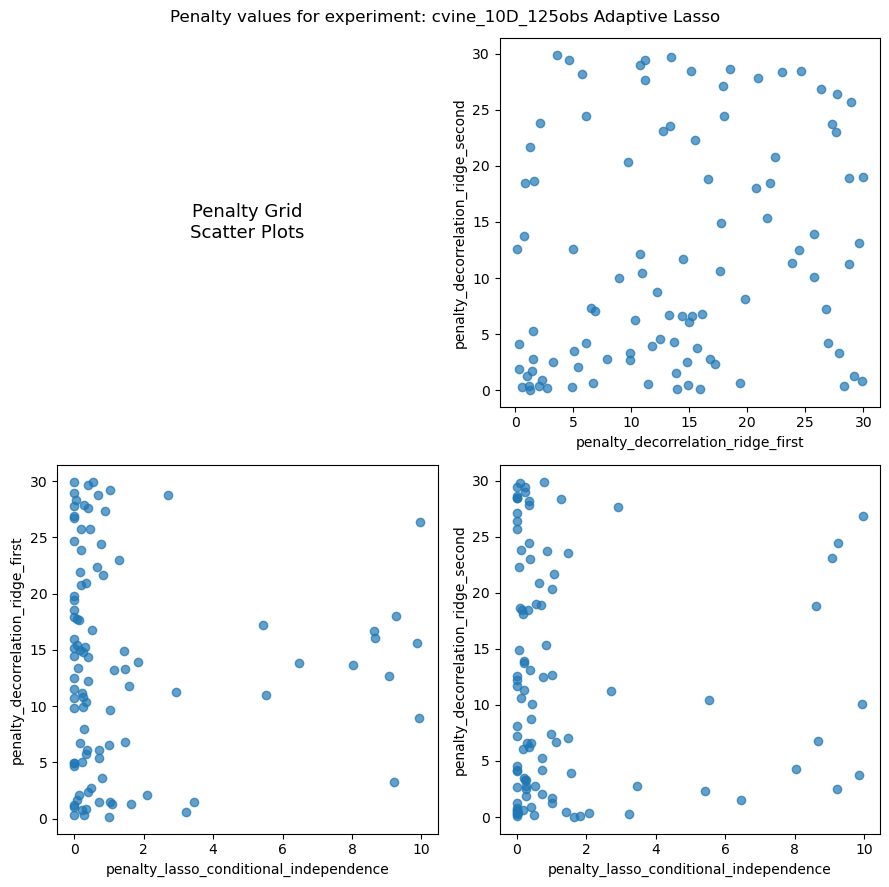

In [127]:
get_plot_penalties_from_experiment("cvine_10D_125obs", adapt2=True)

## D-Vine

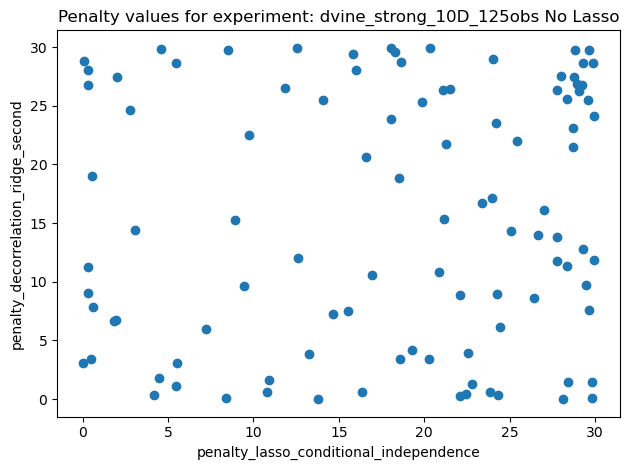

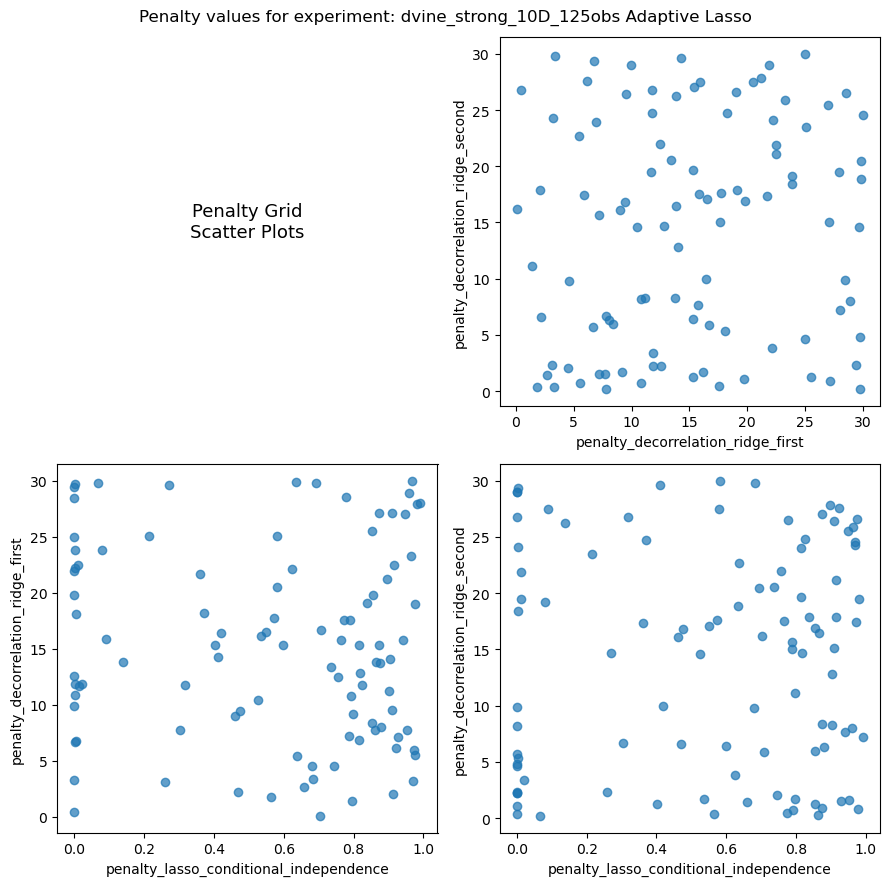

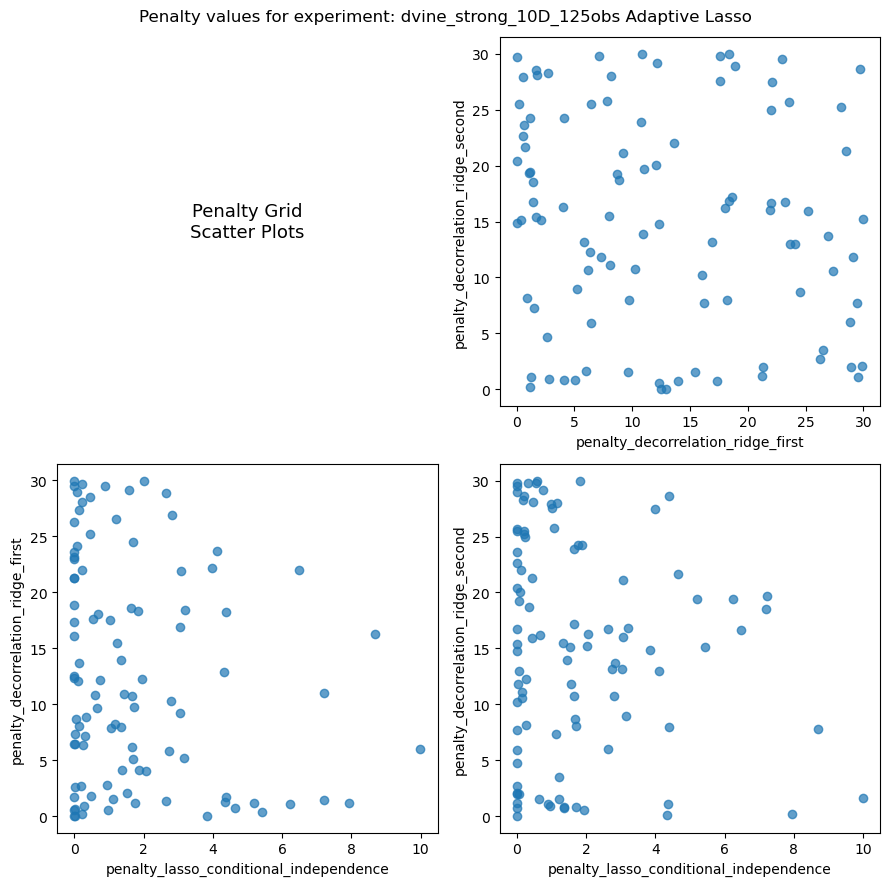

In [128]:
get_plot_penalties_from_experiment("dvine_strong_10D_125obs", adapt2=True)

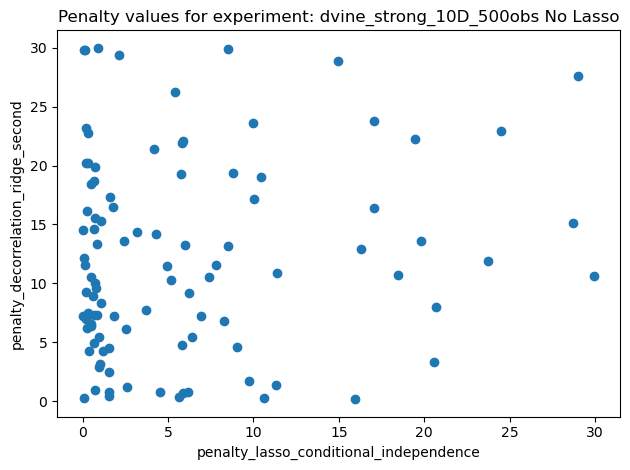

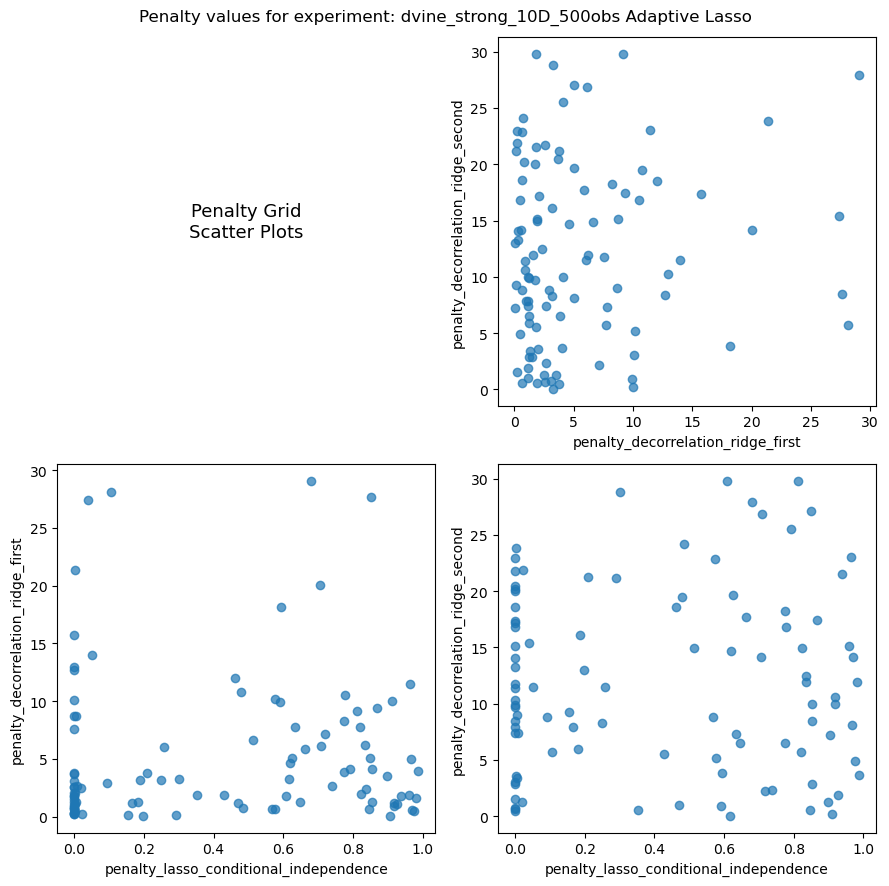

In [74]:
get_plot_penalties_from_experiment("dvine_strong_10D_500obs")

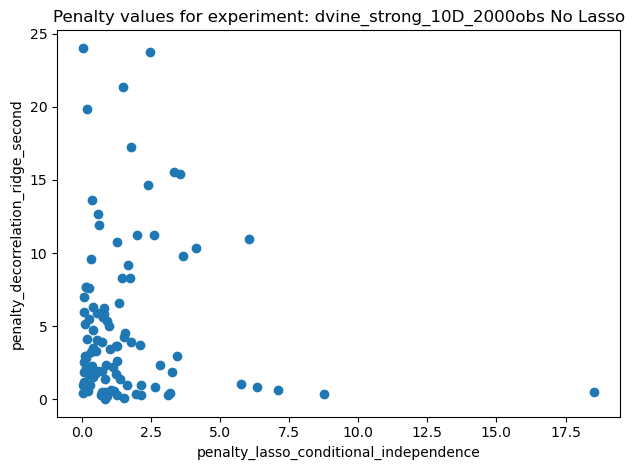

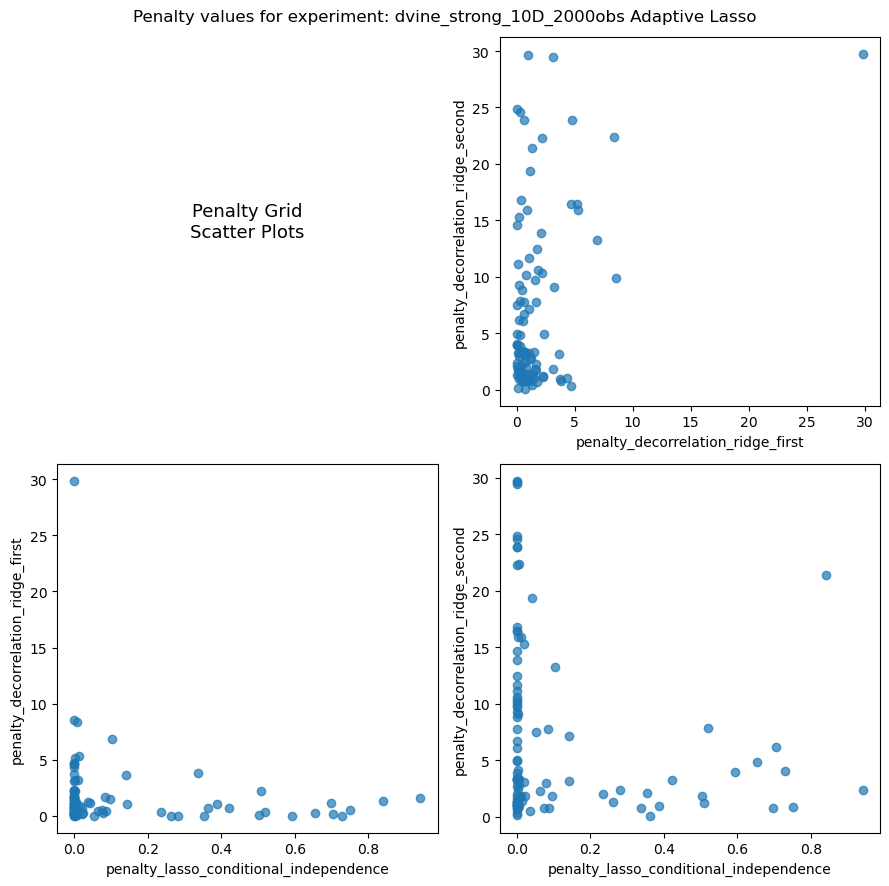

In [75]:
get_plot_penalties_from_experiment("dvine_strong_10D_2000obs")

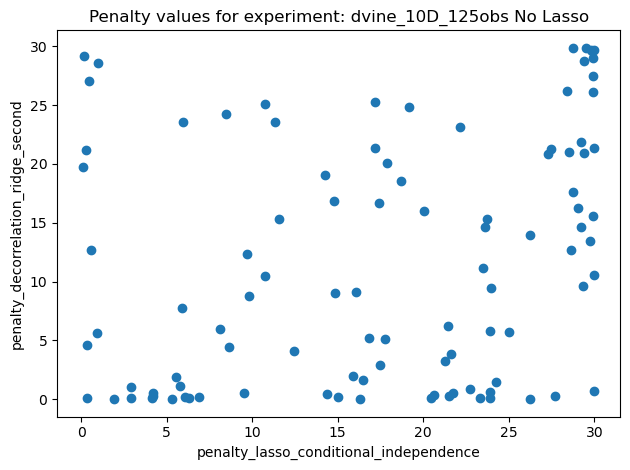

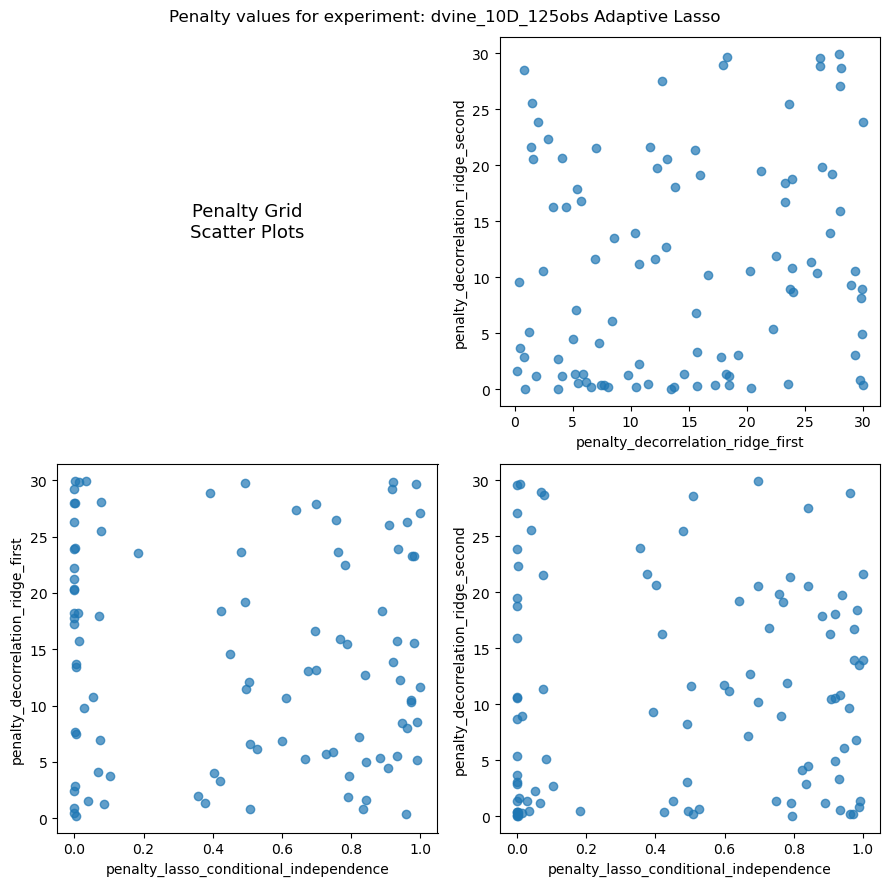

In [76]:
get_plot_penalties_from_experiment("dvine_10D_125obs")

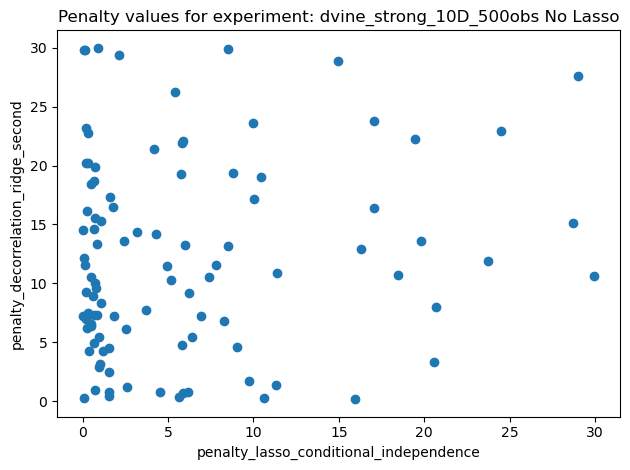

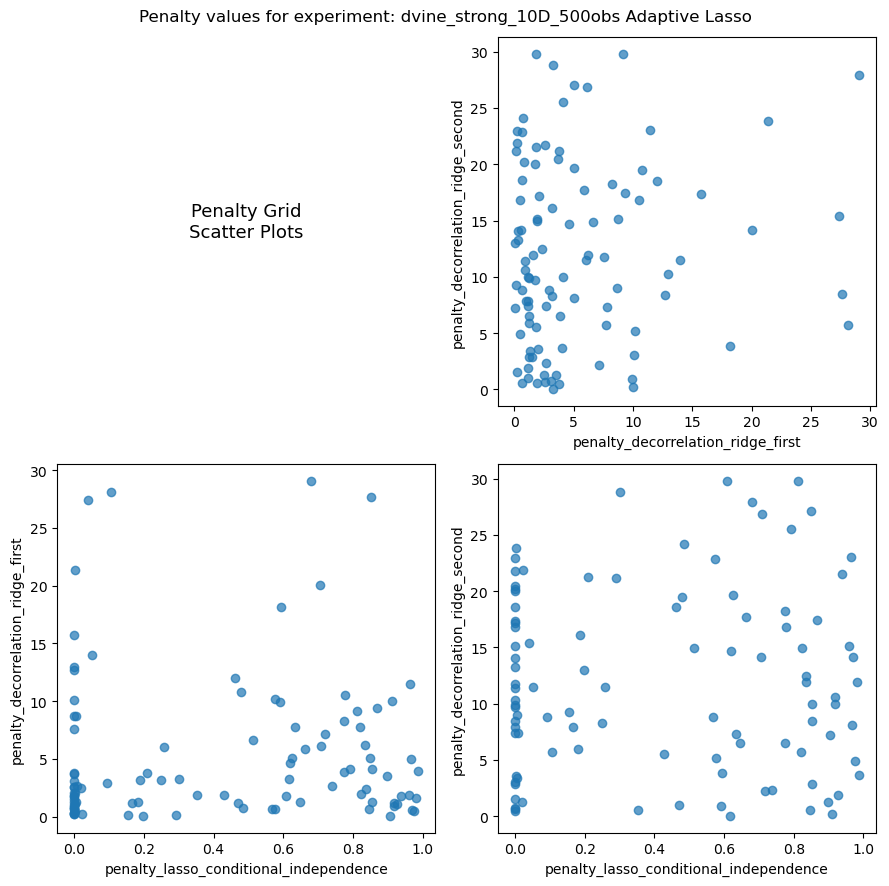

In [77]:
get_plot_penalties_from_experiment("dvine_strong_10D_500obs")

# Normalizing Flow Comparison

#### MAF AUC and then KLD for R-Vine 125, 500, 2000

In [ ]:
def create_comparison_plot_one_scenario(
    kld_dict_no_lambda_pen,
    kld_dict_lambda_pen,
    kld_dict_weighted_lambda_pen,
    metric = "rel_kld_test",
    title_str = "R-Vine",
    sample_sizes = [125, 250, 500, 1000, 2000, 4000],
    experiment_strings = ["rvine_10_dim_125obs", "rvine_10_dim_250obs", "rvine_10_dim_1000obs", "rvine_10_dim_2000obs", "rvine_10_dim"],
    y_min = False,
    y_max = False,
    benchmark=False,
    benchmark_label="GGM",      # <--- new
    benchmark_color="#d62728",  # <--- new (was hardcoded before)
    benchmark2=False,
    benchmark2_label="GGM 2",
    benchmark2_color="#9467bd",
    legend=False,
    metric_str="AUC",
    upper_quantile=80,
    lower_quantile=20,
    add_metric_title=True,
    ax=None
):
    # -------------------------------------------------------------------------
    # Compute statistics for each method
    # -------------------------------------------------------------------------
    means_weighted_no_pen, lower_weighted_no_pen, upper_weighted_no_pen = compute_stats(
        kld_dict_no_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile
    )
    means_lambda_pen, lower_lambda_pen, upper_lambda_pen = compute_stats(
        kld_dict_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile
    )
    means_weighted_lambda_pen, lower_weighted_lambda_pen, upper_weighted_lambda_pen = compute_stats(
        kld_dict_weighted_lambda_pen, experiment_strings, metric, lower_quantile, upper_quantile
    )
    if benchmark is not False:
        means_benchmark, lower_benchmark, upper_benchmark = compute_stats(
            benchmark, experiment_strings, metric=False,
            lower_quantile=lower_quantile, upper_quantile=upper_quantile
        )
    if benchmark2 is not False:
        means_benchmark2, lower_benchmark2, upper_benchmark2 = compute_stats(
            benchmark2, experiment_strings, metric=False,
            lower_quantile=lower_quantile, upper_quantile=upper_quantile
        )

    # -------------------------------------------------------------------------
    # Compute x positions depending on how many series are shown
    # -------------------------------------------------------------------------
    x_positions = np.arange(len(sample_sizes))

    n_series = 3  # no pen, lasso, adaptive lasso — always present
    if benchmark  is not False: n_series += 1
    if benchmark2 is not False: n_series += 1

    total_width = 0.6
    offsets = np.linspace(-total_width / 2, total_width / 2, n_series)

    offset_idx = 0
    if benchmark is not False:
        x_benchmark  = x_positions + offsets[offset_idx]; offset_idx += 1
    if benchmark2 is not False:
        x_benchmark2 = x_positions + offsets[offset_idx]; offset_idx += 1
    x_weighted_no_pen     = x_positions + offsets[offset_idx]; offset_idx += 1
    x_lambda_pen          = x_positions + offsets[offset_idx]; offset_idx += 1
    x_weighted_lambda_pen = x_positions + offsets[offset_idx]

    # -------------------------------------------------------------------------
    # If no axis is provided, make one
    # -------------------------------------------------------------------------
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))

    # -------------------------------------------------------------------------
    # Plot benchmarks (if provided)
    # -------------------------------------------------------------------------
    if benchmark is not False:
        ax.errorbar(
            x_benchmark, means_benchmark,
            yerr=[
                np.array(means_benchmark) - np.array(lower_benchmark),
                np.array(upper_benchmark) - np.array(means_benchmark)
            ],
            label=benchmark_label,   # <--- was hardcoded "GGM"
            fmt='o', linestyle='', capsize=5, color=benchmark_color  # <--- was hardcoded "#d62728"
        )

    if benchmark2 is not False:
        ax.errorbar(
            x_benchmark2, means_benchmark2,
            yerr=[
                np.array(means_benchmark2) - np.array(lower_benchmark2),
                np.array(upper_benchmark2) - np.array(means_benchmark2)
            ],
            label=benchmark2_label,
            fmt='o', linestyle='', capsize=5, color=benchmark2_color
        )

    # -------------------------------------------------------------------------
    # Plot the three main methods
    # -------------------------------------------------------------------------
    ax.errorbar(
        x_weighted_no_pen, means_weighted_no_pen,
        yerr=[
            np.array(means_weighted_no_pen) - np.array(lower_weighted_no_pen),
            np.array(upper_weighted_no_pen) - np.array(means_weighted_no_pen)
        ],
        label="No LASSO Penalty",
        fmt='o', linestyle='', capsize=5, color="#1f77b4"
    )

    ax.errorbar(
        x_lambda_pen, means_lambda_pen,
        yerr=[
            np.array(means_lambda_pen) - np.array(lower_lambda_pen),
            np.array(upper_lambda_pen) - np.array(means_lambda_pen)
        ],
        label="LASSO",
        fmt='o', linestyle='', capsize=5, color="#ff7f0e"
    )

    ax.errorbar(
        x_weighted_lambda_pen, means_weighted_lambda_pen,
        yerr=[
            np.array(means_weighted_lambda_pen) - np.array(lower_weighted_lambda_pen),
            np.array(upper_weighted_lambda_pen) - np.array(means_weighted_lambda_pen)
        ],
        label="Adaptive LASSO",
        fmt='o', linestyle='', capsize=5, color="#2ca02c"
    )

    # -------------------------------------------------------------------------
    # Formatting
    # -------------------------------------------------------------------------
    ax.set_xticks(x_positions)
    ax.set_xticklabels(sample_sizes)
    ax.set_xlabel("Sample Size")
    ax.set_ylabel(metric_str)

    if add_metric_title:
        ax.set_title(title_str + ": " + metric)
    if legend:
        ax.legend()

    ax.grid(True, which="both", linestyle="--", linewidth=0.5)

    if y_min is not False and y_max is not False:
        ax.set_ylim(y_min, y_max)

##### KLD

##### normal

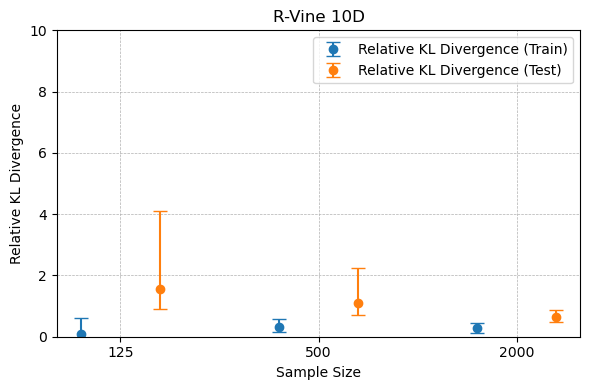

In [354]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "maf_rvine_10D_125obs",
    500  : "maf_rvine_10D_500obs",
    2000 : "maf_rvine_10D_2000obs"
}

metric_cols = ["metrics.relative_kld_gtm_train", 
               "metrics.relative_kld_gtm_test"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]
    
    # needed for the plot to not break down
    experiment_dfs[sample_size] = experiment_dfs[sample_size][experiment_dfs[sample_size]["metrics.relative_kld_gtm_test"] < 10]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["Relative KL Divergence (Train)", "Relative KL Divergence (Test)"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.0,
    y_max           = 10.0,
    xlabel          = "Sample Size",
    ylabel          = "Relative KL Divergence",
    
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_maf = {
    "rvine_10D_125obs" : experiment_dfs[125]["metrics.relative_kld_gtm_test"],
    "rvine_10D_500obs" : experiment_dfs[500]["metrics.relative_kld_gtm_test"],
    "rvine_10D_2000obs" : experiment_dfs[2000]["metrics.relative_kld_gtm_test"],
}

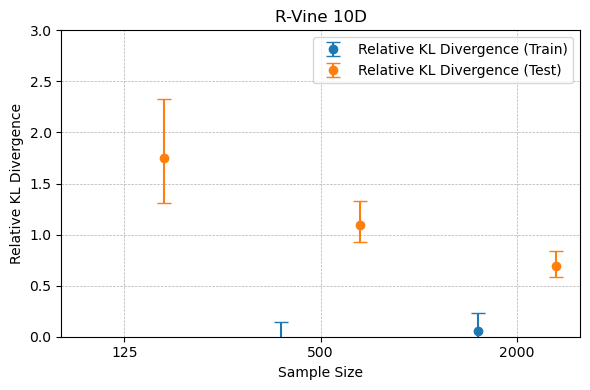

In [355]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "snf_rvine_10D_125obs",
    500  : "snf_rvine_10D_500obs",
    2000 : "snf_rvine_10D_2000obs"
}

metric_cols = ["metrics.relative_kld_gtm_train", 
               "metrics.relative_kld_gtm_test"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]
    
    # needed for the plot to not break down
    #experiment_dfs[sample_size] = experiment_dfs[sample_size][experiment_dfs[sample_size]["metrics.relative_kld_gtm_test"] < 10]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["Relative KL Divergence (Train)", "Relative KL Divergence (Test)"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.0,
    y_max           = 3.0,
    xlabel          = "Sample Size",
    ylabel          = "Relative KL Divergence",
    
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_snf = {
    "rvine_10D_125obs" : experiment_dfs[125]["metrics.relative_kld_gtm_test"],
    "rvine_10D_500obs" : experiment_dfs[500]["metrics.relative_kld_gtm_test"],
    "rvine_10D_2000obs" : experiment_dfs[2000]["metrics.relative_kld_gtm_test"],
}

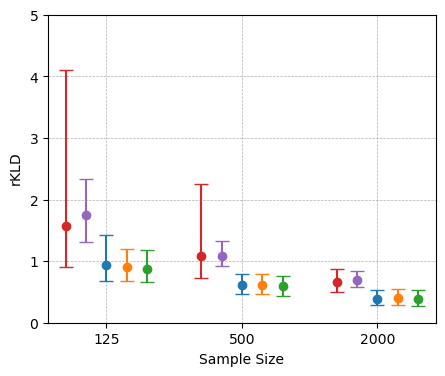

In [356]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 5.0,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        benchmark_label="MAF",      # <--- new
        benchmark_color="#d62728",  # <--- new (was hardcoded before)
        benchmark2_label="SNF",
        benchmark2_color="#9467bd",
        benchmark=benchmark_dict_maf,
        benchmark2=benchmark_dict_snf,
        legend=False,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_normal_maf_snf.png")

##### strong

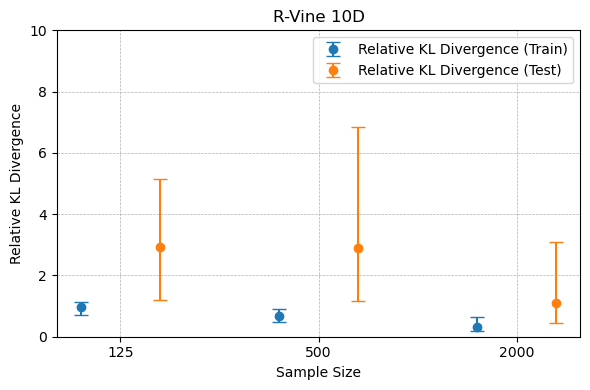

In [339]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "maf_rvine_strong_10D_125obs",
    500  : "maf_rvine_strong_10D_500obs",
    2000 : "maf_rvine_strong_10D_2000obs"
}

metric_cols = ["metrics.relative_kld_gtm_train", 
               "metrics.relative_kld_gtm_test"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]
    
    # needed for the plot to not break down
    experiment_dfs[sample_size] = experiment_dfs[sample_size][experiment_dfs[sample_size]["metrics.relative_kld_gtm_test"] < 10]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["Relative KL Divergence (Train)", "Relative KL Divergence (Test)"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.0,
    y_max           = 10.0,
    xlabel          = "Sample Size",
    ylabel          = "Relative KL Divergence",
    
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_maf = {
    "rvine_strong_10D_125obs" : experiment_dfs[125]["metrics.relative_kld_gtm_test"],
    "rvine_strong_10D_500obs" : experiment_dfs[500]["metrics.relative_kld_gtm_test"],
    "rvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.relative_kld_gtm_test"],
}

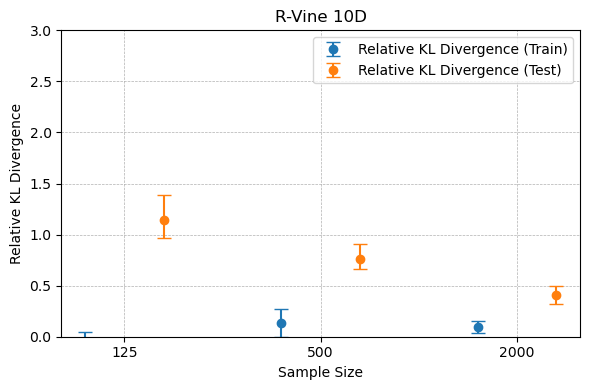

In [340]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "snf_rvine_strong_10D_125obs",
    500  : "snf_rvine_strong_10D_500obs",
    2000 : "snf_rvine_strong_10D_2000obs"
}

metric_cols = ["metrics.relative_kld_gtm_train", 
               "metrics.relative_kld_gtm_test"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]
    
    # needed for the plot to not break down
    #experiment_dfs[sample_size] = experiment_dfs[sample_size][experiment_dfs[sample_size]["metrics.relative_kld_gtm_test"] < 10]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["Relative KL Divergence (Train)", "Relative KL Divergence (Test)"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.0,
    y_max           = 3.0,
    xlabel          = "Sample Size",
    ylabel          = "Relative KL Divergence",
    
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_snf = {
    "rvine_strong_10D_125obs" : experiment_dfs[125]["metrics.relative_kld_gtm_test"],
    "rvine_strong_10D_500obs" : experiment_dfs[500]["metrics.relative_kld_gtm_test"],
    "rvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.relative_kld_gtm_test"],
}

there are nan values in False, the number is  2
there are nan values in False, the number is  2
there are nan values in False, the number is  2


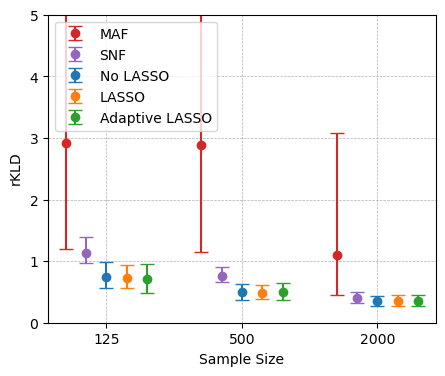

In [341]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_10D_125obs", "rvine_strong_10D_500obs", "rvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_kld_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.relative_kld_gtm_test",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.0,
        y_max = 5.0,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        benchmark_label="MAF",      # <--- new
        benchmark_color="#d62728",  # <--- new (was hardcoded before)
        benchmark2_label="SNF",
        benchmark2_color="#9467bd",
        benchmark=benchmark_dict_maf,
        benchmark2=benchmark_dict_snf,
        legend=True,
        metric_str=r"$\mathrm{rKLD}$"
    )
plt.savefig("kld_test_rvine_strong_maf_snf.png")

##### AUC

##### normal

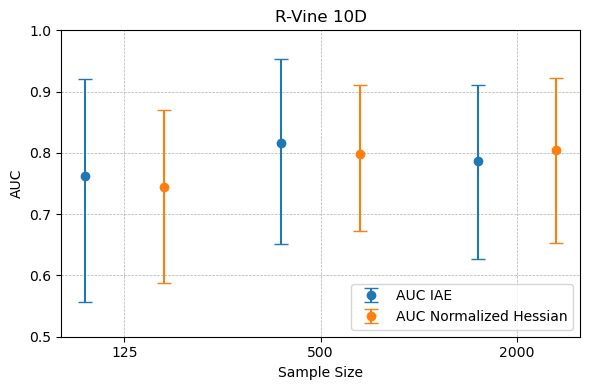

In [357]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "maf_rvine_10D_125obs",
    500  : "maf_rvine_10D_500obs",
    2000 : "maf_rvine_10D_2000obs"
}

metric_cols = ["metrics.auc_iae", "metrics.auc_normed_hessian"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC IAE", "AUC Normalized Hessian"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_maf = {
    "rvine_10D_125obs" : experiment_dfs[125]["metrics.auc_iae"],
    "rvine_10D_500obs" : experiment_dfs[500]["metrics.auc_iae"],
    "rvine_10D_2000obs" : experiment_dfs[2000]["metrics.auc_iae"],
}

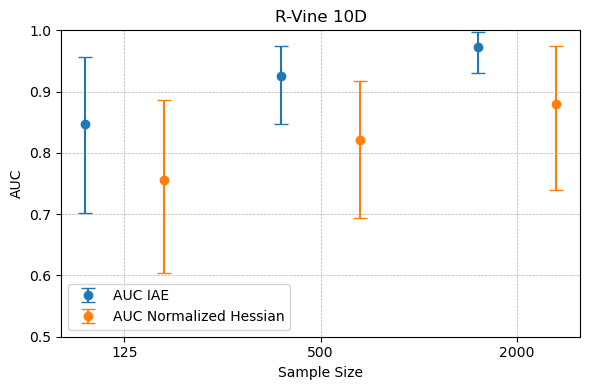

In [358]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "snf_rvine_10D_125obs",
    500  : "snf_rvine_10D_500obs",
    2000 : "snf_rvine_10D_2000obs"
}

metric_cols = ["metrics.auc_iae", "metrics.auc_normed_hessian"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC IAE", "AUC Normalized Hessian"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_snf = {
    "rvine_10D_125obs" : experiment_dfs[125]["metrics.auc_iae"],
    "rvine_10D_500obs" : experiment_dfs[500]["metrics.auc_iae"],
    "rvine_10D_2000obs" : experiment_dfs[2000]["metrics.auc_iae"],
}

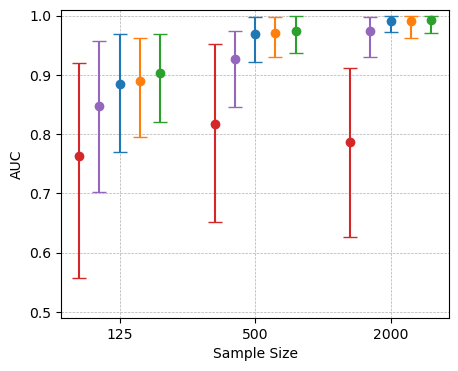

In [359]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_10D_125obs", "rvine_10D_500obs", "rvine_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        benchmark_label="MAF",      # <--- new
        benchmark_color="#d62728",  # <--- new (was hardcoded before)
        benchmark2_label="SNF",
        benchmark2_color="#9467bd",
        benchmark=benchmark_dict_maf,
        benchmark2=benchmark_dict_snf,
        legend=False,
        metric_str="AUC"
    )
plt.savefig("auc_rvine_normal_maf_snf.png")

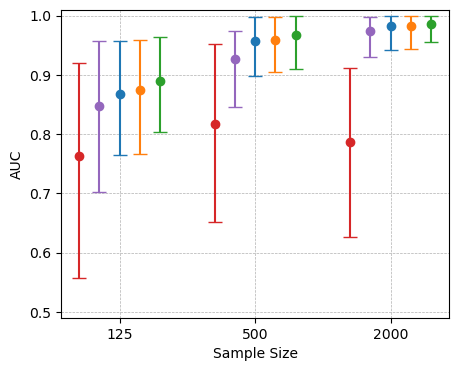

In [360]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_normed_hessian",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        benchmark_label="MAF",      # <--- new
        benchmark_color="#d62728",  # <--- new (was hardcoded before)
        benchmark2_label="SNF",
        benchmark2_color="#9467bd",
        benchmark=benchmark_dict_maf,
        benchmark2=benchmark_dict_snf,
        legend=False,
        metric_str="AUC"
    )
plt.savefig("auc_rvine_normal_maf_snf_normed_hessian.png")

##### strong

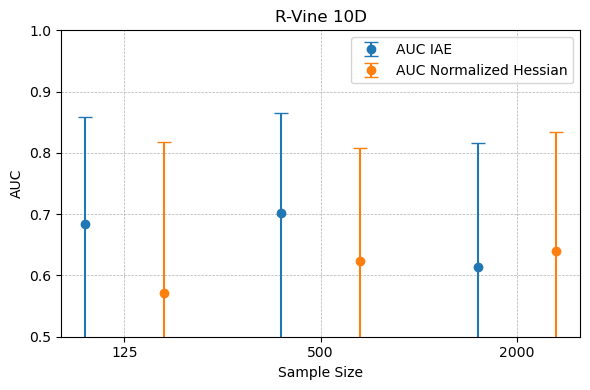

In [361]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "maf_rvine_strong_10D_125obs",
    500  : "maf_rvine_strong_10D_500obs",
    2000 : "maf_rvine_strong_10D_2000obs"
}

metric_cols = ["metrics.auc_iae", "metrics.auc_normed_hessian"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC IAE", "AUC Normalized Hessian"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_maf = {
    "rvine_strong_10D_125obs" : experiment_dfs[125]["metrics.auc_iae"],
    "rvine_strong_10D_500obs" : experiment_dfs[500]["metrics.auc_iae"],
    "rvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.auc_iae"],
}

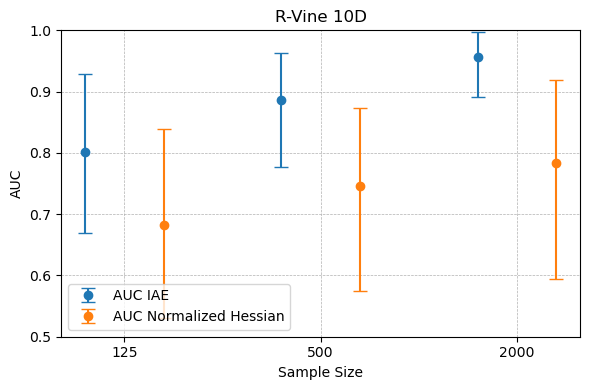

In [362]:

mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "snf_rvine_strong_10D_125obs",
    500  : "snf_rvine_strong_10D_500obs",
    2000 : "snf_rvine_strong_10D_2000obs"
}

metric_cols = ["metrics.auc_iae", "metrics.auc_normed_hessian"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC IAE", "AUC Normalized Hessian"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

benchmark_dict_snf = {
    "rvine_strong_10D_125obs" : experiment_dfs[125]["metrics.auc_iae"],
    "rvine_strong_10D_500obs" : experiment_dfs[500]["metrics.auc_iae"],
    "rvine_strong_10D_2000obs" : experiment_dfs[2000]["metrics.auc_iae"],
}

there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in metrics.auc_iae, the number is  1
there are nan values in False, the number is  9
there are nan values in False, the number is  3
there are nan values in False, the number is  2
there are nan values in False, the number is  2
there are nan values in False, the number is  2
there are nan values in False, the number is  2


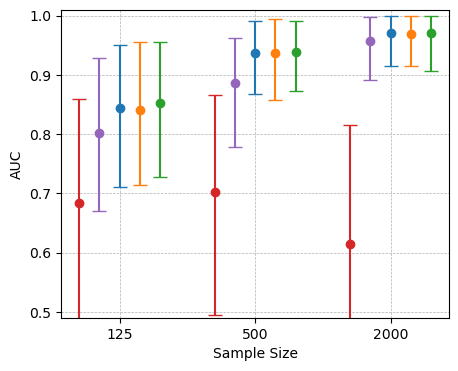

In [363]:
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch")

experiment_name_list = ["rvine_strong_10D_125obs", "rvine_strong_10D_500obs", "rvine_strong_10D_2000obs"]

auc_no, auc_lasso, auc_adaptive = get_auc_dicts_all(
    experiment_name_list = experiment_name_list,
    seed_min=0,
    seed_max=99
)

create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_iae",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        benchmark_label="MAF",      # <--- new
        benchmark_color="#d62728",  # <--- new (was hardcoded before)
        benchmark2_label="SNF",
        benchmark2_color="#9467bd",
        benchmark=benchmark_dict_maf,
        benchmark2=benchmark_dict_snf,
        legend=False,
        metric_str="AUC"
    )
plt.savefig("auc_rvine_strong_maf_snf.png")

there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in metrics.auc_normed_hessian, the number is  1
there are nan values in False, the number is  9
there are nan values in False, the number is  3
there are nan values in False, the number is  2
there are nan values in False, the number is  2
there are nan values in False, the number is  2
there are nan values in False, the number is  2


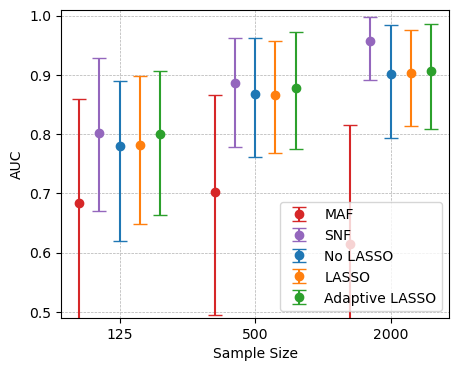

In [364]:
create_comparison_plot_one_scenario(
        auc_no,
        auc_lasso,
        auc_adaptive,
        metric = "metrics.auc_normed_hessian",
        title_str = "R-Vine",
        sample_sizes = [125, 500, 2000],
        experiment_strings=experiment_name_list,
        y_min = 0.49,
        y_max = 1.01,
        lower_quantile=5,
        upper_quantile=95,
        add_metric_title=False,
        benchmark_label="MAF",      # <--- new
        benchmark_color="#d62728",  # <--- new (was hardcoded before)
        benchmark2_label="SNF",
        benchmark2_color="#9467bd",
        benchmark=benchmark_dict_maf,
        benchmark2=benchmark_dict_snf,
        legend=True,
        metric_str="AUC"
    )
plt.savefig("auc_rvine_strong_maf_snf_normed_hessian.png")

In [365]:
D = 20
pairs = (D*(D-1))/2
indep3 = D*3-1-2-3
print((pairs))
print(indep3)
print(indep3/pairs)

190.0
54
0.28421052631578947


In [366]:
D = 50
pairs = (D*(D-1))/2
indep3 = D*3-1-2-3
print((pairs))
print(indep3)
print(indep3/pairs)

1225.0
144
0.11755102040816326


In [367]:
D = 100
pairs = (D*(D-1))/2
indep3 = D*6-1-2-3-4-5
print((pairs))
print(indep3)
print(indep3/pairs)

4950.0
585
0.11818181818181818


In [368]:
D = 100
pairs = (D*(D-1))/2
indep3 = D*3-1-2-3
print((pairs))
print(indep3)
print(indep3/pairs)

4950.0
294
0.059393939393939395
